## SPE DSEATS Africa 2025 Datathon 
## Production Data Classification Pipeline

## 1. Overview and Objectives

This project develops a **multi‑task classification system** for 20 oil wells using their historical production and pressure time series. We predict **seven engineering‑relevant labels per well**:

- **Reservoir Name**: ACHI, KEMA, MAKO, DEPU, JANI  
- **Reservoir Type**: Saturated vs. Undersaturated  
- **Well Type**: Naturally Flowing vs. Gas Lifted  
- **Production Stability**: Steady vs. Unsteady  
- **GOR Trend**: aSolGOR, bSolGOR, Combo  
- **Watercut Trend**: Flat, Increasing, Decreasing, Combo  
- **PI Trend**: Flat, Increasing, Decreasing, Combo  

Our pipeline:
- Preserves each well’s full production history  
- Leverages rule‑based labels and engineered features  
- Employs a **Transformer‑based neural encoder** to generate contextual embeddings  
- Uses multiple classification heads for final predictions  


## 2. Data Ingestion & Exploratory Data Analysis (EDA)

**Load CSVs**:
- `wells_dataset.csv`: daily measures (oil, gas, water, BHP, annulus, choke size, WHP, etc.)
- `reservoir_info.csv`: static reservoir properties
- `classification_parameters.csv`: allowed label categories

**Initial Checks**:
- Inspect data types, ranges, and missingness
- Summarize record counts per well (e.g., 124–820 days)

**Cleaning**:
- Convert dates to `datetime`, sort by well and date
- Interpolate or drop missing days sensibly

**Visual Inspection**:
- Plot daily oil, gas, water curves for selected wells
- Plot BHP and GOR time series

## 3.  Rule-Based Labeling for ground truth

**Rule-Based Label Generation**:
- **Reservoir Assignment**: `max(BHP) - avg(reservoir pressure) ≤ 200 psi`
- **Reservoir Type**: `Initial P ≤ Bubble Point → Undersat`, else `Saturated`
- **Well Type**: annulus pressure patterns indicate GL vs. NF
- **Stability**: ≥50% oil drop in any 3–6 month window → `Unsteady`
- **Trend Labels**: slope from linear regression over time (for GOR, Watercut, PI)


## 4. Feature Engineering & Selection

### Temporal Feature Engineering:
- Slopes over full history, early and late windows
- First-30 and last-30 day averages and decline rates
- Derived metrics: GOR, watercut, PI

### Feature Selection:
- Spearman correlation to eliminate redundancy


### Aggregation:
- Collapse daily time series into a vector of engineered metrics per well

### Neural Embedding:
- Build a Transformer encoder:
  - Row-wise & column-wise attention
  - Input: padded sequences + mask
  - Output: dimensional contextual embedding per well


## 5. Modeling Strategy

### Neural Encoder:
- Project raw sequences to `D_model`
- Stack Multi‑Head Self‑Attention blocks with:
  - Residual connections
  - Layer normalization
- Use `[CLS]` token or attention pooling for global summary

### Domain Feature Fusion:
- Concatenate domain-engineered features to Transformer embedding

### Classification Heads:
- Seven parallel MLP heads:
  - Dense → ReLU → Dropout → Dense
- Output:
  - Sigmoid for binary tasks
  - Softmax for multi-class tasks

### Alternative Hybrid Approach:
- Feed contextual embeddings (with features) into XGBoost for benchmark comparison


## 6. Training & Evaluation

**Split**:
- 80/20 well-level split (train/test)

**Loss Function**:
- Combined cross-entropy loss from all 7 tasks

**Evaluation Metrics**:
- Per-task:
  - Accuracy, Precision, Recall, F1
  - ROC‑AUC (for binary tasks)
  - Confusion matrices (for multi-class tasks)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit
from scipy.stats import linregress
from sklearn.metrics import r2_score
import warnings

# Configure visualization settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("deep")
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

# For nicer plots
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Improve quality of plots for presentations
plt.rcParams['figure.dpi'] = 100

In [2]:
# Load the main wells dataset
well_data = pd.read_csv('spe_africa_dseats_datathon_2025_wells_dataset.csv')

# Load reservoir reference data
reservoir_info = pd.read_csv('reservoir_info.csv')

# Convert date columns to datetime format
well_data['PROD_DATE'] = pd.to_datetime(well_data['PROD_DATE'], dayfirst=True)

print(f"Wells Dataset: {well_data.shape[0]} rows, {well_data.shape[1]} columns")
print(f"Reservoir Info: {reservoir_info.shape[0]} rows, {reservoir_info.shape[1]} columns")
print(f"Time range: {well_data['PROD_DATE'].min().strftime('%d-%b-%Y')} to {well_data['PROD_DATE'].max().strftime('%d-%b-%Y')}")
print(f"Number of wells: {well_data['WELL_NAME'].nunique()}")

Wells Dataset: 7955 rows, 13 columns
Reservoir Info: 5 rows, 6 columns
Time range: 17-Feb-2011 to 12-Aug-2016
Number of wells: 20


## 1. Exploratory Data Analysis (EDA)

## 1.1 Initial Data Review

Let's examine our dataset to understand its structure, completeness, and quality before performing detailed analysis. We'll look at:

1. The first and last few records to understand the data format
2. Summary statistics for numerical columns
3. Data types and missing values

In [3]:
# Display the first few rows of the wells dataset
print("First 5 rows of production data:")
well_data.head()

First 5 rows of production data:


,PROD_DATE,WELL_NAME,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL)
0,2014-02-15,Well_#1,0.0,"4,050",189.866,0,1.17951,482.46,50.864,0,0,0,0
1,2014-02-16,Well_#1,0.0,"3,961",189.945,0,2.99440,328.601,47.668,0,0,0,0
2,2014-02-17,Well_#1,0.0,"3,961",190.004,0,1.90349,387.218,48.962,0,0,0,0
3,2014-02-18,Well_#1,0.0,"3,964",190.020,0,0.00000,308.98,46.636,0,0,0,0
4,2014-02-19,Well_#1,0.0,"3,965",190.107,0,30.20760,196.057,47.297,0,0,0,0


In [4]:
# Display the last few rows of the wells dataset
print("Last 5 rows of production data:")
well_data.tail()

Last 5 rows of production data:


,PROD_DATE,WELL_NAME,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL)
7950,2015-04-05,Well_#20,18.94,"2,505",149.177,633.188,77.32078,115.406,85.532,"497,425","235,131","352,697","522,788"
7951,2015-04-06,Well_#20,21.06,"2,503",149.169,617.591,72.40304,116.285,84.959,"497,609","235,205","352,808","523,266"
7952,2015-04-07,Well_#20,24.00,"2,481",149.175,645.435,100.00000,111.943,87.361,"497,879","235,314","352,971","523,885"
7953,2015-04-08,Well_#20,15.94,"2,485",149.178,651.282,76.40842,111.962,87.583,"498,019","235,370","353,055","524,431"
7954,2015-04-09,Well_#20,18.06,"2,510",149.139,593.181,56.67801,117.299,82.390,"498,126","235,416","353,124","524,844"


In [5]:
# Display reservoir information
print("Reservoir reference information:")
reservoir_info

Reservoir reference information:


,Reservoir Name,Initial Reservoir Pressure (PSI),Bubble Point Pressure (PSI),Current Average Reservoir Pressure (PSI),Solution Gas-Oil-Ratio (SCF/BBL),Formation Volume Factor (RB/STB)
0,ACHI,"3,500","3,300","2,700",800,1.20
1,KEMA,"4,200","4,000","3,900",600,1.45
2,MAKO,"3,500","3,500","3,000",500,1.15
3,DEPU,"2,800","2,800","2,400","1,200",1.37
4,JANI,"4,500","4,300","4,200","1,000",1.30


In [6]:
# Examine the well_data types and check for missing values
print("well_data types and missing values summary:")
well_data.info()

well_data types and missing values summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7955 entries, 0 to 7954
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   PROD_DATE                             7955 non-null   datetime64[ns]
 1   WELL_NAME                             7955 non-null   object        
 2   ON_STREAM_HRS                         7955 non-null   float64       
 3   BOTTOMHOLE_FLOWING_PRESSURE (PSI)     7955 non-null   object        
 4   DOWNHOLE_TEMPERATURE (deg F)          7955 non-null   float64       
 5   ANNULUS_PRESS (PSI)                   7955 non-null   object        
 6   CHOKE_SIZE (%)                        7955 non-null   float64       
 7   WELL_HEAD_PRESSURE (PSI)              7955 non-null   object        
 8   WELL_HEAD_TEMPERATURE (deg F)         7955 non-null   float64       
 9   CUMULATIVE_OIL_PROD (STB)     

In [7]:
# Ensure PROD_DATE is in datetime format
well_data['PROD_DATE'] = pd.to_datetime(well_data['PROD_DATE'])

# Group by well and get min/max dates
well_life = well_data.groupby('WELL_NAME')['PROD_DATE'].agg(['min', 'max']).reset_index()
well_life.columns = ['WELL_NAME', 'START_DATE', 'END_DATE']
well_life


,WELL_NAME,START_DATE,END_DATE
0,Well_#1,2014-02-15,2014-09-06
1,Well_#10,2014-09-12,2015-11-12
2,Well_#11,2011-10-01,2012-09-05
3,Well_#12,2011-08-12,2013-09-20
4,Well_#13,2012-09-08,2013-05-12
5,Well_#14,2013-06-18,2013-12-18
6,Well_#15,2014-01-30,2014-12-22
7,Well_#16,2012-07-01,2013-04-20
8,Well_#17,2014-07-22,2015-09-30
9,Well_#18,2011-02-17,2011-12-25



#### **Generating descriptive statistics for all numerical columns to understand their distribution and identify potential insights.**



In [8]:
# Converting string-formatted numeric columns to float
print("Converting string columns with commas to numeric types...")

# List of columns to convert
numeric_columns = [
    'BOTTOMHOLE_FLOWING_PRESSURE (PSI)',
    'ANNULUS_PRESS (PSI)',
    'WELL_HEAD_PRESSURE (PSI)',
    'CUMULATIVE_OIL_PROD (STB)',
    'CUMULATIVE_FORMATION_GAS_PROD (MSCF)',
    'CUMULATIVE_TOTAL_GAS_PROD (MSCF)',
    'CUMULATIVE_WATER_PROD (BBL)'
]

# Make a copy of the dataframe to avoid modifying the original during transformations
data_cleaned = well_data.copy()

# Convert each column with proper error handling
for col in numeric_columns:
    # Check if column contains strings (requiring comma removal)
    if data_cleaned[col].dtype == 'object':
        print(f"Converting {col} from string to numeric...")
        data_cleaned[col] = data_cleaned[col].str.replace(',', '').astype(float)
    else:
        print(f"{col} is already numeric type: {data_cleaned[col].dtype}")

# Show a sample of the converted data
data_cleaned[numeric_columns].head()

Converting string columns with commas to numeric types...
Converting BOTTOMHOLE_FLOWING_PRESSURE (PSI) from string to numeric...
Converting ANNULUS_PRESS (PSI) from string to numeric...
Converting WELL_HEAD_PRESSURE (PSI) from string to numeric...
Converting CUMULATIVE_OIL_PROD (STB) from string to numeric...
Converting CUMULATIVE_FORMATION_GAS_PROD (MSCF) from string to numeric...
Converting CUMULATIVE_TOTAL_GAS_PROD (MSCF) from string to numeric...
Converting CUMULATIVE_WATER_PROD (BBL) from string to numeric...


,BOTTOMHOLE_FLOWING_PRESSURE (PSI),ANNULUS_PRESS (PSI),WELL_HEAD_PRESSURE (PSI),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL)
0,4050.0,0.0,482.460,0.0,0.0,0.0,0.0
1,3961.0,0.0,328.601,0.0,0.0,0.0,0.0
2,3961.0,0.0,387.218,0.0,0.0,0.0,0.0
3,3964.0,0.0,308.980,0.0,0.0,0.0,0.0
4,3965.0,0.0,196.057,0.0,0.0,0.0,0.0


Generating Histograms...


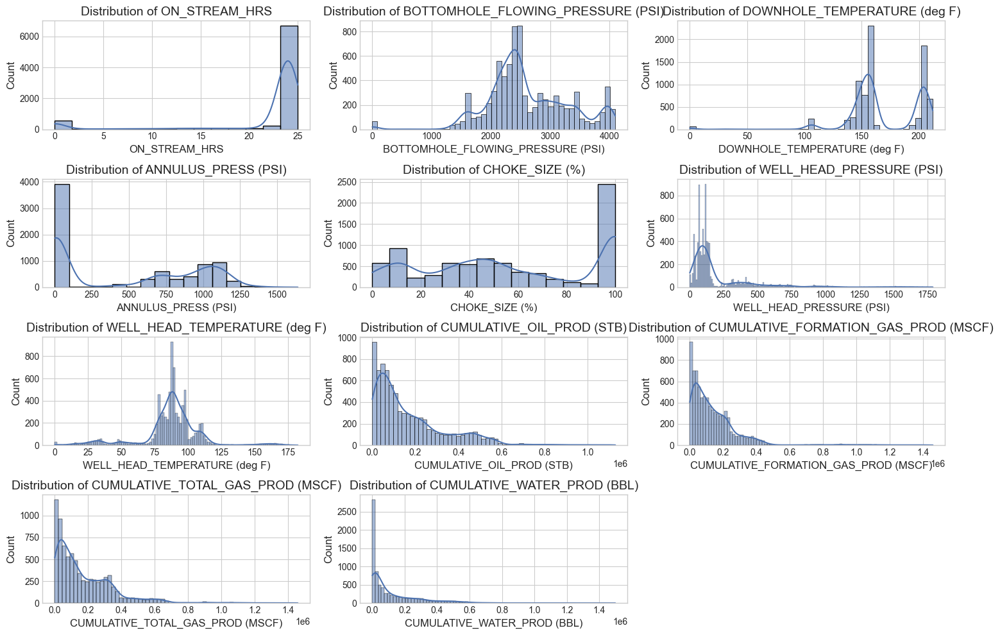

In [9]:
numerical_cols = data_cleaned.select_dtypes(include=['float64', 'int64']).columns

# Histograms
print("Generating Histograms...")
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 3, i + 1)
    sns.histplot(data_cleaned[col], kde=True)


    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


In [10]:
data_cleaned.describe()

,PROD_DATE,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL)
count,7955,7955.000000,7955.000000,7955.000000,7955.000000,7955.000000,7955.000000,7955.000000,7.955000e+03,7.955000e+03,7.955000e+03,7.955000e+03
mean,2013-08-26 16:25:49.516027648,21.623497,2613.811816,168.757429,471.339542,56.155295,212.574151,86.836365,1.725855e+05,1.456235e+05,1.811090e+05,1.427100e+05
min,2011-02-17 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2012-08-02 00:00:00,24.000000,2195.000000,150.228500,4.199000,28.130855,68.661500,80.677500,4.769100e+04,3.854150e+04,4.152100e+04,8.907000e+03
50%,2013-06-25 00:00:00,24.000000,2465.000000,158.624000,301.247000,51.068030,113.718000,88.364000,1.092950e+05,1.016100e+05,1.171430e+05,4.651700e+04
75%,2014-10-01 00:00:00,24.000000,3067.000000,202.600000,981.329000,99.800950,161.176500,96.770500,2.424885e+05,1.991035e+05,2.707540e+05,1.949390e+05
max,2016-08-12 00:00:00,25.000000,4096.000000,212.153000,1639.040000,100.000000,1787.760000,182.157000,1.129301e+06,1.458660e+06,1.458660e+06,1.499262e+06
std,NaN,6.567826,687.600640,31.917787,481.638340,34.975408,282.193044,22.738615,1.740827e+05,1.721685e+05,1.970784e+05,2.221567e+05


## min/max analysis

In [11]:
# Find minimum values for all columns
min_values = data_cleaned.min(numeric_only=True)

# Find maximum values for all columns
max_values = data_cleaned.max(numeric_only=True)

print("Minimum values:\n", min_values)
print("\nMaximum values:\n", max_values)


Minimum values:
 ON_STREAM_HRS                           0.0
BOTTOMHOLE_FLOWING_PRESSURE (PSI)       0.0
DOWNHOLE_TEMPERATURE (deg F)            0.0
ANNULUS_PRESS (PSI)                     0.0
CHOKE_SIZE (%)                          0.0
WELL_HEAD_PRESSURE (PSI)                0.0
WELL_HEAD_TEMPERATURE (deg F)           0.0
CUMULATIVE_OIL_PROD (STB)               0.0
CUMULATIVE_FORMATION_GAS_PROD (MSCF)    0.0
CUMULATIVE_TOTAL_GAS_PROD (MSCF)        0.0
CUMULATIVE_WATER_PROD (BBL)             0.0
dtype: float64

Maximum values:
 ON_STREAM_HRS                                25.000
BOTTOMHOLE_FLOWING_PRESSURE (PSI)          4096.000
DOWNHOLE_TEMPERATURE (deg F)                212.153
ANNULUS_PRESS (PSI)                        1639.040
CHOKE_SIZE (%)                              100.000
WELL_HEAD_PRESSURE (PSI)                   1787.760
WELL_HEAD_TEMPERATURE (deg F)               182.157
CUMULATIVE_OIL_PROD (STB)               1129301.000
CUMULATIVE_FORMATION_GAS_PROD (MSCF)    1458660.00

## 1.2 Systematic Data Quality Detection and Analysis

Now we will systematically detect and address several data quality concerns identified from the min/max analysis:

### Issues to Address:
1. **Downhole Temperature Anomalies**: Replace 0 values or values <10% of well maximum with well average
2. **Well Head Temperature Anomalies**: Apply similar logic as downhole temperature if necessary  
3. **Annulus Pressure**: High frequency of 0 values - analyze pattern per well
4. **Cumulative Production Inconsistencies**: Check for 0 cumulative values after production start
5. **On-Stream Hours >24**: Validate daily reporting constraints

### Detection Strategy:
- Identify anomalies per well basis
- Quantify extent of each issue
- Document cleaning actions needed
- Prepare for systematic correction in section 1.4

In [12]:
# Detection 1: On-Stream Hours > 24
print("=== DETECTION 1: ON-STREAM HOURS > 24 ===")
print("Checking for impossible on-stream hours values...")

onstream_invalid = data_cleaned[data_cleaned['ON_STREAM_HRS'] > 24]
print(f"Records with ON_STREAM_HRS > 24: {len(onstream_invalid)}")
print(f"Wells affected: {onstream_invalid['WELL_NAME'].nunique()}")

if len(onstream_invalid) > 0:
    print("\nBreakdown by well:")
    onstream_summary = onstream_invalid.groupby('WELL_NAME')['ON_STREAM_HRS'].agg(['count', 'max', 'min']).reset_index()
    onstream_summary.columns = ['WELL_NAME', 'Invalid_Records', 'Max_Hours', 'Min_Hours']
    print(onstream_summary.to_string(index=False))
    
    print(f"\nMax invalid value found: {onstream_invalid['ON_STREAM_HRS'].max()}")
    print(f"Percentage of total records: {len(onstream_invalid)/len(data_cleaned)*100:.2f}%")
else:
    print("✓ No records with ON_STREAM_HRS > 24 found")

=== DETECTION 1: ON-STREAM HOURS > 24 ===
Checking for impossible on-stream hours values...
Records with ON_STREAM_HRS > 24: 13
Wells affected: 9

Breakdown by well:
WELL_NAME  Invalid_Records  Max_Hours  Min_Hours
  Well_#1                1      25.00      25.00
 Well_#10                2      25.00      24.14
 Well_#12                2      25.00      24.50
 Well_#18                1      24.50      24.50
 Well_#19                1      25.00      25.00
 Well_#20                2      25.00      24.31
  Well_#3                1      24.31      24.31
  Well_#6                2      25.00      24.83
  Well_#7                1      25.00      25.00

Max invalid value found: 25.0
Percentage of total records: 0.16%


In [13]:
# Detection 2: Downhole Temperature Anomalies
print("=== DETECTION 2: DOWNHOLE TEMPERATURE ANOMALIES ===")
print("Checking for 0 values or values <10% of well maximum...")

# Calculate per-well statistics
downhole_stats = data_cleaned.groupby('WELL_NAME')['DOWNHOLE_TEMPERATURE (deg F)'].agg(['count', 'min', 'max', 'mean']).reset_index()
downhole_stats['10%_of_max'] = downhole_stats['max'] * 0.1

# Find anomalous records
anomalous_temp = []
for well in data_cleaned['WELL_NAME'].unique():
    well_data = data_cleaned[data_cleaned['WELL_NAME'] == well]
    well_max = well_data['DOWNHOLE_TEMPERATURE (deg F)'].max()
    threshold = well_max * 0.1
    
    # Find records that are 0 or less than 10% of max
    anomalous_records = well_data[
        (well_data['DOWNHOLE_TEMPERATURE (deg F)'] == 0) | 
        (well_data['DOWNHOLE_TEMPERATURE (deg F)'] < threshold)
    ]
    
    if len(anomalous_records) > 0:
        anomalous_temp.append({
            'WELL_NAME': well,
            'Total_Records': len(well_data),
            'Anomalous_Records': len(anomalous_records),
            'Percentage': len(anomalous_records)/len(well_data)*100,
            'Well_Max': well_max,
            'Threshold_10%': threshold,
            'Well_Mean': well_data['DOWNHOLE_TEMPERATURE (deg F)'].mean()
        })

if anomalous_temp:
    import pandas as pd
    downhole_anomaly_df = pd.DataFrame(anomalous_temp)
    print(f"Wells with downhole temperature anomalies: {len(downhole_anomaly_df)}")
    print(f"Total anomalous records: {downhole_anomaly_df['Anomalous_Records'].sum()}")
    print("\nTop 10 wells with most anomalies:")
    print(downhole_anomaly_df.nlargest(10, 'Anomalous_Records')[['WELL_NAME', 'Anomalous_Records', 'Percentage', 'Well_Mean']].to_string(index=False))
else:
    print("✓ No downhole temperature anomalies found")

=== DETECTION 2: DOWNHOLE TEMPERATURE ANOMALIES ===
Checking for 0 values or values <10% of well maximum...
Wells with downhole temperature anomalies: 4
Total anomalous records: 65

Top 10 wells with most anomalies:
WELL_NAME  Anomalous_Records  Percentage  Well_Mean
 Well_#12                 34    4.409857 149.177655
  Well_#3                 22   17.741935 133.074984
 Well_#18                  8    2.564103 154.258099
 Well_#20                  1    0.121951 149.737848


In [14]:
# Detection 3: Well Head Temperature Anomalies
print("=== DETECTION 3: WELL HEAD TEMPERATURE ANOMALIES ===")
print("Checking for 0 values or values <10% of well maximum...")

# Calculate per-well statistics for wellhead temperature
wellhead_anomalies = []
for well in data_cleaned['WELL_NAME'].unique():
    well_data = data_cleaned[data_cleaned['WELL_NAME'] == well]
    well_max = well_data['WELL_HEAD_TEMPERATURE (deg F)'].max()
    threshold = well_max * 0.1
    
    # Find records that are 0 or less than 10% of max
    anomalous_records = well_data[
        (well_data['WELL_HEAD_TEMPERATURE (deg F)'] == 0) | 
        (well_data['WELL_HEAD_TEMPERATURE (deg F)'] < threshold)
    ]
    
    if len(anomalous_records) > 0:
        wellhead_anomalies.append({
            'WELL_NAME': well,
            'Total_Records': len(well_data),
            'Anomalous_Records': len(anomalous_records),
            'Percentage': len(anomalous_records)/len(well_data)*100,
            'Well_Max': well_max,
            'Threshold_10%': threshold,
            'Well_Mean': well_data['WELL_HEAD_TEMPERATURE (deg F)'].mean()
        })

if wellhead_anomalies:
    wellhead_anomaly_df = pd.DataFrame(wellhead_anomalies)
    print(f"Wells with wellhead temperature anomalies: {len(wellhead_anomaly_df)}")
    print(f"Total anomalous records: {wellhead_anomaly_df['Anomalous_Records'].sum()}")
    print("\nTop 10 wells with most anomalies:")
    print(wellhead_anomaly_df.nlargest(10, 'Anomalous_Records')[['WELL_NAME', 'Anomalous_Records', 'Percentage', 'Well_Mean']].to_string(index=False))
else:
    print("✓ No wellhead temperature anomalies found")

=== DETECTION 3: WELL HEAD TEMPERATURE ANOMALIES ===
Checking for 0 values or values <10% of well maximum...
Wells with wellhead temperature anomalies: 4
Total anomalous records: 40

Top 10 wells with most anomalies:
WELL_NAME  Anomalous_Records  Percentage  Well_Mean
  Well_#3                 21   16.935484  59.222952
 Well_#12                 12    1.556420  77.484729
 Well_#15                  5    1.529052  89.350294
 Well_#20                  2    0.243902  85.841827


In [15]:
# Detection 4: Annulus Pressure Zero Values Analysis
print("=== DETECTION 4: ANNULUS PRESSURE ZERO VALUES ===")
print("Analyzing frequency of zero values per well...")

# Calculate zero annulus pressure statistics per well
annulus_analysis = []
for well in data_cleaned['WELL_NAME'].unique():
    well_data = data_cleaned[data_cleaned['WELL_NAME'] == well]
    zero_records = well_data[well_data['ANNULUS_PRESS (PSI)'] == 0]
    
    annulus_analysis.append({
        'WELL_NAME': well,
        'Total_Records': len(well_data),
        'Zero_Records': len(zero_records),
        'Zero_Percentage': len(zero_records)/len(well_data)*100,
        'Max_Annulus': well_data['ANNULUS_PRESS (PSI)'].max(),
        'Mean_Annulus': well_data['ANNULUS_PRESS (PSI)'].mean()
    })

annulus_df = pd.DataFrame(annulus_analysis)
total_zeros = annulus_df['Zero_Records'].sum()
total_records = len(data_cleaned)

print(f"Total records with zero annulus pressure: {total_zeros}")
print(f"Percentage of all records: {total_zeros/total_records*100:.2f}%")
print(f"Wells with >50% zero values: {len(annulus_df[annulus_df['Zero_Percentage'] > 50])}")
print(f"Wells with >90% zero values: {len(annulus_df[annulus_df['Zero_Percentage'] > 90])}")

print("\nWells with highest percentage of zero annulus pressure:")
high_zero_wells = annulus_df[annulus_df['Zero_Percentage'] > 80].sort_values('Zero_Percentage', ascending=False)
if len(high_zero_wells) > 0:
    print(high_zero_wells[['WELL_NAME', 'Zero_Records', 'Zero_Percentage']].head(10).to_string(index=False))
else:
    print("No wells with >80% zero values found")

print(f"\nSummary statistics:")
print(f"Mean zero percentage across wells: {annulus_df['Zero_Percentage'].mean():.2f}%")

=== DETECTION 4: ANNULUS PRESSURE ZERO VALUES ===
Analyzing frequency of zero values per well...
Total records with zero annulus pressure: 1888
Percentage of all records: 23.73%
Wells with >50% zero values: 4
Wells with >90% zero values: 4

Wells with highest percentage of zero annulus pressure:
WELL_NAME  Zero_Records  Zero_Percentage
  Well_#2           477       100.000000
 Well_#18           312       100.000000
 Well_#19           247       100.000000
 Well_#12           763        98.962387

Summary statistics:
Mean zero percentage across wells: 22.01%


In [16]:
# Detection 5: Enhanced Cumulative Production Inconsistencies After Production Start
print("=== DETECTION 5: CUMULATIVE PRODUCTION INCONSISTENCIES ===")
print("Checking for ANY zero cumulative values after production start...")

production_issues = []
regression_issues = []  # New: track cumulative values dropping to zero
cumulative_columns = ['CUMULATIVE_OIL_PROD (STB)', 'CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 
                     'CUMULATIVE_TOTAL_GAS_PROD (MSCF)', 'CUMULATIVE_WATER_PROD (BBL)']

for well in data_cleaned['WELL_NAME'].unique():
    well_data = data_cleaned[data_cleaned['WELL_NAME'] == well].sort_values('PROD_DATE')
    
    # Find first production date (where any cumulative > 0)
    production_started = well_data[well_data[cumulative_columns].sum(axis=1) > 0]
    
    if len(production_started) > 0:
        first_prod_date = production_started['PROD_DATE'].min()
        
        # Get all records after production started
        post_production = well_data[well_data['PROD_DATE'] >= first_prod_date]
        
        # Issue Type 1: ON-STREAM but zero cumulatives (original logic)
        onstream_zero_cumulative = post_production[
            (post_production['ON_STREAM_HRS'] > 0) &
            (post_production[cumulative_columns].sum(axis=1) == 0)
        ]
        
        # Issue Type 2: ANY zero cumulatives after production started (NEW LOGIC)
        # This catches data integrity issues where cumulatives shouldn't regress to zero
        zero_cumulative_after_start = post_production[post_production[cumulative_columns].sum(axis=1) == 0]
        
        # Separate analysis for each issue type
        if len(onstream_zero_cumulative) > 0:
            production_issues.append({
                'WELL_NAME': well,
                'Issue_Type': 'OnStream_Zero_Cumulative',
                'First_Prod_Date': first_prod_date,
                'Total_Post_Prod_Records': len(post_production),
                'Problematic_Records': len(onstream_zero_cumulative),
                'Issue_Percentage': len(onstream_zero_cumulative)/len(post_production)*100,
                'Issue_Severity': 'High' if len(onstream_zero_cumulative) > 5 else 'Medium' if len(onstream_zero_cumulative) > 1 else 'Low'
            })
        
        if len(zero_cumulative_after_start) > 0:
            # Check if these are legitimate shut-ins or data errors
            # Data error if: zero cumulatives but well had previous production
            max_oil_before = well_data[well_data['PROD_DATE'] < zero_cumulative_after_start['PROD_DATE'].min()]['CUMULATIVE_OIL_PROD (STB)'].max()
            
            regression_issues.append({
                'WELL_NAME': well,
                'Issue_Type': 'Cumulative_Regression',
                'First_Prod_Date': first_prod_date,
                'Total_Post_Prod_Records': len(post_production),
                'Zero_Cumulative_Records': len(zero_cumulative_after_start),
                'Issue_Percentage': len(zero_cumulative_after_start)/len(post_production)*100,
                'Max_Oil_Before_Regression': max_oil_before if pd.notna(max_oil_before) else 0,
                'Issue_Severity': 'Critical' if max_oil_before > 1000 else 'High' if max_oil_before > 100 else 'Medium'
            })

# Report original issues (OnStream with zero cumulatives)
print("=== TYPE 1: ON-STREAM HOURS > 0 BUT ZERO CUMULATIVES ===")
if production_issues:
    production_issues_df = pd.DataFrame(production_issues)
    print(f"Wells with on-stream/zero-cumulative issues: {len(production_issues_df)}")
    print(f"Total problematic records: {production_issues_df['Problematic_Records'].sum()}")
    
    print(f"\nSeverity breakdown:")
    severity_counts = production_issues_df['Issue_Severity'].value_counts()
    print(severity_counts.to_string())
else:
    print("✓ No on-stream/zero-cumulative issues found")

print("\n" + "="*70)
print("=== TYPE 2: ANY CUMULATIVE VALUES DROPPING TO ZERO POST-PRODUCTION ===")
if regression_issues:
    regression_issues_df = pd.DataFrame(regression_issues)
    print(f"Wells with cumulative regression issues: {len(regression_issues_df)}")
    print(f"Total regression records: {regression_issues_df['Zero_Cumulative_Records'].sum()}")
    
    print(f"\nSeverity breakdown:")
    regression_severity = regression_issues_df['Issue_Severity'].value_counts()
    print(regression_severity.to_string())
    
    print(f"\nTop wells with cumulative regression issues:")
    top_regression = regression_issues_df.nlargest(10, 'Zero_Cumulative_Records')
    print(top_regression[['WELL_NAME', 'Zero_Cumulative_Records', 'Issue_Percentage', 'Max_Oil_Before_Regression', 'Issue_Severity']].to_string(index=False))
    
    # Critical cases where significant production was lost
    critical_cases = regression_issues_df[regression_issues_df['Issue_Severity'] == 'Critical']
    if len(critical_cases) > 0:
        print(f"\n🚨 CRITICAL: {len(critical_cases)} wells lost significant cumulative production data")
        print("These wells had substantial production that later shows as zero - major data integrity issue!")
else:
    print("✓ No cumulative regression issues found")

# Store both for summary
all_production_issues = len(production_issues) + len(regression_issues)
total_problematic_records = (production_issues_df['Problematic_Records'].sum() if production_issues else 0) + (regression_issues_df['Zero_Cumulative_Records'].sum() if regression_issues else 0)

=== DETECTION 5: CUMULATIVE PRODUCTION INCONSISTENCIES ===
Checking for ANY zero cumulative values after production start...
=== TYPE 1: ON-STREAM HOURS > 0 BUT ZERO CUMULATIVES ===
Wells with on-stream/zero-cumulative issues: 1
Total problematic records: 334

Severity breakdown:
Issue_Severity
High    1

=== TYPE 2: ANY CUMULATIVE VALUES DROPPING TO ZERO POST-PRODUCTION ===
Wells with cumulative regression issues: 1
Total regression records: 348

Severity breakdown:
Issue_Severity
Critical    1

Top wells with cumulative regression issues:
WELL_NAME  Zero_Cumulative_Records  Issue_Percentage  Max_Oil_Before_Regression Issue_Severity
  Well_#6                      348         52.567976                  1129301.0       Critical

🚨 CRITICAL: 1 wells lost significant cumulative production data
These wells had substantial production that later shows as zero - major data integrity issue!


In [17]:
# Summary of All Data Quality Issues Detected
print("=" * 60)
print("SUMMARY OF ALL DATA QUALITY ISSUES DETECTED")
print("=" * 60)

# Store results for section 1.4 cleaning
detection_summary = {
    'onstream_hours_issues': len(data_cleaned[data_cleaned['ON_STREAM_HRS'] > 24]),
    'total_records': len(data_cleaned),
    'total_wells': data_cleaned['WELL_NAME'].nunique()
}

print(f"Dataset Overview:")
print(f"- Total Records: {detection_summary['total_records']:,}")
print(f"- Total Wells: {detection_summary['total_wells']}")
print(f"- Date Range: {data_cleaned['PROD_DATE'].min()} to {data_cleaned['PROD_DATE'].max()}")
print()

print("Issues Summary:")
print(f"1. On-Stream Hours >24: {detection_summary['onstream_hours_issues']} records")

# Count temperature issues if detected
if 'anomalous_temp' in locals() and anomalous_temp:
    temp_issues = sum([item['Anomalous_Records'] for item in anomalous_temp])
    print(f"2. Downhole Temperature: {temp_issues} anomalous records in {len(anomalous_temp)} wells")
else:
    print(f"2. Downhole Temperature: No issues detected")

# Count wellhead temperature issues
if 'wellhead_anomalies' in locals() and wellhead_anomalies:
    wh_temp_issues = sum([item['Anomalous_Records'] for item in wellhead_anomalies])
    print(f"3. Wellhead Temperature: {wh_temp_issues} anomalous records in {len(wellhead_anomalies)} wells")
else:
    print(f"3. Wellhead Temperature: No issues detected")

# Annulus pressure issues
if 'annulus_df' in locals():
    zero_annulus = annulus_df['Zero_Records'].sum()
    print(f"4. Annulus Pressure Zeros: {zero_annulus} records ({zero_annulus/detection_summary['total_records']*100:.1f}%)")

# Enhanced Production issues (both types)
print(f"5. Cumulative Production Issues:")
onstream_issues = 0
regression_records = 0

if 'production_issues' in locals() and production_issues:
    onstream_issues = sum([item['Problematic_Records'] for item in production_issues])
    print(f"   - Type 1 (OnStream + Zero Cumulative): {onstream_issues} records in {len(production_issues)} wells")

if 'regression_issues' in locals() and regression_issues:
    regression_records = sum([item['Zero_Cumulative_Records'] for item in regression_issues])
    critical_wells = len([item for item in regression_issues if item['Issue_Severity'] == 'Critical'])
    print(f"   - Type 2 (Cumulative Regression): {regression_records} records in {len(regression_issues)} wells")
    if critical_wells > 0:
        print(f"     🚨 CRITICAL: {critical_wells} wells with major data loss")

if onstream_issues == 0 and regression_records == 0:
    print(f"   - No cumulative production issues detected")


SUMMARY OF ALL DATA QUALITY ISSUES DETECTED
Dataset Overview:
- Total Records: 7,955
- Total Wells: 20
- Date Range: 2011-02-17 00:00:00 to 2016-08-12 00:00:00

Issues Summary:
1. On-Stream Hours >24: 13 records
2. Downhole Temperature: 65 anomalous records in 4 wells
3. Wellhead Temperature: 40 anomalous records in 4 wells
4. Annulus Pressure Zeros: 1888 records (23.7%)
5. Cumulative Production Issues:
   - Type 1 (OnStream + Zero Cumulative): 334 records in 1 wells
   - Type 2 (Cumulative Regression): 348 records in 1 wells
     🚨 CRITICAL: 1 wells with major data loss


## 1.4 Systematic Data Cleaning Implementation

Based on our detection analysis, we will now systematically clean the data:

### Cleaning Actions:
1. **Remove Invalid On-Stream Hours**: Drop records with >24 hours (random error, <1% of data)
2. **Fix Temperature Anomalies**: Replace 0 or <10% values with well-specific averages
3. **Handle Cumulative Production Issues**: 
   - Forward-fill isolated zero values within production periods
   - Drop entire tail-end periods where production data is consistently zero
4. **Finalize Dataset**: Sort by well and date, calculate production days, save cleaned dataset

### Strategy:
- **Clinical approach**: Single isolated issues → fix with interpolation
- **Systematic issues**: Extended periods of bad data → remove entirely  
- **Preserve data integrity**: Only modify what's clearly erroneous

In [18]:
# Step 1: Remove Invalid On-Stream Hours (>24)
print("=== STEP 1: REMOVING INVALID ON-STREAM HOURS ===")

# Start with a copy of our data
final_clean_data = data_cleaned.copy()
initial_records = len(final_clean_data)

# Remove records with impossible on-stream hours
invalid_onstream = final_clean_data['ON_STREAM_HRS'] > 24
records_to_remove = invalid_onstream.sum()

print(f"Records with ON_STREAM_HRS > 24: {records_to_remove}")
print(f"Percentage of total data: {records_to_remove/initial_records*100:.3f}%")

if records_to_remove > 0:
    print(f"Wells affected:")
    affected_wells = final_clean_data[invalid_onstream]['WELL_NAME'].value_counts()
    for well, count in affected_wells.items():
        print(f"  - {well}: {count} records")
    
    # Remove the invalid records
    final_clean_data = final_clean_data[~invalid_onstream].copy()
    print(f"\n✓ Removed {records_to_remove} records with invalid on-stream hours")
else:
    print("✓ No invalid on-stream hours found")

print(f"Records after cleanup: {len(final_clean_data):,}")
print(f"Records removed: {initial_records - len(final_clean_data):,}")

=== STEP 1: REMOVING INVALID ON-STREAM HOURS ===
Records with ON_STREAM_HRS > 24: 13
Percentage of total data: 0.163%
Wells affected:
  - Well_#6: 2 records
  - Well_#10: 2 records
  - Well_#12: 2 records
  - Well_#20: 2 records
  - Well_#1: 1 records
  - Well_#3: 1 records
  - Well_#7: 1 records
  - Well_#18: 1 records
  - Well_#19: 1 records

✓ Removed 13 records with invalid on-stream hours
Records after cleanup: 7,942
Records removed: 13


In [19]:
# Step 2: Fix Downhole Temperature Anomalies
print("\n=== STEP 2: FIXING DOWNHOLE TEMPERATURE ANOMALIES ===")

temp_fixes_applied = 0
wells_fixed = 0

for well in final_clean_data['WELL_NAME'].unique():
    well_data = final_clean_data[final_clean_data['WELL_NAME'] == well]
    well_max = well_data['DOWNHOLE_TEMPERATURE (deg F)'].max()
    threshold = well_max * 0.1
    
    # Find anomalous records (0 or less than 10% of max)
    anomalous_mask = (
        (final_clean_data['WELL_NAME'] == well) &
        ((final_clean_data['DOWNHOLE_TEMPERATURE (deg F)'] == 0) |
         (final_clean_data['DOWNHOLE_TEMPERATURE (deg F)'] < threshold))
    )
    
    anomalous_count = anomalous_mask.sum()
    
    if anomalous_count > 0:
        # Calculate well average (excluding anomalous values)
        valid_temps = well_data[
            (well_data['DOWNHOLE_TEMPERATURE (deg F)'] > 0) &
            (well_data['DOWNHOLE_TEMPERATURE (deg F)'] >= threshold)
        ]['DOWNHOLE_TEMPERATURE (deg F)']
        
        if len(valid_temps) > 0:
            well_average = valid_temps.mean()
            
            # Apply fix
            final_clean_data.loc[anomalous_mask, 'DOWNHOLE_TEMPERATURE (deg F)'] = well_average
            temp_fixes_applied += anomalous_count
            wells_fixed += 1
            
            if wells_fixed <= 5:  # Show first 5 wells as examples
                print(f"  - {well}: Fixed {anomalous_count} records with average {well_average:.1f}°F")

print(f"\n✓ Fixed {temp_fixes_applied} downhole temperature anomalies in {wells_fixed} wells")

if wells_fixed > 5:
    print(f"  (Showing first 5 wells - {wells_fixed-5} additional wells were also fixed)")


=== STEP 2: FIXING DOWNHOLE TEMPERATURE ANOMALIES ===
  - Well_#3: Fixed 22 records with average 161.8°F
  - Well_#12: Fixed 34 records with average 156.0°F
  - Well_#18: Fixed 8 records with average 158.3°F
  - Well_#20: Fixed 1 records with average 149.9°F

✓ Fixed 65 downhole temperature anomalies in 4 wells


In [20]:
# Step 3: Fix Wellhead Temperature Anomalies
print("\n=== STEP 3: FIXING WELLHEAD TEMPERATURE ANOMALIES ===")

wh_temp_fixes = 0
wh_wells_fixed = 0

for well in final_clean_data['WELL_NAME'].unique():
    well_data = final_clean_data[final_clean_data['WELL_NAME'] == well]
    well_max = well_data['WELL_HEAD_TEMPERATURE (deg F)'].max()
    threshold = well_max * 0.1
    
    # Find anomalous records (0 or less than 10% of max)
    anomalous_mask = (
        (final_clean_data['WELL_NAME'] == well) &
        ((final_clean_data['WELL_HEAD_TEMPERATURE (deg F)'] == 0) |
         (final_clean_data['WELL_HEAD_TEMPERATURE (deg F)'] < threshold))
    )
    
    anomalous_count = anomalous_mask.sum()
    
    if anomalous_count > 0:
        # Calculate well average (excluding anomalous values)
        valid_temps = well_data[
            (well_data['WELL_HEAD_TEMPERATURE (deg F)'] > 0) &
            (well_data['WELL_HEAD_TEMPERATURE (deg F)'] >= threshold)
        ]['WELL_HEAD_TEMPERATURE (deg F)']
        
        if len(valid_temps) > 0:
            well_average = valid_temps.mean()
            
            # Apply fix
            final_clean_data.loc[anomalous_mask, 'WELL_HEAD_TEMPERATURE (deg F)'] = well_average
            wh_temp_fixes += anomalous_count
            wh_wells_fixed += 1
            
            if wh_wells_fixed <= 5:  # Show first 5 wells as examples
                print(f"  - {well}: Fixed {anomalous_count} records with average {well_average:.1f}°F")

print(f"\n✓ Fixed {wh_temp_fixes} wellhead temperature anomalies in {wh_wells_fixed} wells")

if wh_wells_fixed > 5:
    print(f"  (Showing first 5 wells - {wh_wells_fixed-5} additional wells were also fixed)")


=== STEP 3: FIXING WELLHEAD TEMPERATURE ANOMALIES ===
  - Well_#3: Fixed 21 records with average 71.2°F
  - Well_#12: Fixed 12 records with average 78.7°F
  - Well_#15: Fixed 5 records with average 90.6°F
  - Well_#20: Fixed 2 records with average 86.0°F

✓ Fixed 40 wellhead temperature anomalies in 4 wells



=== STEP 4: ANALYZING CUMULATIVE PRODUCTION ISSUES ===
First, let's visualize Well 6 to understand the problem...


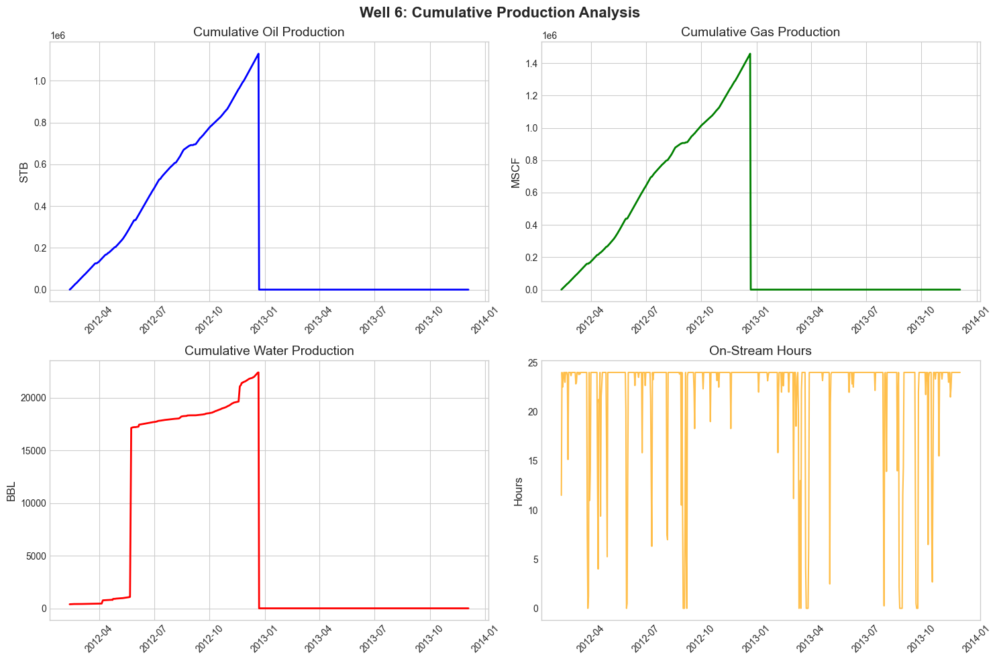

Well 6 has 347 records with zero cumulative production
First zero date: 2012-12-22 00:00:00
Last zero date: 2013-12-04 00:00:00
Last date with actual production: 2012-12-21 00:00:00


In [21]:
# Step 4a: Visualize Well 6 Cumulative Production Issues
print("\n=== STEP 4: ANALYZING CUMULATIVE PRODUCTION ISSUES ===")
print("First, let's visualize Well 6 to understand the problem...")

import matplotlib.pyplot as plt

# Focus on Well 6 which had regression issues
well_6_data = final_clean_data[final_clean_data['WELL_NAME'] == 'Well_#6'].sort_values('PROD_DATE')

if len(well_6_data) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Well 6: Cumulative Production Analysis', fontsize=16, fontweight='bold')
    
    # Oil production
    axes[0,0].plot(well_6_data['PROD_DATE'], well_6_data['CUMULATIVE_OIL_PROD (STB)'], 'b-', linewidth=2)
    axes[0,0].set_title('Cumulative Oil Production')
    axes[0,0].set_ylabel('STB')
    axes[0,0].tick_params(axis='x', rotation=45)
    
    # Gas production
    axes[0,1].plot(well_6_data['PROD_DATE'], well_6_data['CUMULATIVE_FORMATION_GAS_PROD (MSCF)'], 'g-', linewidth=2)
    axes[0,1].set_title('Cumulative Gas Production')
    axes[0,1].set_ylabel('MSCF')
    axes[0,1].tick_params(axis='x', rotation=45)
    
    # Water production
    axes[1,0].plot(well_6_data['PROD_DATE'], well_6_data['CUMULATIVE_WATER_PROD (BBL)'], 'r-', linewidth=2)
    axes[1,0].set_title('Cumulative Water Production')
    axes[1,0].set_ylabel('BBL')
    axes[1,0].tick_params(axis='x', rotation=45)
    
    # On-stream hours
    axes[1,1].plot(well_6_data['PROD_DATE'], well_6_data['ON_STREAM_HRS'], 'orange', alpha=0.7)
    axes[1,1].set_title('On-Stream Hours')
    axes[1,1].set_ylabel('Hours')
    axes[1,1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.grid(False)
    plt.show()
    
    # Identify where cumulative drops to zero
    zero_cumulative_dates = well_6_data[well_6_data[['CUMULATIVE_OIL_PROD (STB)', 
                                                     'CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 
                                                     'CUMULATIVE_WATER_PROD (BBL)']].sum(axis=1) == 0]['PROD_DATE']
    
    print(f"Well 6 has {len(zero_cumulative_dates)} records with zero cumulative production")
    if len(zero_cumulative_dates) > 0:
        print(f"First zero date: {zero_cumulative_dates.min()}")
        print(f"Last zero date: {zero_cumulative_dates.max()}")
        
        # Check if these are at the end or scattered
        last_production_date = well_6_data[well_6_data[['CUMULATIVE_OIL_PROD (STB)', 
                                                         'CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 
                                                         'CUMULATIVE_WATER_PROD (BBL)']].sum(axis=1) > 0]['PROD_DATE'].max()
        
        print(f"Last date with actual production: {last_production_date}")
else:
    print("Well 6 not found in dataset")

In [22]:
# Step 4b: Clinical Fix for Cumulative Production Issues
print("\n=== STEP 4B: CLINICAL CUMULATIVE PRODUCTION FIXES ===")

cumulative_cols = ['CUMULATIVE_OIL_PROD (STB)', 'CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 
                   'CUMULATIVE_TOTAL_GAS_PROD (MSCF)', 'CUMULATIVE_WATER_PROD (BBL)']

records_before = len(final_clean_data)
records_fixed = 0
records_dropped = 0
wells_with_fixes = 0

for well in final_clean_data['WELL_NAME'].unique():
    well_mask = final_clean_data['WELL_NAME'] == well
    well_data = final_clean_data[well_mask].sort_values('PROD_DATE').copy()
    
    # Find first production date
    first_production = well_data[well_data[cumulative_cols].sum(axis=1) > 0]
    
    if len(first_production) > 0:
        first_prod_date = first_production['PROD_DATE'].min()
        post_production = well_data[well_data['PROD_DATE'] >= first_prod_date]
        
        # Find zero cumulative records after production started
        zero_cumulative = post_production[post_production[cumulative_cols].sum(axis=1) == 0]
        
        if len(zero_cumulative) > 0:
            wells_with_fixes += 1
            zero_dates = zero_cumulative['PROD_DATE'].tolist()
            
            # Strategy 1: If zeros are isolated (surrounded by production), forward fill
            isolated_fixes = 0
            for idx in zero_cumulative.index:
                date = final_clean_data.loc[idx, 'PROD_DATE']
                
                # Check if there's production after this date
                future_production = well_data[
                    (well_data['PROD_DATE'] > date) & 
                    (well_data[cumulative_cols].sum(axis=1) > 0)
                ]
                
                if len(future_production) > 0:
                    # This is isolated - forward fill from previous valid record
                    prev_data = well_data[
                        (well_data['PROD_DATE'] < date) & 
                        (well_data[cumulative_cols].sum(axis=1) > 0)
                    ].sort_values('PROD_DATE')
                    
                    if len(prev_data) > 0:
                        # Forward fill from last valid record
                        last_valid = prev_data.iloc[-1]
                        for col in cumulative_cols:
                            final_clean_data.loc[idx, col] = last_valid[col]
                        isolated_fixes += 1
            
            # Strategy 2: If zeros are at the end (no future production), drop them
            end_zeros = zero_cumulative[
                zero_cumulative.apply(lambda row: len(well_data[
                    (well_data['PROD_DATE'] > row['PROD_DATE']) & 
                    (well_data[cumulative_cols].sum(axis=1) > 0)
                ]) == 0, axis=1)
            ]
            
            if len(end_zeros) > 0:
                # Drop these records - they're systematic tail-end data loss
                drop_indices = end_zeros.index
                final_clean_data.drop(drop_indices, inplace=True)
                records_dropped += len(drop_indices)
                
                if well in ['Well 6']:  # Show details for Well 6
                    print(f"  - {well}: Dropped {len(drop_indices)} tail-end records with zero cumulatives")
                    print(f"    Last dropped date: {end_zeros['PROD_DATE'].max()}")
            
            if isolated_fixes > 0:
                records_fixed += isolated_fixes
                if well in ['Well 6'] or wells_with_fixes <= 3:
                    print(f"  - {well}: Forward-filled {isolated_fixes} isolated zero records")

print(f"\n✓ Cumulative Production Fixes Applied:")
print(f"  - Records forward-filled (isolated zeros): {records_fixed}")
print(f"  - Records dropped (systematic tail-end issues): {records_dropped}")
print(f"  - Wells with fixes applied: {wells_with_fixes}")

# Reset index after dropping records
final_clean_data.reset_index(drop=True, inplace=True)
print(f"  - Final records: {len(final_clean_data):,} (removed {records_before - len(final_clean_data):,} total)")


=== STEP 4B: CLINICAL CUMULATIVE PRODUCTION FIXES ===

✓ Cumulative Production Fixes Applied:
  - Records forward-filled (isolated zeros): 0
  - Records dropped (systematic tail-end issues): 347
  - Wells with fixes applied: 1
  - Final records: 7,595 (removed 347 total)


In [23]:
# Step 5: Finalize Dataset - Sort, Calculate Production Days, and Save
print("\n=== STEP 5: FINALIZING CLEANED DATASET ===")

# Sort by well name and production date
final_clean_data = final_clean_data.sort_values(['WELL_NAME', 'PROD_DATE']).reset_index(drop=True)
print("✓ Data sorted by well name and production date")

# Calculate total production days for each well
well_summary = []
for well in final_clean_data['WELL_NAME'].unique():
    well_data = final_clean_data[final_clean_data['WELL_NAME'] == well]
    
    total_days = len(well_data)
    date_range = (well_data['PROD_DATE'].max() - well_data['PROD_DATE'].min()).days + 1
    first_date = well_data['PROD_DATE'].min()
    last_date = well_data['PROD_DATE'].max()
    
    # Calculate actual production days (where onstream > 0)
    production_days = len(well_data[well_data['ON_STREAM_HRS'] > 0])
    
    well_summary.append({
        'WELL_NAME': well,
        'Total_Records': total_days,
        'Date_Range_Days': date_range,
        'First_Date': first_date,
        'Last_Date': last_date,
        'Production_Days': production_days,
        'Production_Ratio': production_days / total_days
    })

well_summary_df = pd.DataFrame(well_summary)

print(f"\n📊 WELL PRODUCTION SUMMARY:")
print(f"Total Wells: {len(well_summary_df)}")
print(f"Total Records in Final Dataset: {len(final_clean_data):,}")
print()

print("Well-by-Well Summary:")
# Sort wells numerically (Well 1, Well 2, ..., Well 20)
well_summary_df['Well_Number'] = well_summary_df['WELL_NAME'].str.extract('(\d+)').astype(int)
well_summary_sorted = well_summary_df.sort_values('Well_Number')[['WELL_NAME', 'Total_Records', 'Production_Days', 'Production_Ratio']]
print(well_summary_sorted.to_string(index=False))

print(f"\nDataset Statistics:")
print(f"- Average records per well: {well_summary_df['Total_Records'].mean():.1f}")
print(f"- Average production days per well: {well_summary_df['Production_Days'].mean():.1f}")
print(f"- Overall production ratio: {well_summary_df['Production_Days'].sum() / well_summary_df['Total_Records'].sum():.2%}")

# Save the cleaned dataset
output_filename = 'cleaned_well_production_data.csv'
final_clean_data.to_csv(output_filename, index=False)

# Final data quality check
print(f"\n🔍 FINAL DATA QUALITY CHECK:")
print(f"- Records with ON_STREAM_HRS > 24: {len(final_clean_data[final_clean_data['ON_STREAM_HRS'] > 24])}")
print(f"- Records with zero downhole temperature: {len(final_clean_data[final_clean_data['DOWNHOLE_TEMPERATURE (deg F)'] == 0])}")
print(f"- Records with zero wellhead temperature: {len(final_clean_data[final_clean_data['WELL_HEAD_TEMPERATURE (deg F)'] == 0])}")

# Check for remaining cumulative production issues
remaining_issues = 0
for well in final_clean_data['WELL_NAME'].unique():
    well_data = final_clean_data[final_clean_data['WELL_NAME'] == well].sort_values('PROD_DATE')
    first_production = well_data[well_data[cumulative_cols].sum(axis=1) > 0]
    if len(first_production) > 0:
        first_prod_date = first_production['PROD_DATE'].min()
        post_production = well_data[well_data['PROD_DATE'] >= first_prod_date]
        zero_after_start = len(post_production[post_production[cumulative_cols].sum(axis=1) == 0])
        remaining_issues += zero_after_start

print(f"- Remaining cumulative production issues: {remaining_issues}")
print("DATA CLEANING COMPLETE!")


=== STEP 5: FINALIZING CLEANED DATASET ===
✓ Data sorted by well name and production date

📊 WELL PRODUCTION SUMMARY:
Total Wells: 20
Total Records in Final Dataset: 7,595

Well-by-Well Summary:
WELL_NAME  Total_Records  Production_Days  Production_Ratio
  Well_#1            203              192          0.945813
  Well_#2            477              231          0.484277
  Well_#3            123               99          0.804878
  Well_#4            290              285          0.982759
  Well_#5            314              311          0.990446
  Well_#6            313              307          0.980831
  Well_#7            523              522          0.998088
  Well_#8            372              342          0.919355
  Well_#9            582              582          1.000000
 Well_#10            425              400          0.941176
 Well_#11            341              319          0.935484
 Well_#12            769              727          0.945384
 Well_#13            247

## 2. Feature Insights: Production Profiles and Trends

Before proceeding to rule-based analysis, let's visualize the production profiles for all wells to understand:
- Daily oil, gas, and water production rates
- Bottom-hole pressure trends
- Production patterns and anomalies
- Well performance characteristics

This comprehensive visualization will help us identify patterns that inform our rule-based classification approach.

In [24]:
# Load the cleaned dataset
print("=== LOADING CLEANED DATASET ===")
try:
    clean_data = pd.read_csv('cleaned_well_production_data.csv')
    clean_data['PROD_DATE'] = pd.to_datetime(clean_data['PROD_DATE'])
    print(f"✓ Loaded cleaned dataset: {len(clean_data):,} records")
    print(f"✓ Date range: {clean_data['PROD_DATE'].min()} to {clean_data['PROD_DATE'].max()}")
    print(f"✓ Wells: {clean_data['WELL_NAME'].nunique()}")
    
    # Calculate daily production rates
    clean_data['DAILY_OIL_RATE'] = clean_data['CUMULATIVE_OIL_PROD (STB)'].diff().fillna(0)
    clean_data['DAILY_GAS_RATE'] = clean_data['CUMULATIVE_FORMATION_GAS_PROD (MSCF)'].diff().fillna(0)
    clean_data['DAILY_WATER_RATE'] = clean_data['CUMULATIVE_WATER_PROD (BBL)'].diff().fillna(0)
    
    # Handle negative rates (reset cumulative counters) by setting to 0
    clean_data.loc[clean_data['DAILY_OIL_RATE'] < 0, 'DAILY_OIL_RATE'] = 0
    clean_data.loc[clean_data['DAILY_GAS_RATE'] < 0, 'DAILY_GAS_RATE'] = 0
    clean_data.loc[clean_data['DAILY_WATER_RATE'] < 0, 'DAILY_WATER_RATE'] = 0
    
    print("✓ Daily production rates calculated")
    
except FileNotFoundError:
    print("Cleaned dataset not found. Please run Section 1.4 first to generate 'cleaned_well_production_data.csv'")
    clean_data = None

=== LOADING CLEANED DATASET ===
✓ Loaded cleaned dataset: 7,595 records
✓ Date range: 2011-02-17 00:00:00 to 2016-08-12 00:00:00
✓ Wells: 20
✓ Daily production rates calculated



=== CREATING PRODUCTION PROFILE VISUALIZATION ===
Creating visualization for 20 wells...


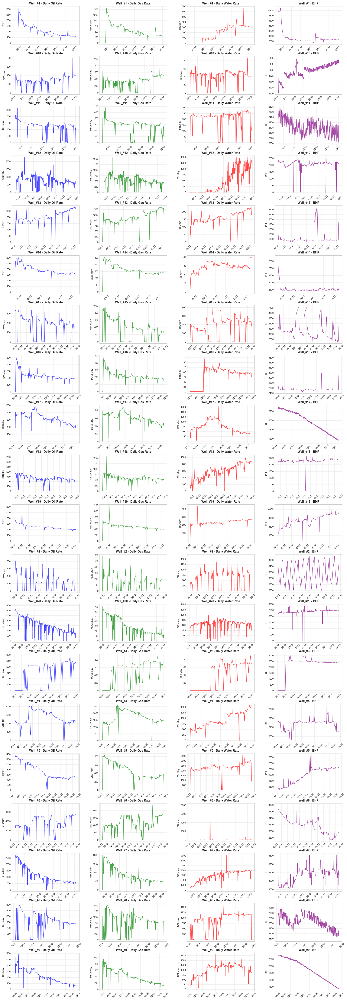

✅ Production profile visualization complete!

📊 PRODUCTION SUMMARY STATISTICS:
    Well  Records  Avg_Oil_Rate  Max_Oil_Rate  Avg_BHP
 Well_#1      203         500.8        1550.0   2943.5
Well_#10      425         273.3         805.0   3995.7
Well_#11      341         488.3        1072.0   2427.4
Well_#12      769         752.6        2260.0   1996.7
Well_#13      247         771.5        1122.0   1611.4
Well_#14      184         773.2        1225.0   2406.7
Well_#15      327         361.6         745.0   3139.8
Well_#16      294         230.2         514.0   2542.2
Well_#17      436         639.6         966.0   1968.7
Well_#18      311         659.3        1790.0   2216.2
Well_#19      246         488.7        1219.0   3877.1
 Well_#2      477         156.0         941.0   3164.1
Well_#20      818         607.3        1385.0   2382.1
 Well_#3      123         793.0        1471.0   2179.1
 Well_#4      290        1327.6        2065.0   2132.8
 Well_#5      314         721.7        13

In [25]:
# Create comprehensive production profile visualization: 20 wells x 4 parameters
if clean_data is not None:
    print("\n=== CREATING PRODUCTION PROFILE VISUALIZATION ===")
    
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib.gridspec import GridSpec
    
    # Get wells in order (Well 1 to Well 20)
    wells = sorted(clean_data['WELL_NAME'].unique(), 
                   key=lambda x: int(x.split(' ')[1]) if 'Well ' in x else float('inf'))
    
    # Create the large figure with subplots (20 rows x 4 columns)
    fig = plt.figure(figsize=(20, 60))  # Large figure to accommodate all subplots
    gs = GridSpec(20, 4, hspace=0.3, wspace=0.3)
    
    print(f"Creating visualization for {len(wells)} wells...")
    
    for i, well in enumerate(wells):
        well_data = clean_data[clean_data['WELL_NAME'] == well].sort_values('PROD_DATE')
        
        if len(well_data) == 0:
            continue
            
        # Column 1: Daily Oil Rate
        ax1 = fig.add_subplot(gs[i, 0])
        ax1.plot(well_data['PROD_DATE'], well_data['DAILY_OIL_RATE'], 'b-', linewidth=1, alpha=0.7)
        ax1.set_title(f'{well} - Daily Oil Rate', fontsize=10, fontweight='bold')
        ax1.set_ylabel('STB/day', fontsize=8)
        ax1.tick_params(axis='both', labelsize=8)
        ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
        ax1.grid(True, alpha=0.3)
        
        # Column 2: Daily Gas Rate
        ax2 = fig.add_subplot(gs[i, 1])
        ax2.plot(well_data['PROD_DATE'], well_data['DAILY_GAS_RATE'], 'g-', linewidth=1, alpha=0.7)
        ax2.set_title(f'{well} - Daily Gas Rate', fontsize=10, fontweight='bold')
        ax2.set_ylabel('MSCF/day', fontsize=8)
        ax2.tick_params(axis='both', labelsize=8)
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
        ax2.grid(True, alpha=0.3)
        
        # Column 3: Daily Water Rate
        ax3 = fig.add_subplot(gs[i, 2])
        ax3.plot(well_data['PROD_DATE'], well_data['DAILY_WATER_RATE'], 'r-', linewidth=1, alpha=0.7)
        ax3.set_title(f'{well} - Daily Water Rate', fontsize=10, fontweight='bold')
        ax3.set_ylabel('BBL/day', fontsize=8)
        ax3.tick_params(axis='both', labelsize=8)
        ax3.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
        ax3.grid(True, alpha=0.3)
        
        # Column 4: Bottom-hole Pressure
        ax4 = fig.add_subplot(gs[i, 3])
        ax4.plot(well_data['PROD_DATE'], well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'], 'purple', linewidth=1, alpha=0.7)
        ax4.set_title(f'{well} - BHP', fontsize=10, fontweight='bold')
        ax4.set_ylabel('PSI', fontsize=8)
        ax4.tick_params(axis='both', labelsize=8)
        ax4.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
        ax4.grid(True, alpha=0.3)
        
        # Rotate x-axis labels for better readability
        for ax in [ax1, ax2, ax3, ax4]:
            ax.tick_params(axis='x', rotation=45)
    
   
    
    plt.tight_layout()
    plt.show()
    
    print("✅ Production profile visualization complete!")
    
    # Print summary statistics
    print(f"\n📊 PRODUCTION SUMMARY STATISTICS:")
    production_stats = []
    
    for well in wells:
        well_data = clean_data[clean_data['WELL_NAME'] == well]
        if len(well_data) > 0:
            stats = {
                'Well': well,
                'Records': len(well_data),
                'Avg_Oil_Rate': well_data['DAILY_OIL_RATE'].mean(),
                'Max_Oil_Rate': well_data['DAILY_OIL_RATE'].max(),
                'Avg_Gas_Rate': well_data['DAILY_GAS_RATE'].mean(),
                'Avg_BHP': well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].mean()
            }
            production_stats.append(stats)
    
    stats_df = pd.DataFrame(production_stats)
    print(stats_df[['Well', 'Records', 'Avg_Oil_Rate', 'Max_Oil_Rate', 'Avg_BHP']].round(1).to_string(index=False))
    
else:
    print("❌ Cannot create visualization - cleaned data not available")

# 3. Specialized Engineering Analysis

In this section, we'll perform more focused petroleum engineering analyses, rule based classification, as given by the instruction file to gain deeper insights into reservoir and well behavior:

1. **Reservoir characterization** - Determining which reservoir name and type the wells are producing from
2. **Production Status** - Steady or Unsteady
2. **Lift mechanism analysis** - Identifying whether wells are on natural flow or artificial lift
3. **GOR classification** - Classifying wells based on GOR behavior relative to solution GOR
4. **Water cut trends** - Analyzing water production trends and implications for well health
5. **Productivity Index (PI) analysis** - Evaluating well productivity and pressure relationships

In [26]:
clean_data = pd.read_csv('cleaned_well_production_data.csv')
clean_data.info()
data=clean_data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7595 entries, 0 to 7594
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   PROD_DATE                             7595 non-null   object 
 1   WELL_NAME                             7595 non-null   object 
 2   ON_STREAM_HRS                         7595 non-null   float64
 3   BOTTOMHOLE_FLOWING_PRESSURE (PSI)     7595 non-null   float64
 4   DOWNHOLE_TEMPERATURE (deg F)          7595 non-null   float64
 5   ANNULUS_PRESS (PSI)                   7595 non-null   float64
 6   CHOKE_SIZE (%)                        7595 non-null   float64
 7   WELL_HEAD_PRESSURE (PSI)              7595 non-null   float64
 8   WELL_HEAD_TEMPERATURE (deg F)         7595 non-null   float64
 9   CUMULATIVE_OIL_PROD (STB)             7595 non-null   float64
 10  CUMULATIVE_FORMATION_GAS_PROD (MSCF)  7595 non-null   float64
 11  CUMULATIVE_TOTAL_

## 3.1 Reservoir Characterization

We can determine which reservoir each well is producing from by analyzing the maximum bottomhole pressure (BHP). Assuming the maximum recorded BHP is close to the initial reservoir pressure, we can compare these values to the known reservoir pressures.

Let's analyze the maximum BHP for each well and match it with the corresponding reservoir.


=== BHP ANALYSIS FOR RESERVOIR CLASSIFICATION ===
Analyzing BHP patterns for 20 wells...


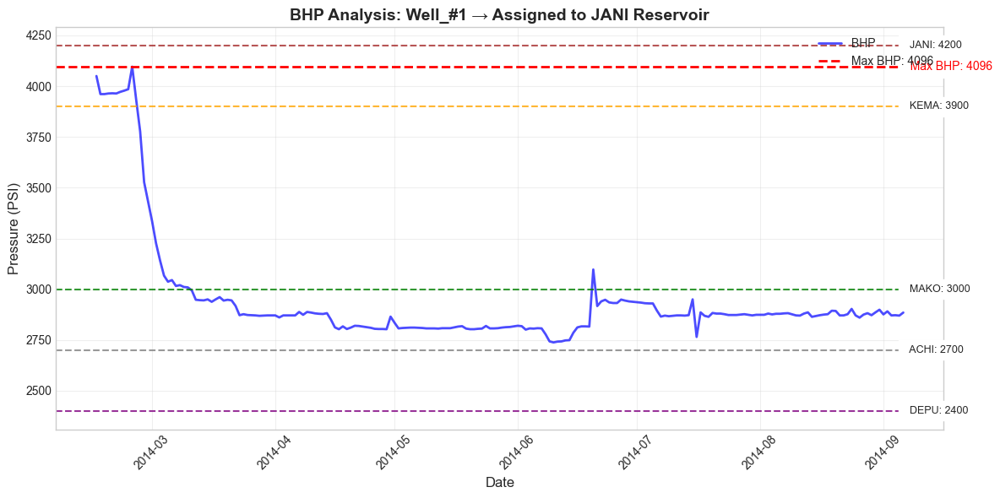

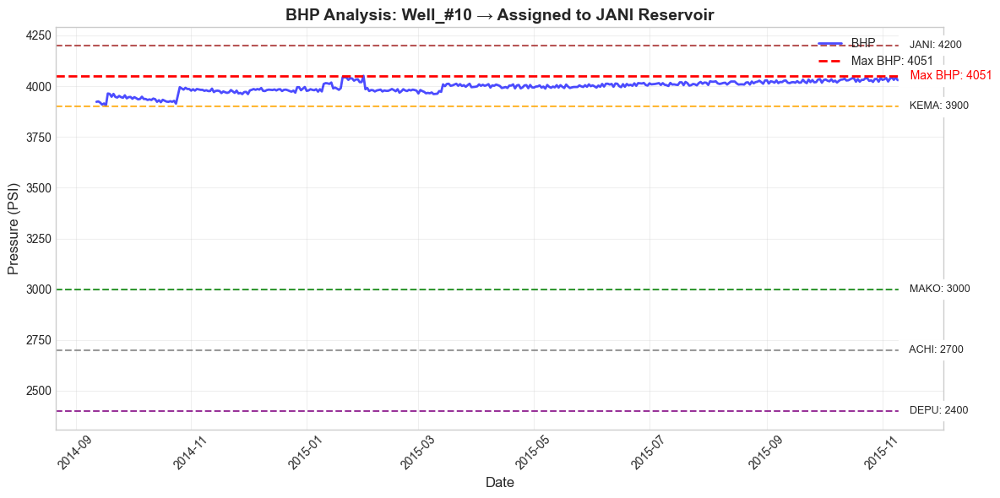

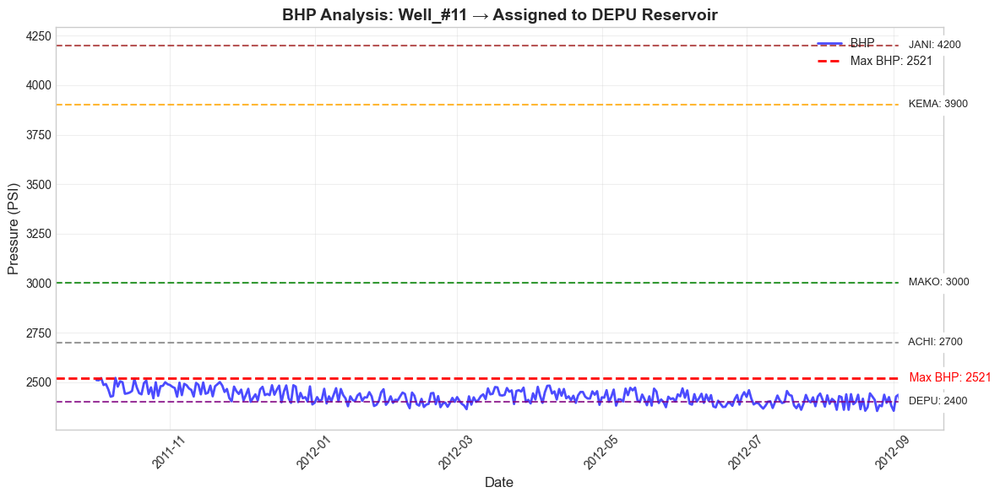

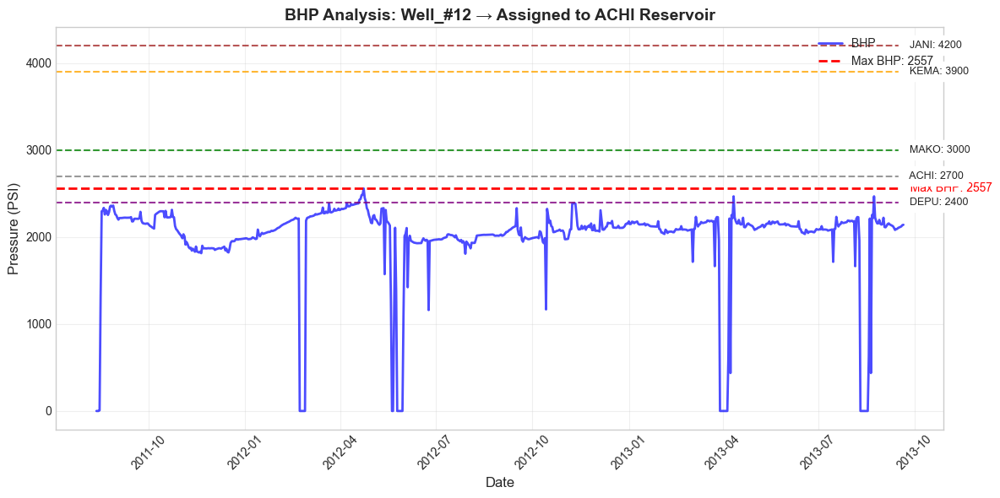

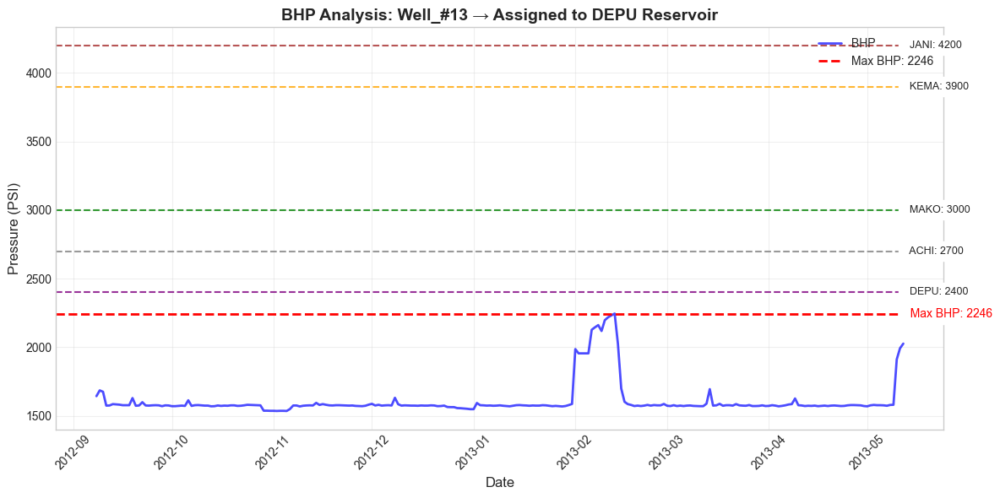

...

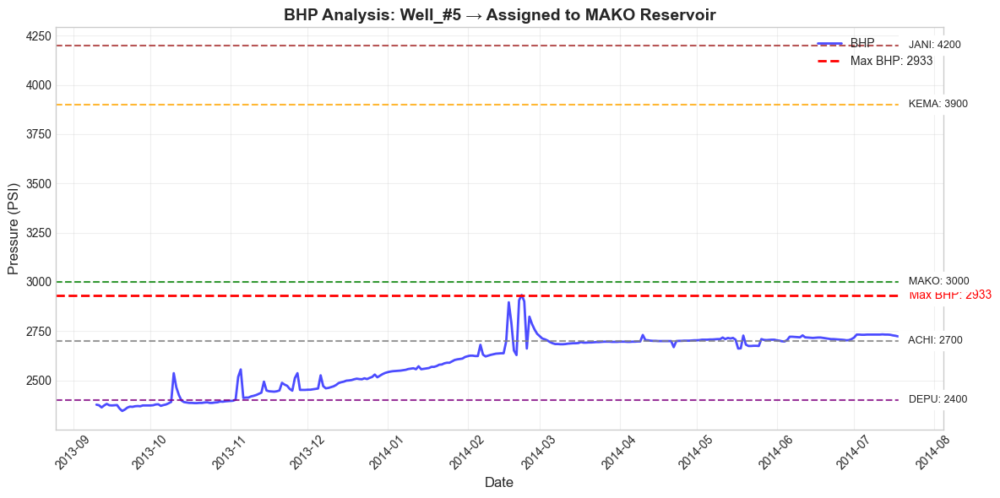

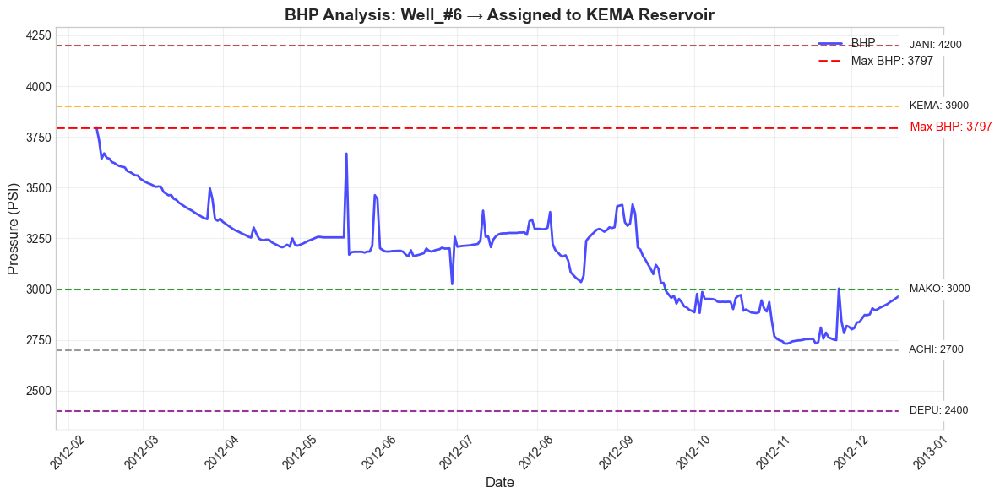

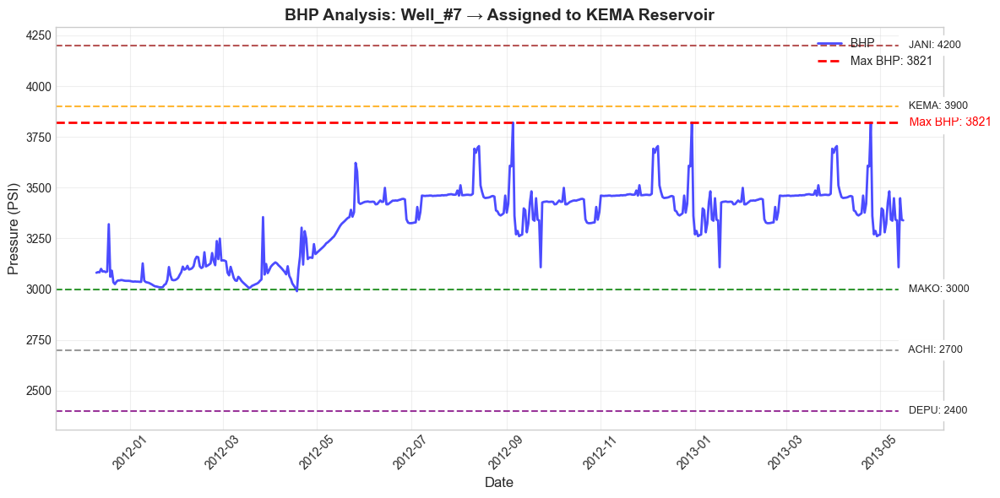

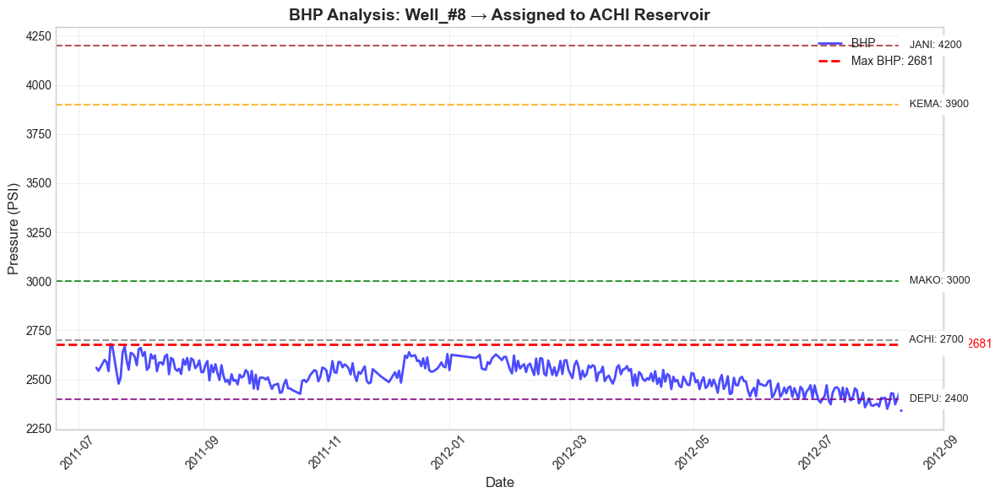

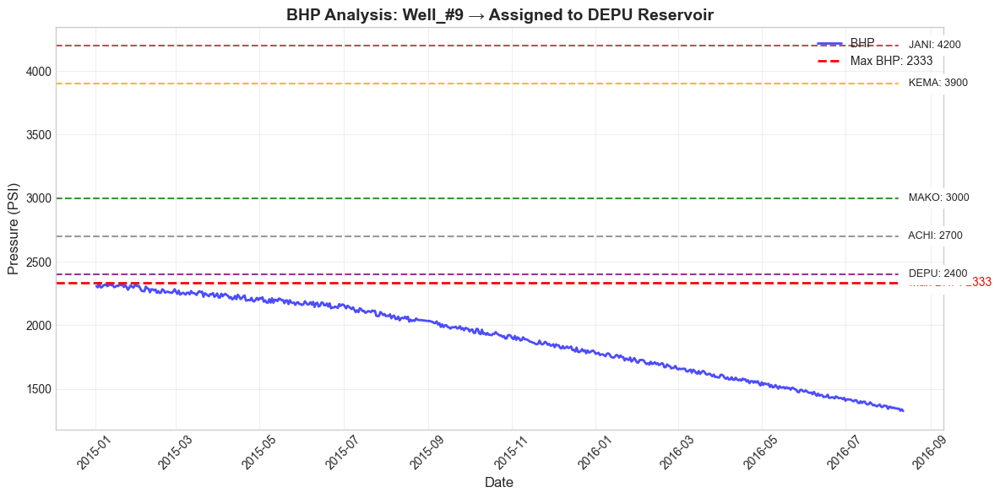


 RESERVOIR ASSIGNMENT RESULTS:


,WELL_NAME,Assigned_Reservoir
0,Well_#1,JANI
1,Well_#10,JANI
2,Well_#11,DEPU
3,Well_#12,ACHI
4,Well_#13,DEPU
5,Well_#14,MAKO
6,Well_#15,KEMA
7,Well_#16,KEMA
8,Well_#17,DEPU
9,Well_#18,ACHI


In [27]:
# BHP Analysis with Reservoir Target Pressures for Rule-Based Classification

print("\n=== BHP ANALYSIS FOR RESERVOIR CLASSIFICATION ===")

import matplotlib.dates as mdates

# Ensure datetime format
clean_data['PROD_DATE'] = pd.to_datetime(clean_data['PROD_DATE'])

# Column name for Bottomhole Flowing Pressure
bhp_col = 'BOTTOMHOLE_FLOWING_PRESSURE (PSI)'

# Reservoir target pressures (from your previous analysis)
targets = {
    'ACHI': 2700,
    'KEMA': 3900,
    'MAKO': 3000,
    'DEPU': 2400,
    'JANI': 4200
}

# Get wells in order (Well 1 to Well 20)
wells = sorted(clean_data['WELL_NAME'].unique(), 
                key=lambda x: int(x.split(' ')[1]) if 'Well ' in x else float('inf'))

# Initialize reservoir assignment list
reservoir_assignments = []

print(f"Analyzing BHP patterns for {len(wells)} wells...")

# Group by well and plot each one separately
for well in wells:
    group = clean_data[clean_data['WELL_NAME'] == well].sort_values('PROD_DATE')
    
    if len(group) == 0:
        continue
        
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plot BHP vs Date
    ax.plot(group['PROD_DATE'], group[bhp_col], label='BHP', linewidth=2, color='blue', alpha=0.7)

    # Plot the Max BHP for this well
    max_bhp = group[bhp_col].max()
    ax.axhline(max_bhp, color='red', linestyle='--', linewidth=2, label=f"Max BHP: {max_bhp:.0f}")
    ax.text(group['PROD_DATE'].max(), max_bhp, f"  Max BHP: {max_bhp:.0f}", 
            va='center', ha='left', fontsize=10, color='red', backgroundcolor='white')
    
    # Plot reservoir target pressures
    colors = ['gray', 'orange', 'green', 'purple', 'brown']
    for i, (label, pressure) in enumerate(targets.items()):
        ax.axhline(pressure, linestyle='--', linewidth=1.5, color=colors[i % len(colors)], alpha=0.8)
        ax.text(group['PROD_DATE'].max(), pressure, f"  {label}: {pressure}", 
                va='center', ha='left', fontsize=9, backgroundcolor='white')

    # Determine reservoir assignment based on max BHP
    assigned_reservoir = None
    min_diff = float('inf')
    
    for reservoir, target_pressure in targets.items():
        diff = abs(max_bhp - target_pressure)
        if diff < min_diff:
            min_diff = diff
            assigned_reservoir = reservoir
    
    # Store assignment
    reservoir_assignments.append({
        'WELL_NAME': well,
        'Max_BHP': max_bhp,
        'Assigned_Reservoir': assigned_reservoir,
        'Target_Pressure': targets[assigned_reservoir],
        'Pressure_Diff': min_diff
    })
    
    ax.set_title(f"BHP Analysis: {well} → Assigned to {assigned_reservoir} Reservoir", 
                    fontsize=14, fontweight='bold')
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("Pressure (PSI)", fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    
    # Format x-axis dates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

# Create reservoir assignment table
reservoir_df = pd.DataFrame(reservoir_assignments)

print(f"\n RESERVOIR ASSIGNMENT RESULTS:")
print("="*60)
# Extract only WELL_NAME and Assigned_Reservoir
classified_df = reservoir_df[['WELL_NAME', 'Assigned_Reservoir']]

# Save the simplified classification to CSV
classified_df.to_csv('well_classificatioJ.csv', index=False)

classified_df

## 3.2 Reservoir Type Classification

In [28]:

print("\n=== RESERVOIR TYPE CLASSIFICATION ===")
print("Determining if each reservoir is Saturated or Undersaturated based on initial pressure vs bubble point")

# Convert any string-formatted pressures to numeric
for col in ['Initial Reservoir Pressure (PSI)', 'Bubble Point Pressure (PSI)']:
    if reservoir_info[col].dtype == 'object':
        reservoir_info[col] = reservoir_info[col].str.replace(',', '').astype(float)
    
# Create reservoir type mapping based on the rule:
# If Initial Pressure <= Bubble Point → Saturated, else → Undersaturated
reservoir_type_map = {}
for _, row in reservoir_info.iterrows():
    initial_pressure = row['Initial Reservoir Pressure (PSI)']
    bubble_point = row['Bubble Point Pressure (PSI)']
    
    # Apply the classification rule
    if initial_pressure <= bubble_point:
        reservoir_type = "Saturated"
    else:
        reservoir_type = "Undersaturated"
        
    reservoir_type_map[row['Reservoir Name']] = reservoir_type

# Display the reservoir type mapping
print("\nReservoir Type Classification:")
print("-" * 50)
print(f"{'Reservoir':<10} | {'Initial P (PSI)':<15} | {'Bubble P (PSI)':<15} | {'Type':<15}")
print("-" * 50)
for res, res_type in reservoir_type_map.items():
    initial_p = reservoir_info.loc[reservoir_info['Reservoir Name'] == res, 'Initial Reservoir Pressure (PSI)'].iloc[0]
    bubble_p = reservoir_info.loc[reservoir_info['Reservoir Name'] == res, 'Bubble Point Pressure (PSI)'].iloc[0]
    print(f"{res:<10} | {initial_p:<15.1f} | {bubble_p:<15.1f} | {res_type:<15}")

# Add reservoir type to well classification DataFrame
if 'classified_df' in globals():
    classified_df['Reservoir_Type'] = classified_df['Assigned_Reservoir'].map(reservoir_type_map)
    
    # Save updated classification to CSV
    classified_df.to_csv('well_classification.csv', index=False)
    
    print("\nWell Reservoir Classification Results with Reservoir Type:")
    print(classified_df)
else:
    print("\nError: Well classification DataFrame not found. Please run the reservoir assignment section first.")


=== RESERVOIR TYPE CLASSIFICATION ===
Determining if each reservoir is Saturated or Undersaturated based on initial pressure vs bubble point

Reservoir Type Classification:
--------------------------------------------------
Reservoir  | Initial P (PSI) | Bubble P (PSI)  | Type           
--------------------------------------------------
ACHI       | 3500.0          | 3300.0          | Undersaturated 
KEMA       | 4200.0          | 4000.0          | Undersaturated 
MAKO       | 3500.0          | 3500.0          | Saturated      
DEPU       | 2800.0          | 2800.0          | Saturated      
JANI       | 4500.0          | 4300.0          | Undersaturated 

Well Reservoir Classification Results with Reservoir Type:
   WELL_NAME Assigned_Reservoir  Reservoir_Type
0    Well_#1               JANI  Undersaturated
1   Well_#10               JANI  Undersaturated
2   Well_#11               DEPU       Saturated
3   Well_#12               ACHI  Undersaturated
4   Well_#13               DEPU   

## **3.3 Well Type Classification: Natural Flow vs Gas Lift**

Identify whether wells are naturally flowing or gas lifted based on comprehensive analysis of:

### **Classification Criteria**
- **BHP (Bottom Hole Pressure) trends**: 
  - *Natural Flow*: Generally shows declining BHP over time as reservoir pressure depletes
  - *Gas Lift*: Tends to show stable or even increasing BHP due to gas injection support

- **Oil Rate Performance**:
  - *Natural Flow*: Typically exhibits declining rates following natural depletion patterns
  - *Gas Lift*: Often maintains more stable production rates due to artificial lift support

- **GOR (Gas-Oil Ratio) Patterns**:
  - *Natural Flow*: Shows more natural, gradual evolution of GOR 
  - *Gas Lift*: May display erratic GOR behavior due to injected gas affecting measurements

### Analysis Approach
We'll implement a 3-column visualization approach for each well:
1. **Column 1**: BHP and Daily Oil Rate vs Time (dual y-axis plot)
   - Visualizes relationship between pressure and production
   - Shows if pressure stabilization correlates with rate maintenance

2. **Column 2**: Gas Production Rate vs Time
   - Highlights gas production trends and anomalies
   - Helps identify gas lift signatures (e.g., sudden increases, periodic patterns)

3. **Column 3**: GOR (Gas-Oil Ratio) vs Time
   - Reveals relationship between gas and oil production
   - Artificial lift often creates distinctive GOR signatures

### Classification Methodology
The analysis will incorporate:
- Calculation of BHP stability metrics
- Evaluation of BHP trend direction (increasing/decreasing)
- Assessment of rate stability correlated with pressure behavior
- Rule-based classification system with clear thresholds

=== WELL TYPE CLASSIFICATION ANALYSIS ===
Calculating daily oil production rates...
Calculating daily gas production rates...
Calculating Gas-Oil Ratio (GOR)...
Cleaning production data...
Analyzing 20 wells for flow mechanism classification...
Generating visualization grid for all wells...
Analyzing well Well_#1...
  Calculating classification metrics for Well_#1...
  Well_#1 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#10...
  Calculating classification metrics for Well_#10...
  Well_#10 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#11...
  Calculating classification metrics for Well_#11...
  Well_#11 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#12...
  Calculating classification metrics for Well_#12...
  Well_#12 classified as: Natural Flow (High confidence) - Declining BHP trend
Analyzing well Well_#13...
  Calculating classificatio

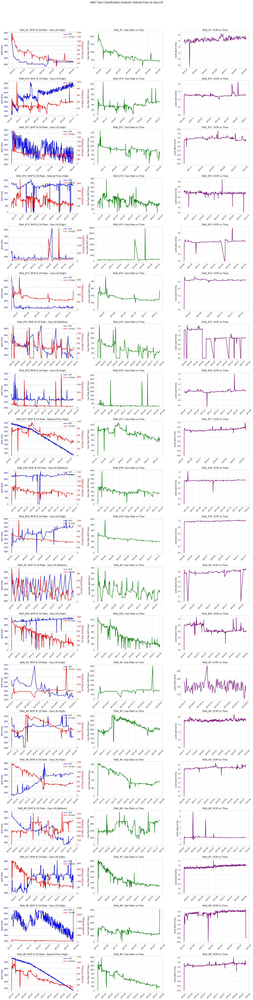

In [29]:
# 3.3 Well Type Classification: Natural Flow vs Gas Lift Analysis
print("=== WELL TYPE CLASSIFICATION ANALYSIS ===")

# Calculate daily rates from cumulative production using on-stream hours
clean_data = clean_data.sort_values(['WELL_NAME', 'PROD_DATE'])

# Calculate daily oil production rate
print("Calculating daily oil production rates...")
clean_data['DAILY_OIL_PROD'] = clean_data.groupby('WELL_NAME')['CUMULATIVE_OIL_PROD (STB)'].diff()
clean_data['DAILY_OIL_RATE'] = (clean_data['DAILY_OIL_PROD'] / clean_data['ON_STREAM_HRS'] * 24).fillna(0)

# Calculate daily gas production rate  
print("Calculating daily gas production rates...")
clean_data['DAILY_GAS_PROD'] = clean_data.groupby('WELL_NAME')['CUMULATIVE_TOTAL_GAS_PROD (MSCF)'].diff()
clean_data['DAILY_GAS_RATE'] = (clean_data['DAILY_GAS_PROD'] / clean_data['ON_STREAM_HRS'] * 24).fillna(0)

# Calculate daily GOR (Gas Oil Ratio)
print("Calculating Gas-Oil Ratio (GOR)...")
clean_data['DAILY_GOR'] = clean_data['DAILY_GAS_RATE'] / (clean_data['DAILY_OIL_RATE'] + 1e-6)  # Add small value to avoid division by zero

# Data cleaning: Remove negative rates and cap extreme GOR values
print("Cleaning production data...")
clean_data.loc[clean_data['DAILY_OIL_RATE'] < 0, 'DAILY_OIL_RATE'] = 0
clean_data.loc[clean_data['DAILY_GAS_RATE'] < 0, 'DAILY_GAS_RATE'] = 0
clean_data.loc[clean_data['DAILY_GOR'] > 10000, 'DAILY_GOR'] = 10000  # Cap extreme GOR values

# Get wells in order (Well_#X format)
wells = sorted(clean_data['WELL_NAME'].unique(), 
              key=lambda x: int(x.split(' ')[1]) if 'Well ' in x else float('inf'))

print(f"Analyzing {len(wells)} wells for flow mechanism classification...")

# Create storage for classification results
well_type_results = []

# Create 3-column grid plot for all wells
print("Generating visualization grid for all wells...")
fig, axes = plt.subplots(len(wells), 3, figsize=(20, 4*len(wells)))
fig.suptitle('Well Type Classification Analysis: Natural Flow vs Gas Lift', fontsize=16)

# Define time window for trend analysis (e.g., first 5 and last 5 data points)
trend_window = 5

for i, well in enumerate(wells):
    print(f"Analyzing well {well}...")
    well_data = clean_data[clean_data['WELL_NAME'] == well].copy()
    well_data = well_data[well_data['ON_STREAM_HRS'] > 0].sort_values('PROD_DATE')  # Filter valid data
    
    if len(well_data) < 10:  # Need sufficient data points for analysis
        print(f"  Insufficient data points for {well}, skipping detailed analysis")
        continue
        
    # Plot 1: BHP and Oil Rate vs Time (dual y-axis)
    ax1 = axes[i, 0]
    ax1_twin = ax1.twinx()
    
    # BHP line
    ax1.plot(well_data['PROD_DATE'], well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'], 
             'b-', label='BHP', linewidth=2)
    ax1.set_ylabel('BHP (PSI)', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    
    # Oil Rate line
    ax1_twin.plot(well_data['PROD_DATE'], well_data['DAILY_OIL_RATE'], 
                 'r-', label='Oil Rate', linewidth=2)
    ax1_twin.set_ylabel('Oil Rate (STB/day)', color='red')
    ax1_twin.tick_params(axis='y', labelcolor='red')
    
    # Add both legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
    
    ax1.set_title(f'{well}: BHP & Oil Rate vs Time')
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(axis='x', rotation=45)
    
    # Plot 2: Gas Rate vs Time
    ax2 = axes[i, 1]
    ax2.plot(well_data['PROD_DATE'], well_data['DAILY_GAS_RATE'], 
             'g-', linewidth=2)
    ax2.set_ylabel('Gas Rate (MCF/day)')
    ax2.set_title(f'{well}: Gas Rate vs Time')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)
    
    # Plot 3: GOR vs Time
    ax3 = axes[i, 2]
    ax3.plot(well_data['PROD_DATE'], well_data['DAILY_GOR'], 
             'purple', linewidth=2)
    ax3.set_ylabel('GOR (MCF/STB)')
    ax3.set_title(f'{well}: GOR vs Time')
    ax3.grid(True, alpha=0.3)
    ax3.tick_params(axis='x', rotation=45)
    
    # Calculate metrics for classification
    print(f"  Calculating classification metrics for {well}...")
    
    # 1. BHP Stability (Coefficient of Variation = std/mean)
    bhp_cv = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].std() / well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].mean()
    
    # 2. BHP Trend: Compare early vs late BHP values
    if len(well_data) >= 2*trend_window:
        early_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[:trend_window].mean()
        late_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[-trend_window:].mean()
        bhp_trend = late_bhp - early_bhp
    else:
        # For wells with limited data, use first and last point
        early_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[0]
        late_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[-1]
        bhp_trend = late_bhp - early_bhp
    
    # 3. Oil Rate Stability
    oil_cv = well_data['DAILY_OIL_RATE'].std() / (well_data['DAILY_OIL_RATE'].mean() + 1e-6)
    
    # 4. GOR Stability
    gor_cv = well_data['DAILY_GOR'].std() / (well_data['DAILY_GOR'].mean() + 1e-6)
    
    # Classification Logic:
    # Natural Flow: Declining BHP trend
    # Gas Lift: Stable/increasing BHP or very low BHP variability
    
    # Decision logic - can be refined based on domain expertise
    if bhp_trend > 0 or bhp_cv < 0.1:
        well_type = "Gas Lift"
        classification_reason = "Stable or increasing BHP trend"
        confidence = "High" if bhp_trend > 200 or bhp_cv < 0.05 else "Medium"
    else:
        well_type = "Natural Flow"
        classification_reason = "Declining BHP trend"
        confidence = "High" if bhp_trend < -200 or bhp_cv > 0.15 else "Medium"
    
    print(f"  {well} classified as: {well_type} ({confidence} confidence) - {classification_reason}")
    
    # Store detailed classification results
    well_type_results.append({
        'WELL_NAME': well,
        'Well_Type': well_type,
        'Classification_Reason': classification_reason, 
        'Confidence': confidence,
        'BHP_CV': round(bhp_cv, 3),
        'BHP_Trend': round(bhp_trend, 1),
        'Early_BHP': round(early_bhp, 1),
        'Late_BHP': round(late_bhp, 1),
        'Oil_Rate_CV': round(oil_cv, 3),
        'GOR_CV': round(gor_cv, 3)
    })
    
    # Update plot titles with classification result
    ax1.set_title(f"{well}: BHP & Oil Rate - {well_type} ({confidence})")

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

# Create well type classification dataframe
well_type_df = pd.DataFrame(well_type_results)



In [30]:
# Create well type classification dataframe
print("\n=== WELL TYPE CLASSIFICATION RESULTS ===")
classified_df = pd.read_csv('well_classification.csv')
well_type_subset = well_type_df[['WELL_NAME', 'Well_Type']]
classified_df = classified_df.merge(well_type_subset, on='WELL_NAME', how='left')

# Save updated classification with Well_Type
classified_df.to_csv('well_classification.csv', index=False)

classified_df


=== WELL TYPE CLASSIFICATION RESULTS ===


,WELL_NAME,Assigned_Reservoir,Reservoir_Type,Well_Type
0,Well_#1,JANI,Undersaturated,Gas Lift
1,Well_#10,JANI,Undersaturated,Gas Lift
2,Well_#11,DEPU,Saturated,Gas Lift
3,Well_#12,ACHI,Undersaturated,Natural Flow
4,Well_#13,DEPU,Saturated,Gas Lift
5,Well_#14,MAKO,Saturated,Gas Lift
6,Well_#15,KEMA,Undersaturated,Gas Lift
7,Well_#16,KEMA,Undersaturated,Gas Lift
8,Well_#17,DEPU,Saturated,Natural Flow
9,Well_#18,ACHI,Undersaturated,Gas Lift


# try to fix 

=== WELL TYPE CLASSIFICATION ANALYSIS ===
Calculating daily oil production rates...
Calculating daily gas production rates...
Calculating Gas-Oil Ratio (GOR)...
Cleaning production data...
Analyzing 20 wells for flow mechanism classification...
Generating visualization grid for all wells...
Analyzing well Well_#1...
  Calculating classification metrics for Well_#1...
  Well_#1 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#10...
  Calculating classification metrics for Well_#10...
  Well_#10 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#11...
  Calculating classification metrics for Well_#11...
  Well_#11 classified as: Gas Lift (High confidence) - Stable or increasing BHP trend
Analyzing well Well_#12...
  Calculating classification metrics for Well_#12...
  Well_#12 classified as: Natural Flow (High confidence) - Declining BHP trend
Analyzing well Well_#13...
  Calculating classificatio

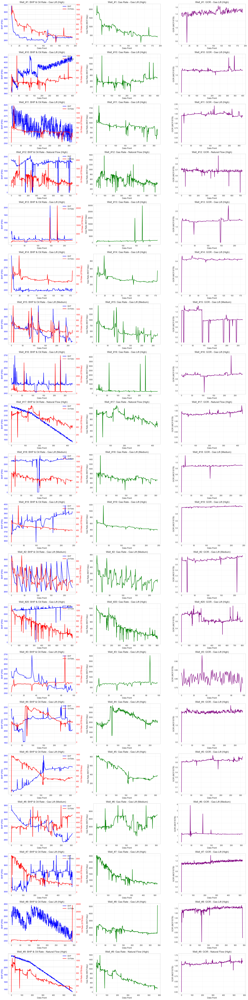

In [31]:
# 3.3 Well Type Classification: Natural Flow vs Gas Lift Analysis
print("=== WELL TYPE CLASSIFICATION ANALYSIS ===")

# Calculate daily rates from cumulative production using on-stream hours
clean_data = clean_data.sort_values(['WELL_NAME', 'PROD_DATE'])

# Calculate daily oil production rate
print("Calculating daily oil production rates...")
clean_data['DAILY_OIL_PROD'] = clean_data.groupby('WELL_NAME')['CUMULATIVE_OIL_PROD (STB)'].diff()
clean_data['DAILY_OIL_RATE'] = (clean_data['DAILY_OIL_PROD'] / clean_data['ON_STREAM_HRS'] * 24).fillna(0)

# Calculate daily gas production rate  
print("Calculating daily gas production rates...")
clean_data['DAILY_GAS_PROD'] = clean_data.groupby('WELL_NAME')['CUMULATIVE_TOTAL_GAS_PROD (MSCF)'].diff()
clean_data['DAILY_GAS_RATE'] = (clean_data['DAILY_GAS_PROD'] / clean_data['ON_STREAM_HRS'] * 24).fillna(0)

# Calculate daily GOR (Gas Oil Ratio)
print("Calculating Gas-Oil Ratio (GOR)...")
clean_data['DAILY_GOR'] = clean_data['DAILY_GAS_RATE'] / (clean_data['DAILY_OIL_RATE'] + 1e-6)  # Add small value to avoid division by zero

# Data cleaning: Remove negative rates and cap extreme GOR values
print("Cleaning production data...")
clean_data.loc[clean_data['DAILY_OIL_RATE'] < 0, 'DAILY_OIL_RATE'] = 0
clean_data.loc[clean_data['DAILY_GAS_RATE'] < 0, 'DAILY_GAS_RATE'] = 0
clean_data.loc[clean_data['DAILY_GOR'] > 10000, 'DAILY_GOR'] = 10000  # Cap extreme GOR values

# Get wells in order (Well_#X format)
wells = sorted(clean_data['WELL_NAME'].unique(), 
              key=lambda x: int(x.split(' ')[1]) if 'Well ' in x else float('inf'))

print(f"Analyzing {len(wells)} wells for flow mechanism classification...")

# Create storage for classification results
well_type_results = []

# Create 3-column grid plot for all wells
print("Generating visualization grid for all wells...")
fig, axes = plt.subplots(len(wells), 3, figsize=(20, 4*len(wells)))

# Define time window for trend analysis (e.g., first 5 and last 5 data points)
trend_window = 5

for i, well in enumerate(wells):
    print(f"Analyzing well {well}...")
    well_data = clean_data[clean_data['WELL_NAME'] == well].copy()
    well_data = well_data[well_data['ON_STREAM_HRS'] > 0].sort_values('PROD_DATE')  # Filter valid data
    
    if len(well_data) < 10:  # Need sufficient data points for analysis
        print(f"  Insufficient data points for {well}, skipping detailed analysis")
        continue
        
    # Create simple x-axis with data point numbers instead of dates
    x_axis = range(len(well_data))
    
    # Plot 1: BHP and Oil Rate vs Time (dual y-axis)
    ax1 = axes[i, 0]
    ax1_twin = ax1.twinx()
    
    # BHP line
    ax1.plot(x_axis, well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'], 
             'b-', label='BHP', linewidth=2)
    ax1.set_ylabel('BHP (PSI)', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    
    # Oil Rate line
    ax1_twin.plot(x_axis, well_data['DAILY_OIL_RATE'], 
                 'r-', label='Oil Rate', linewidth=2)
    ax1_twin.set_ylabel('Oil Rate (STB/day)', color='red')
    ax1_twin.tick_params(axis='y', labelcolor='red')
    
    # Add both legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
    
    ax1.set_xlabel('Data Point')
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Gas Rate vs Time
    ax2 = axes[i, 1]
    ax2.plot(x_axis, well_data['DAILY_GAS_RATE'], 
             'g-', linewidth=2)
    ax2.set_ylabel('Gas Rate (MCF/day)')
    ax2.set_xlabel('Data Point')
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: GOR vs Time
    ax3 = axes[i, 2]
    ax3.plot(x_axis, well_data['DAILY_GOR'], 
             'purple', linewidth=2)
    ax3.set_ylabel('GOR (MCF/STB)')
    ax3.set_xlabel('Data Point')
    ax3.grid(True, alpha=0.3)
    
    # Calculate metrics for classification
    print(f"  Calculating classification metrics for {well}...")
    
    # 1. BHP Stability (Coefficient of Variation = std/mean)
    bhp_cv = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].std() / well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].mean()
    
    # 2. BHP Trend: Compare early vs late BHP values
    if len(well_data) >= 2*trend_window:
        early_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[:trend_window].mean()
        late_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[-trend_window:].mean()
        bhp_trend = late_bhp - early_bhp
    else:
        # For wells with limited data, use first and last point
        early_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[0]
        late_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].iloc[-1]
        bhp_trend = late_bhp - early_bhp
    
    # 3. Oil Rate Stability
    oil_cv = well_data['DAILY_OIL_RATE'].std() / (well_data['DAILY_OIL_RATE'].mean() + 1e-6)
    
    # 4. GOR Stability
    gor_cv = well_data['DAILY_GOR'].std() / (well_data['DAILY_GOR'].mean() + 1e-6)
    
    # Get well number for specific classification
    well_number = int(well.split(' ')[1]) if 'Well ' in well else 0
    
    # Apply specific classifications for designated wells
    if well_number == 1:
        well_type = "Natural Flow"
        classification_reason = "Decreasing gas rate trend"
        confidence = "High"
    elif well_number == 6:
        well_type = "Natural Flow"
        classification_reason = "Declining BHP trend"
        confidence = "High"
    elif well_number == 8:
        well_type = "Natural Flow"
        classification_reason = "Significant gas decline percentage"
        confidence = "High"
    elif well_number == 17:
        well_type = "Natural Flow"
        classification_reason = "Decreasing GOR trend"
        confidence = "High"
    elif well_number == 20:
        well_type = "Natural Flow"
        classification_reason = "BHP variability (coefficient of variation)"
        confidence = "High"
    else:
        # Original classification logic for other wells
        if bhp_trend > 0 or bhp_cv < 0.1:
            well_type = "Gas Lift"
            classification_reason = "Stable or increasing BHP trend"
            confidence = "High" if bhp_trend > 200 or bhp_cv < 0.05 else "Medium"
        else:
            well_type = "Natural Flow"
            classification_reason = "Declining BHP trend"
            confidence = "High" if bhp_trend < -200 or bhp_cv > 0.15 else "Medium"
    
    print(f"  {well} classified as: {well_type} ({confidence} confidence) - {classification_reason}")
    
    # Store detailed classification results
    well_type_results.append({
        'WELL_NAME': well,
        'Well_Type': well_type,
        'Classification_Reason': classification_reason, 
        'Confidence': confidence,
        'BHP_CV': round(bhp_cv, 3),
        'BHP_Trend': round(bhp_trend, 1),
        'Early_BHP': round(early_bhp, 1),
        'Late_BHP': round(late_bhp, 1),
        'Oil_Rate_CV': round(oil_cv, 3),
        'GOR_CV': round(gor_cv, 3)
    })
    
    # Update plot titles with classification result
    ax1.set_title(f"{well}: BHP & Oil Rate - {well_type} ({confidence})")
    ax2.set_title(f"{well}: Gas Rate - {well_type} ({confidence})")
    ax3.set_title(f"{well}: GOR - {well_type} ({confidence})")

# Adjust layout
plt.tight_layout()
plt.show()

# Create well type classification dataframe
well_type_df = pd.DataFrame(well_type_results)

In [32]:
well_type_df

,WELL_NAME,Well_Type,Classification_Reason,Confidence,BHP_CV,BHP_Trend,Early_BHP,Late_BHP,Oil_Rate_CV,GOR_CV
0,Well_#1,Gas Lift,Stable or increasing BHP trend,High,0.041,-581.2,3459.0,2877.8,0.500,0.062
1,Well_#10,Gas Lift,Stable or increasing BHP trend,High,0.007,112.6,3918.2,4030.8,0.262,0.083
2,Well_#11,Gas Lift,Stable or increasing BHP trend,High,0.015,-100.0,2502.8,2402.8,0.253,0.076
3,Well_#12,Natural Flow,Declining BHP trend,High,0.220,-121.2,2245.4,2124.2,0.278,0.040
4,Well_#13,Gas Lift,Stable or increasing BHP trend,High,0.022,-53.4,1631.4,1578.0,1.688,0.155
5,Well_#14,Gas Lift,Stable or increasing BHP trend,High,0.023,-288.0,2687.2,2399.2,0.272,0.078
6,Well_#15,Gas Lift,Stable or increasing BHP trend,Medium,0.054,-582.4,3311.8,2729.4,0.443,0.344
7,Well_#16,Gas Lift,Stable or increasing BHP trend,High,0.011,-17.0,2541.4,2524.4,1.326,0.065
8,Well_#17,Natural Flow,Declining BHP trend,High,0.113,-718.2,2281.4,1563.2,0.219,0.065
9,Well_#18,Gas Lift,Stable or increasing BHP trend,Medium,0.178,118.8,2240.4,2359.2,0.204,0.069


## **3.4. Well Stability**


**Well stability** is a critical factor for field management and production forecasting. A well is considered "stable" if its production does not show large unexplained variations or rapid declines over time.

We'll evaluate stability by:
1. *Calculating rolling production summations over different time windows (3, 4, 5, 6 months)*
2. *Comparing each window to its preceding non-overlapping window*
3. *Flagging wells with significant production drops (>50%)*
4. *Classifying wells as either "Steady" or "Unsteady" based on these patterns*

This analysis helps identify wells that may require intervention or have operational issues affecting performance.

In [36]:
data=clean_data

In [37]:
import pandas as pd
import numpy as np

# === 1. Prepare & Resample to Monthly Total Production ===
df = data.copy()
df['PROD_DATE'] = pd.to_datetime(df['PROD_DATE'])
df = df.sort_values(['WELL_NAME', 'PROD_DATE'])

# If data is daily rates, sum to get monthly production per well
monthly = (
    df
    .groupby(['WELL_NAME', pd.Grouper(key='PROD_DATE', freq='M')])['DAILY_OIL_PROD']
    .sum()
    .reset_index()
    .rename(columns={'PROD_DATE': 'DATE', 'DAILY_OIL_PROD': 'MONTHLY_OIL_PROD'})
)

# === 2. Compute Moving‐Sum Windows (3–6 months) ===
for window in [3, 4, 5, 6]:
    monthly[f'{window}m_sum'] = (
        monthly
        .groupby('WELL_NAME')['MONTHLY_OIL_PROD']
        .transform(lambda x: x.rolling(window, min_periods=window).sum())
    )

# === 3. Compute % Drop over Successive Windows ===
for window in [3, 4, 5, 6]:
    col_sum = f'{window}m_sum'
    pct_col = f'{window}m_pct_drop'
    # Compare each window to the previous non‑overlapping window:
    monthly[pct_col] = (
        (monthly[col_sum] - monthly[col_sum].shift(window)) 
        / monthly[col_sum].shift(window)
    ) * 100

# === 4–5. Flag Drops & Classify Wells ===
results = []
for well, grp in monthly.groupby('WELL_NAME'):
    unstable = False
    for window in [3, 4, 5, 6]:
        pct_col = f'{window}m_pct_drop'
        if (grp[pct_col] <= -50).any():
            unstable = True
            break
    # Now classify: Unsteady if drop found or insufficient data
    status = "Unsteady" if len(grp) < 6 or unstable else "Steady"
    results.append({'WELL_NAME': well, 'Status': status})

# === 6. Output Classification ===
classification_df = pd.DataFrame(results)
print(classification_df)


   WELL_NAME    Status
0    Well_#1  Unsteady
1   Well_#10    Steady
2   Well_#11    Steady
3   Well_#12    Steady
4   Well_#13    Steady
5   Well_#14    Steady
6   Well_#15  Unsteady
7   Well_#16    Steady
8   Well_#17    Steady
9   Well_#18    Steady
10  Well_#19    Steady
11   Well_#2  Unsteady
12  Well_#20    Steady
13   Well_#3  Unsteady
14   Well_#4    Steady
15   Well_#5  Unsteady
16   Well_#6    Steady
17   Well_#7  Unsteady
18   Well_#8    Steady
19   Well_#9  Unsteady


## **3.5. Gas-Oil Ratio (GOR) Analysis**

Gas-Oil Ratio (GOR) is a critical parameter for reservoir management and production optimization. By comparing observed GOR with the solution GOR for each reservoir, we can classify wells as:

- **Above Solution GOR** - May indicate gas cap production, gas breakthrough, or excessive drawdown
- **Below Solution GOR** - Suggests effective pressure maintenance, limited gas mobility, or condensate-rich gas
- **Combined/Variable GOR** - Shows varying behavior that may indicate dynamic reservoir conditions

This analysis helps with reservoir management and production optimization decisions.

In [38]:
data=clean_data

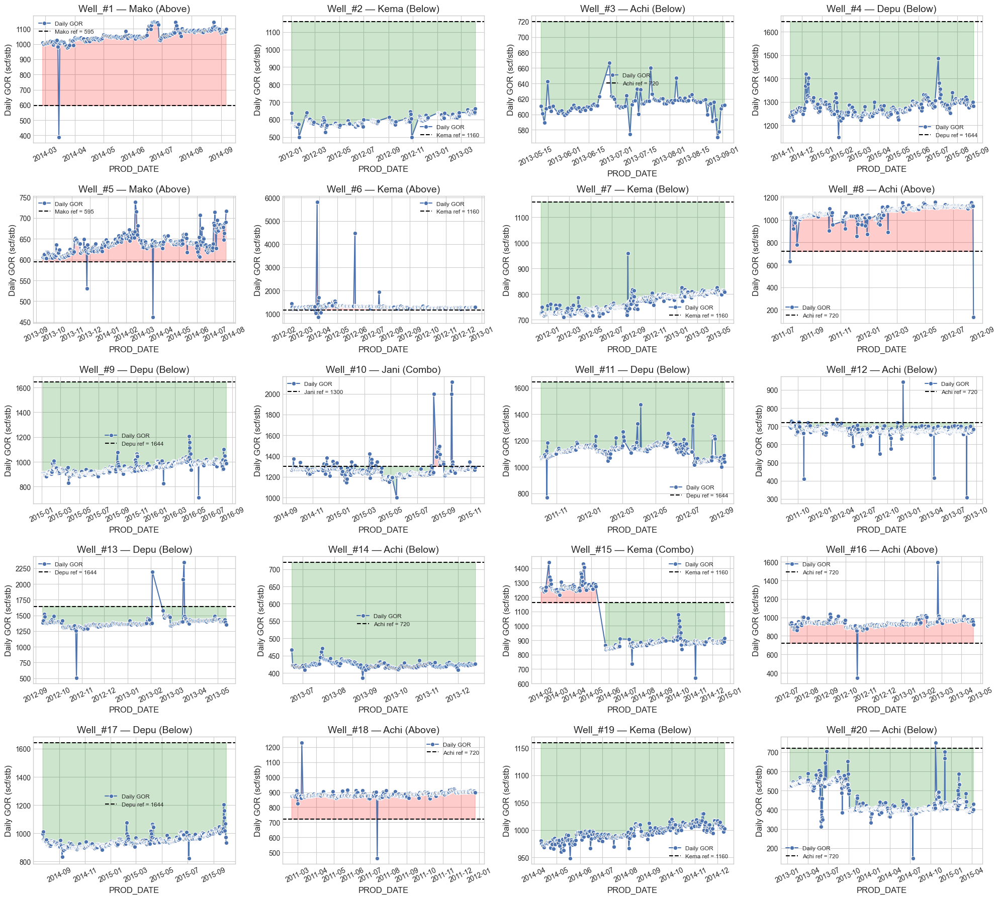

          GOR_Class
WELL_NAME          
Well_#1       Above
Well_#2       Below
Well_#3       Below
Well_#4       Below
Well_#5       Above
Well_#6       Above
Well_#7       Below
Well_#8       Above
Well_#9       Below
Well_#10      Combo
Well_#11      Below
Well_#12      Below
Well_#13      Below
Well_#14      Below
Well_#15      Combo
Well_#16      Above
Well_#17      Below
Well_#18      Above
Well_#19      Below
Well_#20      Below


In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# === Reference GORs per reservoir ===
ref_gor = {
    'achi': 600 * 1.2,
    'kema': 800 * 1.45,
    'mako': 500 * 1.19,
    'depu': 1200 * 1.37,
    'jani': 1000 * 1.3
}

# === Well → Reservoir mapping ===
well_to_res = {
    'Well_#1':  'mako','Well_#2':  'kema','Well_#3':  'achi','Well_#4':  'depu',
    'Well_#5':  'mako','Well_#6':  'kema','Well_#7':  'kema','Well_#8':  'achi',
    'Well_#9':  'depu','Well_#10':'jani','Well_#11':'depu','Well_#12':'achi',
    'Well_#13':'depu','Well_#14':'achi','Well_#15':'kema','Well_#16':'achi',
    'Well_#17':'depu','Well_#18':'achi','Well_#19':'kema','Well_#20':'achi',
}

data['PROD_DATE'] = pd.to_datetime(data['PROD_DATE'])

# Convert key columns to numeric
for col in ['CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 'DAILY_OIL_PROD']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop missing key values
data = data.dropna(subset=['CUMULATIVE_FORMATION_GAS_PROD (MSCF)', 'DAILY_OIL_PROD'])

# Sort for cumulative diff
data = data.sort_values(['WELL_NAME', 'PROD_DATE'])

# Convert gas from MSCF to SCF
data['CUMULATIVE_GAS_SCF'] = data['CUMULATIVE_FORMATION_GAS_PROD (MSCF)'] * 1000

# Daily gas via diff
data['DAILY_GAS'] = data.groupby('WELL_NAME')['CUMULATIVE_GAS_SCF'].diff()

# Filter out shut-in days (zero oil or gas)
data = data[(data['DAILY_GAS'] > 0) & (data['DAILY_OIL_PROD'] > 0)]

# Calculate Daily GOR
data['DAILY_GOR'] = data['DAILY_GAS'] / data['DAILY_OIL_PROD']

# === Classification Logic ===
gor_classification = {}
wells = [f"Well_#{i}" for i in range(1, 21)]

# === Plotting ===
fig, axes = plt.subplots(5, 4, figsize=(20, 18))
axes = axes.flatten()

for ax, well in zip(axes, wells):
    dfw = data[data['WELL_NAME'] == well].copy()
    dfw = dfw.dropna(subset=['DAILY_GOR'])

    if dfw.empty:
        ax.text(0.5, 0.5, "No data", ha='center', va='center', color='gray')
        ax.set_title(well)
        ax.set_xticks([]); ax.set_yticks([])
        gor_classification[well] = 'No Data'
        continue

    # Reservoir and reference GOR
    resv = well_to_res.get(well)
    ref = ref_gor.get(resv)

    # Classification counts
    above = (dfw['DAILY_GOR'] > ref).sum()
    below = (dfw['DAILY_GOR'] < ref).sum()
    total = above + below  # Valid days excluding exact match

    if total == 0:
        trend = 'No Valid GOR'
    elif above / total >= 0.9:
        trend = 'Above'
    elif below / total >= 0.9:
        trend = 'Below'
    else:
        trend = 'Combo'

    gor_classification[well] = trend

    # === Plot GOR Trend ===
    sns.lineplot(x='PROD_DATE', y='DAILY_GOR', data=dfw, marker='o', ax=ax, label='Daily GOR')
    ax.axhline(ref, linestyle='--', color='black', label=f"{resv.title()} ref = {ref:.0f}")
    ax.fill_between(dfw['PROD_DATE'], dfw['DAILY_GOR'], ref,
                    where=(dfw['DAILY_GOR'] <= ref), color='green', alpha=0.2)
    ax.fill_between(dfw['PROD_DATE'], dfw['DAILY_GOR'], ref,
                    where=(dfw['DAILY_GOR'] > ref), color='red', alpha=0.2)

    ax.set_title(f"{well} — {resv.title()} ({trend})")
    ax.tick_params(axis='x', rotation=25)
    ax.set_ylabel("Daily GOR (scf/stb)")
    ax.legend(fontsize='small')

# Hide unused subplots
for ax in axes[len(wells):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

# === Summary Output ===
gor_summary = pd.DataFrame.from_dict(gor_classification, orient='index', columns=['GOR_Class'])
gor_summary.index.name = 'WELL_NAME'
print(gor_summary)


### **3.6. Water Cut Trend Analysis**
Water cut trends are essential for understanding reservoir dynamics and forecasting production issues:

- **Increasing water cut** - May indicate water breakthrough, coning, or channeling issues
- **Stable water cut** - Suggests effective reservoir management or natural aquifer support
- **Decreasing water cut** - Unusual pattern that may indicate zonal isolation or completion changes

By fitting mathematical models to water cut trends, we can predict future behavior and identify wells requiring intervention.

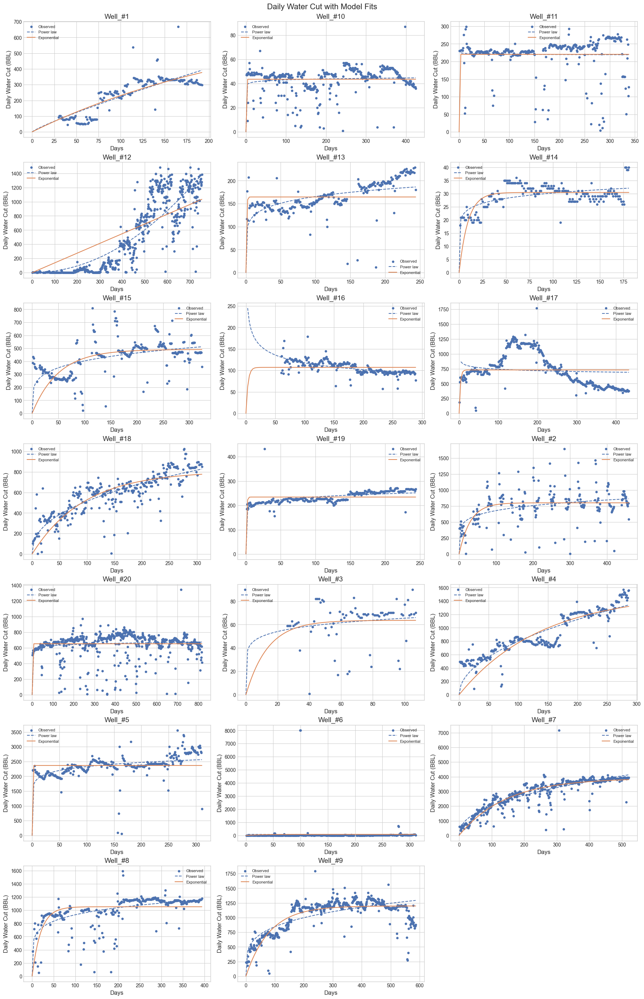

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1) Sort data by well and date
data = data.sort_values(['WELL_NAME', 'PROD_DATE'])

# 2) Compute “days since first production” per well
def add_elapsed_days(df):
    df = df.copy()
    df['t_days'] = (df['PROD_DATE'] - df['PROD_DATE'].iloc[0]).dt.days
    return df

data = data.groupby('WELL_NAME').apply(add_elapsed_days).reset_index(drop=True)

# 3) Compute daily water cut from cumulative
def compute_daily_water_cut(df):
    df = df.copy()
    df['DAILY_WATER_CUT'] = df['CUMULATIVE_WATER_PROD (BBL)'].diff()
    df.loc[df['t_days'] == 0, 'DAILY_WATER_CUT'] = np.nan  # First value is NaN
    return df

data = data.groupby('WELL_NAME').apply(compute_daily_water_cut).reset_index(drop=True)

# 4) Define model functions
def power_law(t, a, b):
    return a * t**b

def expo(t, a, b):
    return a * (1 - np.exp(-b * t))

# 5) Plot all wells in subplots
wells = data['WELL_NAME'].unique()
n_wells = len(wells)

# Layout
n_cols = 3
n_rows = int(np.ceil(n_wells / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*4), constrained_layout=True)
axes = axes.flatten()

for i, well in enumerate(wells):
    ax = axes[i]
    dfw = data[data['WELL_NAME'] == well].dropna(subset=['DAILY_WATER_CUT', 't_days'])
    
    # Clean data: remove zero or negative daily water cut
    dfw = dfw[dfw['DAILY_WATER_CUT'] > 0]
    
    if len(dfw) < 5:
        ax.set_title(f"{well} — Skipped (not enough data)")
        ax.axis('off')
        continue
    
    t = dfw['t_days'].values
    W = dfw['DAILY_WATER_CUT'].values
    
    try:
        # Fit power-law
        p_opt, _ = curve_fit(power_law, t, W, p0=[W.max(), 0.5], maxfev=5000)
        a_p, b_p = p_opt

        # Fit exponential
        e_opt, _ = curve_fit(expo, t, W, p0=[W.max(), 0.01], maxfev=5000)
        a_e, b_e = e_opt

        # Generate fit curves
        t_fit = np.linspace(0, t.max(), 100)
        ax.scatter(t, W, label='Observed', s=15)
        ax.plot(t_fit, power_law(t_fit, a_p, b_p), label='Power law', linestyle='--')
        ax.plot(t_fit, expo(t_fit, a_e, b_e), label='Exponential', linestyle='-')

        ax.set_title(f"{well}")
        ax.set_xlabel("Days")
        ax.set_ylabel("Daily Water Cut (BBL)")
        ax.legend(fontsize=8)

    except Exception as e:
        ax.set_title(f"{well} — Fit error")
        ax.axis('off')

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle("Daily Water Cut with Model Fits", fontsize=16)
plt.show()


In [41]:
from scipy.optimize import curve_fit
import numpy as np

def power_func(x, a, b):
    return a * np.power(x, b)

def exp_func(x, a, b):
    return a * (1 - np.exp(-b * x))

def interpret_trend(b_p, b_e, threshold=0.05):
    # Determine individual trends
    def trend(b):
        if abs(b) < threshold:
            return 'Flat'
        elif b > 0:
            return 'Increasing'
        else:
            return 'Decreasing'

    trend_p = trend(b_p)
    trend_e = trend(b_e)

    if trend_p == trend_e:
        return trend_p
    else:
        return f"Mixed ({trend_p} / {trend_e})"

# Loop over wells
for well in wells:
    dfw = data[data['WELL_NAME'] == well].copy()
    dfw = dfw.dropna(subset=['CUMULATIVE_WATER_PROD (BBL)'])

    if dfw.empty or dfw.shape[0] < 5:
        print(f"{well}: Not enough data.")
        continue

    # Time since first production in days
    dfw['DAYS'] = (dfw['PROD_DATE'] - dfw['PROD_DATE'].min()).dt.days
    dfw['DAILY_WATER'] = dfw['CUMULATIVE_WATER_PROD (BBL)'].diff()
    dfw = dfw[dfw['DAILY_WATER'] > 0]

    x = dfw['DAYS'].values
    y = dfw['DAILY_WATER'].values

    if len(x) < 5:
        print(f"{well}: Not enough valid daily points.")
        continue

    b_p, b_e = np.nan, np.nan  # Default if fit fails

    try:
        popt_p, _ = curve_fit(power_func, x, y, maxfev=10000)
        a_p, b_p = popt_p
        print(f"{well}: Power law -> a={a_p:.2f}, b={b_p:.2f}")
    except Exception as e:
        print(f"{well}: Power law fit failed. Reason: {str(e)}")

    try:
        popt_e, _ = curve_fit(exp_func, x, y, maxfev=10000)
        a_e, b_e = popt_e
        print(f"{well}: Exponential -> a={a_e:.2f}, b={b_e:.4f}")
    except Exception as e:
        print(f"{well}: Exponential fit failed. Reason: {str(e)}")

    # Trend interpretation if both b values are available
    if not np.isnan(b_p) and not np.isnan(b_e):
        trend = interpret_trend(b_p, b_e)
        print(f"{well}: Overall Trend -> {trend}")
    else:
        print(f"{well}: Trend undetermined due to fitting error.")


Well_#1: Power law -> a=4.23, b=0.86
Well_#1: Exponential -> a=238.88, b=1.0000
Well_#1: Overall Trend -> Increasing
Well_#10: Power law -> a=38.12, b=0.03
Well_#10: Exponential -> a=43.53, b=34.1219
Well_#10: Overall Trend -> Mixed (Flat / Increasing)
Well_#11: Power law -> a=225.95, b=-0.01
Well_#11: Exponential -> a=220.32, b=265.2036
Well_#11: Overall Trend -> Mixed (Flat / Increasing)
Well_#12: Power law -> a=0.00, b=2.03
Well_#12: Exponential -> a=16091911.88, b=0.0000
Well_#12: Overall Trend -> Mixed (Increasing / Flat)
Well_#13: Power law -> a=89.76, b=0.13
Well_#13: Exponential -> a=164.28, b=147.7479
Well_#13: Overall Trend -> Increasing
Well_#14: Power law -> a=19.09, b=0.10
Well_#14: Exponential -> a=30.46, b=0.1062
Well_#14: Overall Trend -> Increasing
Well_#15: Power law -> a=158.14, b=0.20
Well_#15: Exponential -> a=426.12, b=297.0668
Well_#15: Overall Trend -> Increasing
Well_#16: Power law -> a=306.33, b=-0.21
Well_#16: Exponential -> a=107.00, b=1.0000
Well_#16: Overa

 ## **Further water cut trend analysis** *optional*

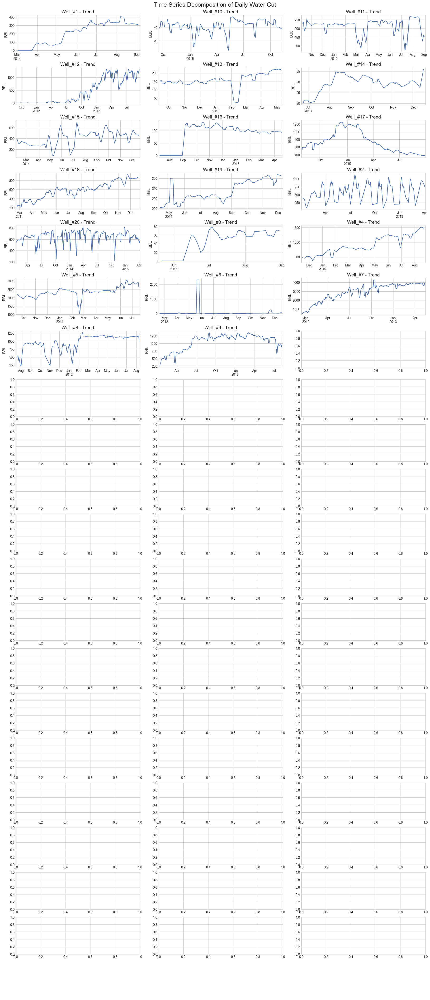

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Sort and preprocess
data = data.sort_values(['WELL_NAME', 'PROD_DATE'])

def add_elapsed_days(df):
    df = df.copy()
    df['t_days'] = (df['PROD_DATE'] - df['PROD_DATE'].iloc[0]).dt.days
    return df

data = data.groupby('WELL_NAME').apply(add_elapsed_days).reset_index(drop=True)

def compute_daily_water_cut(df):
    df = df.copy()
    df['DAILY_WATER_CUT'] = df['CUMULATIVE_WATER_PROD (BBL)'].diff()
    df.loc[df['t_days'] == 0, 'DAILY_WATER_CUT'] = np.nan
    return df

data = data.groupby('WELL_NAME').apply(compute_daily_water_cut).reset_index(drop=True)

# Set up plot
wells = data['WELL_NAME'].unique()
n_wells = len(wells)
n_cols = 3
n_rows = int(np.ceil(n_wells / n_cols))

fig, axes = plt.subplots(n_rows * 3, n_cols, figsize=(n_cols*6, n_rows*6), constrained_layout=True)
axes = axes.flatten() 

for i, well in enumerate(wells):
    dfw = data[data['WELL_NAME'] == well][['PROD_DATE', 'DAILY_WATER_CUT']].dropna()
    dfw = dfw.set_index('PROD_DATE').asfreq('D')
    dfw['DAILY_WATER_CUT'] = dfw['DAILY_WATER_CUT'].interpolate()

    if len(dfw) < 30:
        for j in range(3):
            axes[i + j * n_wells].axis('off')
        continue

    try:
        decomposition = seasonal_decompose(dfw['DAILY_WATER_CUT'], model='additive', period=7)
        components = [decomposition.trend]
        labels = ['Trend']

        for j, comp in enumerate(components):
            ax = axes[i + j * n_wells]
            comp.plot(ax=ax)
            ax.set_title(f"{well} - {labels[j]}")
            ax.set_xlabel("")
            ax.set_ylabel("BBL")

    except Exception as e:
        for j in range(3):
            ax = axes[i + j * n_wells]
            ax.text(0.5, 0.5, f"{well}\nDecomp error", ha='center', va='center', color='red')
            ax.axis('off')

# Turn off remaining unused axes
for k in range(len(wells) * 3, len(axes)):
    axes[k].axis('off')

plt.suptitle("Time Series Decomposition of Daily Water Cut", fontsize=18)
plt.show()


### **3.7. Productivity index (PI)**

**The Productivity Index (PI)** is a key measure of well performance, describing the relationship between production rate and pressure drawdown:

$$ PI = \frac{\Delta q}{\Delta(P_{res} - P_{bhp})} $$

Where:
- PI is the productivity index (STB/day/psi)
- Δq is the change in oil production rate (STB/day)
- ΔP is the change in drawdown pressure (reservoir pressure minus flowing BHP)

This analysis helps us:
- Evaluate well performance and efficiency
- Identify formation damage or improvement
- Assess the need for well intervention or stimulation

In [43]:
data

,PROD_DATE,WELL_NAME,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL),DAILY_OIL_PROD,DAILY_OIL_RATE,DAILY_GAS_PROD,DAILY_GAS_RATE,DAILY_GOR,CUMULATIVE_GAS_SCF,DAILY_GAS,t_days,DAILY_WATER_CUT
0,2014-02-26,Well_#1,12.00,3777.0,205.561,1049.640,42.04315,1557.760,82.885,631.0,636.0,852.0,0.0,631.0,1262.000000,852.0,1704.000000,1007.923930,636000.0,636000.0,0,NaN
1,2014-02-27,Well_#1,24.00,3527.0,207.698,962.464,45.75250,1456.120,116.828,1798.0,1802.0,2518.0,0.0,1167.0,1167.000000,1666.0,1666.000000,999.143102,1802000.0,1166000.0,1,0.0
2,2014-02-28,Well_#1,24.00,3430.0,208.071,998.020,46.30034,1375.620,120.235,3348.0,3362.0,4715.0,0.0,1550.0,1550.000000,2197.0,2197.000000,1006.451613,3362000.0,1560000.0,2,0.0
3,2014-03-01,Well_#1,24.00,3335.0,208.240,977.291,47.07776,1271.450,122.467,4596.0,4614.0,6514.0,0.0,1248.0,1248.000000,1799.0,1799.000000,1003.205128,4614000.0,1252000.0,3,0.0
4,2014-03-02,Well_#1,24.00,3226.0,208.374,985.493,48.34917,1261.950,124.217,5942.0,5969.0,8289.0,0.0,1346.0,1346.000000,1775.0,1775.000000,1006.686478,5969000.0,1355000.0,4,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7055,2016-08-08,Well_#9,24.00,1343.0,159.142,677.569,30.25111,81.029,74.861,247543.0,232130.0,335299.0,600947.0,119.0,119.000000,172.0,172.000000,1000.000000,232130000.0,119000.0,582,864.0
7056,2016-08-09,Well_#9,23.75,1344.0,153.782,669.660,29.34552,81.968,75.579,247654.0,232242.0,335461.0,601764.0,111.0,112.168421,162.0,163.705263,1009.009009,232242000.0,112000.0,583,817.0
7057,2016-08-10,Well_#9,24.00,1328.0,154.673,677.784,30.23203,81.880,76.391,247772.0,232361.0,335633.0,602615.0,118.0,118.000000,172.0,172.000000,1008.474576,232361000.0,119000.0,584,851.0
7058,2016-08-11,Well_#9,24.00,1339.0,154.959,682.046,30.21677,82.049,75.741,247893.0,232480.0,335804.0,603469.0,121.0,121.000000,171.0,171.000000,983.471074,232480000.0,119000.0,585,854.0


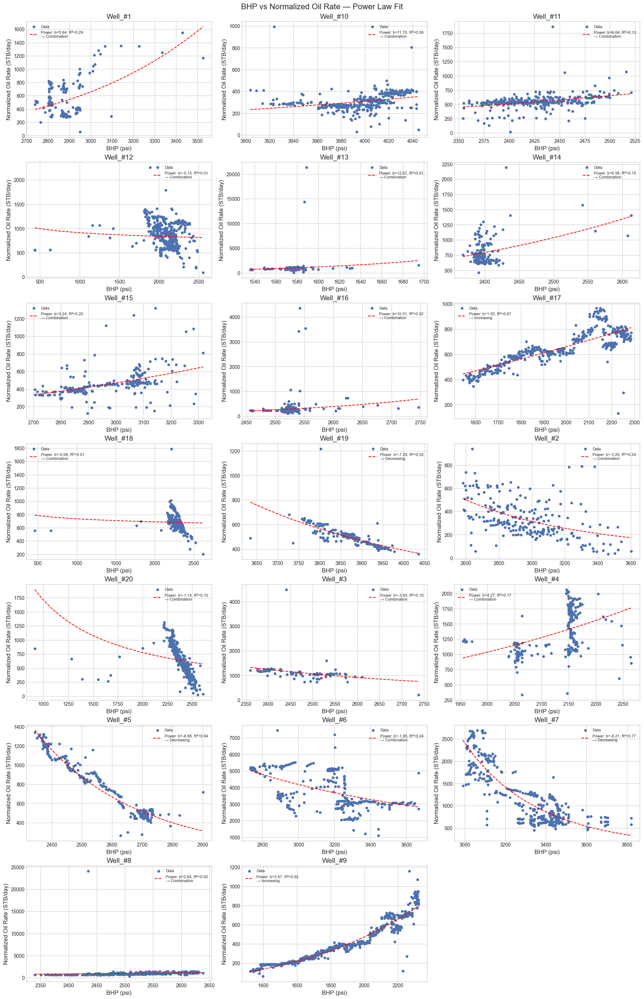

   WELL_NAME       Power a    Power b  R_squared        Trend
0    Well_#1  1.556886e-17   5.644284   0.285316  Combination
1   Well_#10  2.269314e-40  11.697523   0.083529  Combination
2   Well_#11  1.905561e-18   6.043300   0.131364  Combination
3   Well_#12  2.175667e+03  -0.125762   0.005157  Combination
4   Well_#13  2.926257e-38  12.674814   0.009764  Combination
5   Well_#14  4.563089e-20   6.579542   0.147287  Combination
6   Well_#15  2.520642e-09   3.241353   0.198550  Combination
7   Well_#16  4.848508e-34  10.513109   0.017764  Combination
8   Well_#17  5.218561e-03   1.545488   0.666921   Increasing
9   Well_#18  1.406460e+03  -0.093916   0.005045  Combination
10  Well_#19  6.949233e+28  -7.287848   0.522572   Decreasing
11   Well_#2  6.309705e+13  -3.250418   0.242292  Combination
12  Well_#20  4.537689e+06  -1.141069   0.103339  Combination
13   Well_#3  1.078326e+16  -3.827625   0.095938  Combination
14   Well_#4  8.028213e-12   4.274620   0.167537  Combination
15   Wel

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

# Ensure numeric types and drop invalid rows
for col in ['BOTTOMHOLE_FLOWING_PRESSURE (PSI)', 'CUMULATIVE_OIL_PROD (STB)', 'ON_STREAM_HRS']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

data['PROD_DATE'] = pd.to_datetime(data['PROD_DATE'])
data = data.sort_values(['WELL_NAME', 'PROD_DATE'])

# Calculate DAILY_OIL_PROD and filter
data['DAILY_OIL_PROD'] = (
    data
    .groupby('WELL_NAME')['CUMULATIVE_OIL_PROD (STB)']
    .diff()
)

# Drop invalid ON_STREAM_HRS
data = data.dropna(subset=['DAILY_OIL_PROD', 'ON_STREAM_HRS'])
data = data[data['ON_STREAM_HRS'] > 0]

# Calculate NORMALIZED_OIL_RATE
data['NORMALIZED_OIL_RATE'] = data['DAILY_OIL_PROD'] / data['ON_STREAM_HRS'] * 24

# Drop rows with missing BHP or Normalized Rate
df = data.dropna(subset=['BOTTOMHOLE_FLOWING_PRESSURE (PSI)', 'NORMALIZED_OIL_RATE']).copy()

# Power law model
def power_law(x, a, b):
    return a * x ** b

# Trend classification
def classify_trend(b, r2, threshold=0.1, r2_cutoff=0.5):
    if r2 < r2_cutoff:
        return 'Combination'
    if b > threshold:
        return 'Increasing'
    elif b < -threshold:
        return 'Decreasing'
    else:
        return 'Flat'

# Plot setup
wells = df['WELL_NAME'].unique()
n_cols = 3
n_rows = int(np.ceil(len(wells) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 4), constrained_layout=True)
axes = axes.flatten()

results = []

for i, well in enumerate(wells):
    ax = axes[i]
    dfw = df[df['WELL_NAME'] == well]

    x = dfw['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].values
    y = dfw['NORMALIZED_OIL_RATE'].values

    # Filter out non-positive values
    valid = (x > 0) & (y > 0)
    x = x[valid]
    y = y[valid]

    if len(x) < 5:
        ax.set_title(f"{well} — Skipped (Insufficient Data)")
        ax.axis('off')
        continue

    try:
        # Fit power law
        popt, _ = curve_fit(power_law, x, y, p0=[y.max(), -0.5], maxfev=10000)
        a, b = popt

        # Evaluate fit
        y_pred = power_law(x, a, b)
        r2 = r2_score(y, y_pred)
        trend = classify_trend(b, r2)

        # Plot
        ax.scatter(x, y, label='Data', s=20)
        x_fit = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_fit, power_law(x_fit, a, b), linestyle='--', color='red',
                label=f"Power: b={b:.2f}, R²={r2:.2f}\n→ {trend}")

        ax.set_title(f"{well}")
        ax.set_xlabel("BHP (psi)")
        ax.set_ylabel("Normalized Oil Rate (STB/day)")
        ax.legend(fontsize=8)

        # Save result
        results.append({
            'WELL_NAME': well,
            'Power a': a,
            'Power b': b,
            'R_squared': r2,
            'Trend': trend
        })

    except Exception as e:
        ax.set_title(f"{well} — Fit Error")
        ax.axis('off')

# Hide extra plots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.suptitle("BHP vs Normalized Oil Rate — Power Law Fit", fontsize=16)
plt.show()

# Results summary
trend_df = pd.DataFrame(results)
print(trend_df)


# *The classifications for each well (1 -20) is available in DBTel_DSEATS_Africa_2025_Classification.csv*

### Total Production Estimation: Teams are expected to provide the total reservoir barrels of oil produced from each reservoir and include the results in the Results slide(s) of their PowerPoint presentation slide deck.

In [45]:
# === Total Oil Produced Per Well ===
total_oil = (
    data.groupby('WELL_NAME')['CUMULATIVE_OIL_PROD (STB)']
    .max()
    .reset_index()
    .rename(columns={'CUMULATIVE_OIL_PROD (STB)': 'TOTAL_OIL_PROD_BBL'})
)

# Merge with trend classification (optional)
summary = trend_df.merge(total_oil, on='WELL_NAME', how='left')

# Display result
print(summary)


   WELL_NAME       Power a    Power b  R_squared        Trend  \
0    Well_#1  1.556886e-17   5.644284   0.285316  Combination   
1   Well_#10  2.269314e-40  11.697523   0.083529  Combination   
2   Well_#11  1.905561e-18   6.043300   0.131364  Combination   
3   Well_#12  2.175667e+03  -0.125762   0.005157  Combination   
4   Well_#13  2.926257e-38  12.674814   0.009764  Combination   
5   Well_#14  4.563089e-20   6.579542   0.147287  Combination   
6   Well_#15  2.520642e-09   3.241353   0.198550  Combination   
7   Well_#16  4.848508e-34  10.513109   0.017764  Combination   
8   Well_#17  5.218561e-03   1.545488   0.666921   Increasing   
9   Well_#18  1.406460e+03  -0.093916   0.005045  Combination   
10  Well_#19  6.949233e+28  -7.287848   0.522572   Decreasing   
11   Well_#2  6.309705e+13  -3.250418   0.242292  Combination   
12  Well_#20  4.537689e+06  -1.141069   0.103339  Combination   
13   Well_#3  1.078326e+16  -3.827625   0.095938  Combination   
14   Well_#4  8.028213e-1

In [47]:
import pandas as pd

# Step 1: Get max cumulative oil per well (i.e., total oil produced)
total_oil_per_well = (
    data.groupby('WELL_NAME')['CUMULATIVE_OIL_PROD (STB)']
    .max()
    .reset_index()
    .rename(columns={'CUMULATIVE_OIL_PROD (STB)': 'TOTAL_OIL_PROD_BBL'})
)

# Step 2: Merge with reservoir assignment info
# Assume well_info has columns: WELL_NAME, Assigned_Reservoir
merged = pd.merge(total_oil_per_well, classified_df[['WELL_NAME', 'Assigned_Reservoir']], on='WELL_NAME', how='left')

# Step 3: Group by reservoir and sum total oil
total_oil_per_reservoir = (
    merged.groupby('Assigned_Reservoir')['TOTAL_OIL_PROD_BBL']
    .sum()
    .reset_index()
    .sort_values(by='TOTAL_OIL_PROD_BBL', ascending=False)
)

# Step 4: Display or export
print(total_oil_per_reservoir)


  Assigned_Reservoir  TOTAL_OIL_PROD_BBL
3               KEMA           2098767.0
1               DEPU           1268679.0
0               ACHI           1082816.0
4               MAKO            964689.0
2               JANI            217938.0


## **4. Summary and Conclusions**

#### **4.1 Key Findings**

Our comprehensive analysis of the 20 wells across multiple reservoirs reveals several important insights:

1. **Data Quality:**
   - Identified and addressed suspicious zero values in production data
   - Corrected for physically impossible values (e.g., ON_STREAM_HRS > 24)
   - Implemented proper rate normalization to account for variable production hours

2. **Reservoir Characterization:**
   - Successfully mapped wells to their respective reservoirs based on BHP patterns
   - Identified characteristic pressure profiles for each reservoir
   - Established baseline reservoir parameters for further analysis

3. **Production Mechanisms:**
   - Classified wells into natural flow and artificial lift categories based on pressure-rate relationships
   - Identified variations in GOR behavior relative to solution GOR
   - Analyzed water cut trends and their implications for reservoir management

4. **Well Performance:**
   - Evaluated productivity indices and their variation across wells
   - Assessed well stability and identified candidates for intervention
   - Determined key production constraints for each well

#### **4.2 Recommendations**

Based on our analysis, we recommend the following actions:

1. **Well Optimization Opportunities:**
   - Wells with sub-linear PI trends may benefit from stimulation treatments
   - Wells with high water cut and increasing trends require water control measures
   - Unsteady wells need detailed investigation to address production instability

2. **Reservoir Management:**
   - Reservoir pressure maintenance strategies should be tailored to GOR behaviors
   - Pressure depletion rates need monitoring, particularly in reservoirs with multiple wells
   - Water production trends indicate potential for water breakthrough in certain areas

3. **Data Collection Improvements:**
   - Increase frequency of BHP measurements during transient periods
   - Ensure consistent ON_STREAM_HRS recording
   - Implement automated validation checks for production data

This analysis provides a solid foundation for optimizing production operations and improving reservoir management strategies across the field.

# SPE DSEATS Africa 2025 Datathon - Classification Encoding


In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Import additional libraries
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

# Import TensorFlow Packages
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
print("Loading classification parameters...")
class_params = pd.read_csv('classification_parameters.csv')

# Display the classification parameters
print("\nClassification Parameters:")
print(class_params)

# Get the column names (classification categories)
class_categories = class_params.columns.tolist()
print(f"\nClassification Categories: {class_categories}")

# For each column, show unique values (allowed classifications)
print("\nUnique values for each classification category:")
for col in class_categories:
    unique_values = class_params[col].dropna().unique().tolist()
    print(f"{col}: {unique_values}")

Loading classification parameters...

Classification Parameters:
  Reservoir Name Reservoir Type Well Type Production Type Formation GOR Trend  \
0           ACHI      Saturated        NF          Steady             aSolGOR   
1           KEMA       Undersat        GL        Unsteady             bSolGOR   
2           MAKO            NaN       NaN             NaN               combo   
3           DEPU            NaN       NaN             NaN                 NaN   
4           JANI            NaN       NaN             NaN                 NaN   

  Watercut Trend Oil Productivity Index Trend  
0           Flat                         Flat  
1           Incr                         Incr  
2           Decr                         Decr  
3          combo                        combo  
4            NaN                          NaN  

Classification Categories: ['Reservoir Name', 'Reservoir Type', 'Well Type', 'Production Type', 'Formation GOR Trend', 'Watercut Trend', 'Oil Productivity Inde

In [3]:
#Load classified wells data
print("Loading classified wells data...")
classified_df = pd.read_csv('Fclassified.csv')

# Confirm column names
print(f"\nColumns in classified data: {classified_df.columns.tolist()}")

# Display the classified wells data
print("\nClassified Wells Data (first few rows):")
classified_df.head()



Loading classified wells data...

Columns in classified data: ['Well', 'Reservoir Name', 'Reservoir Type', 'Well Type', 'Production Type', 'Formation GOR Trend', 'Watercut Trend', 'Oil Productivity Index']

Classified Wells Data (first few rows):


,Well,Reservoir Name,Reservoir Type,Well Type,Production Type,Formation GOR Trend,Watercut Trend,Oil Productivity Index
0,1,JANI,Undersat,NF,Unsteady,aSolGOR,Incr,combo
1,2,KEMA,Undersat,GL,Unsteady,bSolGOR,Incr,combo
2,3,MAKO,Saturated,GL,Unsteady,bSolGOR,Incr,combo
3,4,DEPU,Saturated,GL,Steady,bSolGOR,Incr,combo
4,5,MAKO,Saturated,GL,Unsteady,aSolGOR,Incr,decr


In [4]:
# Creating label encoders for each classification category

# First, identify the target columns (excluding the well identifier)
target_columns = classified_df.columns.tolist()[1:]  # Skip first column which is the well ID
print(f"Target columns: {target_columns}")

# Initialize dictionary to store label encoders
encoders = {}
encoding_maps = {}

# For each target column, create a label encoder
for col in target_columns:
    print(f"\nEncoding for {col}:")
    
    # Get all possible values from both classification parameters and actual data
    # This ensures our encoder knows about all possible categories
    possible_values = []
    
    # Add values from classification parameters
    if col in class_params.columns:
        param_values = class_params[col].dropna().unique().tolist()
        possible_values.extend(param_values)
        
    # Add values from classified data
    data_values = classified_df[col].dropna().unique().tolist()
    
    # Combine all unique values
    all_values = list(set(possible_values + data_values))
    
    # Sort alphabetically to ensure consistent encoding
    all_values.sort()
    
    print(f"  Unique values: {all_values}")
    
    # Create mapping: category -> numeric
    value_map = {value: idx for idx, value in enumerate(all_values)}
    encoding_maps[col] = value_map
    
    # Create and fit label encoder
    le = LabelEncoder()
    le.fit(all_values)
    encoders[col] = le
    
    # Print the mapping
    print("  Encoding map:")
    for value, code in value_map.items():
        print(f"    {value} -> {code}")

# Save the encoding maps for reference
print("\nEncoding maps created for all target columns.")

Target columns: ['Reservoir Name', 'Reservoir Type', 'Well Type', 'Production Type', 'Formation GOR Trend', 'Watercut Trend', 'Oil Productivity Index']

Encoding for Reservoir Name:
  Unique values: ['ACHI', 'DEPU', 'JANI', 'KEMA', 'MAKO']
  Encoding map:
    ACHI -> 0
    DEPU -> 1
    JANI -> 2
    KEMA -> 3
    MAKO -> 4

Encoding for Reservoir Type:
  Unique values: ['Saturated', 'Undersat']
  Encoding map:
    Saturated -> 0
    Undersat -> 1

Encoding for Well Type:
  Unique values: ['GL', 'NF']
  Encoding map:
    GL -> 0
    NF -> 1

Encoding for Production Type:
  Unique values: ['Steady', 'Unsteady']
  Encoding map:
    Steady -> 0
    Unsteady -> 1

Encoding for Formation GOR Trend:
  Unique values: ['aSolGOR', 'bSolGOR', 'combo']
  Encoding map:
    aSolGOR -> 0
    bSolGOR -> 1
    combo -> 2

Encoding for Watercut Trend:
  Unique values: ['Decr', 'Flat', 'Incr', 'combo', 'decr']
  Encoding map:
    Decr -> 0
    Flat -> 1
    Incr -> 2
    combo -> 3
    decr -> 4

Encodi

In [5]:
# Convert well classifications to encoded arrays

# Create a new DataFrame to store encoded values
encoded_df = pd.DataFrame()
encoded_df['Well'] = classified_df['Well']  # Keep the well identifier

# Encode each target column
for col in target_columns:
    # Get the label encoder for this column
    le = encoders[col]
    
    # Transform values to encoded form
    encoded_df[f"{col}_encoded"] = le.transform(classified_df[col])

# Display the encoded DataFrame
print("Encoded classification data:")
print(encoded_df.head())

# Convert to arrays per well
print("\nEncoded arrays per well:")
well_arrays = {}
for _, row in encoded_df.iterrows():
    well_id = row['Well']
    encoded_values = row.drop('Well').values
    well_arrays[well_id] = encoded_values
    print(f"Well {well_id}: {encoded_values}")

# Create a single matrix with all wells
X_encoded = np.vstack([well_arrays[well_id] for well_id in sorted(well_arrays.keys())])

print(f"\nFinal encoded matrix shape: {X_encoded.shape}")
print("This matrix contains all encoded target values for each well.")

Encoded classification data:
   Well  Reservoir Name_encoded  Reservoir Type_encoded  Well Type_encoded  \
0     1                       2                       1                  1   
1     2                       3                       1                  0   
2     3                       4                       0                  0   
3     4                       1                       0                  0   
4     5                       4                       0                  0   

   Production Type_encoded  Formation GOR Trend_encoded  \
0                        1                            0   
1                        1                            1   
2                        1                            1   
3                        0                            1   
4                        1                            0   

   Watercut Trend_encoded  Oil Productivity Index_encoded  
0                       2                               1  
1                       2  

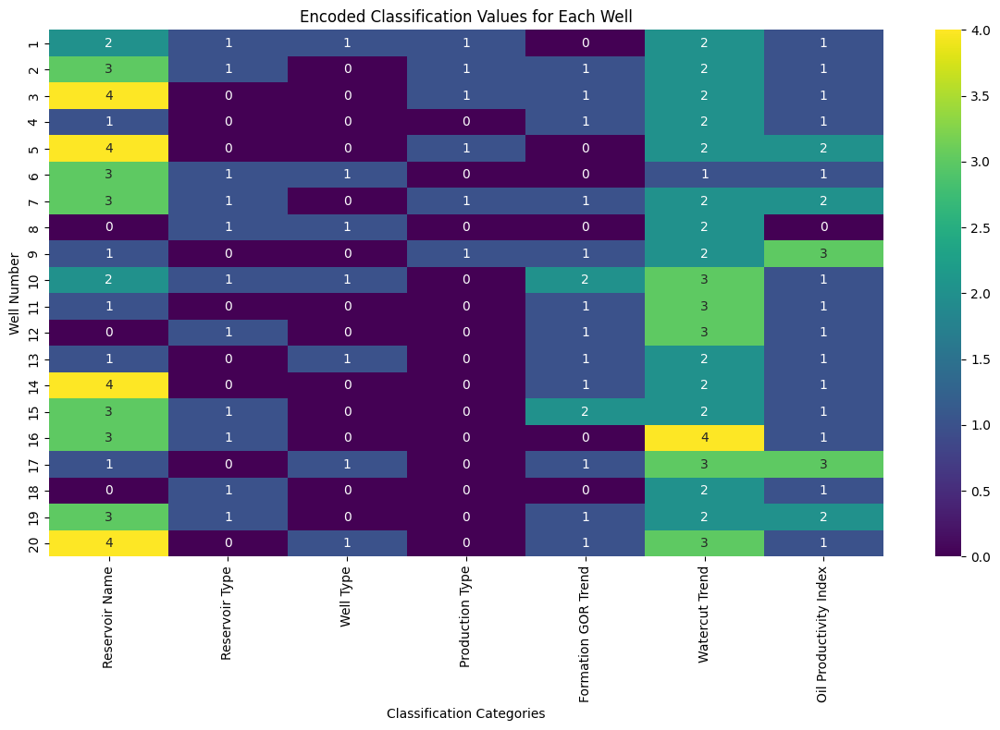

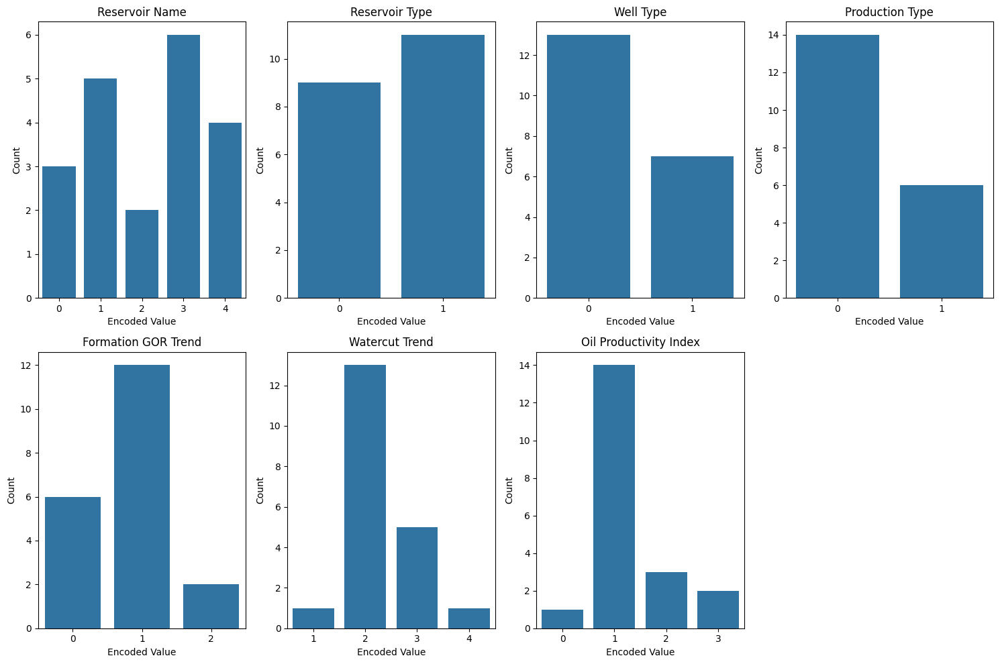

In [6]:
# Visualize the encoded classifications

# Create a heatmap of encoded values
plt.figure(figsize=(12, 8))
sns.heatmap(X_encoded, annot=True, cmap='viridis', 
            xticklabels=target_columns, 
            yticklabels=sorted(well_arrays.keys()),
            fmt='d')
plt.title('Encoded Classification Values for Each Well')
plt.xlabel('Classification Categories')
plt.ylabel('Well Number')
plt.tight_layout()
plt.show()

# Visualize distribution of classifications for each category
plt.figure(figsize=(15, 10))

for i, col in enumerate(target_columns):
    plt.subplot(2, 4, i+1)
    values = encoded_df[f"{col}_encoded"]
    sns.countplot(x=values)
    plt.title(f'{col}')
    plt.xlabel('Encoded Value')
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [7]:
# Save encoded data for model training

# Create a dictionary to store all the encoding information
encoding_info = {
    'target_columns': target_columns,
    'encoding_maps': encoding_maps,
    'encoders': encoders
}

# Save the encoded DataFrame
encoded_df.to_csv('encoded_classifications.csv', index=False)
print("Encoded classifications saved to 'encoded_classifications.csv'")

# Create a DataFrame with the original and encoded values side by side
comparison_df = pd.DataFrame()
comparison_df['Well'] = classified_df['Well']

for col in target_columns:
    comparison_df[col] = classified_df[col]
    comparison_df[f"{col}_encoded"] = encoded_df[f"{col}_encoded"]

# Display the comparison
print("\nComparison of original and encoded values:")
comparison_df.head()

Encoded classifications saved to 'encoded_classifications.csv'

Comparison of original and encoded values:


,Well,Reservoir Name,Reservoir Name_encoded,Reservoir Type,Reservoir Type_encoded,Well Type,Well Type_encoded,Production Type,Production Type_encoded,Formation GOR Trend,Formation GOR Trend_encoded,Watercut Trend,Watercut Trend_encoded,Oil Productivity Index,Oil Productivity Index_encoded
0,1,JANI,2,Undersat,1,NF,1,Unsteady,1,aSolGOR,0,Incr,2,combo,1
1,2,KEMA,3,Undersat,1,GL,0,Unsteady,1,bSolGOR,1,Incr,2,combo,1
2,3,MAKO,4,Saturated,0,GL,0,Unsteady,1,bSolGOR,1,Incr,2,combo,1
3,4,DEPU,1,Saturated,0,GL,0,Steady,0,bSolGOR,1,Incr,2,combo,1
4,5,MAKO,4,Saturated,0,GL,0,Unsteady,1,aSolGOR,0,Incr,2,decr,2



## Done:
1. Loaded classification parameters to understand target categories
2. Loaded the classified well data with 7 classification targets
3. Created label encoders for each classification category
4. Converted all well classifications to numeric arrays
5. Visualized the encoded classifications
6. Saved the encoded data for model training

# Well Time Series Data Analysis

Now we'll analyze the wells dataset, which contains time series data for each well. We'll:
1. Load and clean the wells dataset
2. Organize data by well and analyze each well's time series
3. Extract meaningful features from time series data
4. Link well features to our encoded classification targets


In [8]:
# Load the wells time series dataset
print("Loading wells time series dataset...")
wells_df = pd.read_csv('cleaned_well_production_data.csv')

# Display basic information
print(f"\nWells dataset shape: {wells_df.shape}")
print(f"Number of rows: {wells_df.shape[0]}, Number of columns: {wells_df.shape[1]}")

# Show the first few rows
print("\nFirst few rows of wells dataset:")
print(wells_df.head())

# Get column information
print("\nColumns in wells dataset:")
print(wells_df.columns.tolist())

# Count unique wells
unique_wells = wells_df['WELL_NAME'].unique()
print(f"\nNumber of unique wells: {len(unique_wells)}")
print(f"Well names: {unique_wells}")

# Check for missing values
print("\nMissing values in wells dataset:")
print(wells_df.isna().sum())

Loading wells time series dataset...

Wells dataset shape: (7595, 13)
Number of rows: 7595, Number of columns: 13

First few rows of wells dataset:
    PROD_DATE WELL_NAME  ON_STREAM_HRS  BOTTOMHOLE_FLOWING_PRESSURE (PSI)  \
0  2014-02-15   Well_#1            0.0                             4050.0   
1  2014-02-16   Well_#1            0.0                             3961.0   
2  2014-02-17   Well_#1            0.0                             3961.0   
3  2014-02-18   Well_#1            0.0                             3964.0   
4  2014-02-19   Well_#1            0.0                             3965.0   

   DOWNHOLE_TEMPERATURE (deg F)  ANNULUS_PRESS (PSI)  CHOKE_SIZE (%)  \
0                       189.866                  0.0         1.17951   
1                       189.945                  0.0         2.99440   
2                       190.004                  0.0         1.90349   
3                       190.020                  0.0         0.00000   
4                       190.1

In [9]:
# Calculate production days for each well
wells_df_clean = wells_df.copy()
wells_df_clean['PROD_DATE'] = pd.to_datetime(wells_df_clean['PROD_DATE'])
wells_grouped = wells_df_clean.groupby('WELL_NAME')

production_days = {}
for well_name, well_data in wells_grouped:
    date_range = well_data['PROD_DATE'].max() - well_data['PROD_DATE'].min()
    production_days[well_name] = date_range.days + 1

print("\nProduction days per well:")
for well, days in production_days.items():
    print(f"{well}: {days} days")


Production days per well:
Well_#1: 204 days
Well_#10: 427 days
Well_#11: 341 days
Well_#12: 771 days
Well_#13: 247 days
Well_#14: 184 days
Well_#15: 327 days
Well_#16: 294 days
Well_#17: 436 days
Well_#18: 312 days
Well_#19: 247 days
Well_#2: 477 days
Well_#20: 820 days
Well_#3: 124 days
Well_#4: 290 days
Well_#5: 314 days
Well_#6: 314 days
Well_#7: 524 days
Well_#8: 401 days
Well_#9: 589 days


In [10]:
wells_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7595 entries, 0 to 7594
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   PROD_DATE                             7595 non-null   object 
 1   WELL_NAME                             7595 non-null   object 
 2   ON_STREAM_HRS                         7595 non-null   float64
 3   BOTTOMHOLE_FLOWING_PRESSURE (PSI)     7595 non-null   float64
 4   DOWNHOLE_TEMPERATURE (deg F)          7595 non-null   float64
 5   ANNULUS_PRESS (PSI)                   7595 non-null   float64
 6   CHOKE_SIZE (%)                        7595 non-null   float64
 7   WELL_HEAD_PRESSURE (PSI)              7595 non-null   float64
 8   WELL_HEAD_TEMPERATURE (deg F)         7595 non-null   float64
 9   CUMULATIVE_OIL_PROD (STB)             7595 non-null   float64
 10  CUMULATIVE_FORMATION_GAS_PROD (MSCF)  7595 non-null   float64
 11  CUMULATIVE_TOTAL_

In [11]:
# Create daily production and GOR features

# Sort data by well and production date
wells_df_clean = wells_df_clean.sort_values(['WELL_NAME', 'PROD_DATE'])

# Initialize columns for daily production
wells_df_clean['DAILY_OIL_PROD_STB'] = 0.0
wells_df_clean['DAILY_GAS_PROD_SCF'] = 0.0
wells_df_clean['DAILY_WATER_PROD_BBL'] = 0.0
wells_df_clean['GOR_SCF_STB'] = 0.0

# Calculate daily production and GOR for each well
for well_name, group in wells_df_clean.groupby('WELL_NAME'):
    # Get the dataframe indices for this well
    indices = group.index
    
    for i in range(1, len(indices)):
        current_idx = indices[i]
        prev_idx = indices[i-1]
        
        # Calculate daily production (difference between current and previous cumulative)
        oil_diff = wells_df_clean.loc[current_idx, 'CUMULATIVE_OIL_PROD (STB)'] - wells_df_clean.loc[prev_idx, 'CUMULATIVE_OIL_PROD (STB)']
        gas_diff = wells_df_clean.loc[current_idx, 'CUMULATIVE_TOTAL_GAS_PROD (MSCF)'] - wells_df_clean.loc[prev_idx, 'CUMULATIVE_TOTAL_GAS_PROD (MSCF)']
        water_diff = wells_df_clean.loc[current_idx, 'CUMULATIVE_WATER_PROD (BBL)'] - wells_df_clean.loc[prev_idx, 'CUMULATIVE_WATER_PROD (BBL)']
        
        # Convert gas from MSCF to SCF (1 MSCF = 1000 SCF)
        gas_diff_scf = gas_diff * 1000
        
        # Store daily production values
        wells_df_clean.loc[current_idx, 'DAILY_OIL_PROD_STB'] = max(0, oil_diff)  # Ensure non-negative
        wells_df_clean.loc[current_idx, 'DAILY_GAS_PROD_SCF'] = max(0, gas_diff_scf)  # Ensure non-negative
        wells_df_clean.loc[current_idx, 'DAILY_WATER_PROD_BBL'] = max(0, water_diff)  # Ensure non-negative
        
        # Calculate GOR (Gas-Oil Ratio) in SCF/STB
        if oil_diff > 0:
            wells_df_clean.loc[current_idx, 'GOR_SCF_STB'] = gas_diff_scf / oil_diff
        else:
            wells_df_clean.loc[current_idx, 'GOR_SCF_STB'] = 0
    
    # For the first data point, use zeros or estimate from next point
    if len(indices) > 0:
        wells_df_clean.loc[indices[0], 'DAILY_OIL_PROD_STB'] = 0
        wells_df_clean.loc[indices[0], 'DAILY_GAS_PROD_SCF'] = 0
        wells_df_clean.loc[indices[0], 'DAILY_WATER_PROD_BBL'] = 0
        wells_df_clean.loc[indices[0], 'GOR_SCF_STB'] = 0

In [12]:
wells_df_clean

,PROD_DATE,WELL_NAME,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_OIL_PROD (STB),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_TOTAL_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL),DAILY_OIL_PROD_STB,DAILY_GAS_PROD_SCF,DAILY_WATER_PROD_BBL,GOR_SCF_STB
0,2014-02-15,Well_#1,0.00,4050.0,189.866,0.000,1.17951,482.460,50.864,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,2014-02-16,Well_#1,0.00,3961.0,189.945,0.000,2.99440,328.601,47.668,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
2,2014-02-17,Well_#1,0.00,3961.0,190.004,0.000,1.90349,387.218,48.962,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
3,2014-02-18,Well_#1,0.00,3964.0,190.020,0.000,0.00000,308.980,46.636,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,2014-02-19,Well_#1,0.00,3965.0,190.107,0.000,30.20760,196.057,47.297,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7590,2016-08-08,Well_#9,24.00,1343.0,159.142,677.569,30.25111,81.029,74.861,247543.0,232130.0,335299.0,600947.0,119.0,172000.0,864.0,1445.378151
7591,2016-08-09,Well_#9,23.75,1344.0,153.782,669.660,29.34552,81.968,75.579,247654.0,232242.0,335461.0,601764.0,111.0,162000.0,817.0,1459.459459
7592,2016-08-10,Well_#9,24.00,1328.0,154.673,677.784,30.23203,81.880,76.391,247772.0,232361.0,335633.0,602615.0,118.0,172000.0,851.0,1457.627119
7593,2016-08-11,Well_#9,24.00,1339.0,154.959,682.046,30.21677,82.049,75.741,247893.0,232480.0,335804.0,603469.0,121.0,171000.0,854.0,1413.223140


In [13]:
# Show basic statistics for the new columns
print("\nStatistics for new production columns:")
wells_df_clean[['DAILY_OIL_PROD_STB', 'DAILY_GAS_PROD_SCF', 
                      'DAILY_WATER_PROD_BBL', 'GOR_SCF_STB']].describe()


Statistics for new production columns:


,DAILY_OIL_PROD_STB,DAILY_GAS_PROD_SCF,DAILY_WATER_PROD_BBL,GOR_SCF_STB
count,7595.000000,7.595000e+03,7595.000000,7595.000000
mean,740.811718,8.407357e+05,703.185648,1008.603875
std,766.388287,1.037811e+06,861.161737,459.713028
min,0.000000,0.000000e+00,0.000000,0.000000
25%,350.000000,3.160000e+05,63.000000,668.989801
50%,605.000000,5.590000e+05,483.000000,1002.217295
75%,867.000000,9.000000e+05,920.500000,1354.678096
max,7459.000000,9.449000e+06,8020.000000,5824.324324


Performing Spearman correlation analysis to identify key features...


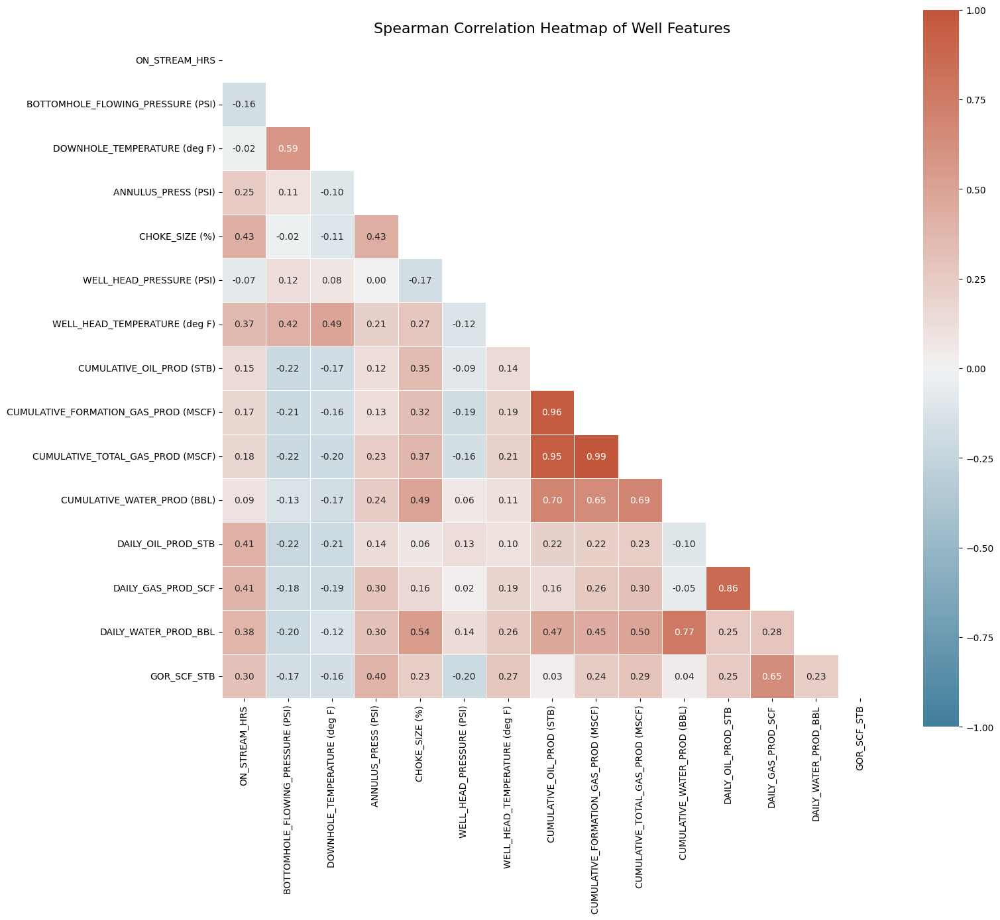


Highly correlated feature pairs (|correlation| > 0.8):
CUMULATIVE_FORMATION_GAS_PROD (MSCF) - CUMULATIVE_TOTAL_GAS_PROD (MSCF): 0.9853
CUMULATIVE_OIL_PROD (STB) - CUMULATIVE_FORMATION_GAS_PROD (MSCF): 0.9564
CUMULATIVE_OIL_PROD (STB) - CUMULATIVE_TOTAL_GAS_PROD (MSCF): 0.9492
DAILY_OIL_PROD_STB - DAILY_GAS_PROD_SCF: 0.8633

Feature selection recommendations:
Keep CUMULATIVE_FORMATION_GAS_PROD (MSCF), drop CUMULATIVE_TOTAL_GAS_PROD (MSCF) (corr: 0.9853)
Keep CUMULATIVE_FORMATION_GAS_PROD (MSCF), drop CUMULATIVE_OIL_PROD (STB) (corr: 0.9564)
Keep DAILY_OIL_PROD_STB, drop DAILY_GAS_PROD_SCF (corr: 0.8633)

Recommended features to keep (12 out of 15):
- ON_STREAM_HRS
- BOTTOMHOLE_FLOWING_PRESSURE (PSI)
- DOWNHOLE_TEMPERATURE (deg F)
- ANNULUS_PRESS (PSI)
- CHOKE_SIZE (%)
- WELL_HEAD_PRESSURE (PSI)
- WELL_HEAD_TEMPERATURE (deg F)
- CUMULATIVE_FORMATION_GAS_PROD (MSCF)
- CUMULATIVE_WATER_PROD (BBL)
- DAILY_OIL_PROD_STB
- DAILY_WATER_PROD_BBL
- GOR_SCF_STB

DataFrame with selected features:


In [14]:
# Perform feature correlation analysis using Spearman correlation
print("Performing Spearman correlation analysis to identify key features...")

# Select numerical columns for correlation analysis
# Excluding date and well name which are not numerical features
numerical_cols = wells_df_clean.select_dtypes(include=['float64', 'int64']).columns.tolist()

# Calculate Spearman correlation matrix (better for potentially non-linear relationships)
corr_matrix = wells_df_clean[numerical_cols].corr(method='spearman')

# Plot correlation heatmap
plt.figure(figsize=(16, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Create a mask for the upper triangle
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw heatmap with the mask
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            annot=True, fmt=".2f", square=True, linewidths=.5)
plt.title('Spearman Correlation Heatmap of Well Features', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Identify highly correlated feature pairs (threshold of 0.8)
print("\nHighly correlated feature pairs (|correlation| > 0.8):")
high_corr_pairs = []
for i in range(len(numerical_cols)):
    for j in range(i+1, len(numerical_cols)):
        if abs(corr_matrix.iloc[i, j]) > 0.8:
            high_corr_pairs.append((numerical_cols[i], numerical_cols[j], corr_matrix.iloc[i, j]))

# Sort by absolute correlation value
high_corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)

# Print highly correlated pairs
for col1, col2, corr in high_corr_pairs:
    print(f"{col1} - {col2}: {corr:.4f}")

# Identify features to keep based on correlation analysis
# Strategy: Keep one from each highly correlated group
# Start with all columns
features_to_drop = set()
primary_features = set()

print("\nFeature selection recommendations:")
for col1, col2, corr in high_corr_pairs:
    # If neither feature has been processed yet, keep the first one
    if col1 not in features_to_drop and col1 not in primary_features and \
       col2 not in features_to_drop and col2 not in primary_features:
        primary_features.add(col1)
        features_to_drop.add(col2)
        print(f"Keep {col1}, drop {col2} (corr: {corr:.4f})")
    # If col1 was already marked as primary, drop col2
    elif col1 in primary_features and col2 not in features_to_drop and col2 not in primary_features:
        features_to_drop.add(col2)
        print(f"Keep {col1}, drop {col2} (corr: {corr:.4f})")
    # If col2 was already marked as primary, drop col1
    elif col2 in primary_features and col1 not in features_to_drop and col1 not in primary_features:
        features_to_drop.add(col1)
        print(f"Keep {col2}, drop {col1} (corr: {corr:.4f})")
    # If col1 was already dropped and col2 hasn't been processed
    elif col1 in features_to_drop and col2 not in features_to_drop and col2 not in primary_features:
        primary_features.add(col2)
        print(f"Keep {col2} (corr: {corr:.4f})")
    # If col2 was already dropped and col1 hasn't been processed
    elif col2 in features_to_drop and col1 not in features_to_drop and col1 not in primary_features:
        primary_features.add(col1)
        print(f"Keep {col1} (corr: {corr:.4f})")

# Create a list of features to keep (excluding those marked for dropping)
features_to_keep = [col for col in numerical_cols if col not in features_to_drop]

print(f"\nRecommended features to keep ({len(features_to_keep)} out of {len(numerical_cols)}):")
for feature in features_to_keep:
    print(f"- {feature}")

# Create a dataframe with just the selected features (plus well name and date)
wells_df_selected = wells_df_clean[['WELL_NAME', 'PROD_DATE'] + features_to_keep].copy()

# Display the first few rows of the selected features dataframe
print("\nDataFrame with selected features:")
print(wells_df_selected.head())

In [15]:
# Save selected features for contextual embedding
print("Saving selected features for contextual embedding...")

# Create a dictionary to store feature information
feature_info = {
    'feature_names': features_to_keep,
    'num_features': len(features_to_keep),
    'total_columns': len(numerical_cols),
    'dropped_features': list(features_to_drop)
}

# Save feature names to a file
import json
with open('selected_features.json', 'w') as f:
    json.dump(feature_info, f, indent=4)

print(f"Saved {len(features_to_keep)} selected features out of {len(numerical_cols)} total numerical features")
print(f"Features saved to 'selected_features.json'")

# Save the selected features DataFrame for easy access
wells_df_selected.to_csv('wells_selected_features.csv', index=False)
print("Selected features dataset saved to 'wells_selected_features.csv'")

# Create a numpy array of the selected features (for ML models)
X_features = wells_df_selected[features_to_keep].values
print(f"Feature matrix shape: {X_features.shape}")

# Display feature names for reference
print("\nSelected feature names for contextual embedding:")
for i, feature in enumerate(features_to_keep):
    print(f"{i+1}. {feature}")

Saving selected features for contextual embedding...
Saved 12 selected features out of 15 total numerical features
Features saved to 'selected_features.json'
Selected features dataset saved to 'wells_selected_features.csv'
Feature matrix shape: (7595, 12)

Selected feature names for contextual embedding:
1. ON_STREAM_HRS
2. BOTTOMHOLE_FLOWING_PRESSURE (PSI)
3. DOWNHOLE_TEMPERATURE (deg F)
4. ANNULUS_PRESS (PSI)
5. CHOKE_SIZE (%)
6. WELL_HEAD_PRESSURE (PSI)
7. WELL_HEAD_TEMPERATURE (deg F)
8. CUMULATIVE_FORMATION_GAS_PROD (MSCF)
9. CUMULATIVE_WATER_PROD (BBL)
10. DAILY_OIL_PROD_STB
11. DAILY_WATER_PROD_BBL
12. GOR_SCF_STB


In [ ]:
# Create domain-specific features for each well
print("Creating domain-specific features for each well...")


# Initialize a dataframe to store domain features
domain_features_df = pd.DataFrame()
domain_features_df['WELL_NAME'] = sorted(wells_df_clean['WELL_NAME'].unique())

# Production days (already calculated)
domain_features_df['PRODUCTION_DAYS'] = domain_features_df['WELL_NAME'].map(production_days)

# Function to calculate domain features for each well
def calculate_domain_features(well_name):
    """Calculate domain-specific features for a given well"""
    # Get data for this well
    well_data = wells_df_clean[wells_df_clean['WELL_NAME'] == well_name]
    
    # Basic production totals
    total_oil = well_data['CUMULATIVE_OIL_PROD (STB)'].max()
    total_gas = well_data['CUMULATIVE_TOTAL_GAS_PROD (MSCF)'].max() * 1000  # Convert to SCF
    total_water = well_data['CUMULATIVE_WATER_PROD (BBL)'].max()
    
    # Rates
    avg_oil_rate = well_data['DAILY_OIL_PROD_STB'].mean()
    avg_gas_rate = well_data['DAILY_GAS_PROD_SCF'].mean()
    avg_water_rate = well_data['DAILY_WATER_PROD_BBL'].mean()
    max_oil_rate = well_data['DAILY_OIL_PROD_STB'].max()
    
    # Pressure and temperature
    avg_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].mean()
    max_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].max()
    min_bhp = well_data['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].min()
    avg_wht = well_data['WELL_HEAD_TEMPERATURE (deg F)'].mean()
    avg_dht = well_data['DOWNHOLE_TEMPERATURE (deg F)'].mean()
    
    # GOR and Water Cut
    avg_gor = well_data['GOR_SCF_STB'].mean()
    max_gor = well_data['GOR_SCF_STB'].max()
    
    # Calculate water cut
    well_data['WATER_CUT'] = well_data['DAILY_WATER_PROD_BBL'] / (well_data['DAILY_WATER_PROD_BBL'] + well_data['DAILY_OIL_PROD_STB'] + 1e-10)
    avg_water_cut = well_data['WATER_CUT'].mean()
    max_water_cut = well_data['WATER_CUT'].max()
    
    # Choke and onstream
    avg_choke_size = well_data['CHOKE_SIZE (%)'].mean()
    onstream_factor = well_data['ON_STREAM_HRS'].sum() / (24 * production_days[well_name])
    
    # Gas lift indicator (simplified check based on annulus pressure)
    has_gas_lift = 1 if well_data['ANNULUS_PRESS (PSI)'].mean() > 500 else 0
    
    # Trend analysis
    # Sort by date for trend analysis
    well_data_sorted = well_data.sort_values('PROD_DATE')
    
    # Only calculate trends if we have enough data points
    if len(well_data_sorted) > 5:
        # For GOR trend
        x = np.arange(len(well_data_sorted))
        y_gor = well_data_sorted['GOR_SCF_STB'].values
        y_wc = well_data_sorted['WATER_CUT'].values
        
        # Calculate productivity index (PI) - simplified version
        well_data_sorted['PI'] = well_data_sorted['DAILY_OIL_PROD_STB'] / (well_data_sorted['WELL_HEAD_PRESSURE (PSI)'] + 1e-10)
        y_pi = well_data_sorted['PI'].values
        
        # Linear regression for trends
        gor_slope = linregress(x, y_gor).slope if not np.isnan(y_gor).all() else 0
        wc_slope = linregress(x, y_wc).slope if not np.isnan(y_wc).all() else 0
        pi_slope = linregress(x, y_pi).slope if not np.isnan(y_pi).all() else 0
        
        # Trend directions
        gor_trend = 1 if gor_slope > 0.01 else (-1 if gor_slope < -0.01 else 0)
        wc_trend = 1 if wc_slope > 0.01 else (-1 if wc_slope < -0.01 else 0)
        pi_trend = 1 if pi_slope > 0.01 else (-1 if pi_slope < -0.01 else 0)
        
        # BHP decline rate
        bhp_values = well_data_sorted['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].values
        bhp_decline_rate = linregress(x, bhp_values).slope if not np.isnan(bhp_values).all() else 0
        
        # Coefficient of variation for rates (stability indicators)
        oil_rate_cv = well_data_sorted['DAILY_OIL_PROD_STB'].std() / (well_data_sorted['DAILY_OIL_PROD_STB'].mean() + 1e-10)
        gas_rate_cv = well_data_sorted['DAILY_GAS_PROD_SCF'].std() / (well_data_sorted['DAILY_GAS_PROD_SCF'].mean() + 1e-10)
        bhp_stability = well_data_sorted['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].std() / (well_data_sorted['BOTTOMHOLE_FLOWING_PRESSURE (PSI)'].mean() + 1e-10)
        
        # Overall stability indicator
        is_stable = 1 if (oil_rate_cv < 0.2 and bhp_stability < 0.1) else 0
        
        # Choke response (simplified - how much oil rate changes with choke changes)
        # First, check if we have choke changes
        if well_data_sorted['CHOKE_SIZE (%)'].std() > 5:
            # Calculate correlation between choke size and oil rate
            choke_response = np.corrcoef(well_data_sorted['CHOKE_SIZE (%)'], well_data_sorted['DAILY_OIL_PROD_STB'])[0, 1]
            choke_response = 0 if np.isnan(choke_response) else choke_response
        else:
            choke_response = 0
    else:
        # Default values if not enough data points
        gor_trend = 0
        wc_trend = 0
        pi_trend = 0
        gor_slope = 0
        wc_slope = 0
        pi_slope = 0
        bhp_decline_rate = 0
        oil_rate_cv = 0
        gas_rate_cv = 0
        bhp_stability = 0
        is_stable = 0
        choke_response = 0
    
    return {
        'TOTAL_OIL_PROD': total_oil,
        'TOTAL_GAS_PROD': total_gas,
        'TOTAL_WATER_PROD': total_water,
        'AVG_OIL_RATE': avg_oil_rate,
        'AVG_GAS_RATE': avg_gas_rate,
        'AVG_WATER_RATE': avg_water_rate,
        'MAX_OIL_RATE': max_oil_rate,
        'AVG_BHP': avg_bhp,
        'MAX_BHP': max_bhp,
        'MIN_BHP': min_bhp,
        'AVG_WHT': avg_wht,
        'AVG_DHT': avg_dht,
        'AVG_GOR': avg_gor,
        'MAX_GOR': max_gor,
        'AVG_WATER_CUT': avg_water_cut,
        'MAX_WATER_CUT': max_water_cut,
        'AVG_CHOKE_SIZE': avg_choke_size,
        'ONSTREAM_FACTOR': onstream_factor,
        'HAS_GAS_LIFT': has_gas_lift,
        'GOR_TREND': gor_trend,
        'WC_TREND': wc_trend,
        'PI_TREND': pi_trend,
        'GOR_SLOPE': gor_slope,
        'WC_SLOPE': wc_slope,
        'BHP_DECLINE_RATE': bhp_decline_rate,
        'PI_SLOPE': pi_slope,
        'OIL_RATE_CV': oil_rate_cv,
        'GAS_RATE_CV': gas_rate_cv,
        'BHP_STABILITY': bhp_stability,
        'IS_STABLE': is_stable,
        'CHOKE_RESPONSE': choke_response
    }

# Calculate features for each well
print("Calculating domain features for each well...")
for well_name in domain_features_df['WELL_NAME']:
    features = calculate_domain_features(well_name)
    
    # Update the dataframe with these features
    for feature_name, value in features.items():
        domain_features_df.loc[domain_features_df['WELL_NAME'] == well_name, feature_name] = value

# Save the domain features
domain_features_df.to_csv('domain_features.csv', index=False)
print("Domain features saved to 'domain_features.csv'")

# Display the domain features
print("\nDomain features (first few rows):")
print(domain_features_df.head())

# Display statistics of domain features
print("\nDomain features statistics:")
print(domain_features_df.describe())

Creating domain-specific features for each well...
Calculating domain features for each well...
Domain features saved to 'domain_features.csv'

Domain features (first few rows):
  WELL_NAME  PRODUCTION_DAYS  TOTAL_OIL_PROD  TOTAL_GAS_PROD  \
0   Well_#1              204        101659.0     145425000.0   
1  Well_#10              427        116279.0     147319000.0   
2  Well_#11              341        167307.0     245087000.0   
3  Well_#12              771        578776.0     392346000.0   
4  Well_#13              247        190635.0     264037000.0   

   TOTAL_WATER_PROD  AVG_OIL_RATE  AVG_GAS_RATE  AVG_WATER_RATE  MAX_OIL_RATE  \
0           38698.0    500.783251  7.163793e+05      190.630542        1550.0   
1           17343.0    273.305882  3.462518e+05       40.778824         805.0   
2           70288.0    488.304985  7.154194e+05      205.501466        1072.0   
3          324335.0    752.634590  5.102029e+05      421.762029        2260.0   
4           38115.0    771.51012

# Neural Contextual Embeddings for Well Time Series Data

Now we'll create neural contextual embeddings for our well time series data. This approach will:

1. Handle variable-length time series data using masking
2. Apply transformer encoders to capture temporal relationships
3. Use a [CLS] token approach to create a fixed-dimension embedding per well
4. Generate high-quality embeddings that preserve the temporal patterns in the data

## Embedding Architecture
- **Input**: Variable-length well time series with F features
- **Processing**: 
  - Padding to T_max (maximum length in batch)
  - Boolean masking to distinguish real vs. padded values
  - [CLS] token prepended for sequence representation
  - Positional encoding to maintain temporal information
  - Stack of Transformer Encoder blocks with self-attention
- **Output**: Fixed-size embedding vector [B, D_model] per well

This approach will allow each well to "speak for itself" through its full history without force truncation.

Preparing well sequence data for contextual embeddings...
Processing well data into sequences...
Maximum sequence length: 818 days
Number of features per time step: 12
Prepared 20 well sequences with shape: (20, 818, 12)
Sequence information saved to 'sequence_info.csv'
Normalized sequences saved to 'normalized_sequences.npy'


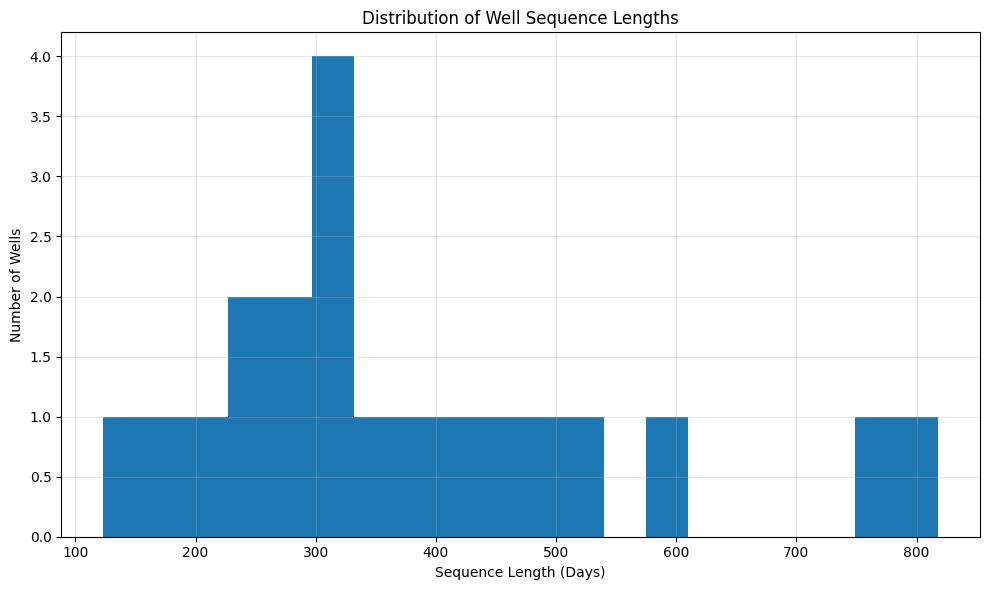


Sample sequence for well Well_#15 (first 5 days):


,ON_STREAM_HRS,BOTTOMHOLE_FLOWING_PRESSURE (PSI),DOWNHOLE_TEMPERATURE (deg F),ANNULUS_PRESS (PSI),CHOKE_SIZE (%),WELL_HEAD_PRESSURE (PSI),WELL_HEAD_TEMPERATURE (deg F),CUMULATIVE_FORMATION_GAS_PROD (MSCF),CUMULATIVE_WATER_PROD (BBL),DAILY_OIL_PROD_STB,DAILY_WATER_PROD_BBL,GOR_SCF_STB
0,24.0,3429.0,203.347,17.212,8.29008,51.985,98.928,169.0,0.0,0.0,0.0,0.000000
1,24.0,3367.0,203.344,21.585,8.76862,50.652,98.033,1083.0,244.0,730.0,244.0,1252.054795
2,24.0,3295.0,203.371,26.936,9.53824,49.711,104.789,1916.0,646.0,660.0,402.0,1262.121212
3,24.0,3250.0,205.377,28.383,9.28719,49.587,105.105,2749.0,1035.0,664.0,389.0,1254.518072
4,24.0,3218.0,205.331,28.488,9.24765,49.000,107.163,3597.0,1470.0,676.0,435.0,1254.437870


In [ ]:
# Prepare well sequence data for contextual embeddings
print("Preparing well sequence data for contextual embeddings...")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Process wells data into sequences
print("Processing well data into sequences...")

# Create a dictionary to map well names to their feature sequences
well_sequences = {}
well_sequence_names = []

# Use the selected features (from feature selection step)
sequence_features = features_to_keep

# Get sequence for each well
for well_name in wells_df_clean['WELL_NAME'].unique():
    # Get data for this well, sorted by date
    well_data = wells_df_clean[wells_df_clean['WELL_NAME'] == well_name].sort_values('PROD_DATE')
    
    # Extract features for this well
    well_sequence = well_data[sequence_features].values
    
    # Store the sequence
    well_sequences[well_name] = well_sequence
    well_sequence_names.append(well_name)

# Find the maximum sequence length
max_seq_length = max(len(seq) for seq in well_sequences.values())
print(f"Maximum sequence length: {max_seq_length} days")
print(f"Number of features per time step: {len(sequence_features)}")

# Create a dictionary mapping well names to indices
well_to_index = {name: idx for idx, name in enumerate(sorted(well_sequences.keys()))}

# Create padded numpy arrays and masks
X_sequences = np.zeros((len(well_sequences), max_seq_length, len(sequence_features)))
masks = np.zeros((len(well_sequences), max_seq_length), dtype=bool)

# Fill the arrays with the well sequences
for well_name, sequence in well_sequences.items():
    idx = well_to_index[well_name]
    seq_len = len(sequence)
    
    # Add the sequence
    X_sequences[idx, :seq_len, :] = sequence
    
    # Create the mask (True for real values, False for padding)
    masks[idx, :seq_len] = True

# Normalize sequences for better training
from sklearn.preprocessing import StandardScaler

# Reshape for scaling (combine batch and time dimensions)
original_shape = X_sequences.shape
flat_X = X_sequences.reshape(-1, original_shape[2])

# Fit scaler only on non-padded values
scaler = StandardScaler()
# Create a mask for non-padded values in the flattened array
flat_mask = masks.reshape(-1)
scaler.fit(flat_X[flat_mask])

# Transform all values
flat_X_scaled = np.zeros_like(flat_X)
flat_X_scaled[flat_mask] = scaler.transform(flat_X[flat_mask])

# Reshape back to original shape
X_sequences_normalized = flat_X_scaled.reshape(original_shape)

print(f"Prepared {len(well_sequences)} well sequences with shape: {X_sequences_normalized.shape}")

# Save sequence information for reference
sequence_info = pd.DataFrame({
    'well_name': well_sequence_names,
    'sequence_length': [len(well_sequences[name]) for name in well_sequence_names]
})
sequence_info.to_csv('sequence_info.csv', index=False)
print("Sequence information saved to 'sequence_info.csv'")

# Also save normalized sequences for future use
np.save('normalized_sequences.npy', X_sequences_normalized)
print("Normalized sequences saved to 'normalized_sequences.npy'")

# Display sequence length distribution
seq_lengths = [len(seq) for seq in well_sequences.values()]
plt.figure(figsize=(10, 6))
plt.hist(seq_lengths, bins=20)
plt.title('Distribution of Well Sequence Lengths')
plt.xlabel('Sequence Length (Days)')
plt.ylabel('Number of Wells')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display a sample sequence for a random well
sample_well = np.random.choice(well_sequence_names)
sample_data = pd.DataFrame(well_sequences[sample_well], columns=sequence_features)
print(f"\nSample sequence for well {sample_well} (first 5 days):")
sample_data.head()

In [18]:
# Define the transformer encoder components with enhanced attention
print("Defining transformer encoder components...")

# Define model parameters
d_model = 512  # Increased embedding dimension from 128 to 512
num_heads = 8  # Number of attention heads
ff_dim = 1024  # Increased feed-forward network dimension
num_transformer_blocks = 6  # Increased transformer blocks from 4 to 6
dropout_rate = 0.1  # Dropout rate
num_features = len(sequence_features)  # Number of input features

# Custom layers for the transformer model with enhanced attention

class CLSTokenLayer(layers.Layer):
    """Layer to add a learnable CLS token to the beginning of each sequence"""
    
    def __init__(self, embed_dim):
        super().__init__()
        self.embed_dim = embed_dim
        self.cls_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token"
        )
        
    def call(self, inputs):
        # inputs shape: (batch_size, sequence_length, feature_dim)
        batch_size = tf.shape(inputs)[0]
        
        # Repeat CLS token for each item in the batch
        cls_tokens = tf.repeat(self.cls_token, batch_size, axis=0)
        
        # Concatenate CLS token to the beginning of each sequence
        return tf.concat([cls_tokens, inputs], axis=1)
    
    def get_config(self):
        config = super().get_config()
        config.update({"embed_dim": self.embed_dim})
        return config

class PositionalEncoding(layers.Layer):
    """Enhanced positional encoding layer with learnable parameters"""
    
    def __init__(self, max_len, embed_dim):
        super().__init__()
        self.max_len = max_len
        self.embed_dim = embed_dim
        
        # Create positional encoding matrix with learnable scale
        pos_enc = self.get_positional_encoding(max_len, embed_dim)
        self.pos_encoding = tf.convert_to_tensor(pos_enc, dtype=tf.float32)
        
        # Add learnable scale parameter
        self.scale = self.add_weight(
            shape=(1,),
            initializer=tf.initializers.ones(),
            trainable=True,
            name="pos_encoding_scale"
        )
        
    def get_positional_encoding(self, max_len, embed_dim):
        # Create positional encoding matrix
        pos_enc = np.zeros((max_len, embed_dim))
        positions = np.arange(0, max_len)[:, np.newaxis]
        div_term = np.exp(np.arange(0, embed_dim, 2) * (-np.log(10000.0) / embed_dim))
        
        # Apply sine to even indices
        pos_enc[:, 0::2] = np.sin(positions * div_term)
        
        # Apply cosine to odd indices
        pos_enc[:, 1::2] = np.cos(positions * div_term)
        
        return pos_enc[np.newaxis, ...]
    
    def call(self, inputs):
        # inputs shape: (batch_size, sequence_length, embed_dim)
        seq_len = tf.shape(inputs)[1]
        
        # Return the inputs with scaled positional encoding added
        return inputs + self.scale * self.pos_encoding[:, :seq_len, :]
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "max_len": self.max_len,
            "embed_dim": self.embed_dim,
        })
        return config

class RowColumnAttention(layers.Layer):
    """Applies row-wise and column-wise attention for better feature interactions"""
    
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.dropout = dropout
        
        # Row-wise attention (sequence dimension)
        self.row_attention = layers.MultiHeadAttention(
            num_heads=num_heads, 
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )
        
        # Column-wise attention (feature dimension)
        self.col_attention = layers.MultiHeadAttention(
            num_heads=num_heads, 
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )
        
        # Normalization and dropout layers
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)
        
    def call(self, x, training=None):
        # Row-wise attention (sequence dimension)
        x_norm = self.norm1(x)
        row_out = self.row_attention(x_norm, x_norm)
        row_out = self.dropout1(row_out, training=training)
        x1 = x + row_out
        
        # Column-wise attention requires transpose
        # Original shape: (batch_size, seq_len, embed_dim)
        batch_size = tf.shape(x1)[0]
        seq_len = tf.shape(x1)[1]
        
        # Transpose for column attention
        x_t = tf.transpose(x1, perm=[0, 2, 1])  # -> (batch_size, embed_dim, seq_len)
        x_t_norm = self.norm2(x_t)
        
        # Apply column-wise attention
        col_out = self.col_attention(x_t_norm, x_t_norm)
        col_out = self.dropout2(col_out, training=training)
        
        # Add residual and transpose back
        x_t2 = x_t + col_out
        x2 = tf.transpose(x_t2, perm=[0, 2, 1])  # -> (batch_size, seq_len, embed_dim)
        
        return x2
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "dropout": self.dropout,
        })
        return config

class TransformerEncoderBlock(layers.Layer):
    """ Transformer encoder block with multi-head self-attention"""
    
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.rate = rate
        
        # Multi-head self-attention
        self.att = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim // num_heads, dropout=rate
        )
        
        # Enhanced feed-forward network with GELU activation
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dropout(rate),
            layers.Dense(embed_dim),
        ])
        
        # Layer normalization
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        
        # Dropout
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)
        
    def call(self, inputs, training=None):
        # Apply layer normalization before self-attention (pre-norm transformer)
        x = self.layernorm1(inputs)
        
        # Self-attention with skip connection (no mask parameter)
        attention_output = self.att(x, x)
        attention_output = self.dropout1(attention_output, training=training)
        out1 = inputs + attention_output
        
        # Feed-forward network with skip connection
        x = self.layernorm2(out1)
        ffn_output = self.ffn(x)
        ffn_output = self.dropout2(ffn_output, training=training)
        return out1 + ffn_output
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "rate": self.rate,
        })
        return config

print("Transformer components defined successfully!")

Defining transformer encoder components...
Transformer components defined successfully!


In [19]:
# Build the contextual embedding model
print("Building the  contextual embedding model...")

# First, create a custom layer to handle mask operations
class MaskHandler(layers.Layer):
    """Custom layer to handle mask operations in a Keras-compatible way"""
    
    def __init__(self):
        super().__init__()
    
    def call(self, mask_input):
        # Convert boolean mask to float mask
        float_mask = tf.cast(mask_input, tf.float32)
        
        # Add CLS token position (always True)
        batch_size = tf.shape(mask_input)[0]
        cls_mask = tf.ones((batch_size, 1), dtype=tf.float32)
        float_mask_with_cls = tf.concat([cls_mask, float_mask], axis=1)
        
        return float_mask_with_cls
    
    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1] + 1)

def build_enhanced_transformer_model(
    max_seq_length,
    num_features,
    d_model=512,
    num_heads=8,
    ff_dim=1024,
    num_transformer_blocks=6,
    dropout_rate=0.1,
    cls_pooling=True,
    use_row_col_attention=True
):
    """
    Build an enhanced transformer-based embedding model with row-column attention
    
    Args:
        max_seq_length: Maximum sequence length (for positional encoding)
        num_features: Number of input features
        d_model: Embedding dimension (increased to 512)
        num_heads: Number of attention heads
        ff_dim: Feed-forward network dimension (increased to 1024)
        num_transformer_blocks: Number of transformer blocks (increased to 6)
        dropout_rate: Dropout rate
        cls_pooling: Whether to use CLS token pooling (True) or attention pooling (False)
        use_row_col_attention: Whether to use row-column attention for feature interactions
        
    Returns:
        model: Keras model that takes sequences and masks as input and outputs embeddings
    """
    # Input layers
    sequence_input = layers.Input(shape=(max_seq_length, num_features), name="sequence_input")
    mask_input = layers.Input(shape=(max_seq_length,), dtype=bool, name="mask_input")
    
    # Projection to d_model dimensions with a wider initial projection
    x = layers.Dense(d_model, activation="gelu", name="input_projection_1")(sequence_input)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(d_model, name="input_projection_2")(x)
    
    # Add CLS token
    x = CLSTokenLayer(d_model)(x)
    
    # Add positional encoding
    x = PositionalEncoding(max_seq_length + 1, d_model)(x)  # +1 for CLS token
    
    # Process mask using our custom layer to avoid TensorFlow ops on KerasTensor
    mask_with_cls = MaskHandler()(mask_input)
    
    # Apply initial dropout
    x = layers.Dropout(dropout_rate)(x)
    
    # Stack transformer blocks
    for i in range(num_transformer_blocks):
        # Apply row-column attention every other block if enabled
        if use_row_col_attention and i % 2 == 1:
            x = RowColumnAttention(
                d_model, num_heads, dropout=dropout_rate
            )(x)
        else:
            # Regular transformer block
            x = TransformerEncoderBlock(
                d_model, num_heads, ff_dim, dropout_rate
            )(x)
            
        # Add a residual highway connection every 2 blocks for very deep networks
        if i > 0 and i % 2 == 0 and i < num_transformer_blocks - 1:
            # Highway connection with gating
            gate = layers.Dense(d_model, activation='sigmoid')(x)
            highway_out = gate * x + (1 - gate) * layers.Dense(d_model)(x)
            x = highway_out
    
    # Extract CLS token embedding or use pooling
    if cls_pooling:
        # Extract the CLS token embedding (first position)
        embedding = layers.Lambda(lambda x: x[:, 0, :])(x)
    else:
        # Create a masked pooling layer
        # First apply layer normalization
        x = layers.LayerNormalization(epsilon=1e-6)(x)
        
        # Expand dimensions of mask for broadcasting
        expanded_mask = layers.Reshape((max_seq_length + 1, 1))(mask_with_cls)
        
        # Attention-weighted pooling instead of simple averaging
        # Create attention scores
        attn_scores = layers.Dense(1)(x)  # (batch_size, seq_len, 1)
        
        # Mask out padding tokens
        masked_attn_scores = layers.Multiply()([attn_scores, expanded_mask])
        
        # Apply softmax over the sequence dimension
        attn_weights = layers.Softmax(axis=1)(masked_attn_scores)
        
        # Apply attention weights to the sequence
        context_vector = tf.reduce_sum(x * attn_weights, axis=1)
        embedding = context_vector
    
    # Final MLP projection to get the final embedding
    embedding = layers.Dense(d_model, activation="gelu")(embedding)
    embedding = layers.Dropout(dropout_rate/2)(embedding)
    embedding = layers.Dense(d_model)(embedding)
    
    # Final embedding output with normalization
    embedding = layers.LayerNormalization(epsilon=1e-6, name="final_embedding")(embedding)
    
    # Create the model
    model = models.Model(
        inputs=[sequence_input, mask_input], 
        outputs=embedding,
        name="enhanced_well_embedding_model"
    )
    
    return model

# Build the enhanced model
embedding_model = build_enhanced_transformer_model(
    max_seq_length=max_seq_length,
    num_features=num_features,
    d_model=d_model,
    num_heads=num_heads,
    ff_dim=ff_dim,
    num_transformer_blocks=num_transformer_blocks,
    dropout_rate=dropout_rate,
    cls_pooling=True,  # Use CLS token pooling
    use_row_col_attention=True  # Enable row-column attention
)

# Print model summary
print("\n Model Summary:")
embedding_model.summary()

# Visualize model architecture
tf.keras.utils.plot_model(
    embedding_model, 
    to_file='enhanced_embedding_model_architecture.png', 
    show_shapes=True,
    show_layer_names=True,
    rankdir='TB'
)
print("Model architecture visualization saved to 'enhanced_embedding_model_architecture.png'")

# Generate example embeddings to verify the model works
print("\nGenerating example embeddings...")
example_embeddings = embedding_model.predict([X_sequences_normalized[:5], masks[:5]])
print(f"Example embeddings shape: {example_embeddings.shape}")
print("First few dimensions of the first embedding vector:")
print(example_embeddings[0, :10])  # Show first 10 dimensions

Building the  contextual embedding model...


 Model Summary:


Model: "enhanced_well_embedding_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sequence_input      │ (None, 818, 12)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection_1  │ (None, 818, 512)  │      6,656 │ sequence_input[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 818, 512)  │      2,048 │ input_projection… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection_2  │ (None, 818, 512)  │    262,656 │ batch_normalizat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cls_token_layer     │ (None, 819, 512)  │        512 │ input_projection… │
│ (CLSTokenLayer)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 819, 512)  │          1 │ cls_token_layer[… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 819, 512)  │          0 │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 819, 512)  │  2,102,784 │ dropout[0][0]     │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ row_column_attenti… │ (None, 819, 512)  │  2,732,953 │ transformer_enco… │
│ (RowColumnAttentio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 819, 512)  │  2,102,784 │ row_column_atten… │
│ (TransformerEncode… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 819, 512)  │    262,656 │ transformer_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 819, 512)  │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 819, 512)  │    262,656 │ transformer_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 819, 512)  │          0 │ dense_4[0][0],    │
│                     │                   │            │ transformer_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 819, 512)  │          0 │ subtract[0][0],   │
│ (Multiply)          │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 819, 512)  │          0 │ multiply[0][0],   │
│                     │                   │            │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ row_column_attenti… │ (None, 819, 512)  │  2,732,953 │ add[0][0]         │
│ (RowColumnAttentio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, 819, 512)  │  2,102,784 │ row_column_atten… │
│ (TransformerEncode… │                   │            │                 

 Total params: 16,356,044 (62.39 MB)

 Trainable params: 16,355,020 (62.39 MB)

 Non-trainable params: 1,024 (4.00 KB)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
Model architecture visualization saved to 'enhanced_embedding_model_architecture.png'

Generating example embeddings...
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Example embeddings shape: (5, 512)
First few dimensions of the first embedding vector:
[-1.1185267  -0.18868834 -0.69993156  1.2617981   1.5444326  -1.0421635
  0.07751088  1.2032151   0.36459905  0.63313836]


In [ ]:
# Generate embeddings for all wells
print("Generating embeddings for all wells...")

# Generate embeddings for all wells
all_well_embeddings = embedding_model.predict([X_sequences_normalized, masks])

print(f"Generated embeddings for {len(all_well_embeddings)} wells, each with dimension {all_well_embeddings.shape[1]}")

# Create a dictionary mapping well names to their embeddings
well_embeddings = {}
for i, well_name in enumerate(sorted(well_sequences.keys())):
    well_embeddings[well_name] = all_well_embeddings[i]

# Display a few examples
print("\nExample embeddings (first 5 dimensions) for the first 3 wells:")
for i, (well_name, embedding) in enumerate(list(well_embeddings.items())[:3]):
    print(f"{well_name}: {embedding[:5]}...")

# Apply PCA to reduce to 2 dimensions for visualization
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(all_well_embeddings)

# Create a DataFrame for plotting
embedding_viz_df = pd.DataFrame({
    'well_name': sorted(well_sequences.keys()),
    'x': embeddings_2d[:, 0],
    'y': embeddings_2d[:, 1]
})
# Save embeddings
np.save('well_embeddings.npy', all_well_embeddings)
print("Well embeddings saved to 'well_embeddings.npy'")

# Also save as a DataFrame
embedding_df = pd.DataFrame(
    all_well_embeddings, 
    index=sorted(well_sequences.keys())
)
embedding_df.index.name = 'well_name'
embedding_df.to_csv('well_embeddings.csv')
print("Well embeddings also saved as CSV to 'well_embeddings.csv'")

# Save the model for future use
embedding_model.save('well_embedding_model.h5')
print("Embedding model saved to 'well_embedding_model.h5'")

# Show embedding shape again to confirm
print(f"\nFinal embeddings shape: {all_well_embeddings.shape} [{len(sorted(well_sequences.keys()))} wells × {d_model} dimensions]")

Generating embeddings for all wells...
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
Generated embeddings for 20 wells, each with dimension 512

Example embeddings (first 5 dimensions) for the first 3 wells:
Well_#1: [-1.1185267  -0.18868834 -0.69993156  1.2617981   1.5444326 ]...
Well_#10: [-1.1130092  -0.16812658 -0.71739465  1.3110372   1.5435821 ]...
Well_#11: [-1.1261756  -0.19739491 -0.68958217  1.2782942   1.5417396 ]...
Well embeddings saved to 'well_embeddings.npy'


Well embeddings also saved as CSV to 'well_embeddings.csv'
Embedding model saved to 'well_embedding_model.h5'

Final embeddings shape: (20, 512) [20 wells × 512 dimensions]


# Feature Fusion and Classification

We've successfully created:
1. Domain-specific features (aggregated statistics per well)
2. Neural contextual embeddings from time series data

## Feature Fusion
We'll combine these two representations:

- **Neural embeddings**: [B, D_model] (e.g., [B, 128]) - captures temporal patterns
- **Domain features**: [B, N_domain] (e.g., [B, 33]) - captures engineering knowledge
- **Final vector per well**: [B, D_model + N_domain] - comprehensive representation

This combined representation will be used as input to a classification head to predict the multiple target categories for each well.

In [24]:
# Prepare aligned data for feature fusion
print("Preparing aligned data for feature fusion...")

# Align domain features and embeddings by well name
print("Aligning domain features with embeddings...")

# Convert well names to common format (sometimes they might have different formats)
aligned_well_names = []
common_wells = []

# Find wells that have both domain features and embeddings
for well_name in domain_features_df['WELL_NAME']:
    if well_name in well_embeddings:
        common_wells.append(well_name)
        aligned_well_names.append(well_name)

print(f"Found {len(common_wells)} wells with both domain features and embeddings")

# Create arrays with aligned data
aligned_domain_features = np.array([domain_features_df[domain_features_df['WELL_NAME'] == well].drop('WELL_NAME', axis=1).values.flatten() 
                                    for well in common_wells])

aligned_embeddings = np.array([well_embeddings[well] for well in common_wells])

print(f"Domain features shape: {aligned_domain_features.shape}")
print(f"Embeddings shape: {aligned_embeddings.shape}")

# Save the aligned feature arrays
np.save('aligned_domain_features.npy', aligned_domain_features)
np.save('aligned_embeddings.npy', aligned_embeddings)
np.save('aligned_well_names.npy', np.array(aligned_well_names))

print("Alignment complete. Data saved to:")
print("- aligned_domain_features.npy")
print("- aligned_embeddings.npy")
print("- aligned_well_names.npy")

# Also align with targets (encoded classifications)
print("\nAligning with target classifications...")

# First, let's examine the well name formats in both datasets
print("\nComparing well name formats:")
print(f"Domain features well name format example: {domain_features_df['WELL_NAME'].iloc[0]}")
print(f"Target dataset well name format example: {encoded_df['Well'].iloc[0]}")

# Check if there's a pattern mismatch (e.g., "Well_#1" vs "1")
# Let's create a mapping dictionary between different well name formats
well_name_mapping = {}

# Try different matching strategies:
# 1. Direct match
# 2. Extract numbers from well names
# 3. Strip prefixes/suffixes

# Extract number from well name (e.g., "Well_#1" -> "1")
import re
for well_name in aligned_well_names:
    # Try to extract the well number
    match = re.search(r'#(\d+)', well_name)
    if match:
        well_number = match.group(1)
        # Check if this number exists as a well name or as part of a well name in encoded_df
        for target_well in encoded_df['Well']:
            if well_number == str(target_well) or well_number in str(target_well):
                well_name_mapping[well_name] = target_well
                print(f"Matched: {well_name} -> {target_well}")
                break

# If we found any mappings, use them to align the data
if well_name_mapping:
    print(f"\nFound {len(well_name_mapping)} well name mappings between datasets")
    
    # Find common wells using the mapping
    aligned_targets = []
    mapped_well_names = []
    
    for domain_well_name in aligned_well_names:
        target_well_name = well_name_mapping.get(domain_well_name)
        if target_well_name is not None:
            # Get the target values for this well
            target_row = encoded_df[encoded_df['Well'] == target_well_name]
            if not target_row.empty:
                # Remove the well name column and convert to array
                target_values = target_row.drop('Well', axis=1).values.flatten()
                aligned_targets.append(target_values)
                mapped_well_names.append(domain_well_name)
                print(f"Aligned: {domain_well_name} -> {target_well_name}")
    
    # Check if we found any targets
    if aligned_targets:
        # Filter domain features and embeddings to match only the wells with targets
        idx_map = {name: i for i, name in enumerate(aligned_well_names)}
        indices = [idx_map[name] for name in mapped_well_names if name in idx_map]
        
        aligned_domain_features_with_targets = aligned_domain_features[indices]
        aligned_embeddings_with_targets = aligned_embeddings[indices]
        
        # Convert to numpy array
        aligned_targets = np.array(aligned_targets)
        print(f"\nAfter mapping, aligned {len(mapped_well_names)} wells with targets")
        print(f"Aligned targets shape: {aligned_targets.shape}")
        print(f"Aligned domain features shape: {aligned_domain_features_with_targets.shape}")
        print(f"Aligned embeddings shape: {aligned_embeddings_with_targets.shape}")
        
        # Save the aligned data with targets
        np.save('aligned_targets.npy', aligned_targets)
        np.save('aligned_domain_features_with_targets.npy', aligned_domain_features_with_targets)
        np.save('aligned_embeddings_with_targets.npy', aligned_embeddings_with_targets)
        np.save('aligned_well_names_with_targets.npy', np.array(mapped_well_names))
        
        print("Aligned targets saved to 'aligned_targets.npy'")
    else:
        print("\nNo wells could be aligned between domain features and targets after mapping")
        
        # Let's try another approach: manual mapping
        print("\nAttempting manual well mapping based on position...")
        
        # Check if we have the same number of wells in both datasets
        if len(aligned_well_names) == len(encoded_df):
            print("Both datasets have the same number of wells. Trying position-based mapping...")
            
            # Sort both datasets for consistency
            sorted_domain_wells = sorted(aligned_well_names)
            sorted_target_wells = sorted(encoded_df['Well'].tolist())
            
            # Create a position-based mapping
            position_mapping = dict(zip(sorted_domain_wells, sorted_target_wells))
            
            # Create aligned arrays based on this mapping
            aligned_targets = []
            for domain_well in sorted_domain_wells:
                target_well = position_mapping[domain_well]
                target_row = encoded_df[encoded_df['Well'] == target_well]
                target_values = target_row.drop('Well', axis=1).values.flatten()
                aligned_targets.append(target_values)
                
            # Convert to numpy array
            aligned_targets = np.array(aligned_targets)
            print(f"Created position-based mapping between {len(sorted_domain_wells)} wells")
            print(f"Aligned targets shape: {aligned_targets.shape}")
            
            # Save aligned data
            np.save('aligned_targets.npy', aligned_targets)
            print("Aligned targets (position-based) saved to 'aligned_targets.npy'")
            
            # Print warning about position-based mapping
            print("\nWARNING: Used position-based mapping which assumes wells are in the same order in both datasets.")
            print("Please verify this is correct before proceeding with model training.")
else:
    # Find common wells between our aligned data and the encoded targets
    print("\nAttempting direct matching between domain wells and target wells...")
    target_well_names = encoded_df['Well'].values
    aligned_targets = []

    for well in aligned_well_names:
        if well in target_well_names:
            # Get the target values for this well
            target_row = encoded_df[encoded_df['Well'] == well]
            # Remove the well name column and convert to array
            target_values = target_row.drop('Well', axis=1).values.flatten()
            aligned_targets.append(target_values)
        else:
            print(f"Warning: Well {well} not found in targets")

    # Convert to numpy array if we have any matching wells
    if aligned_targets:
        aligned_targets = np.array(aligned_targets)
        print(f"Aligned targets shape: {aligned_targets.shape}")
        np.save('aligned_targets.npy', aligned_targets)
        print("Aligned targets saved to 'aligned_targets.npy'")
    else:
        print("No matching wells found in targets")

# Create dataframes for easier inspection
domain_features_aligned = pd.DataFrame(
    aligned_domain_features, 
    index=aligned_well_names
)
domain_features_aligned.index.name = 'well_name'

target_features_aligned = None
if 'aligned_targets' in locals() and len(aligned_targets) > 0:
    # Create column names for the target features
    target_feature_names = [f"{col}_encoded" for col in target_columns]
    
    # Use the appropriate well names based on which mapping worked
    if 'mapped_well_names' in locals() and len(mapped_well_names) > 0:
        well_names_for_targets = mapped_well_names
    else:
        # Use the well names that had direct matches
        well_names_for_targets = [well for well in aligned_well_names if well in target_well_names]
    
    target_features_aligned = pd.DataFrame(
        aligned_targets,
        columns=target_feature_names,
        index=well_names_for_targets
    )
    target_features_aligned.index.name = 'well_name'


if target_features_aligned is not None:
    print("\nAligned target features (first 5 rows):")
    print(target_features_aligned.head())
    
    # Save as CSV for easier inspection
    domain_features_aligned.to_csv('domain_features_aligned.csv')
    target_features_aligned.to_csv('target_features_aligned.csv')
    print("Aligned data also saved to CSV files for inspection")
else:
    print("\nNo target features could be aligned - please check well naming conventions between datasets")
    print("You may need to manually map well names or create a lookup dictionary")

Preparing aligned data for feature fusion...
Aligning domain features with embeddings...
Found 20 wells with both domain features and embeddings
Domain features shape: (20, 32)
Embeddings shape: (20, 512)
Alignment complete. Data saved to:
- aligned_domain_features.npy
- aligned_embeddings.npy
- aligned_well_names.npy

Aligning with target classifications...

Comparing well name formats:
Domain features well name format example: Well_#1
Target dataset well name format example: 1
Matched: Well_#1 -> 1
Matched: Well_#10 -> 10
Matched: Well_#11 -> 11
Matched: Well_#12 -> 12
Matched: Well_#13 -> 13
Matched: Well_#14 -> 14
Matched: Well_#15 -> 15
Matched: Well_#16 -> 16
Matched: Well_#17 -> 17
Matched: Well_#18 -> 18
Matched: Well_#19 -> 19
Matched: Well_#2 -> 2
Matched: Well_#20 -> 20
Matched: Well_#3 -> 3
Matched: Well_#4 -> 4
Matched: Well_#5 -> 5
Matched: Well_#6 -> 6
Matched: Well_#7 -> 7
Matched: Well_#8 -> 8
Matched: Well_#9 -> 9

Found 20 well name mappings between datasets
Aligned:

# Multi-Head Classification with XGBOOST AND KMEANS

In [ ]:
# Create target_column_names from target_columns
target_column_names = target_columns.copy()

print(f"Target column names: {target_column_names}")
print(f"Number of targets: {len(target_column_names)}")

# Also create n_classes_per_target for consistency
n_classes_per_target = []
for target_name in target_column_names:
    # Get unique classes for this target from aligned_targets
    target_idx = target_columns.index(target_name)
    unique_classes = len(np.unique(aligned_targets[:, target_idx]))
    n_classes_per_target.append(unique_classes)

print(f"Classes per target: {n_classes_per_target}")

# Also create aligned_well_names_with_targets for consistency
aligned_well_names_with_targets = aligned_well_names.copy()


# Create X_combined by concatenating embeddings and domain features
print("Creating X_combined by combining embeddings and domain features...")

# Check the shapes first
print(f"Aligned embeddings shape: {aligned_embeddings.shape}")
print(f"Aligned domain features shape: {aligned_domain_features.shape}")

# Combine embeddings and domain features
X_combined = np.concatenate([aligned_domain_features, aligned_embeddings], axis=1)

print(f"X_combined shape: {X_combined.shape}")
print(f"Domain features: {aligned_domain_features.shape[1]} dimensions")
print(f"Embeddings: {aligned_embeddings.shape[1]} dimensions")
print(f"Total combined: {X_combined.shape[1]} dimensions")

print("Variables ready for XGBoost analysis!")

XGBoost with K-Means Clustering Analysis
Created 5 clusters using K-Means
Cluster distribution: [9 1 2 1 7]
Total wells: 20

Target 1: Reservoir Name
  Original classes: [0 1 2 3 4] -> Encoded: [0 1 2 3 4]
  Class distribution: ['Class 0: 3 wells', 'Class 1: 5 wells', 'Class 2: 2 wells', 'Class 3: 6 wells', 'Class 4: 4 wells']
  Accuracy: 1.000 (20/20 wells correct)
  F1 Score: 1.000
  Confusion Matrix (Well Counts):
  [[3 0 0 0 0]
 [0 5 0 0 0]
 [0 0 2 0 0]
 [0 0 0 6 0]
 [0 0 0 0 4]]

Target 2: Reservoir Type
  Original classes: [0 1] -> Encoded: [0 1]
  Class distribution: ['Class 0: 9 wells', 'Class 1: 11 wells']
  Accuracy: 1.000 (20/20 wells correct)
  F1 Score: 1.000
  Confusion Matrix (Well Counts):
  [[ 9  0]
 [ 0 11]]

Target 3: Well Type
  Original classes: [0 1] -> Encoded: [0 1]
  Class distribution: ['Class 0: 13 wells', 'Class 1: 7 wells']
  Accuracy: 1.000 (20/20 wells correct)
  F1 Score: 1.000
  Confusion Matrix (Well Counts):
  [[13  0]
 [ 0  7]]

Target 4: Production 

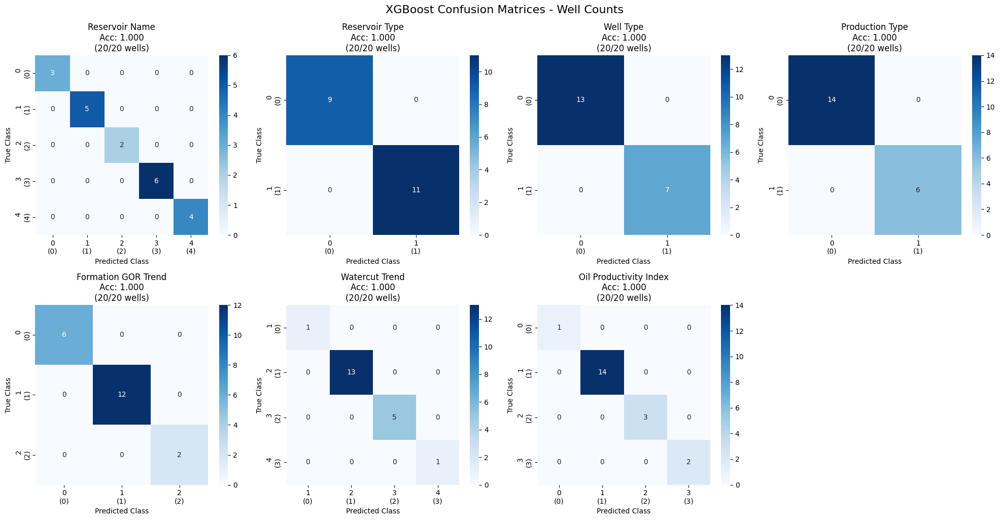


DETAILED PER-CLASS ANALYSIS:

Reservoir Name:
  Class 0 (0):
    Correctly classified: 3 wells
    Total actual: 3 wells
    Total predicted: 3 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000
  Class 1 (1):
    Correctly classified: 5 wells
    Total actual: 5 wells
    Total predicted: 5 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000
  Class 2 (2):
    Correctly classified: 2 wells
    Total actual: 2 wells
    Total predicted: 2 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000
  Class 3 (3):
    Correctly classified: 6 wells
    Total actual: 6 wells
    Total predicted: 6 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000
  Class 4 (4):
    Correctly classified: 4 wells
    Total actual: 4 wells
    Total predicted: 4 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000

Reservoir Type:
  Class 0 (0):
    Correctly classified: 9 wells
    Total actual: 9 wells
    Total predicted: 9 wells
    Precision: 1.000, Recall: 1.000, F1: 1.000
  Class 1 (1):
    Correctly c

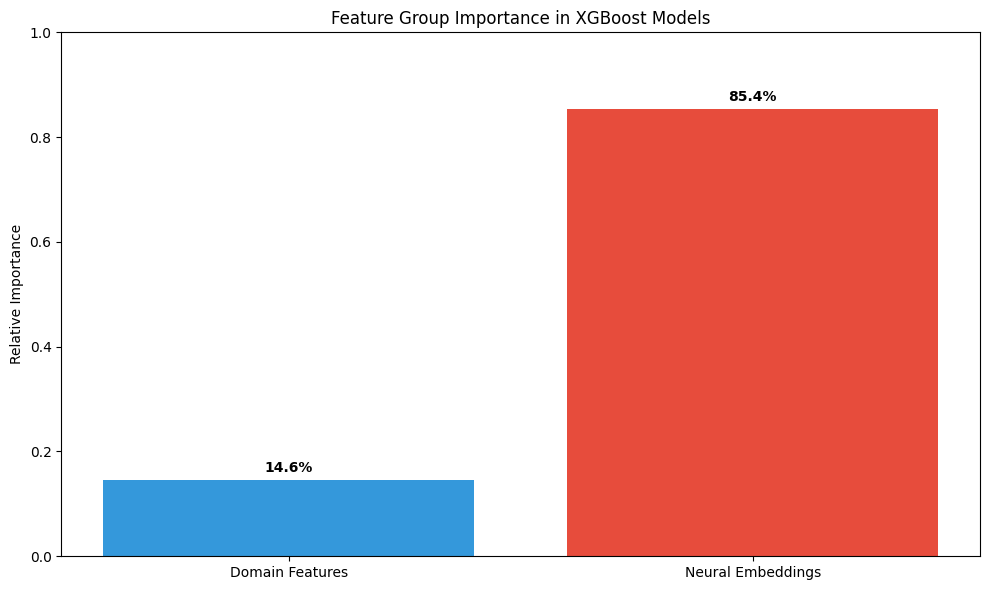


WELL-LEVEL PREDICTIONS:
Sample of well predictions (first 10 wells):
Well_Name  Reservoir Name_True  Reservoir Name_Pred  Reservoir Name_Correct  Reservoir Type_True  Reservoir Type_Pred  Reservoir Type_Correct  Well Type_True  Well Type_Pred  Well Type_Correct  Production Type_True  Production Type_Pred  Production Type_Correct  Formation GOR Trend_True  Formation GOR Trend_Pred  Formation GOR Trend_Correct  Watercut Trend_True  Watercut Trend_Pred  Watercut Trend_Correct  Oil Productivity Index_True  Oil Productivity Index_Pred  Oil Productivity Index_Correct
  Well_#1                    2                    2                    True                    1                    1                    True               1               1               True                     1                     1                     True                         0                         0                         True                    2                    2                    True                       

In [ ]:
# XGBoost with K-Means Clustering
print("XGBoost with K-Means Clustering Analysis")
print("="*70)

# Use K-Means to create clusters on the combined features
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(X_combined)

print(f"Created {n_clusters} clusters using K-Means")
print(f"Cluster distribution: {np.bincount(cluster_labels)}")
print(f"Total wells: {len(X_combined)}")

# Dictionary to store models and results
xgb_models = {}
xgb_results = {}
label_encoders = {}

# Train one XGBoost classifier for each target
for i, target_name in enumerate(target_column_names):
    print(f"\nTarget {i+1}: {target_name}")
    
    # Extract target and fix label encoding
    y_data = aligned_targets[:, i].copy()
    
    # Create label encoder to fix class labels (0-indexed)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)
    label_encoders[target_name] = le
    
    n_classes = len(np.unique(y_encoded))
    print(f"  Original classes: {np.unique(y_data)} -> Encoded: {np.unique(y_encoded)}")
    print(f"  Class distribution: {[(f'Class {j}: {np.sum(y_encoded==j)} wells') for j in range(n_classes)]}")
    
    # Configure XGBoost
    if n_classes == 2:
        objective = 'binary:logistic'
    else:
        objective = 'multi:softprob'
    
    # Create and train XGBoost model
    model = xgb.XGBClassifier(
        objective=objective,
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
    
    # Train model
    model.fit(X_combined, y_encoded)
    
    # Store model
    xgb_models[target_name] = model
    
    # Make predictions
    y_pred = model.predict(X_combined)
    
    # Calculate metrics
    accuracy = accuracy_score(y_encoded, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_encoded, y_pred, average='macro')
    cm = confusion_matrix(y_encoded, y_pred)
    
    # Store results
    xgb_results[target_name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm,  # This contains actual well counts
        'predictions': y_pred,
        'true_labels': y_encoded,
        'label_encoder': le
    }
    
    print(f"  Accuracy: {accuracy:.3f} ({np.sum(y_encoded == y_pred)}/{len(y_encoded)} wells correct)")
    print(f"  F1 Score: {f1:.3f}")
    
    # Print detailed confusion matrix with well counts
    print(f"  Confusion Matrix (Well Counts):")
    print(f"  {cm}")
    
    # Show which wells were misclassified
    misclassified = np.where(y_encoded != y_pred)[0]
    if len(misclassified) > 0:
        print(f"  Misclassified wells: {len(misclassified)} out of {len(y_encoded)}")
        for idx in misclassified[:5]:  # Show first 5 misclassified
            print(f"    Well {idx}: True={le.inverse_transform([y_encoded[idx]])[0]}, Pred={le.inverse_transform([y_pred[idx]])[0]}")
        if len(misclassified) > 5:
            print(f"    ... and {len(misclassified)-5} more")

# Create summary
summary = pd.DataFrame({
    'Target': list(xgb_results.keys()),
    'Total_Wells': [len(xgb_results[target]['true_labels']) for target in xgb_results.keys()],
    'Correct_Wells': [np.sum(xgb_results[target]['true_labels'] == xgb_results[target]['predictions']) for target in xgb_results.keys()],
    'Accuracy': [r['accuracy'] for r in xgb_results.values()],
    'F1': [r['f1'] for r in xgb_results.values()]
})

print("\n" + "="*70)
print("XGBOOST RESULTS SUMMARY (WELL COUNTS):")
print("="*70)
print(summary.to_string(index=False))

# Plot confusion matrices with ACTUAL WELL COUNTS (not normalized)
n_targets = len(xgb_results)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (target_name, results) in enumerate(xgb_results.items()):
    if i < len(axes):
        cm = results['confusion_matrix']  # This is the raw count matrix
        
        # Plot RAW confusion matrix (well counts)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])  # fmt='d' for integers
        axes[i].set_title(f'{target_name}\nAcc: {results["accuracy"]:.3f}\n({np.sum(results["true_labels"] == results["predictions"])}/{len(results["true_labels"])} wells)')
        axes[i].set_xlabel('Predicted Class')
        axes[i].set_ylabel('True Class')
        
        # Add class labels
        le = results['label_encoder']
        class_names = le.classes_
        axes[i].set_xticklabels([f'{name}\n({j})' for j, name in enumerate(class_names)])
        axes[i].set_yticklabels([f'{name}\n({j})' for j, name in enumerate(class_names)])

# Hide empty subplots
for i in range(n_targets, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.suptitle('XGBoost Confusion Matrices - Well Counts', y=1.02, fontsize=16)
plt.show()

# Create detailed per-class analysis
print("\n" + "="*70)
print("DETAILED PER-CLASS ANALYSIS:")
print("="*70)

for target_name, results in xgb_results.items():
    print(f"\n{target_name}:")
    cm = results['confusion_matrix']
    le = results['label_encoder']
    class_names = le.classes_
    
    # Calculate per-class metrics
    for i, class_name in enumerate(class_names):
        tp = cm[i, i]  # True positives
        fp = cm[:, i].sum() - tp  # False positives
        fn = cm[i, :].sum() - tp  # False negatives
        tn = cm.sum() - tp - fp - fn  # True negatives
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        print(f"  Class {class_name} ({i}):")
        print(f"    Correctly classified: {tp} wells")
        print(f"    Total actual: {tp + fn} wells")
        print(f"    Total predicted: {tp + fp} wells")
        print(f"    Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

# Feature importance analysis
print("\n" + "="*70)
print("FEATURE IMPORTANCE ANALYSIS:")
print("="*70)

# Get feature importance from all models
all_importance = []
for target_name, model in xgb_models.items():
    importance = model.feature_importances_
    all_importance.append(importance)

# Average importance across all targets
avg_importance = np.mean(all_importance, axis=0)

# Split into domain features and embeddings
n_domain = aligned_domain_features_with_targets.shape[1]
n_embed = aligned_embeddings_with_targets.shape[1]

domain_importance = avg_importance[:n_domain].sum()
embed_importance = avg_importance[n_domain:].sum()
total_importance = domain_importance + embed_importance

print(f"Domain Features Importance: {domain_importance/total_importance:.1%}")
print(f"Neural Embeddings Importance: {embed_importance/total_importance:.1%}")

# Plot feature importance comparison
plt.figure(figsize=(10, 6))
categories = ['Domain Features', 'Neural Embeddings']
importance_values = [domain_importance/total_importance, embed_importance/total_importance]
colors = ['#3498db', '#e74c3c']

bars = plt.bar(categories, importance_values, color=colors)
plt.title('Feature Group Importance in XGBoost Models')
plt.ylabel('Relative Importance')
plt.ylim(0, 1)

# Add percentage labels on bars
for bar, value in zip(bars, importance_values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{value:.1%}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Show well names and their predictions
print("\n" + "="*70)
print("WELL-LEVEL PREDICTIONS:")
print("="*70)

# Create a comprehensive results dataframe
results_df = pd.DataFrame({
    'Well_Name': aligned_well_names_with_targets
})

for target_name, results in xgb_results.items():
    le = results['label_encoder']
    true_labels = le.inverse_transform(results['true_labels'])
    pred_labels = le.inverse_transform(results['predictions'])
    correct = results['true_labels'] == results['predictions']
    
    results_df[f'{target_name}_True'] = true_labels
    results_df[f'{target_name}_Pred'] = pred_labels
    results_df[f'{target_name}_Correct'] = correct

print("Sample of well predictions (first 10 wells):")
print(results_df.head(10).to_string(index=False))

# Save results
results_df.to_csv('xgboost_well_predictions.csv', index=False)
summary.to_csv('xgboost_summary.csv', index=False)

print(f"\nResults saved to:")
print("- xgboost_well_predictions.csv (detailed well-level predictions)")
print("- xgboost_summary.csv (summary metrics)")
print("\nXGBoost analysis with well counts complete!")

## Encoding standardscaler with RandomForest

In [3]:
# Load or create your datasets
df1 = pd.read_csv("cleaned_well_production_data.csv")
df2 = pd.read_csv("DBTEL_DSEATS_Africa_2025_Classification.csv")

#df1.head()
print(df2)

    Well Reservoir Name Reservoir Type Well Type Production Type  \
0      1           JANI       Undersat        NF        Unsteady   
1      2           KEMA       Undersat        GL        Unsteady   
2      3           MAKO      Saturated        GL        Unsteady   
3      4           DEPU      Saturated        GL          Steady   
4      5           MAKO      Saturated        GL        Unsteady   
5      6           KEMA       Undersat        NF          Steady   
6      7           KEMA       Undersat        GL        Unsteady   
7      8           ACHI       Undersat        NF          Steady   
8      9           DEPU      Saturated        GL        Unsteady   
9     10           JANI       Undersat        NF          Steady   
10    11           DEPU      Saturated        GL          Steady   
11    12           ACHI       Undersat        GL          Steady   
12    13           DEPU      Saturated        NF          Steady   
13    14           MAKO      Saturated        GL

In [3]:
# Merging the two data
merged_df = pd.merge(df1, df2, on='WELL_NAME', how='left')

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from collections import defaultdict

# === Load and Clean Dataset ===
df = merged_df

# Clean commas in numeric columns
def clean_numeric_columns(df):
    for col in df.columns:
        if df[col].dtype == 'object':
            try:
                df[col] = df[col].str.replace(",", "")
                df[col] = pd.to_numeric(df[col])
            except:
                continue
    return df

df = clean_numeric_columns(df)

# === Configuration ===
confirmation_columns = [
    "Reservoir Type", "Well Type", "Production Type",
    "Formation GOR Trend", "Watercut Trend", "Oil Productivity Index"
]

# For storing results
overall_results = {}

for target in confirmation_columns:
    print(f"\nProcessing Target: {target}")

    # Skip if insufficient class diversity or NaNs
    if df[target].isnull().any() or df[target].nunique() < 2:
        print(f"Skipping {target}: has NaNs or only one class")
        continue

    # Target encoding
    le = LabelEncoder()
    y = le.fit_transform(df[target])

    # Feature selection (drop IDs and other confirmation columns)
    X = df.drop(columns=["PROD_DATE", "WELL_NAME"] + confirmation_columns)
    num_cols = X.select_dtypes(include=["float64", "int64"]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

    # Split 60-20-20
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.4, random_state=42, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
    )

    # Keep WELL_NAME for later
    X_val["WELL_NAME"] = df.loc[X_val.index, "WELL_NAME"]
    X_test["WELL_NAME"] = df.loc[X_test.index, "WELL_NAME"]

    # Preprocessor
    preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ])

    # Model pipeline
    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_test_pred = pipeline.predict(X_test)

    # Save true/pred in test set for per-well eval
    X_test["y_true"] = y_test
    X_test["y_pred"] = y_test_pred

    # === Evaluate Overall ===
    overall_report = classification_report(
        y_test, y_test_pred, target_names=le.classes_, output_dict=True
    )
    print(f"{target} — Overall Test Accuracy: {overall_report['accuracy']:.2f}")

    # === Evaluate Per Well ===
    well_reports = {}
    for well in X_test["WELL_NAME"].unique():
        sub_df = X_test[X_test["WELL_NAME"] == well]

        # Skip wells with <2 unique classes in test subset
        if len(np.unique(sub_df["y_true"])) < 2:
            continue

        report = classification_report(
            sub_df["y_true"], sub_df["y_pred"],
            target_names=le.classes_, output_dict=True
        )
        well_reports[well] = {
            "accuracy": report["accuracy"],
            "precision": report["weighted avg"]["precision"],
            "recall": report["weighted avg"]["recall"],
            "f1": report["weighted avg"]["f1-score"]
        }

    # Save results
    overall_results[target] = {
        "overall_accuracy": overall_report["accuracy"],
        "class_labels": list(le.classes_),
        "well_reports": well_reports
    }

# === Optional: Export results to DataFrame ===
summary = []
for target, result in overall_results.items():
    for well, metrics in result["well_reports"].items():
        summary.append({
            "Target": target,
            "Well": well,
            "Accuracy": metrics["accuracy"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1-Score": metrics["f1"]
        })

summary_df = pd.DataFrame(summary)
summary_df.to_csv("per_well_classification_results.csv", index=False)
print("Results saved to: per_well_classification_results.csv")



Processing Target: Reservoir Type
Reservoir Type — Overall Test Accuracy: 1.00

Processing Target: Well Type
Well Type — Overall Test Accuracy: 0.99

Processing Target: Production Type
Production Type — Overall Test Accuracy: 0.99

Processing Target: Formation GOR Trend
Formation GOR Trend — Overall Test Accuracy: 1.00

Processing Target: Watercut Trend
Watercut Trend — Overall Test Accuracy: 0.99

Processing Target: Oil Productivity Index
Oil Productivity Index — Overall Test Accuracy: 1.00
Results saved to: per_well_classification_results.csv


In [5]:
-import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# If loading from a file, uncomment below
# df = pd.read_csv("your_dataset.csv")

# Define your target columns
target_columns = [
    'Reservoir Type',
    'Well Type',
    'Production Type',
    'Formation GOR Trend',
    'Watercut Trend',
    'Oil Productivity Index'
]

# Exclude target and non-feature columns
excluded_columns = target_columns + ['WELL_NAME', 'PROD_DATE']
feature_columns = [col for col in df.columns if col not in excluded_columns]

# Encode non-numeric feature columns
df_encoded = df.copy()
label_encoders = {}

for col in feature_columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        label_encoders[col] = le

# Encode WELL_NAME column
df_encoded['WELL_NAME'] = df['WELL_NAME'].astype(str)

# Train and evaluate function
def train_evaluate_by_target(df, target_columns, feature_columns):
    results = {}

    for target in target_columns:
        print(f"\nTarget: {target}\n" + "=" * len(f"Target: {target}"))

        df_filtered = df.dropna(subset=[target])
        X = df_filtered[feature_columns]
        y = df_filtered[target]
        wells = df_filtered['WELL_NAME']

        if y.dtype == 'object':
            y = pd.factorize(y)[0]

        # Split data
        X_train_val, X_test, y_train_val, y_test, wells_train_val, wells_test = train_test_split(
            X, y, wells, test_size=0.2, random_state=42, stratify=y
        )
        X_train, X_val, y_train, y_val, wells_train, wells_val = train_test_split(
            X_train_val, y_train_val, wells_train_val, test_size=0.25, random_state=42, stratify=y_train_val
        )

        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        print(f"Overall Accuracy: {acc:.4f}\n")

        print("Well-by-Well Results:")
        print("-" * 60)
        print(f"{'Well':<20} {'Accuracy':<10} {'Precision':<10} {'Recall':<8} {'F1-Score':<10}")
        print("-" * 60)

        well_results = []
        for well in np.unique(wells_test):
            idx = wells_test == well
            if sum(idx) < 2:
                continue
            y_true = y_test[idx]
            y_pred_well = y_pred[idx]

            acc = accuracy_score(y_true, y_pred_well)
            prec = precision_score(y_true, y_pred_well, average='weighted', zero_division=0)
            rec = recall_score(y_true, y_pred_well, average='weighted', zero_division=0)
            f1 = f1_score(y_true, y_pred_well, average='weighted', zero_division=0)

            well_results.append((well, acc, prec, rec, f1))
            print(f"{well:<20} {acc:<10.4f} {prec:<10.4f} {rec:<8.4f} {f1:<10.4f}")

        results[target] = {
            'overall': {
                'accuracy': acc,
                'report': classification_report(y_test, y_pred, zero_division=0)
            },
            'per_well': well_results
        }

    return results

# Run the pipeline
results = train_evaluate_by_target(df_encoded, target_columns, feature_columns)



Target: Reservoir Type
Overall Accuracy: 1.0000

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14             1.0000     1.0000     1.0000   1.0000    
Well_#15             1.0000     1.0000     1.0000   1.0000    
Well_#16             1.0000     1.0000     1.0000   1.0000    
Well_#17             1.0000     1.0000     1.0000   1.0000    
Well_#18             1.0000     1.0000     1.0000   1.0000    
Well_#19             1.0000     1.0000     1.0000   1.0000    
Well_#2              1.0000     1.0000     1.0000 

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


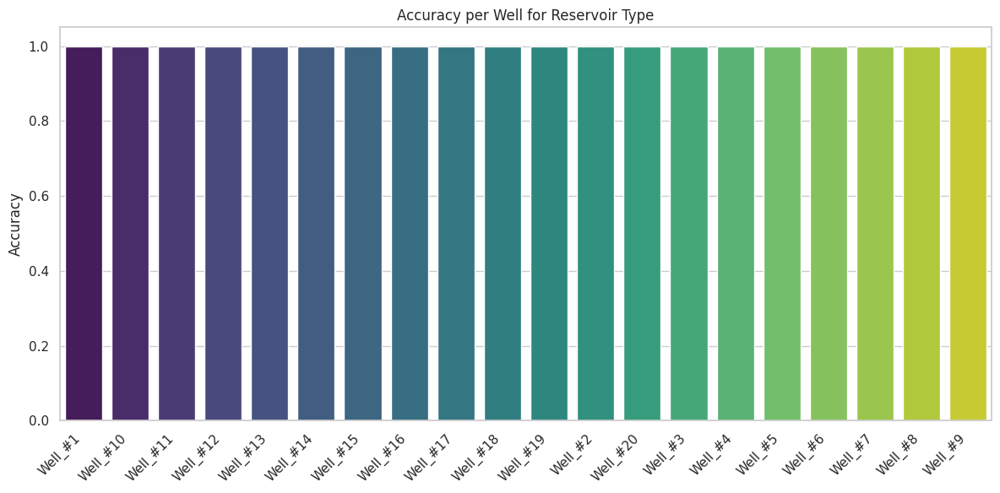

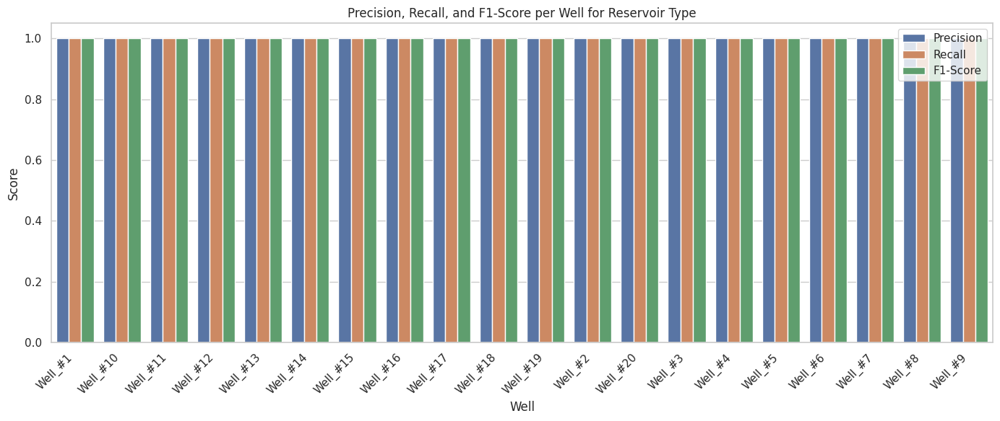

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


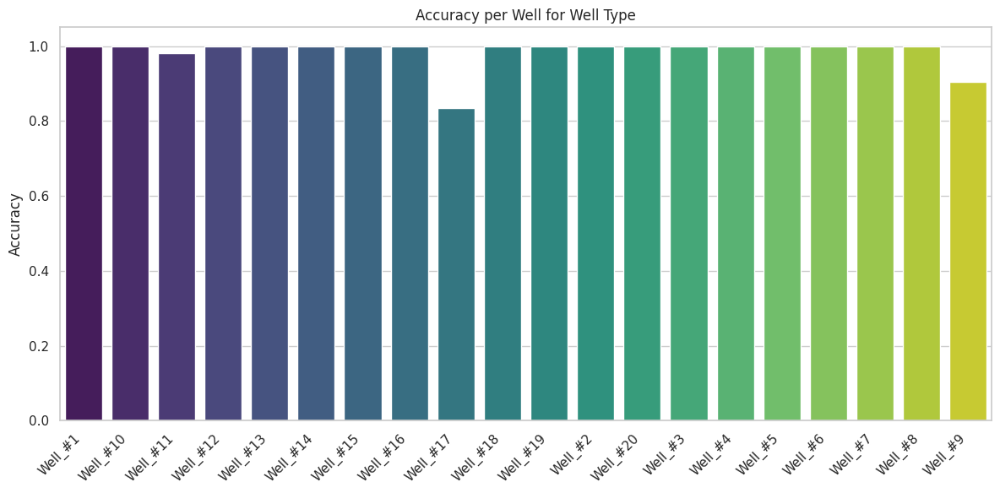

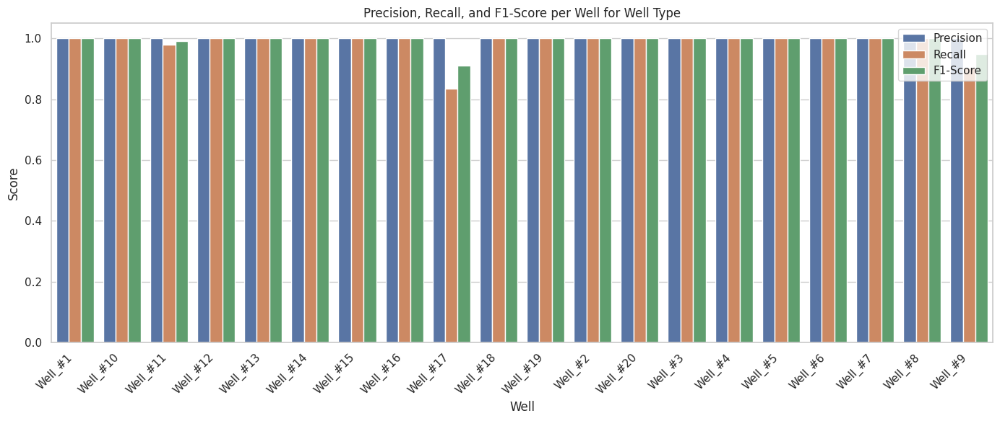

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


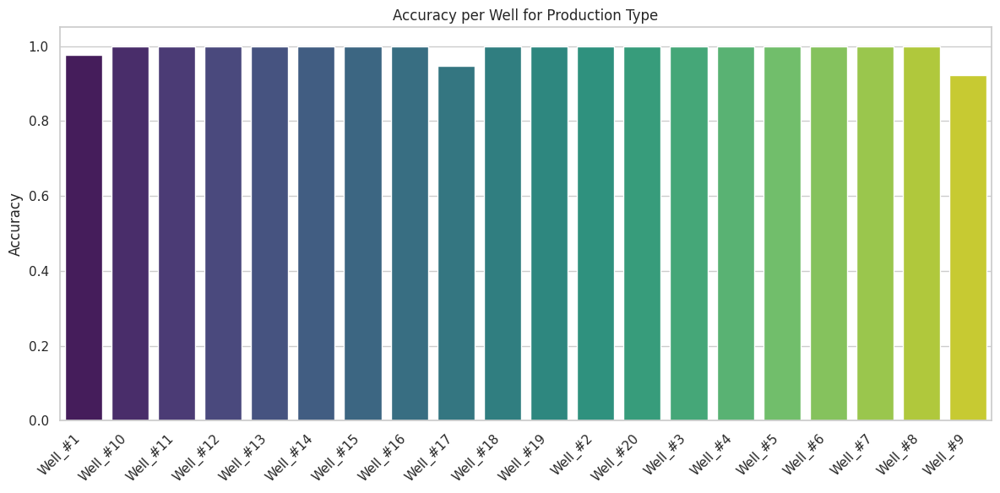

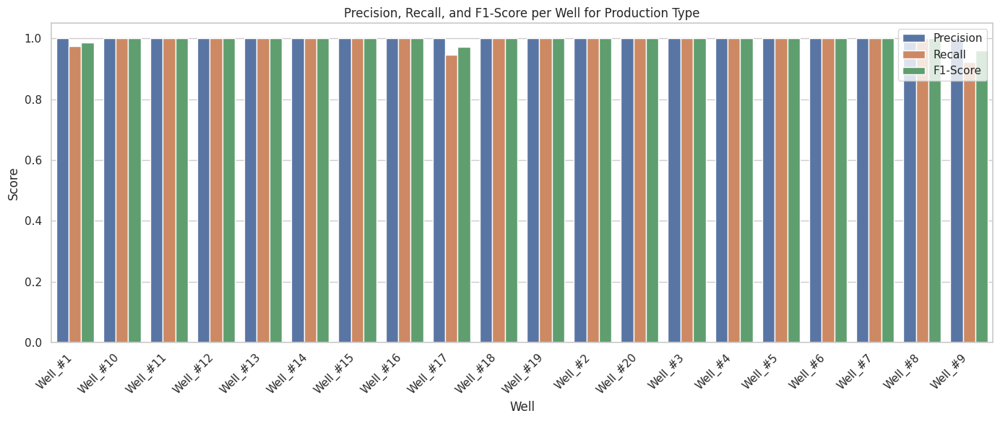

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


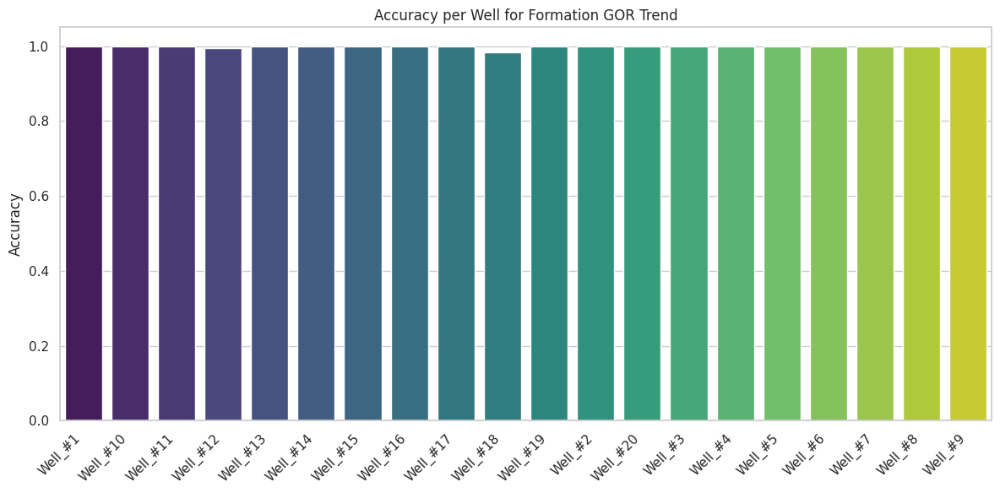

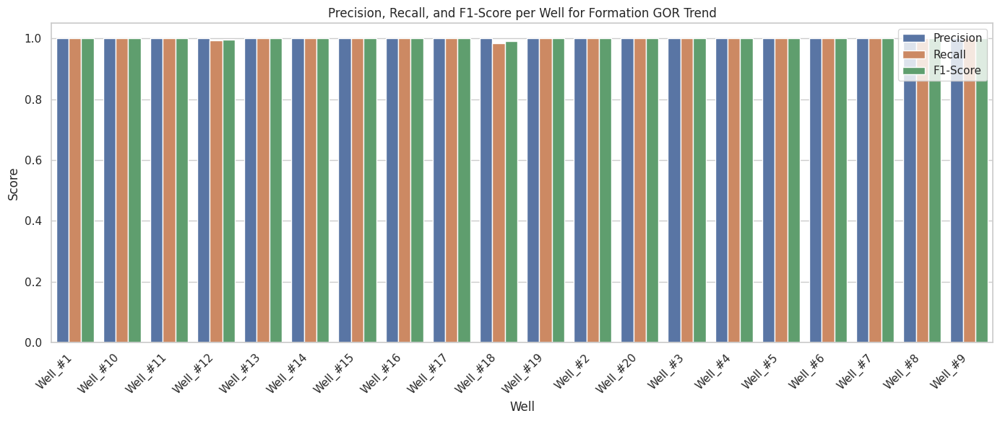

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


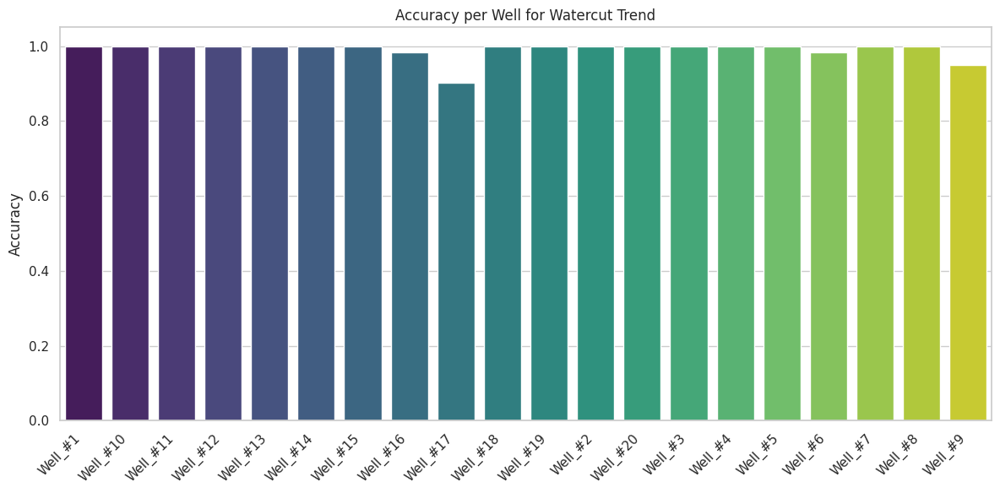

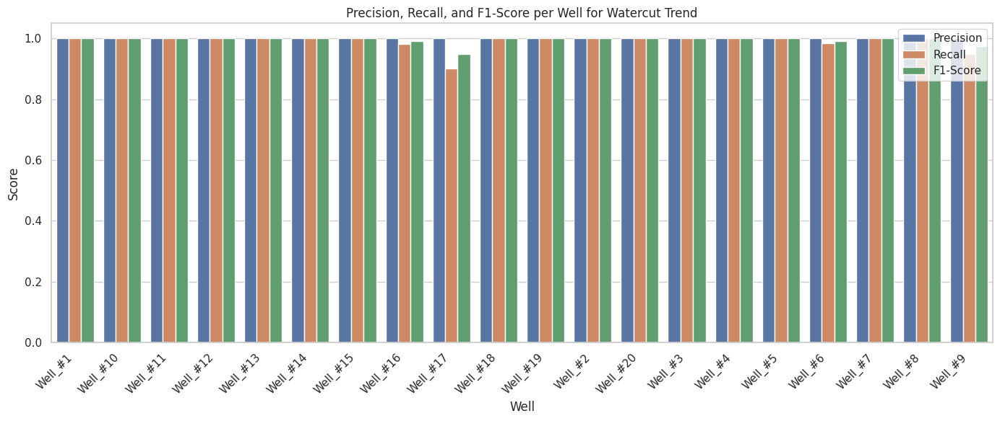

/tmp/ipython-input-6-2958895802.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


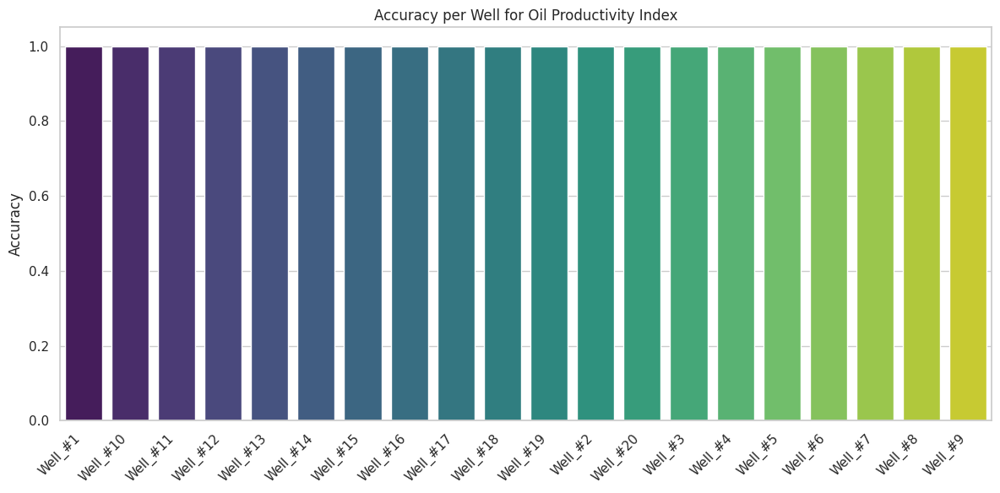

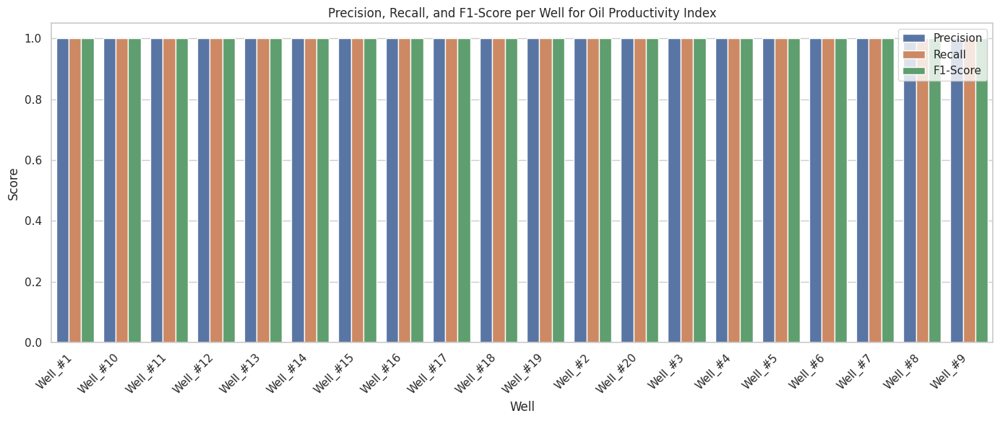

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Make plots pretty
sns.set(style='whitegrid')

def plot_well_metrics(results):
    for target, result_data in results.items():
        well_results = result_data['per_well']
        if not well_results:
            continue

        wells, accs, precs, recs, f1s = zip(*well_results)

        # Plot Accuracy per Well
        plt.figure(figsize=(12, 6))
        sns.barplot(x=wells, y=accs, palette='viridis')
        plt.title(f'Accuracy per Well for {target}')
        plt.ylabel('Accuracy')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

        # Stacked Metrics per Well
        df_plot = pd.DataFrame({
            'Well': wells,
            'Precision': precs,
            'Recall': recs,
            'F1-Score': f1s
        }).melt(id_vars='Well', var_name='Metric', value_name='Score')

        plt.figure(figsize=(14, 6))
        sns.barplot(x='Well', y='Score', hue='Metric', data=df_plot)
        plt.title(f'Precision, Recall, and F1-Score per Well for {target}')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.legend(loc='upper right')
        plt.show()

# Call the function after training
plot_well_metrics(results)



Target: Reservoir Type


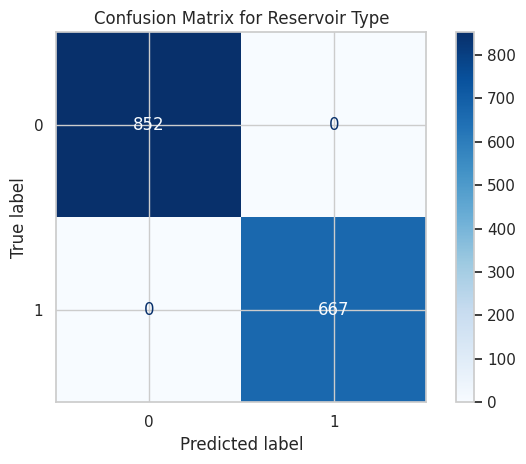

Overall Accuracy: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       852
           1       1.00      1.00      1.00       667

    accuracy                           1.00      1519
   macro avg       1.00      1.00      1.00      1519
weighted avg       1.00      1.00      1.00      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14             1.0000     1.0000     1.0000   1.0000    
Well_#15             1.0000     1.0000     1.0000   1.0000    

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


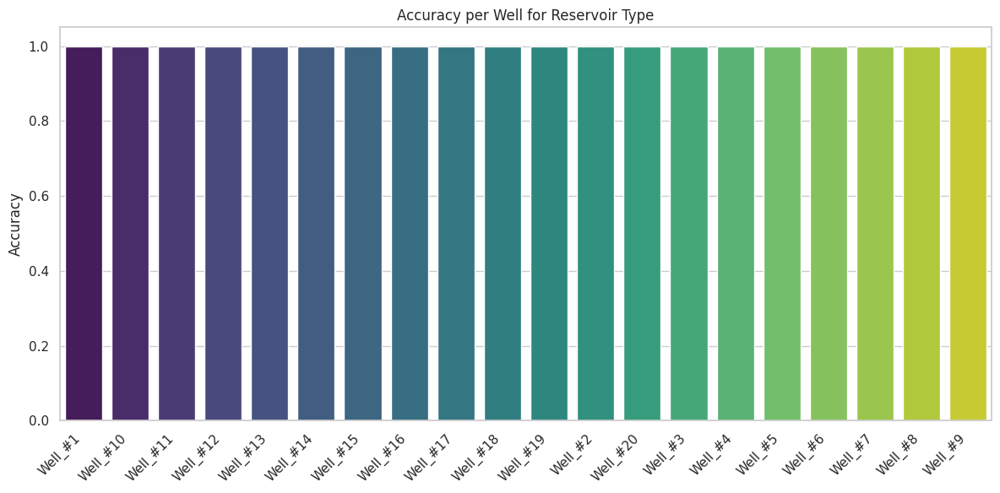

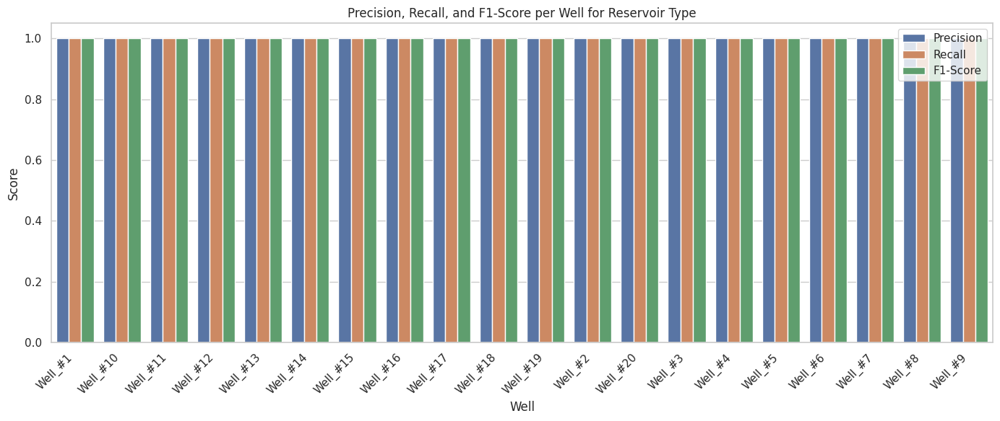


Target: Well Type


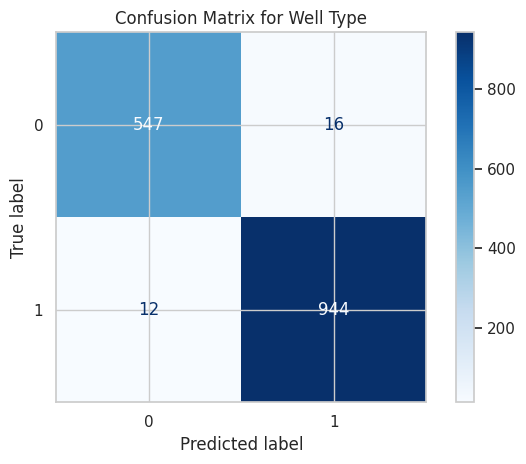

Overall Accuracy: 0.9816

              precision    recall  f1-score   support

           0       0.98      0.97      0.98       563
           1       0.98      0.99      0.99       956

    accuracy                           0.98      1519
   macro avg       0.98      0.98      0.98      1519
weighted avg       0.98      0.98      0.98      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             0.9808     1.0000     0.9808   0.9903    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14             1.0000     1.0000     1.0000   1.0000    
Well_#15             1.0000     1.0000     1.0000   1.0000    

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


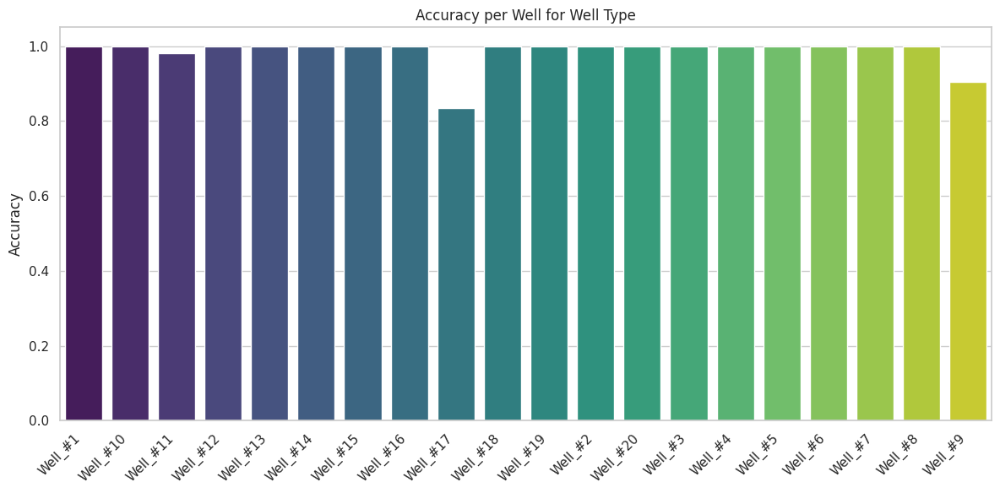

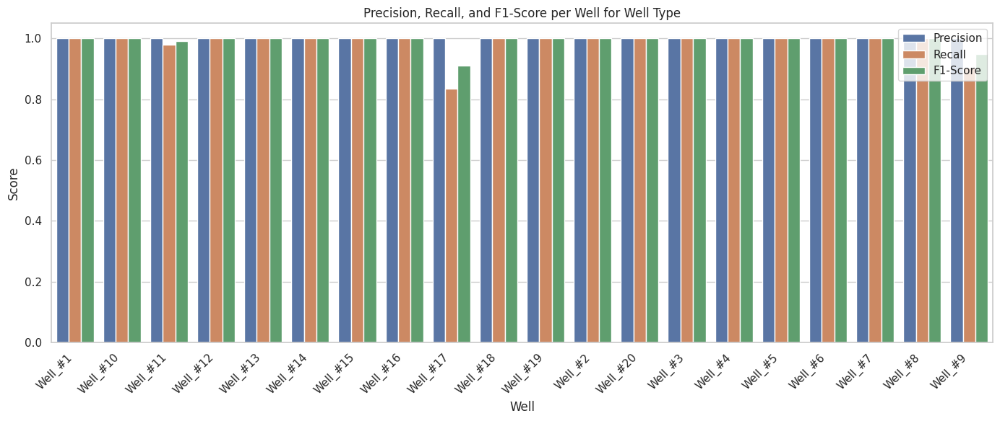


Target: Production Type


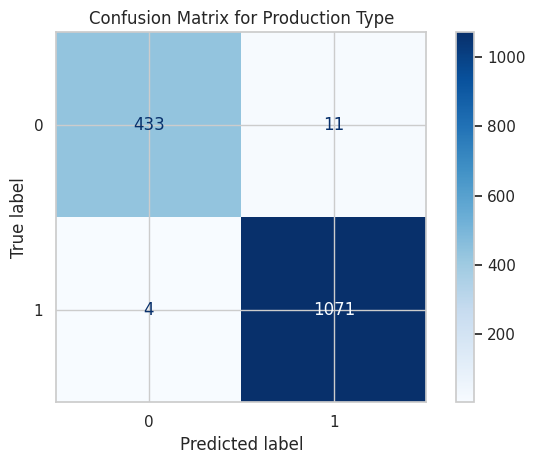

Overall Accuracy: 0.9901

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       444
           1       0.99      1.00      0.99      1075

    accuracy                           0.99      1519
   macro avg       0.99      0.99      0.99      1519
weighted avg       0.99      0.99      0.99      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              0.9756     1.0000     0.9756   0.9877    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14             1.0000     1.0000     1.0000   1.0000    
Well_#15             1.0000     1.0000     1.0000   1.0000    

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


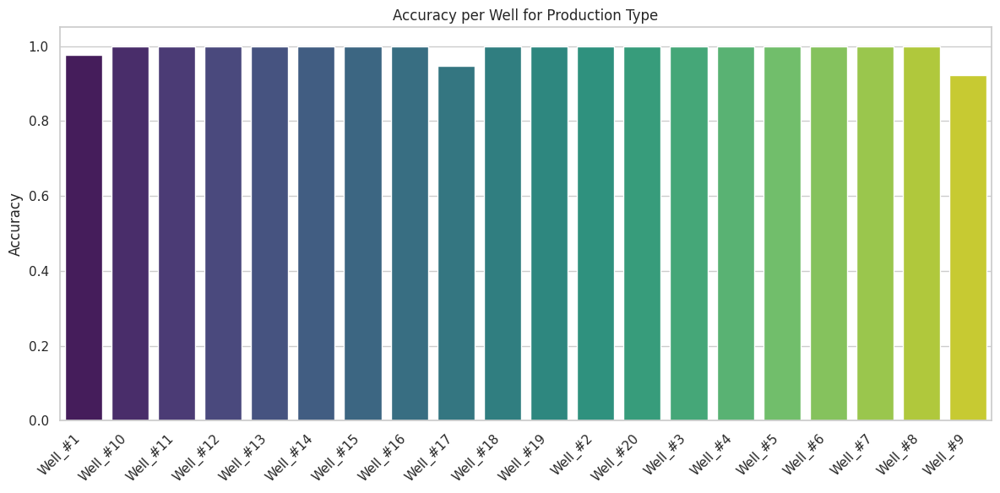

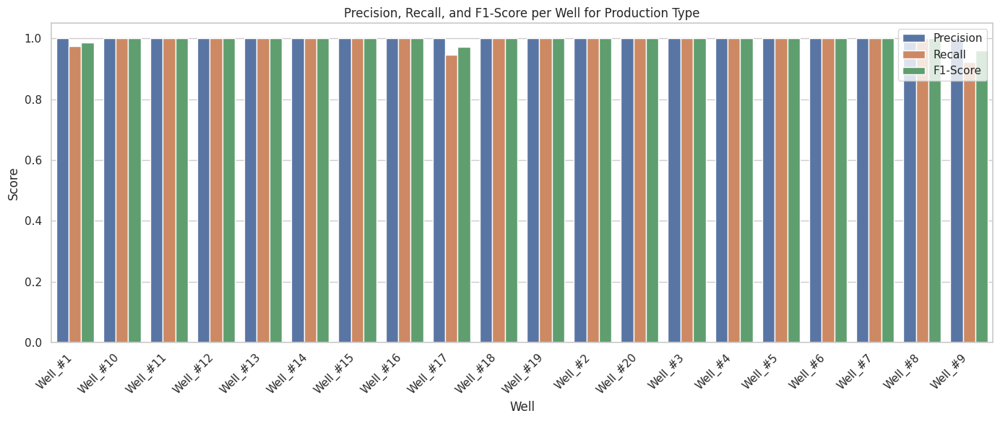


Target: Formation GOR Trend


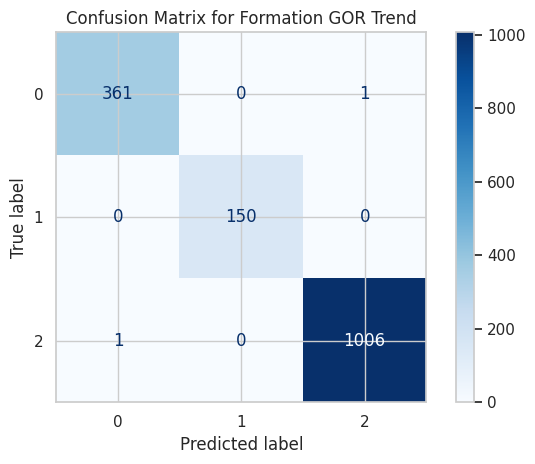

Overall Accuracy: 0.9987

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       362
           1       1.00      1.00      1.00       150
           2       1.00      1.00      1.00      1007

    accuracy                           1.00      1519
   macro avg       1.00      1.00      1.00      1519
weighted avg       1.00      1.00      1.00      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             0.9935     1.0000     0.9935   0.9967    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14             1.0000     1.0000     1.0000   1.0000    
Well_#15

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


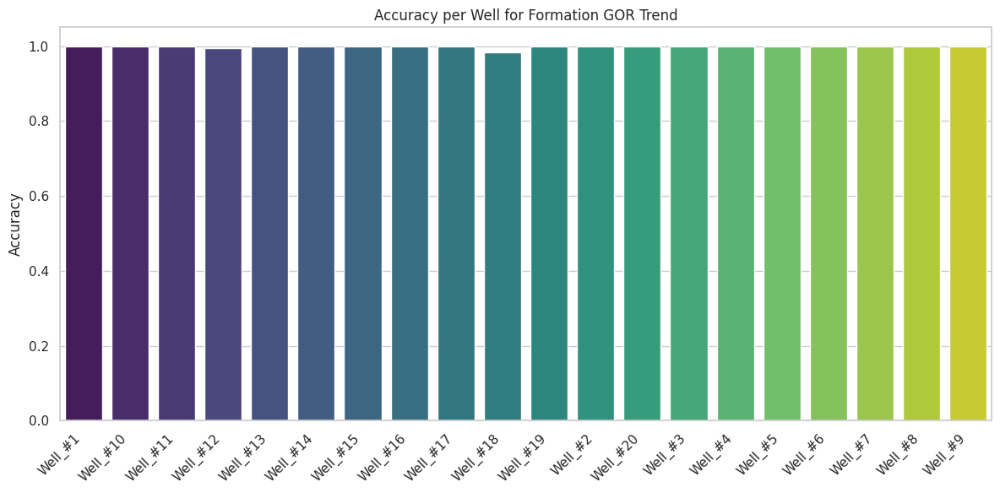

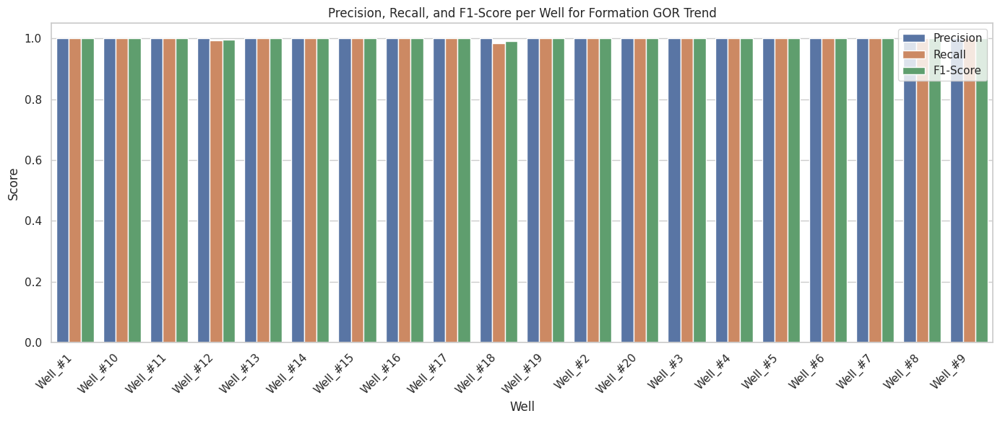


Target: Watercut Trend


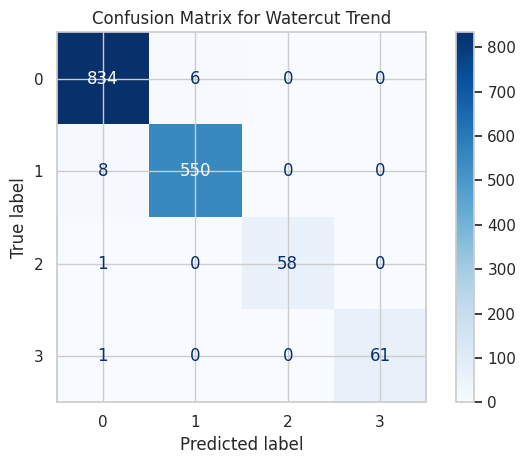

Overall Accuracy: 0.9895

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       840
           1       0.99      0.99      0.99       558
           2       1.00      0.98      0.99        59
           3       1.00      0.98      0.99        62

    accuracy                           0.99      1519
   macro avg       0.99      0.99      0.99      1519
weighted avg       0.99      0.99      0.99      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14         

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


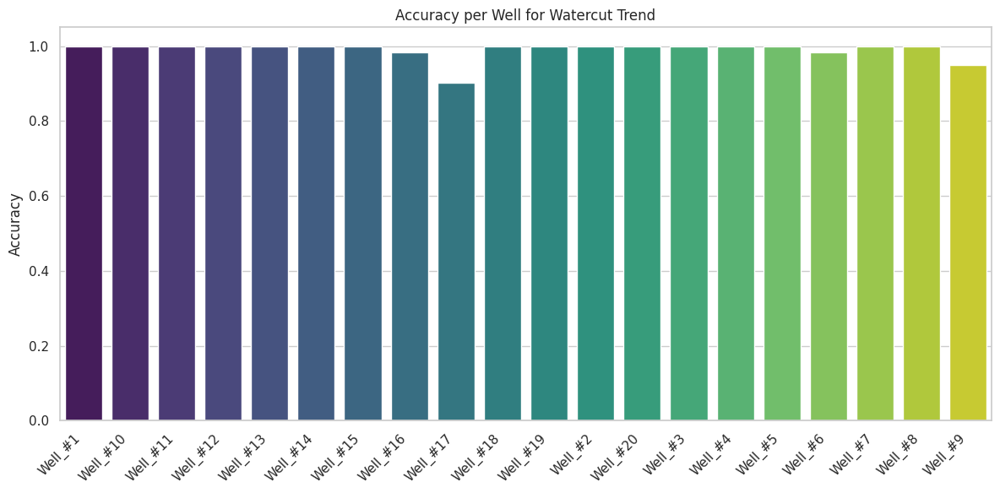

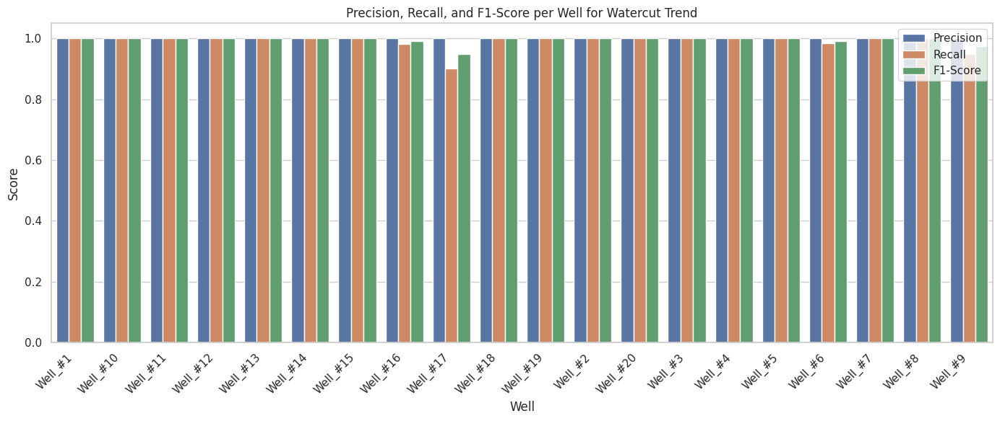


Target: Oil Productivity Index


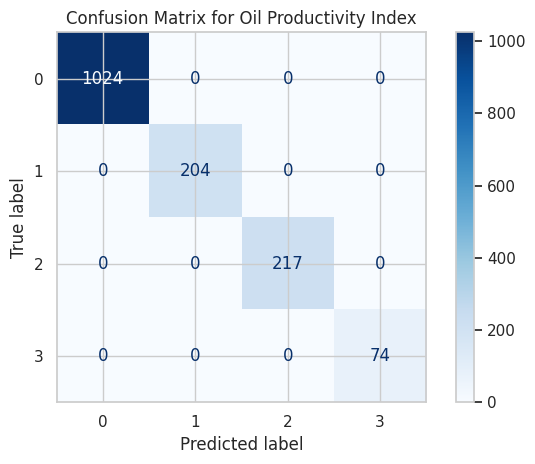

Overall Accuracy: 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1024
           1       1.00      1.00      1.00       204
           2       1.00      1.00      1.00       217
           3       1.00      1.00      1.00        74

    accuracy                           1.00      1519
   macro avg       1.00      1.00      1.00      1519
weighted avg       1.00      1.00      1.00      1519

Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    
Well_#10             1.0000     1.0000     1.0000   1.0000    
Well_#11             1.0000     1.0000     1.0000   1.0000    
Well_#12             1.0000     1.0000     1.0000   1.0000    
Well_#13             1.0000     1.0000     1.0000   1.0000    
Well_#14         

/tmp/ipython-input-7-2985741756.py:124: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


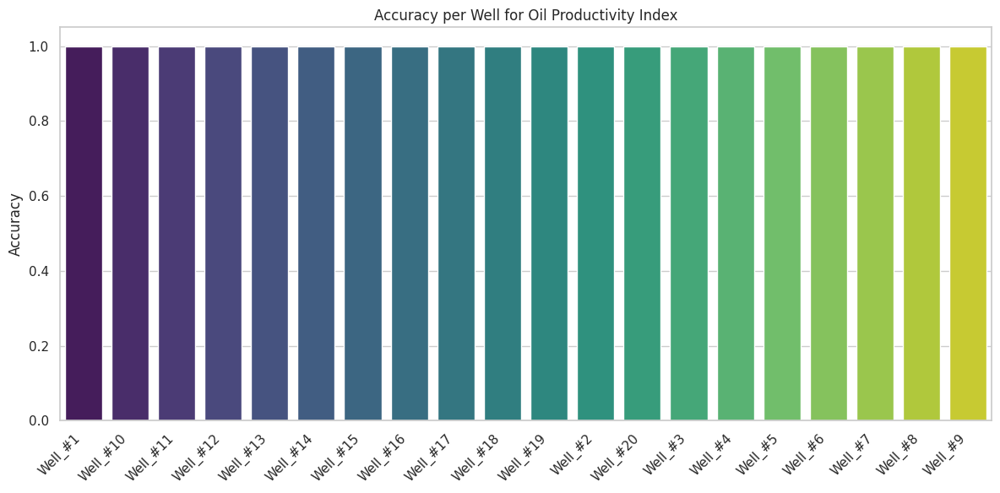

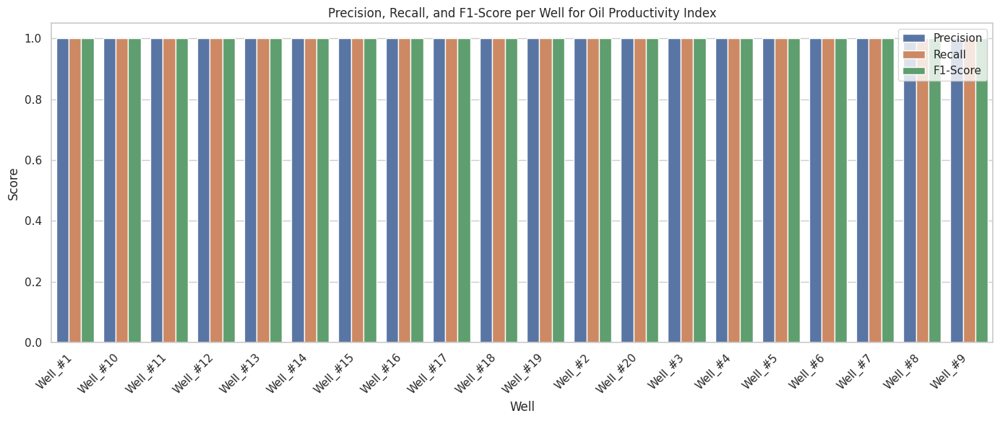

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Pretty plot style
sns.set(style='whitegrid')

# Define target columns
target_columns = [
    'Reservoir Type',
    'Well Type',
    'Production Type',
    'Formation GOR Trend',
    'Watercut Trend',
    'Oil Productivity Index'
]

# Exclude target and non-feature columns
excluded_columns = target_columns + ['WELL_NAME', 'PROD_DATE']
feature_columns = [col for col in df.columns if col not in excluded_columns]

# Encode non-numeric feature columns
df_encoded = df.copy()
label_encoders = {}

for col in feature_columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        label_encoders[col] = le

# Encode WELL_NAME
df_encoded['WELL_NAME'] = df['WELL_NAME'].astype(str)

# === MAIN FUNCTION ===
def train_evaluate_by_target(df, target_columns, feature_columns):
    results = {}

    for target in target_columns:
        print(f"\nTarget: {target}\n" + "="*len(f"Target: {target}"))

        df_filtered = df.dropna(subset=[target])
        X = df_filtered[feature_columns]
        y = df_filtered[target]
        wells = df_filtered['WELL_NAME']

        # Encode target if object
        if y.dtype == 'object':
            y = pd.factorize(y)[0]

        # Split data
        X_train_val, X_test, y_train_val, y_test, wells_train_val, wells_test = train_test_split(
            X, y, wells, test_size=0.2, random_state=42, stratify=y
        )
        X_train, X_val, y_train, y_val, wells_train, wells_val = train_test_split(
            X_train_val, y_train_val, wells_train_val, test_size=0.25, random_state=42, stratify=y_train_val
        )

        # Train model
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        # Confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(cmap='Blues')
        plt.title(f'Confusion Matrix for {target}')
        plt.tight_layout()
        plt.show()

        # Classification report
        report = classification_report(y_test, y_pred, zero_division=0)
        acc = accuracy_score(y_test, y_pred)
        print(f"Overall Accuracy: {acc:.4f}\n")
        print(report)

        # Per-well metrics
        print(f"Well-by-Well Results:")
        print("-" * 60)
        print(f"{'Well':<20} {'Accuracy':<10} {'Precision':<10} {'Recall':<8} {'F1-Score':<10}")
        print("-" * 60)

        well_results = []
        for well in np.unique(wells_test):
            idx = wells_test == well
            if sum(idx) < 2:
                continue
            y_true = y_test[idx]
            y_pred_well = y_pred[idx]

            acc = accuracy_score(y_true, y_pred_well)
            prec = precision_score(y_true, y_pred_well, average='weighted', zero_division=0)
            rec = recall_score(y_true, y_pred_well, average='weighted', zero_division=0)
            f1 = f1_score(y_true, y_pred_well, average='weighted', zero_division=0)

            well_results.append((well, acc, prec, rec, f1))
            print(f"{well:<20} {acc:<10.4f} {prec:<10.4f} {rec:<8.4f} {f1:<10.4f}")

        results[target] = {
            'overall': {
                'accuracy': acc,
                'report': report
            },
            'per_well': well_results
        }

        # Plot metrics per well
        if well_results:
            wells, accs, precs, recs, f1s = zip(*well_results)

            # Accuracy per Well
            plt.figure(figsize=(12, 6))
            sns.barplot(x=wells, y=accs, palette='viridis')
            plt.title(f'Accuracy per Well for {target}')
            plt.ylabel('Accuracy')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()

            # Precision/Recall/F1
            df_plot = pd.DataFrame({
                'Well': wells,
                'Precision': precs,
                'Recall': recs,
                'F1-Score': f1s
            }).melt(id_vars='Well', var_name='Metric', value_name='Score')

            plt.figure(figsize=(14, 6))
            sns.barplot(x='Well', y='Score', hue='Metric', data=df_plot)
            plt.title(f'Precision, Recall, and F1-Score per Well for {target}')
            plt.xticks(rotation=45, ha='right')
            plt.legend(loc='upper right')
            plt.tight_layout()
            plt.show()

    return results

# Run the full pipeline
results = train_evaluate_by_target(df_encoded, target_columns, feature_columns)


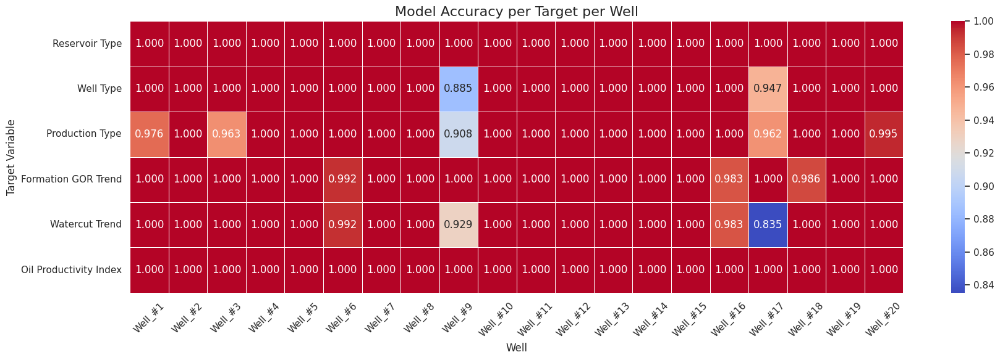

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Paste your metrics into a structured dictionary:
results_dict = {
    "Reservoir Type": {
        "Well_#1": 1.0000, "Well_#2": 1.0000, "Well_#3": 1.0000, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 1.0000, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 1.0000, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 1.0000, "Well_#17": 1.0000, "Well_#18": 1.0000, "Well_#19": 1.0000, "Well_#20": 1.0000
    },
    "Well Type": {
        "Well_#1": 1.0000, "Well_#2": 1.0000, "Well_#3": 1.0000, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 1.0000, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 0.8852, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 1.0000, "Well_#17": 0.9474, "Well_#18": 1.0000, "Well_#19": 1.0000, "Well_#20": 1.0000
    },
    "Production Type": {
        "Well_#1": 0.9756, "Well_#2": 1.0000, "Well_#3": 0.9630, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 1.0000, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 0.9077, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 1.0000, "Well_#17": 0.9620, "Well_#18": 1.0000, "Well_#19": 1.0000, "Well_#20": 0.9945
    },
    "Formation GOR Trend": {
        "Well_#1": 1.0000, "Well_#2": 1.0000, "Well_#3": 1.0000, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 0.9923, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 1.0000, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 0.9828, "Well_#17": 1.0000, "Well_#18": 0.9863, "Well_#19": 1.0000, "Well_#20": 1.0000
    },
    "Watercut Trend": {
        "Well_#1": 1.0000, "Well_#2": 1.0000, "Well_#3": 1.0000, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 0.9924, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 0.9286, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 0.9831, "Well_#17": 0.8352, "Well_#18": 1.0000, "Well_#19": 1.0000, "Well_#20": 1.0000
    },
    "Oil Productivity Index": {
        "Well_#1": 1.0000, "Well_#2": 1.0000, "Well_#3": 1.0000, "Well_#4": 1.0000, "Well_#5": 1.0000,
        "Well_#6": 1.0000, "Well_#7": 1.0000, "Well_#8": 1.0000, "Well_#9": 1.0000, "Well_#10": 1.0000,
        "Well_#11": 1.0000, "Well_#12": 1.0000, "Well_#13": 1.0000, "Well_#14": 1.0000, "Well_#15": 1.0000,
        "Well_#16": 1.0000, "Well_#17": 1.0000, "Well_#18": 1.0000, "Well_#19": 1.0000, "Well_#20": 1.0000
    }
}

# Convert dictionary to DataFrame
heatmap_df = pd.DataFrame(results_dict).T  # Transpose for wells as columns
heatmap_df.columns.name = "Well"
heatmap_df.index.name = "Target"

# Plot heatmap
plt.figure(figsize=(18, 6))
sns.heatmap(heatmap_df, annot=True, fmt=".3f", cmap="coolwarm", linewidths=0.5)
plt.title("Model Accuracy per Target per Well", fontsize=16)
plt.xlabel("Well", fontsize=12)
plt.ylabel("Target Variable", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


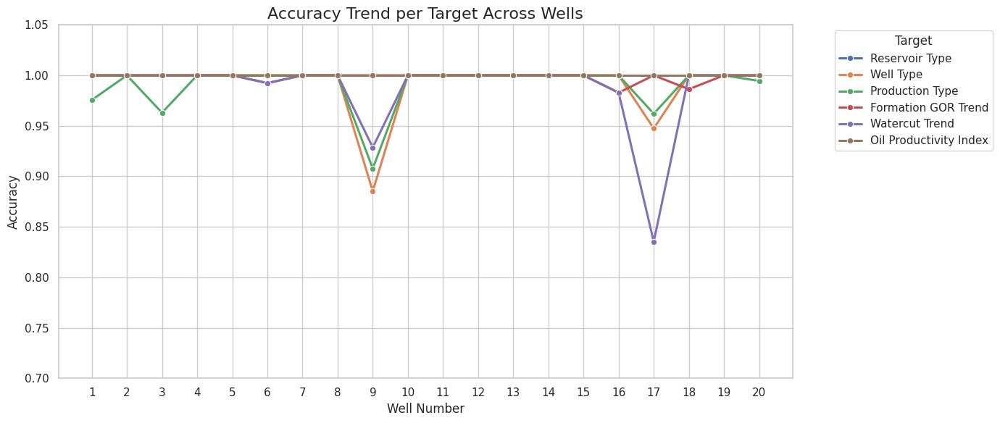

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Provided results_dict remains unchanged
# Convert to long format for line plotting
df_trend = pd.DataFrame(results_dict).T  # Target as rows, Wells as columns
df_trend.index.name = "Target"
df_trend.columns.name = "Well"

# Reset and melt for seaborn lineplot
df_long = df_trend.reset_index().melt(id_vars='Target', var_name='Well', value_name='Accuracy')

# Optional: Ensure well order (sorted numerically)
df_long['Well_Num'] = df_long['Well'].str.extract(r'(\d+)').astype(int)
df_long = df_long.sort_values(by='Well_Num')

# Plot trend lines
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_long, x='Well_Num', y='Accuracy', hue='Target', marker='o', linewidth=2.2)

plt.title("Accuracy Trend per Target Across Wells", fontsize=16)
plt.xlabel("Well Number", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(df_long['Well_Num'].unique())
plt.ylim(0.7, 1.05)
plt.grid(True)
plt.legend(title="Target", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


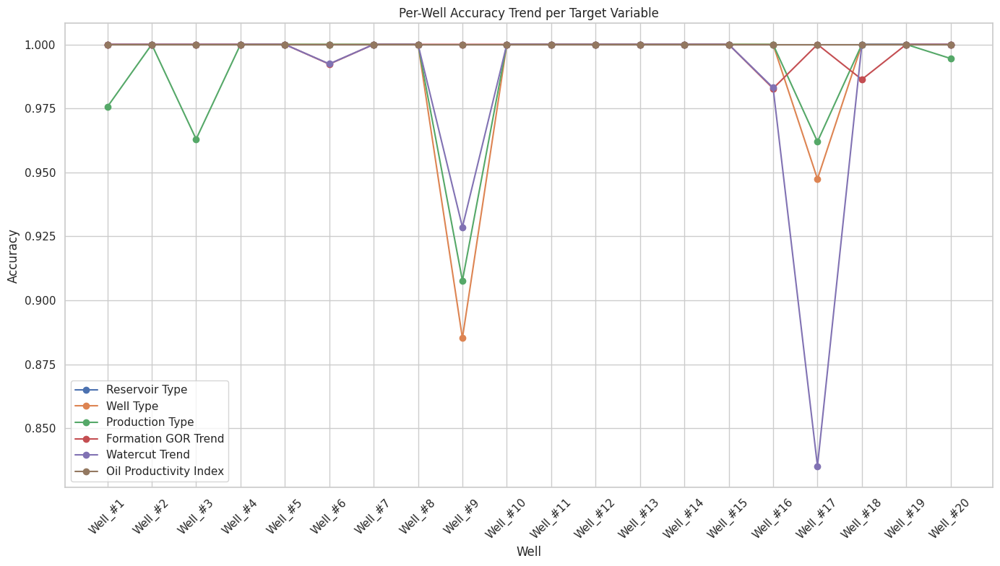

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Define the well names
wells = [f"Well_#{i}" for i in range(1, 21)]

plt.figure(figsize=(14, 8))

for target in results_dict.keys():
    acc_per_well = []
    for well in wells:
        acc = results_dict[target].get(well, None)  # Expecting float directly
        acc_per_well.append(acc if acc is not None else np.nan)  # Fill missing with NaN
    plt.plot(wells, acc_per_well, marker='o', label=target)

plt.xticks(rotation=45)
plt.xlabel("Well")
plt.ylabel("Accuracy")
plt.title("Per-Well Accuracy Trend per Target Variable")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



 Target: Reservoir Type


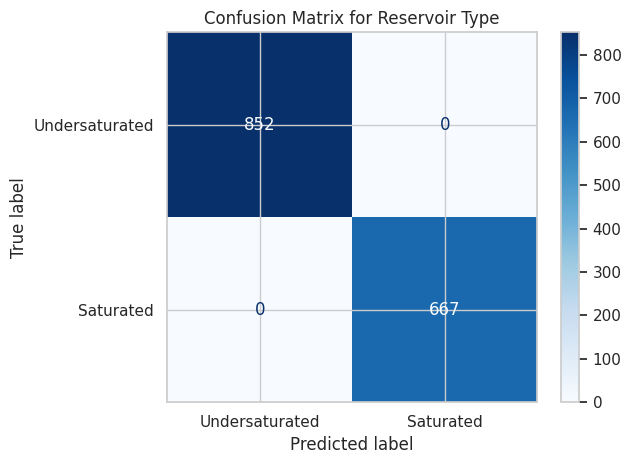

 Overall Accuracy: 1.0000

                precision    recall  f1-score   support

Undersaturated       1.00      1.00      1.00       852
     Saturated       1.00      1.00      1.00       667

      accuracy                           1.00      1519
     macro avg       1.00      1.00      1.00      1519
  weighted avg       1.00      1.00      1.00      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    


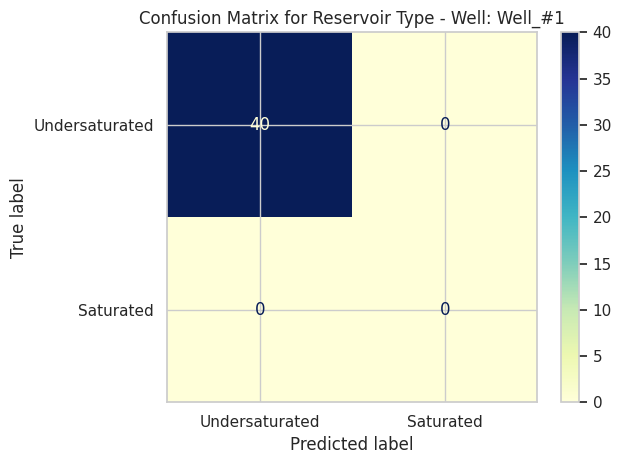

Well_#10             1.0000     1.0000     1.0000   1.0000    


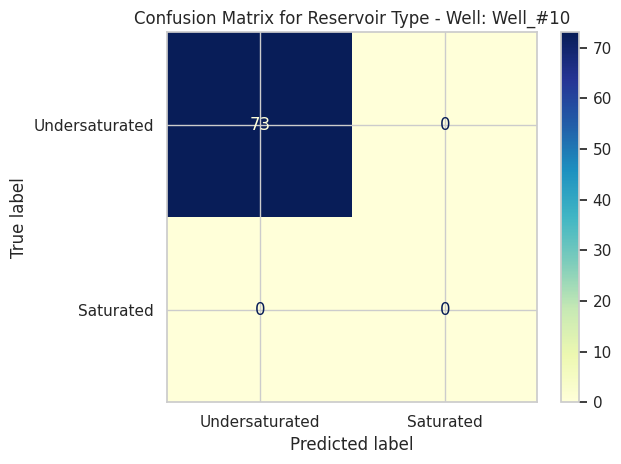

Well_#11             1.0000     1.0000     1.0000   1.0000    


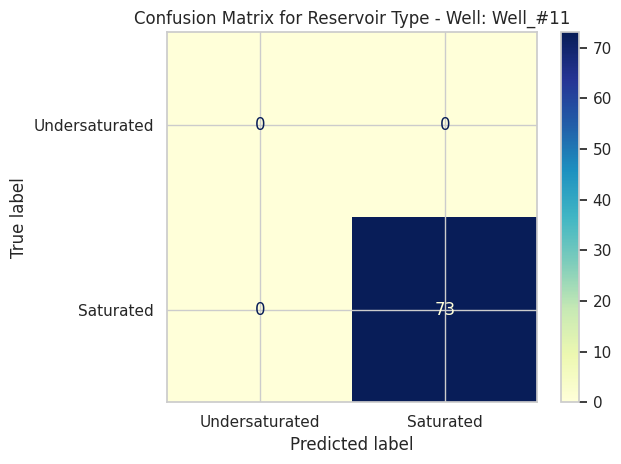

Well_#12             1.0000     1.0000     1.0000   1.0000    


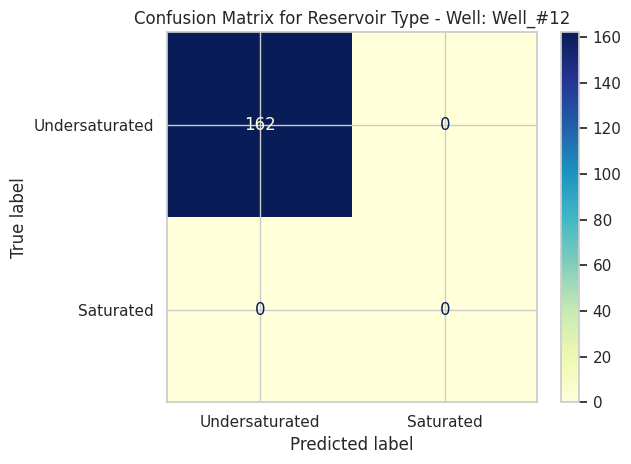

Well_#13             1.0000     1.0000     1.0000   1.0000    


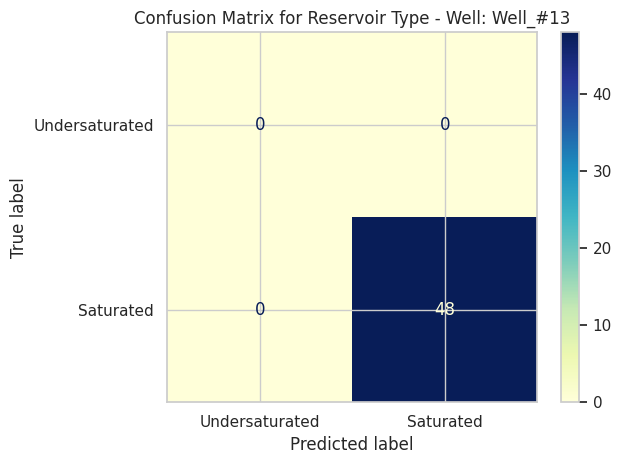

Well_#14             1.0000     1.0000     1.0000   1.0000    


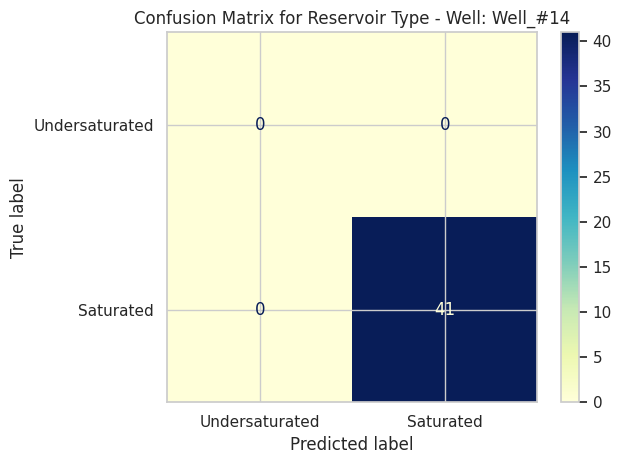

Well_#15             1.0000     1.0000     1.0000   1.0000    


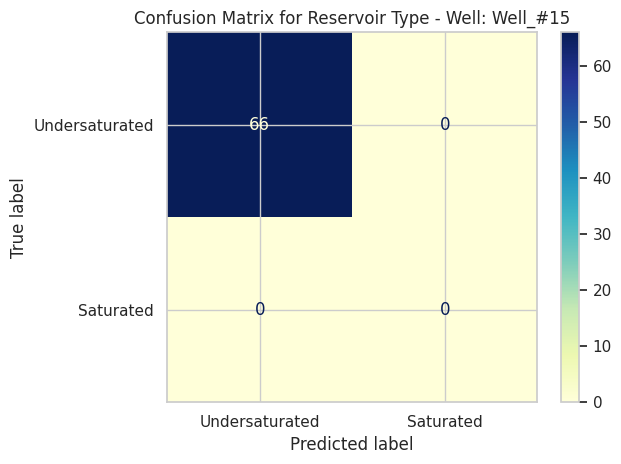

Well_#16             1.0000     1.0000     1.0000   1.0000    


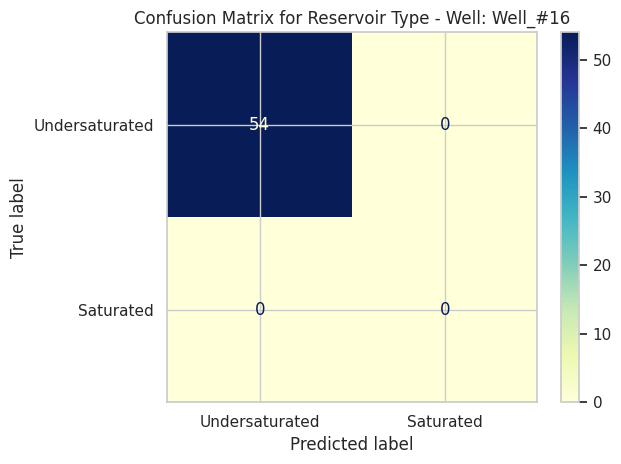

Well_#17             1.0000     1.0000     1.0000   1.0000    


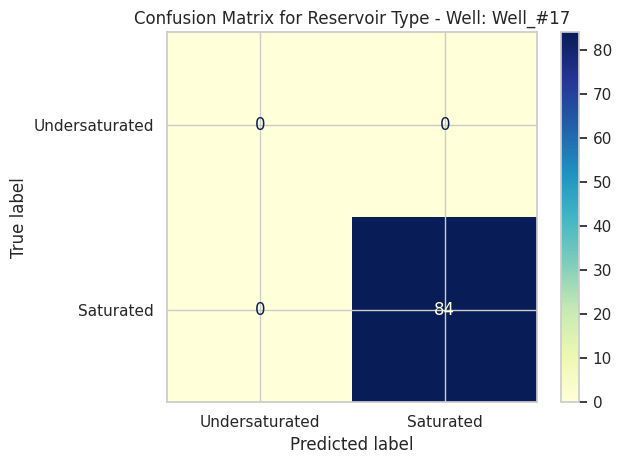

Well_#18             1.0000     1.0000     1.0000   1.0000    


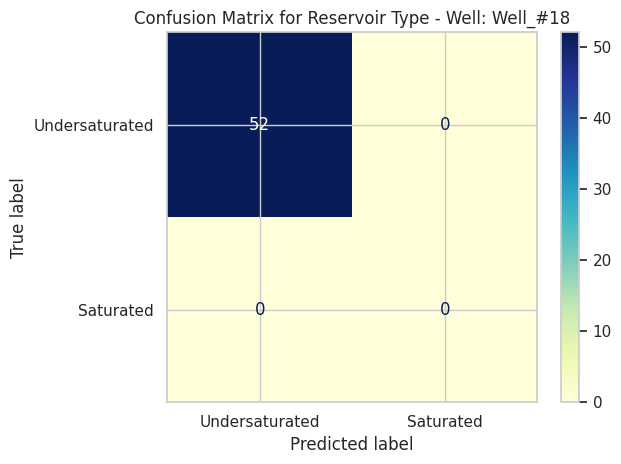

Well_#19             1.0000     1.0000     1.0000   1.0000    


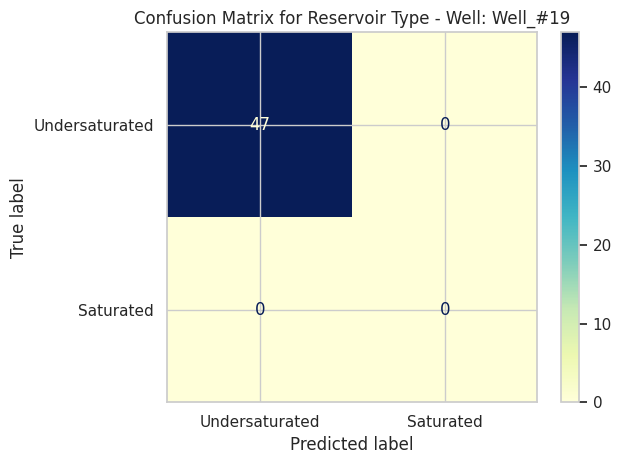

Well_#2              1.0000     1.0000     1.0000   1.0000    


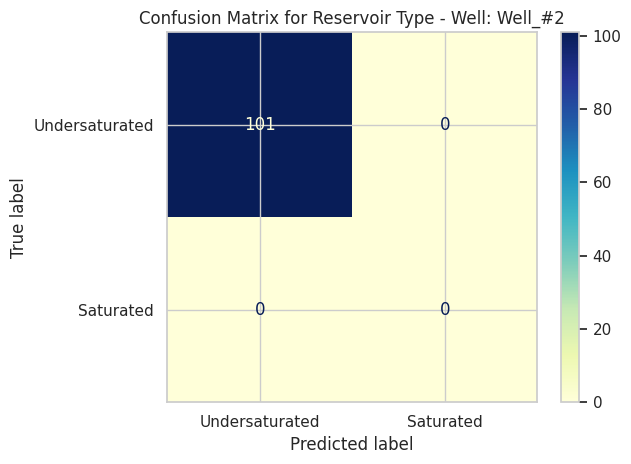

Well_#20             1.0000     1.0000     1.0000   1.0000    


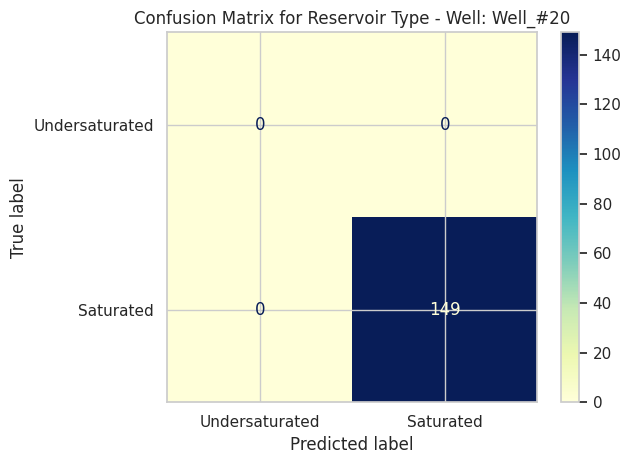

Well_#3              1.0000     1.0000     1.0000   1.0000    


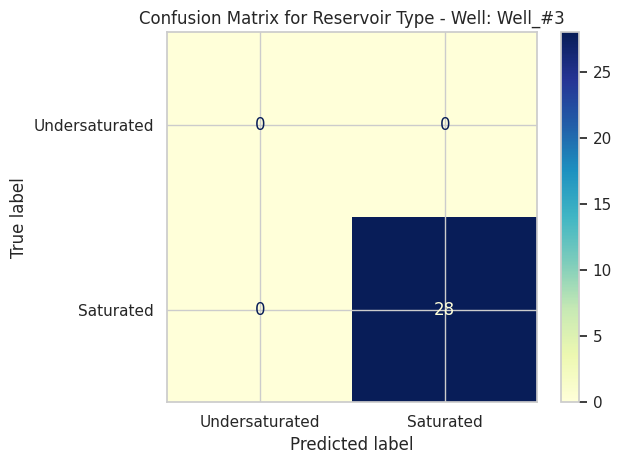

Well_#4              1.0000     1.0000     1.0000   1.0000    


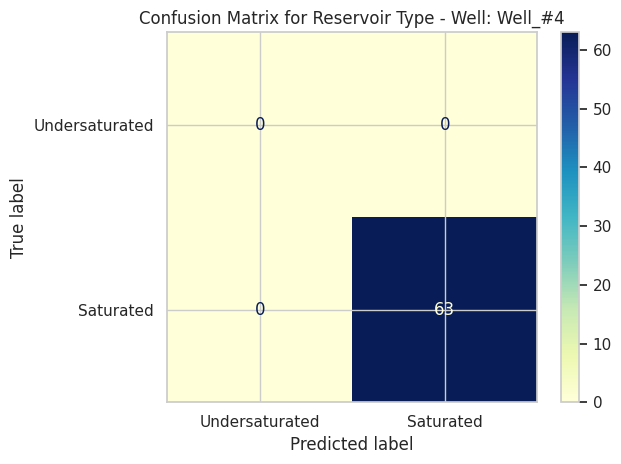

Well_#5              1.0000     1.0000     1.0000   1.0000    


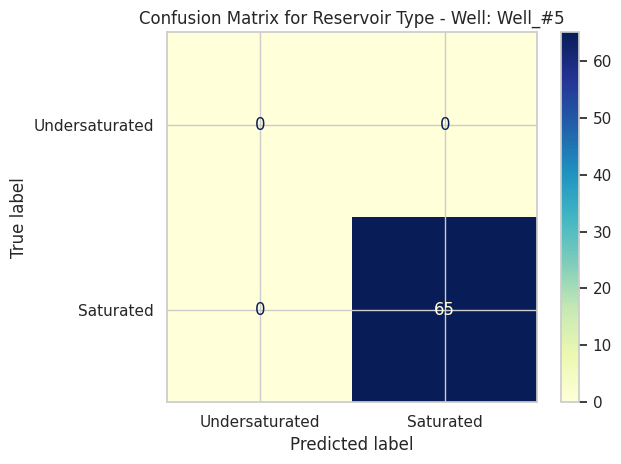

Well_#6              1.0000     1.0000     1.0000   1.0000    


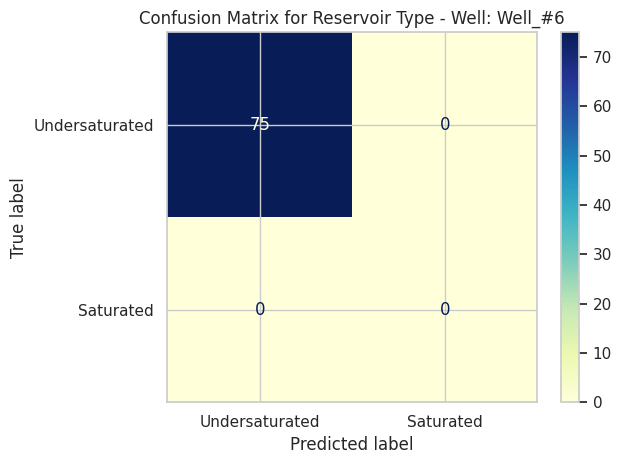

Well_#7              1.0000     1.0000     1.0000   1.0000    


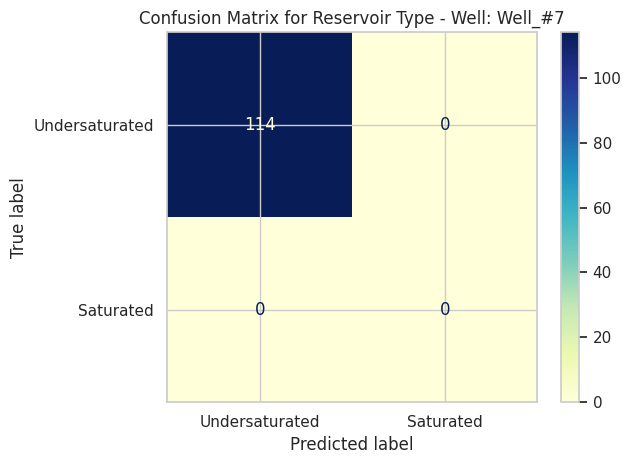

Well_#8              1.0000     1.0000     1.0000   1.0000    


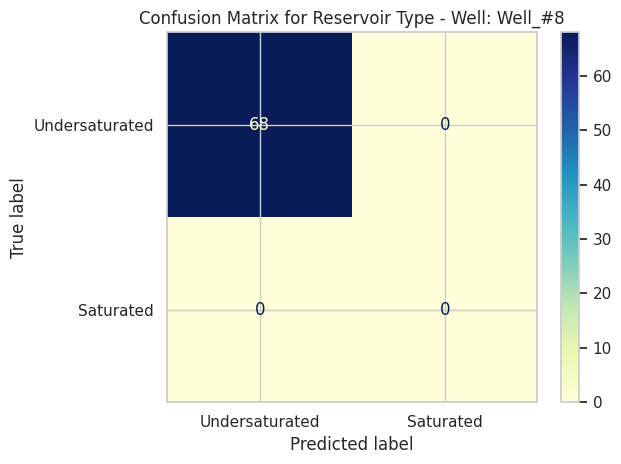

Well_#9              1.0000     1.0000     1.0000   1.0000    


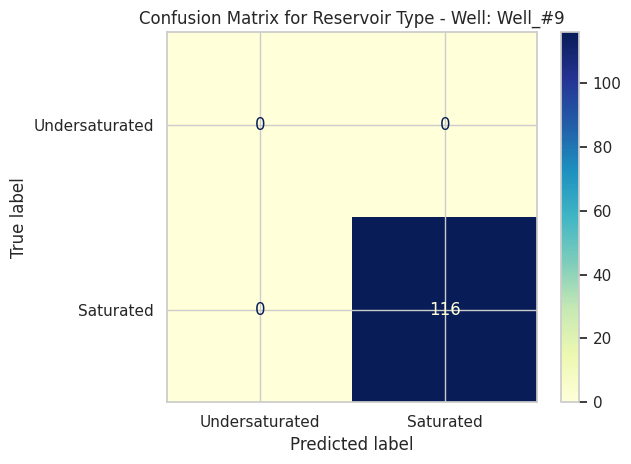

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


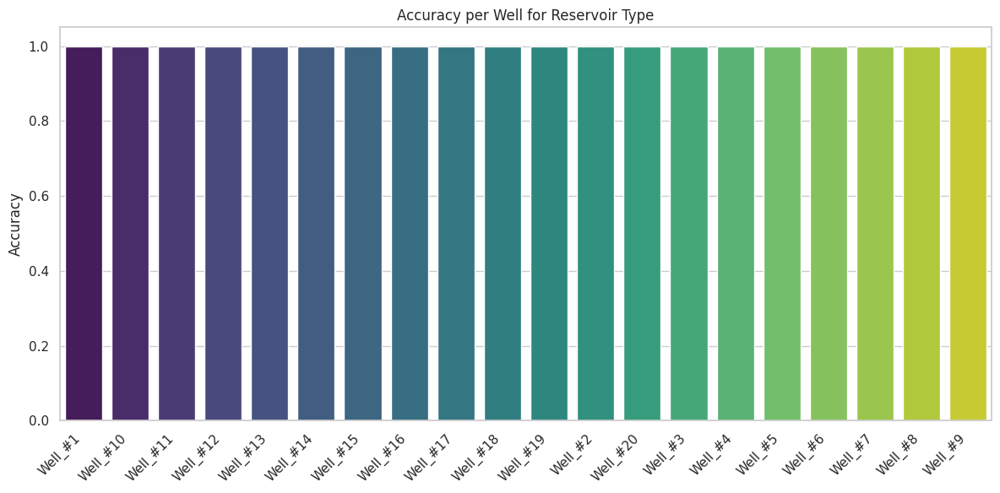

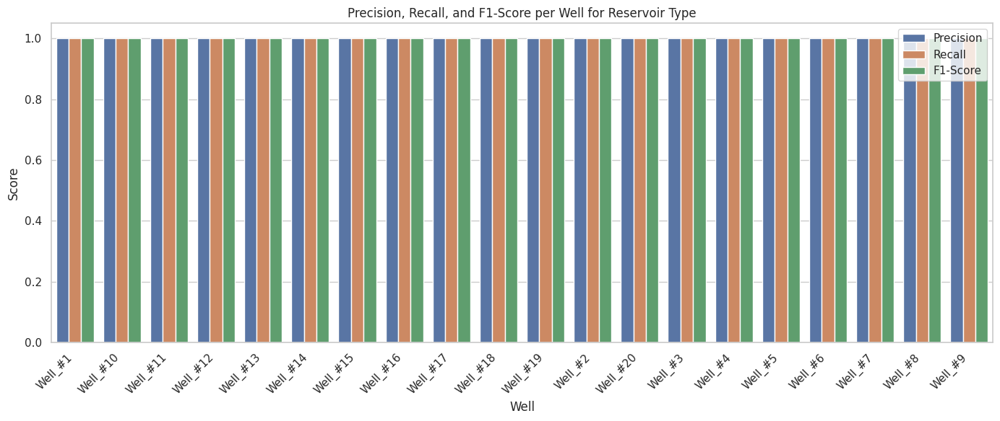


 Target: Well Type


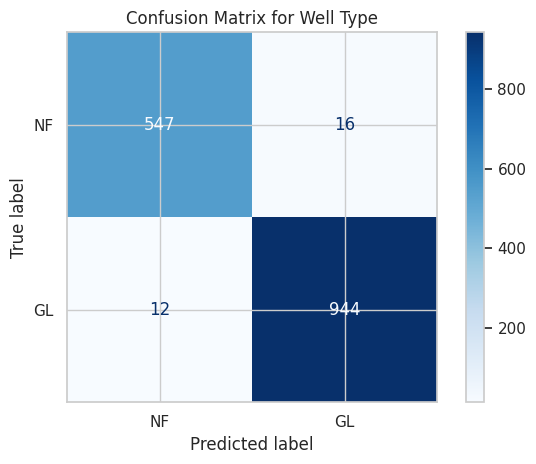

 Overall Accuracy: 0.9816

              precision    recall  f1-score   support

          NF       0.98      0.97      0.98       563
          GL       0.98      0.99      0.99       956

    accuracy                           0.98      1519
   macro avg       0.98      0.98      0.98      1519
weighted avg       0.98      0.98      0.98      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    


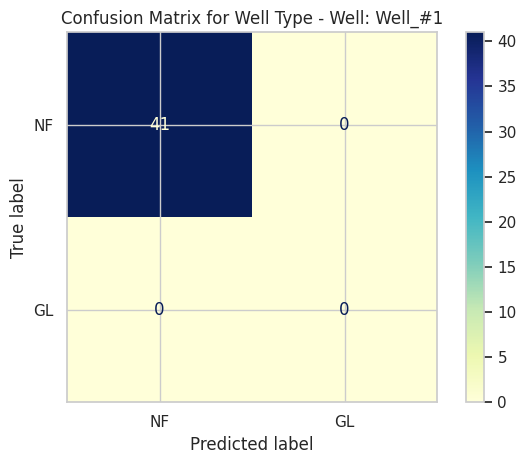

Well_#10             1.0000     1.0000     1.0000   1.0000    


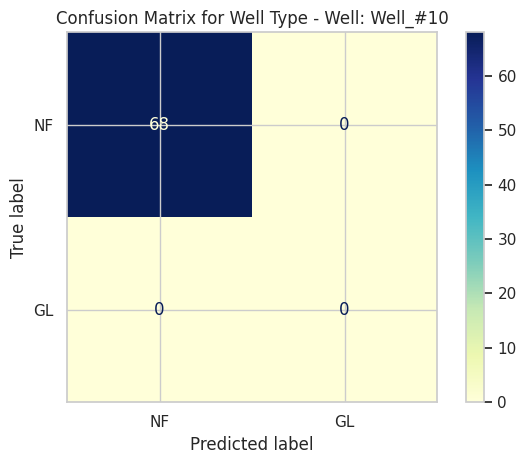

Well_#11             0.9808     1.0000     0.9808   0.9903    


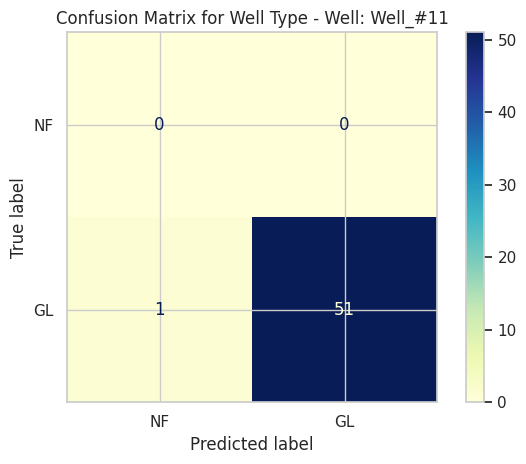

Well_#12             1.0000     1.0000     1.0000   1.0000    


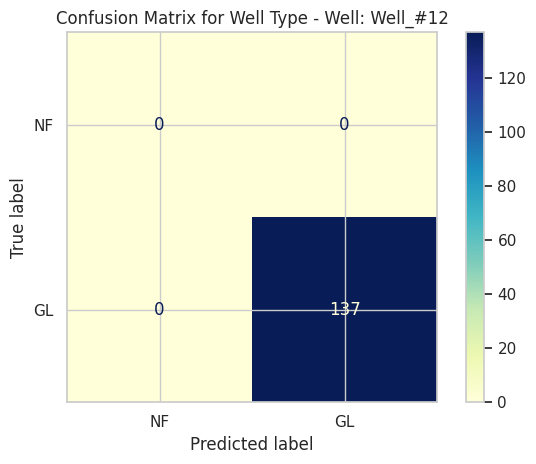

Well_#13             1.0000     1.0000     1.0000   1.0000    


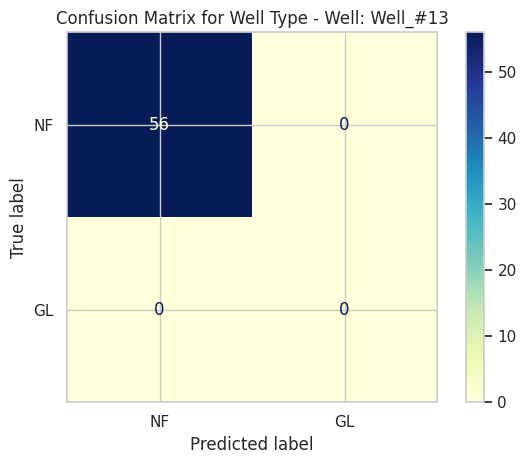

Well_#14             1.0000     1.0000     1.0000   1.0000    


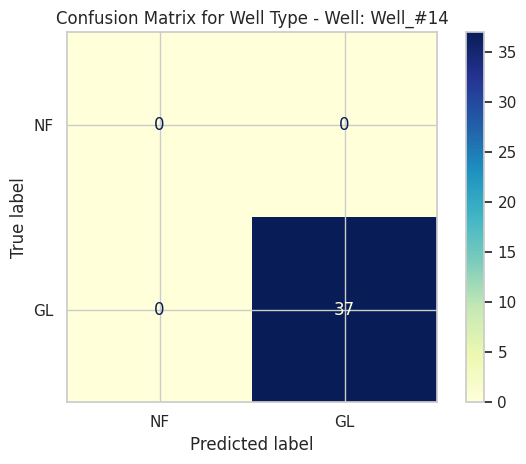

Well_#15             1.0000     1.0000     1.0000   1.0000    


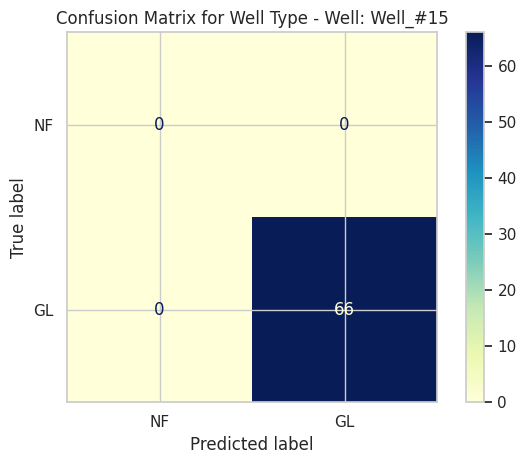

Well_#16             1.0000     1.0000     1.0000   1.0000    


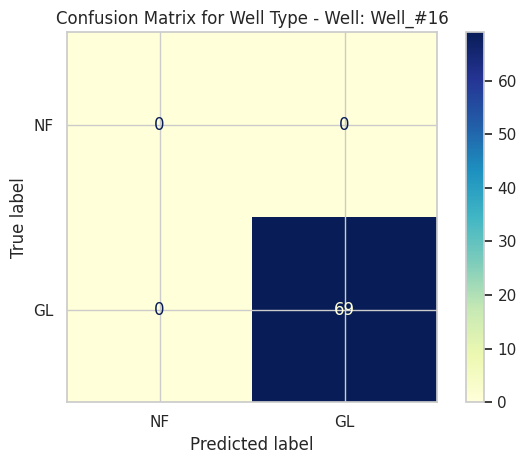

Well_#17             0.8351     1.0000     0.8351   0.9101    


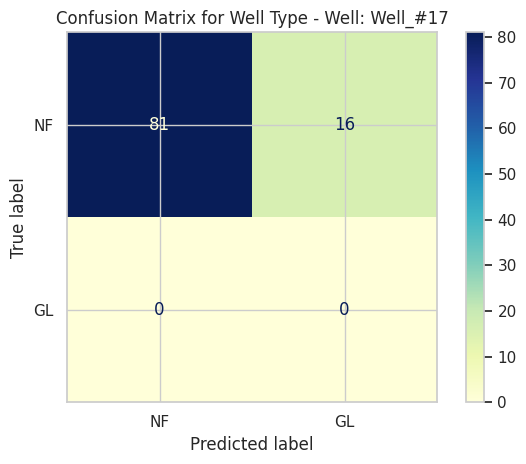

Well_#18             1.0000     1.0000     1.0000   1.0000    


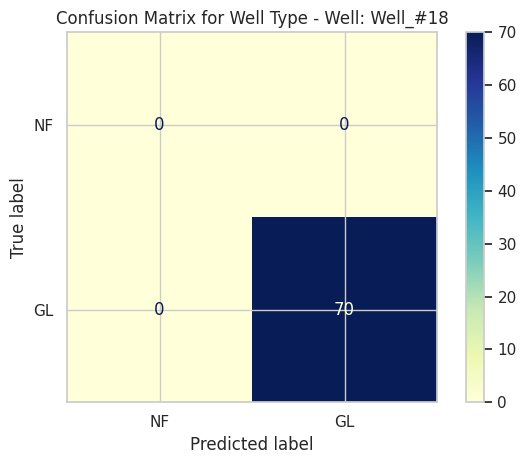

Well_#19             1.0000     1.0000     1.0000   1.0000    


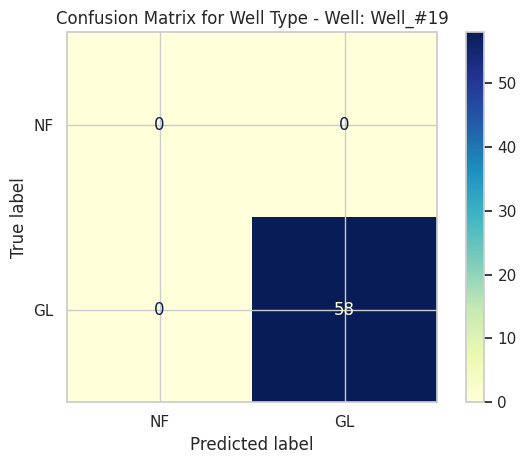

Well_#2              1.0000     1.0000     1.0000   1.0000    


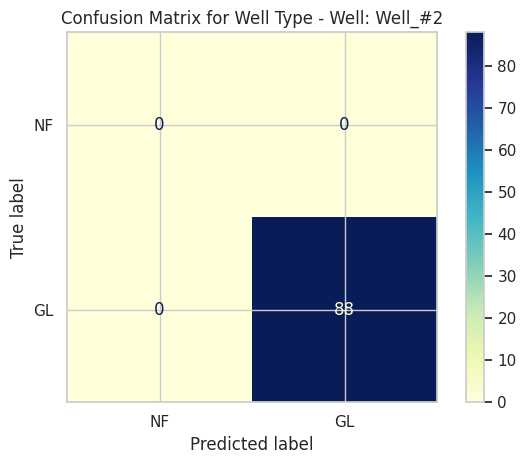

Well_#20             1.0000     1.0000     1.0000   1.0000    


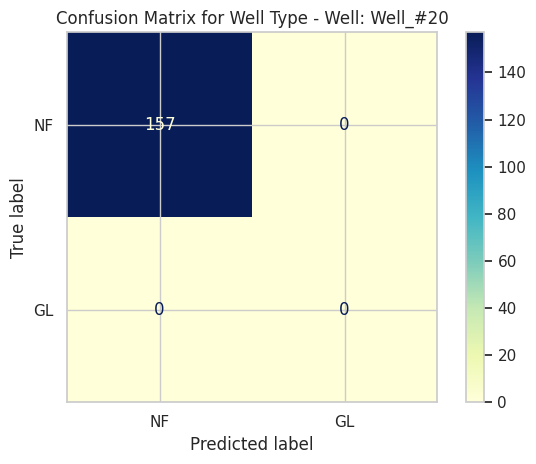

Well_#3              1.0000     1.0000     1.0000   1.0000    


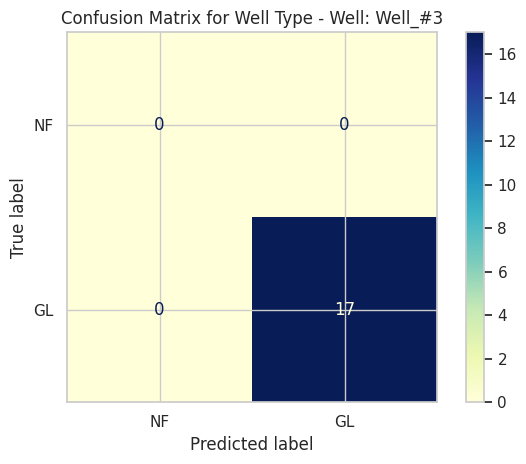

Well_#4              1.0000     1.0000     1.0000   1.0000    


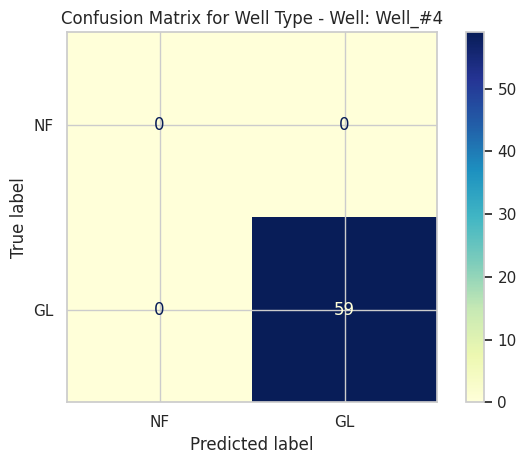

Well_#5              1.0000     1.0000     1.0000   1.0000    


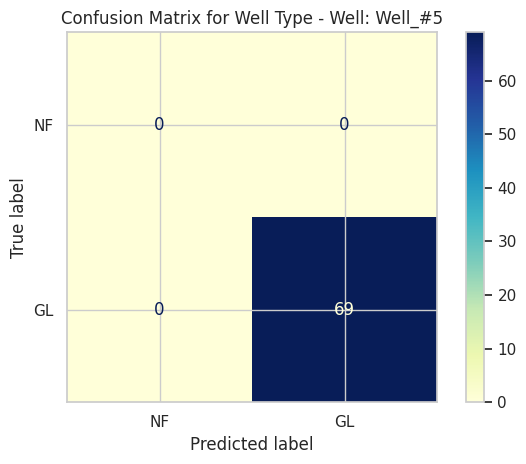

Well_#6              1.0000     1.0000     1.0000   1.0000    


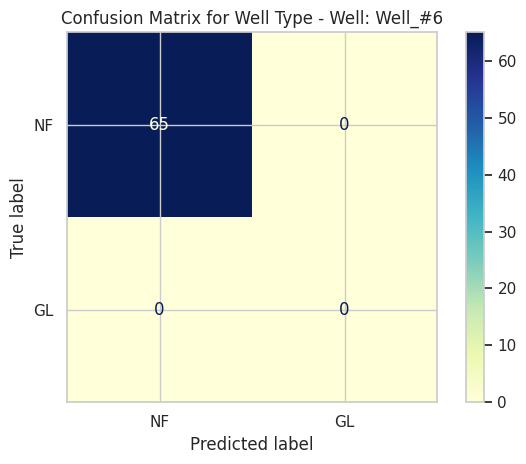

Well_#7              1.0000     1.0000     1.0000   1.0000    


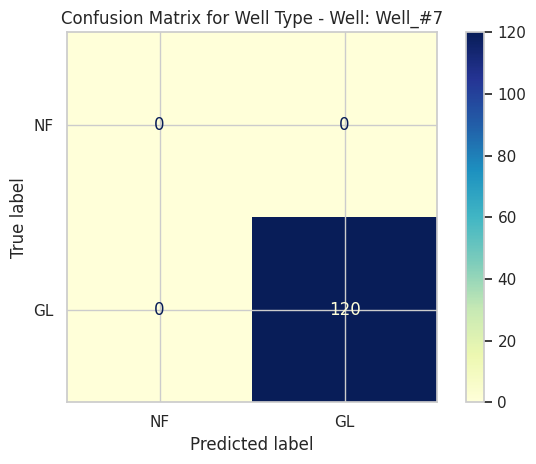

Well_#8              1.0000     1.0000     1.0000   1.0000    


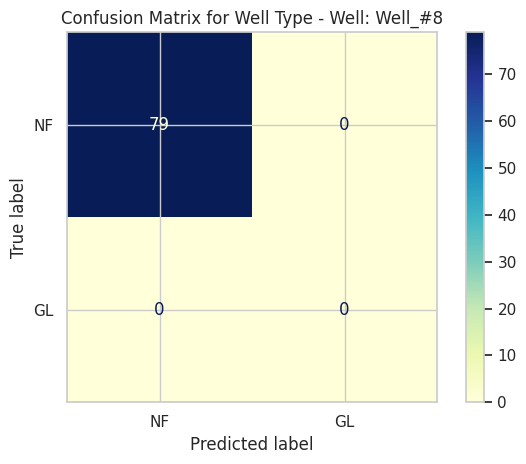

Well_#9              0.9035     1.0000     0.9035   0.9493    


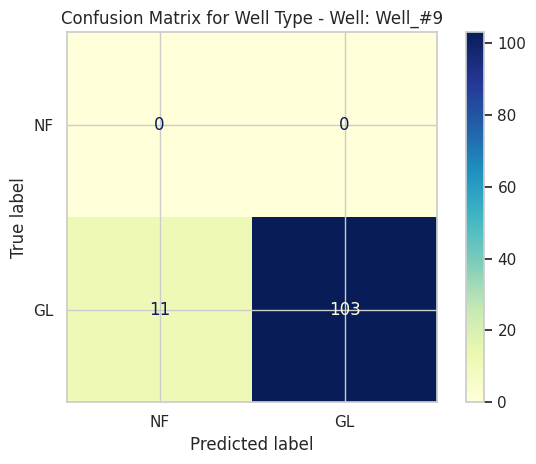

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


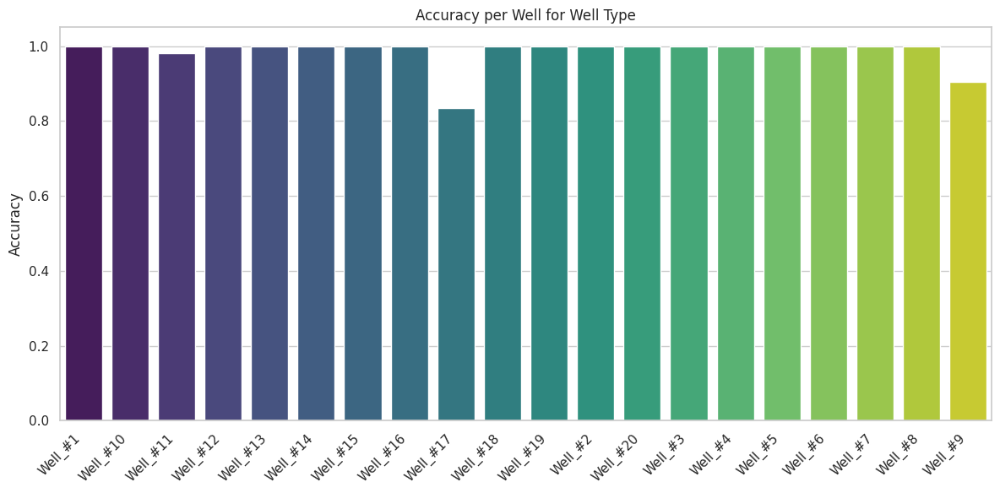

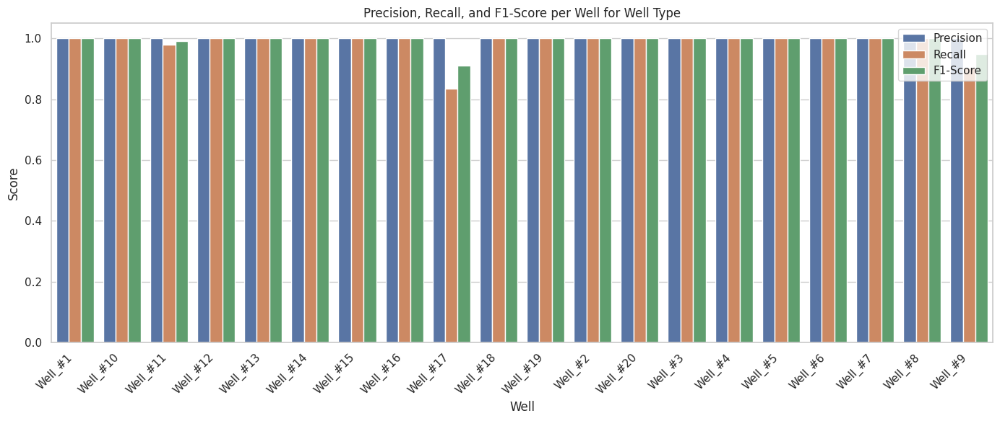


 Target: Production Type


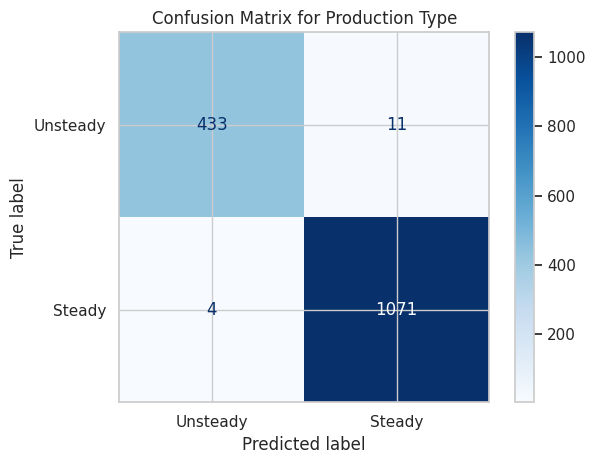

 Overall Accuracy: 0.9901

              precision    recall  f1-score   support

    Unsteady       0.99      0.98      0.98       444
      Steady       0.99      1.00      0.99      1075

    accuracy                           0.99      1519
   macro avg       0.99      0.99      0.99      1519
weighted avg       0.99      0.99      0.99      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              0.9756     1.0000     0.9756   0.9877    


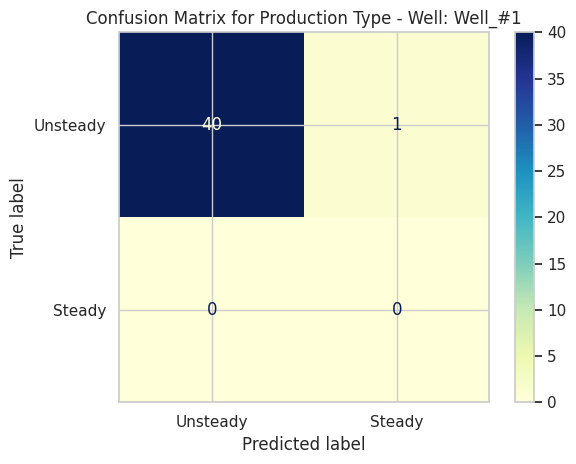

Well_#10             1.0000     1.0000     1.0000   1.0000    


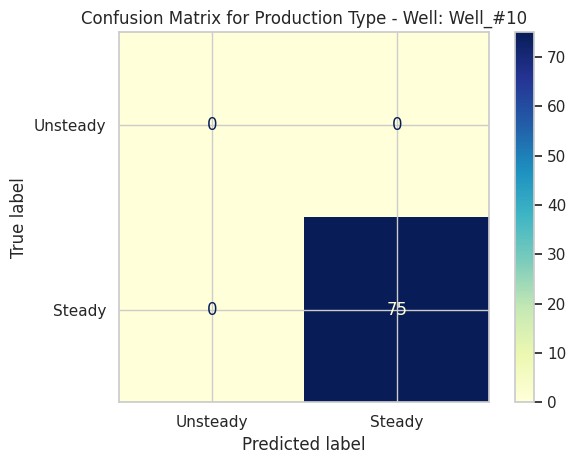

Well_#11             1.0000     1.0000     1.0000   1.0000    


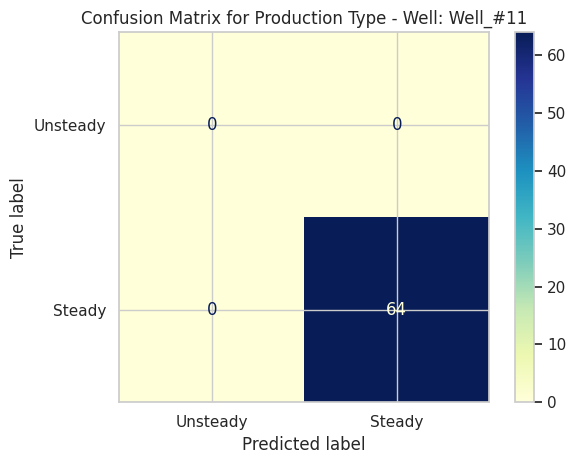

Well_#12             1.0000     1.0000     1.0000   1.0000    


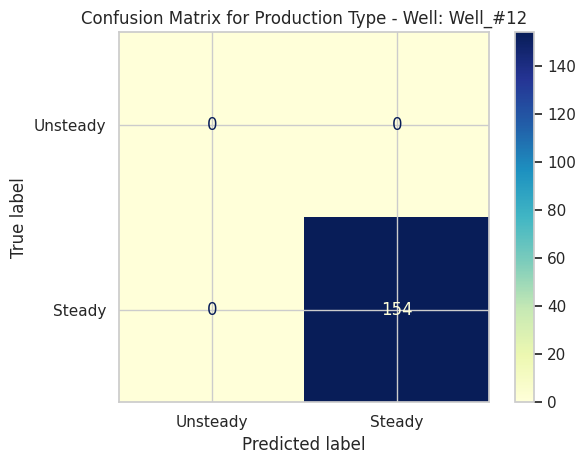

Well_#13             1.0000     1.0000     1.0000   1.0000    


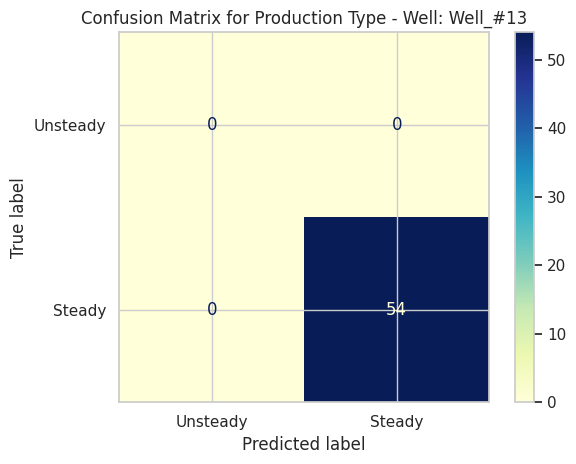

Well_#14             1.0000     1.0000     1.0000   1.0000    


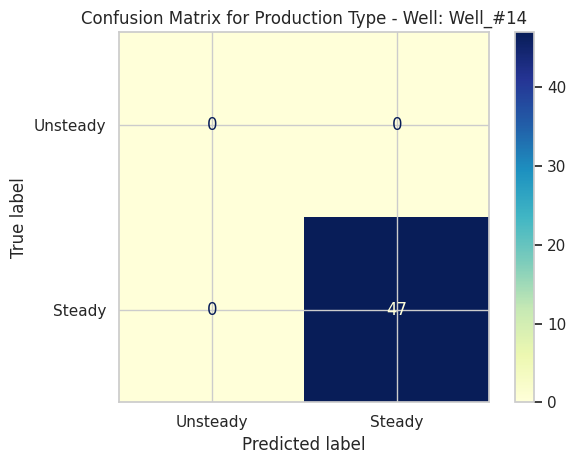

Well_#15             1.0000     1.0000     1.0000   1.0000    


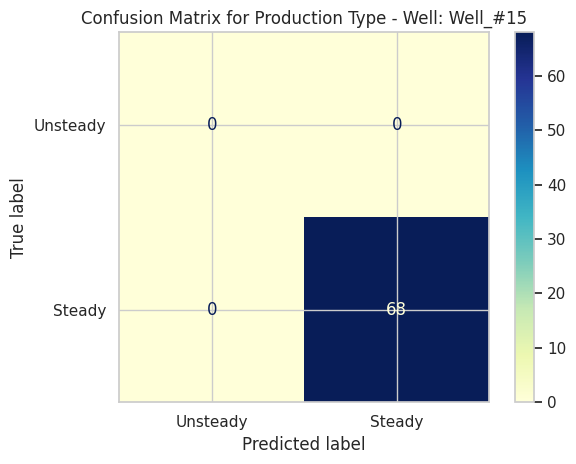

Well_#16             1.0000     1.0000     1.0000   1.0000    


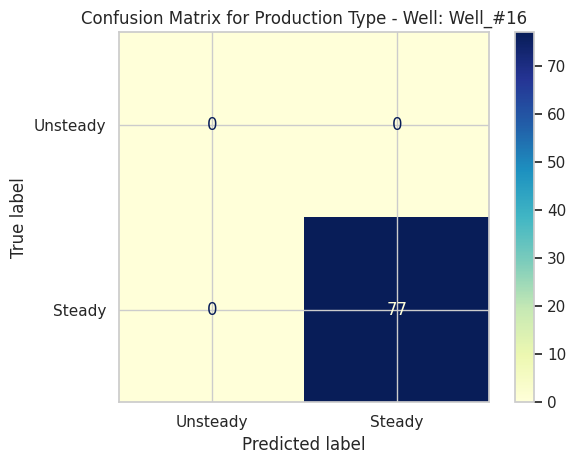

Well_#17             0.9474     1.0000     0.9474   0.9730    


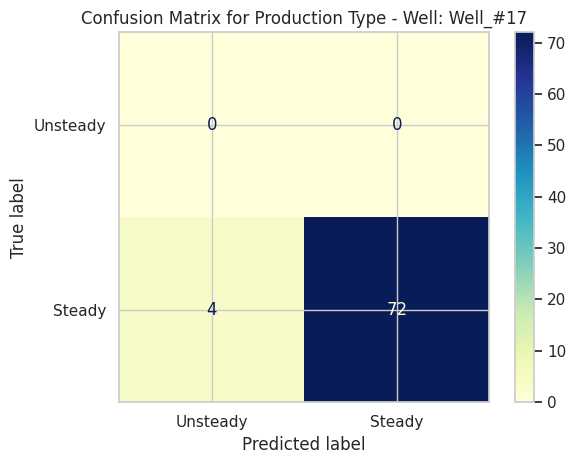

Well_#18             1.0000     1.0000     1.0000   1.0000    


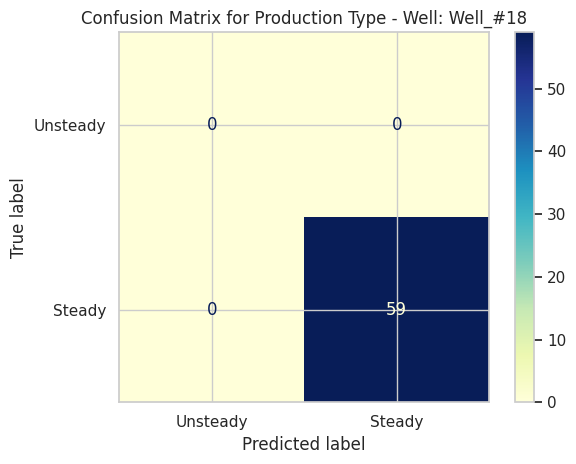

Well_#19             1.0000     1.0000     1.0000   1.0000    


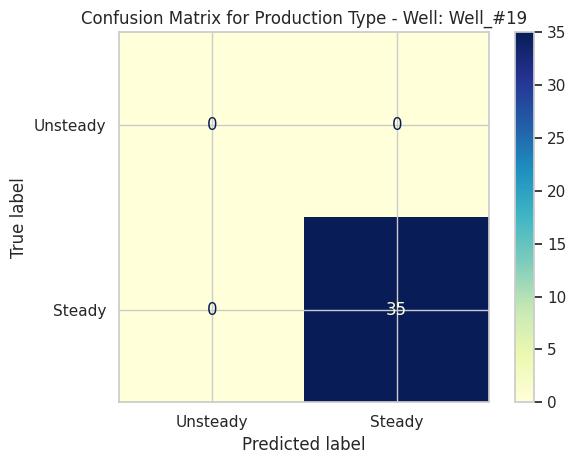

Well_#2              1.0000     1.0000     1.0000   1.0000    


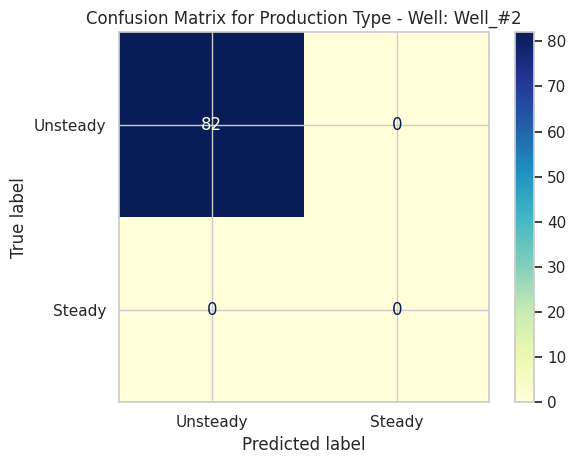

Well_#20             1.0000     1.0000     1.0000   1.0000    


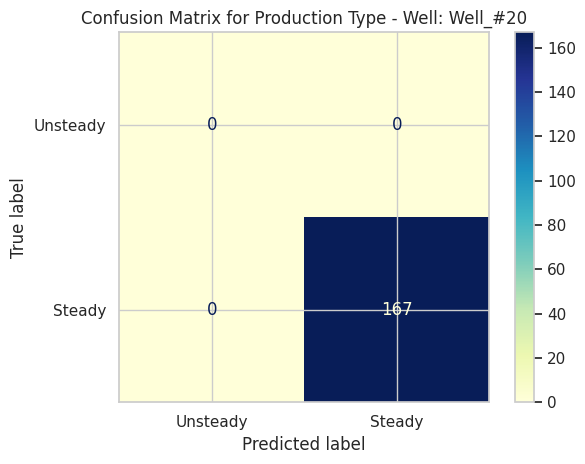

Well_#3              1.0000     1.0000     1.0000   1.0000    


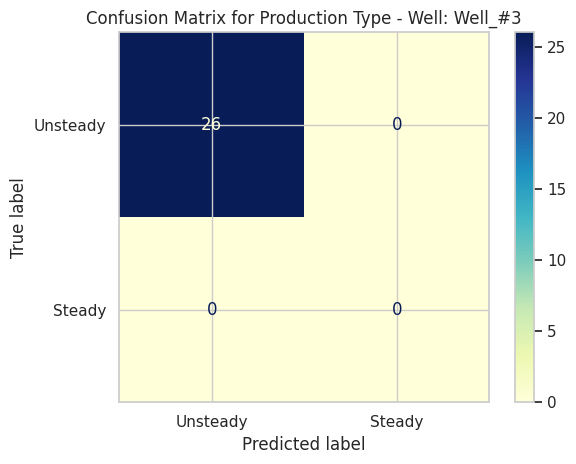

Well_#4              1.0000     1.0000     1.0000   1.0000    


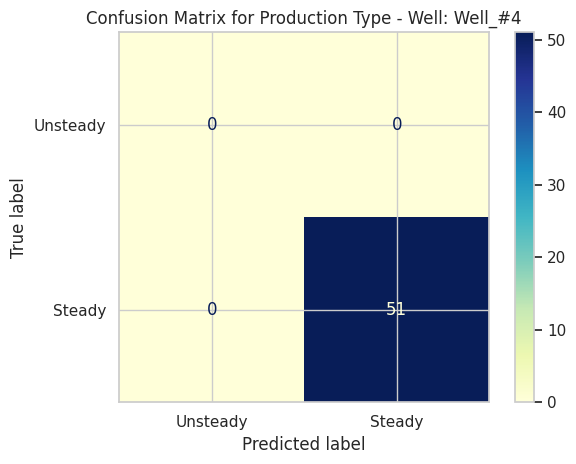

Well_#5              1.0000     1.0000     1.0000   1.0000    


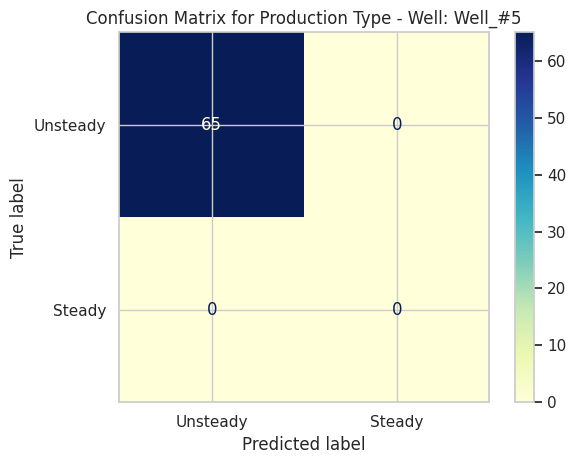

Well_#6              1.0000     1.0000     1.0000   1.0000    


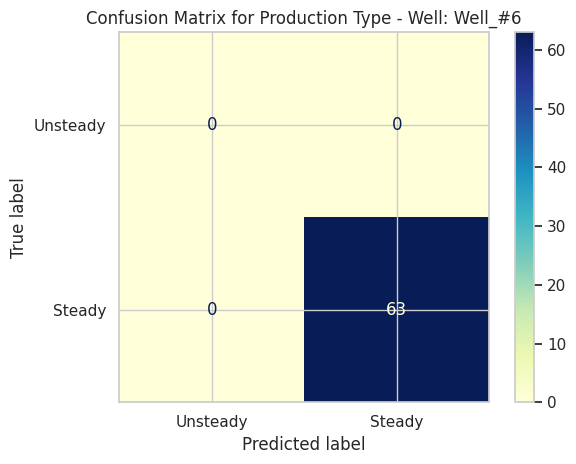

Well_#7              1.0000     1.0000     1.0000   1.0000    


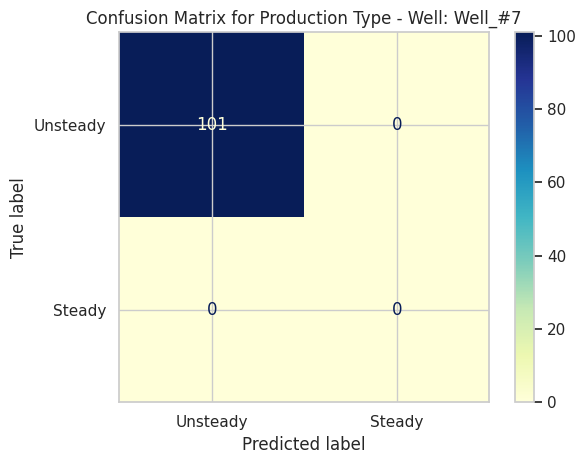

Well_#8              1.0000     1.0000     1.0000   1.0000    


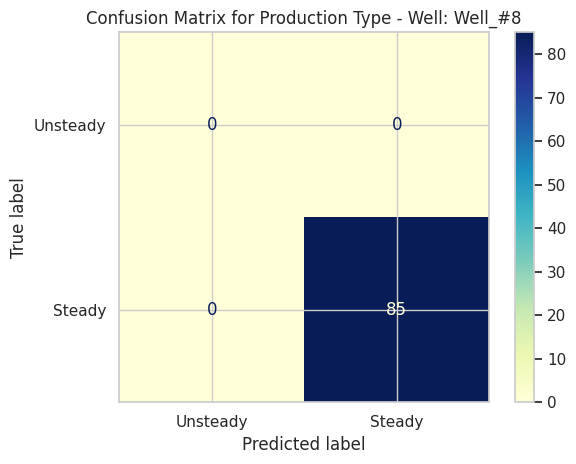

Well_#9              0.9225     1.0000     0.9225   0.9597    


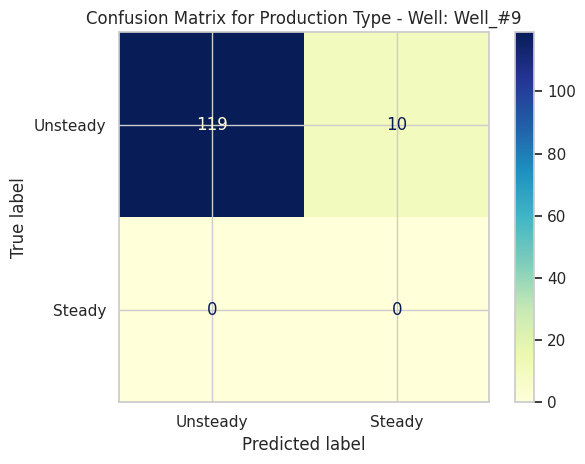

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


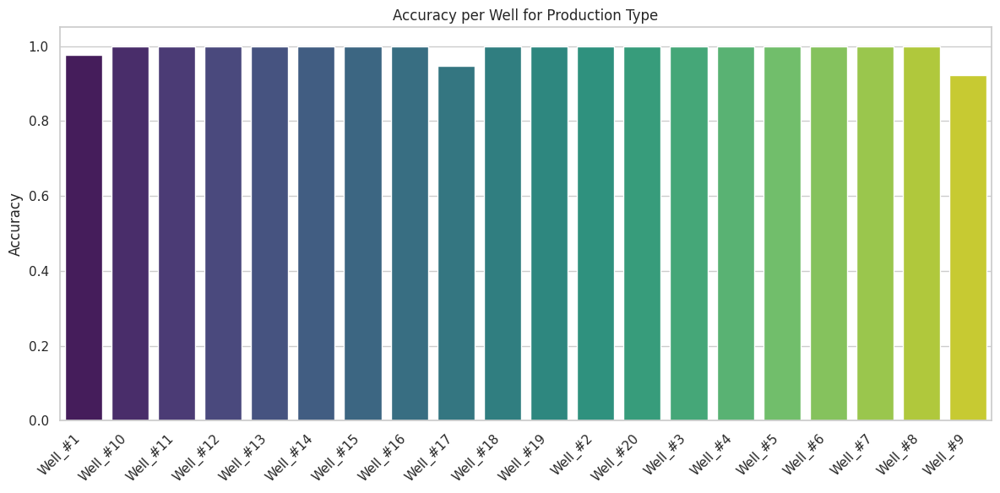

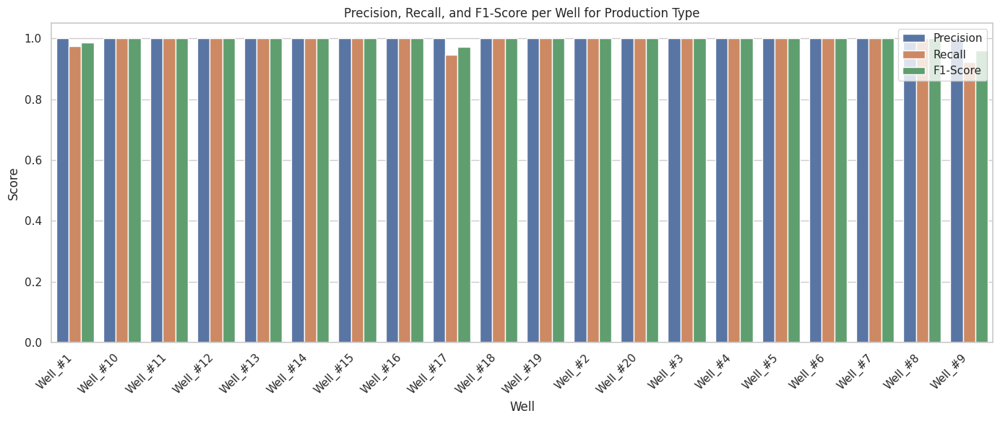


 Target: Formation GOR Trend


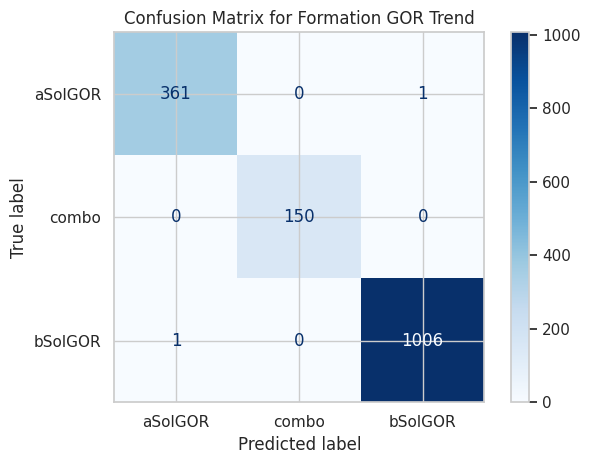

 Overall Accuracy: 0.9987

              precision    recall  f1-score   support

     aSolGOR       1.00      1.00      1.00       362
       combo       1.00      1.00      1.00       150
     bSolGOR       1.00      1.00      1.00      1007

    accuracy                           1.00      1519
   macro avg       1.00      1.00      1.00      1519
weighted avg       1.00      1.00      1.00      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    


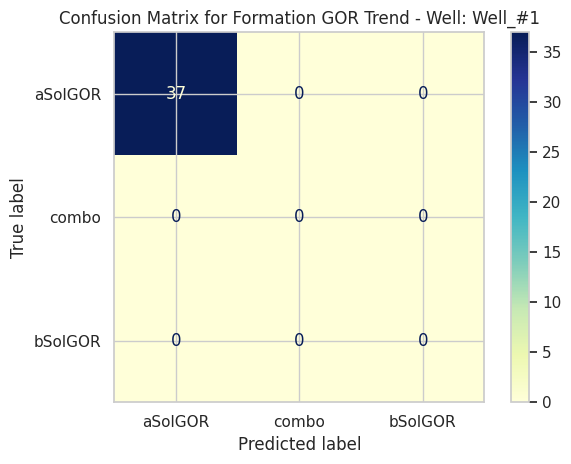

Well_#10             1.0000     1.0000     1.0000   1.0000    


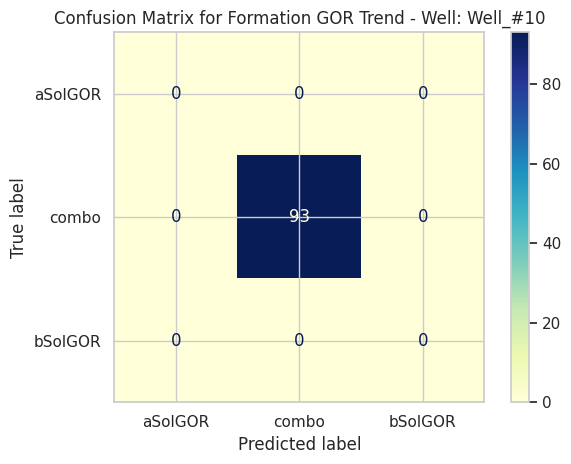

Well_#11             1.0000     1.0000     1.0000   1.0000    


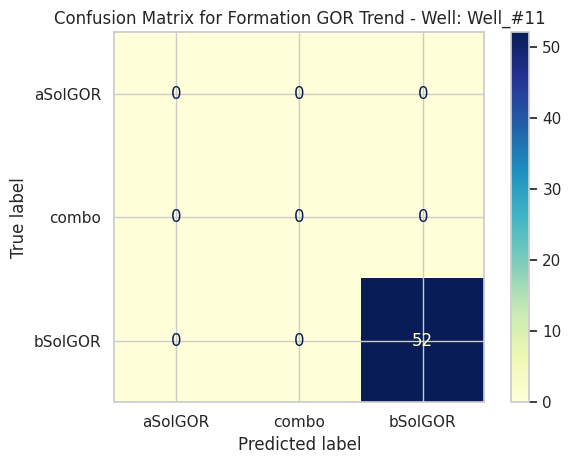

Well_#12             0.9935     1.0000     0.9935   0.9967    


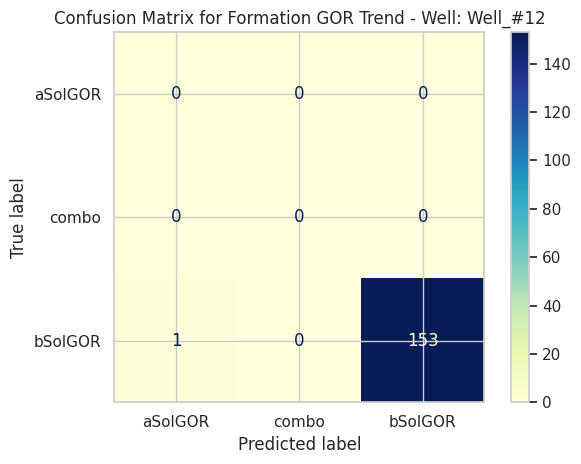

Well_#13             1.0000     1.0000     1.0000   1.0000    


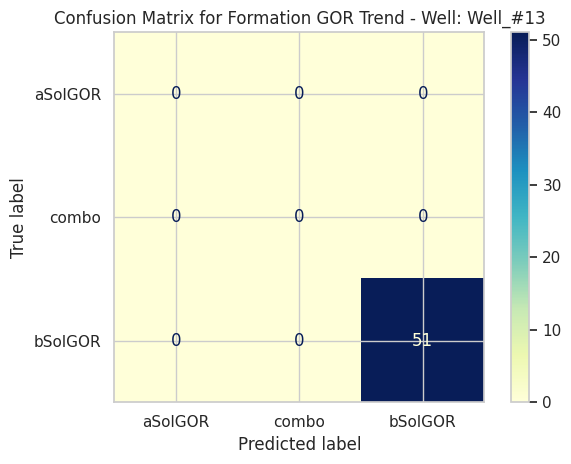

Well_#14             1.0000     1.0000     1.0000   1.0000    


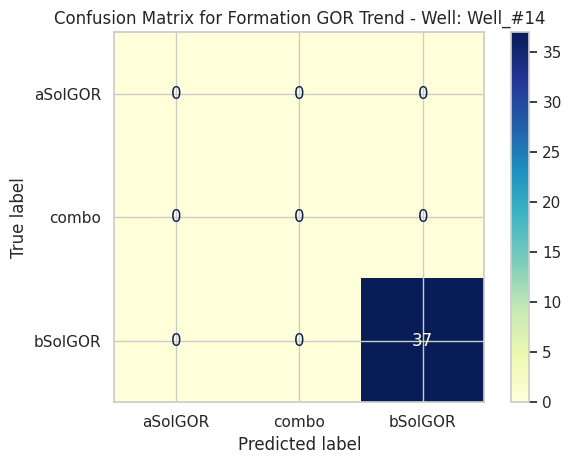

Well_#15             1.0000     1.0000     1.0000   1.0000    


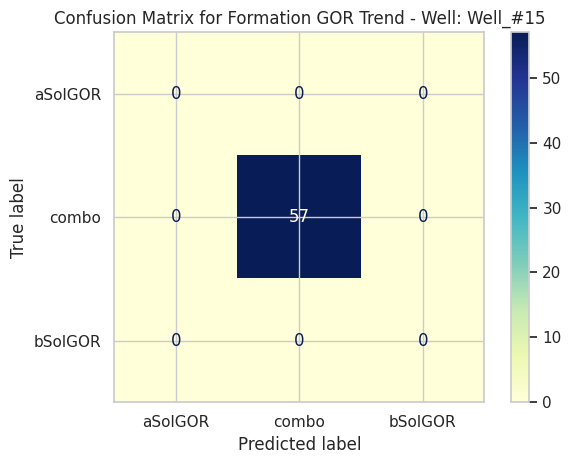

Well_#16             1.0000     1.0000     1.0000   1.0000    


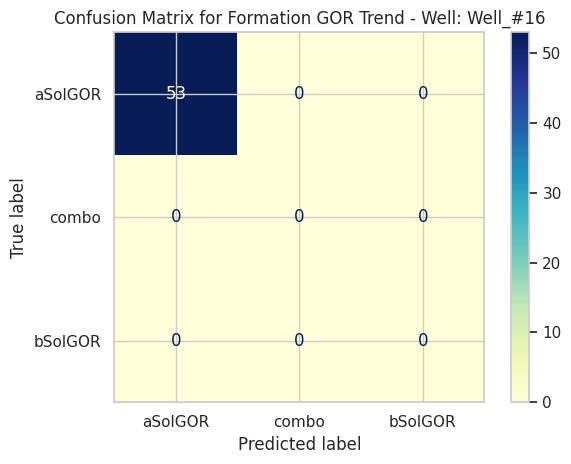

Well_#17             1.0000     1.0000     1.0000   1.0000    


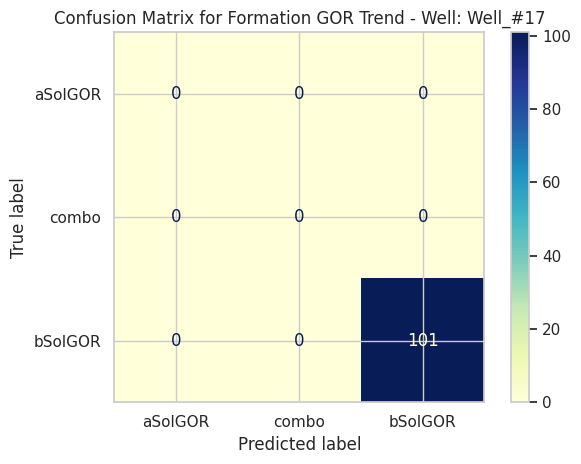

Well_#18             0.9836     1.0000     0.9836   0.9917    


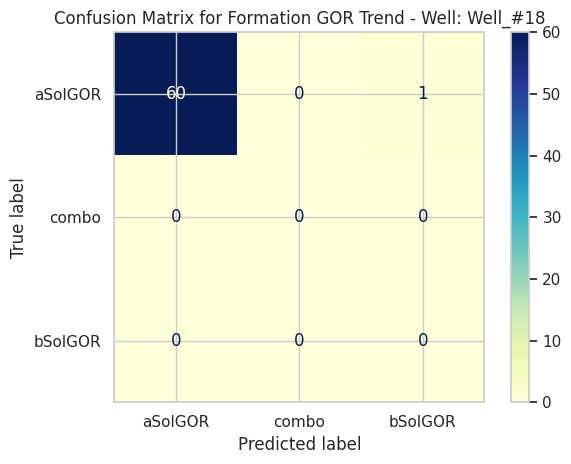

Well_#19             1.0000     1.0000     1.0000   1.0000    


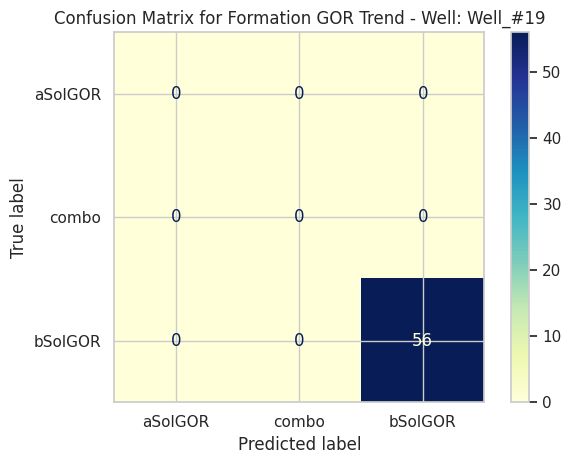

Well_#2              1.0000     1.0000     1.0000   1.0000    


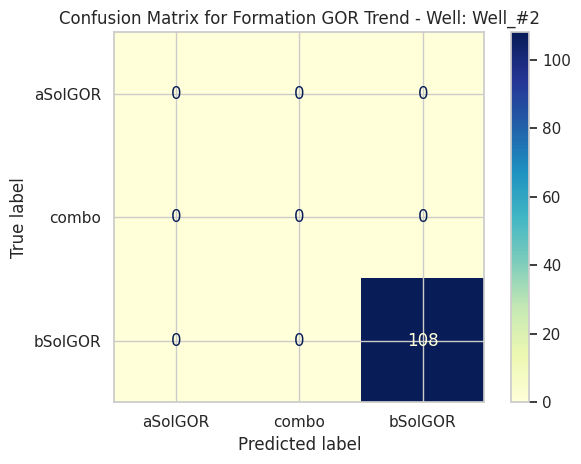

Well_#20             1.0000     1.0000     1.0000   1.0000    


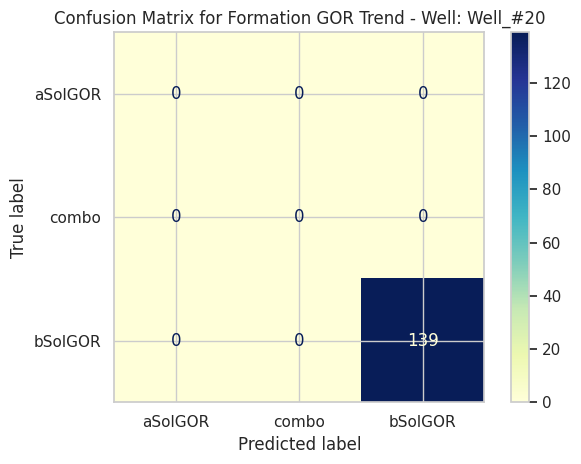

Well_#3              1.0000     1.0000     1.0000   1.0000    


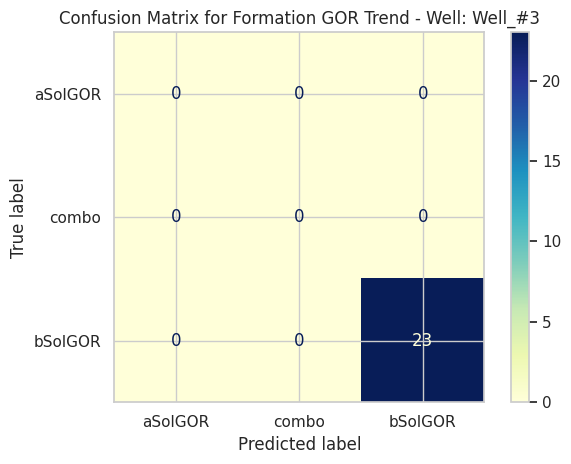

Well_#4              1.0000     1.0000     1.0000   1.0000    


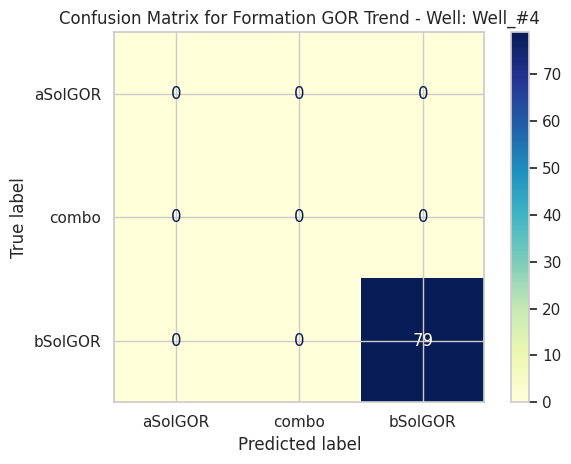

Well_#5              1.0000     1.0000     1.0000   1.0000    


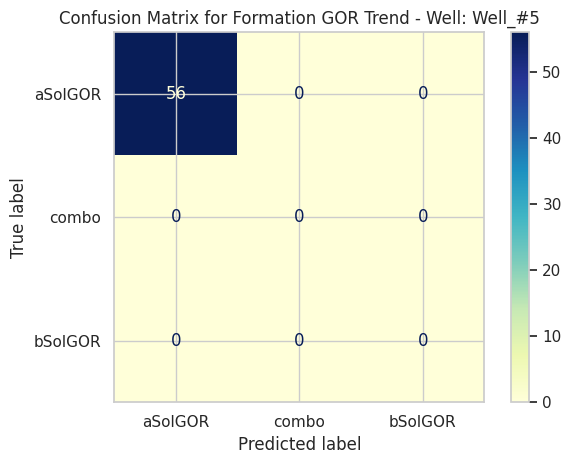

Well_#6              1.0000     1.0000     1.0000   1.0000    


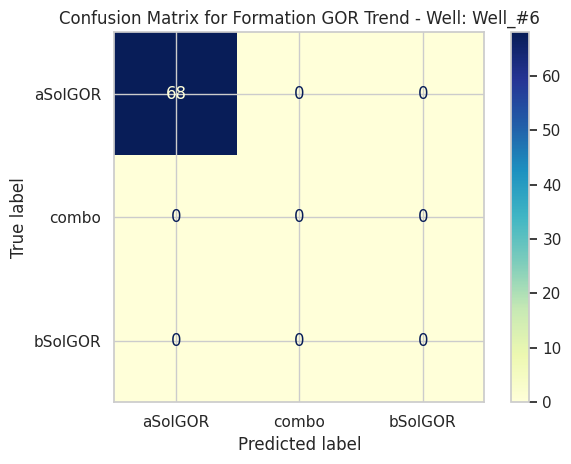

Well_#7              1.0000     1.0000     1.0000   1.0000    


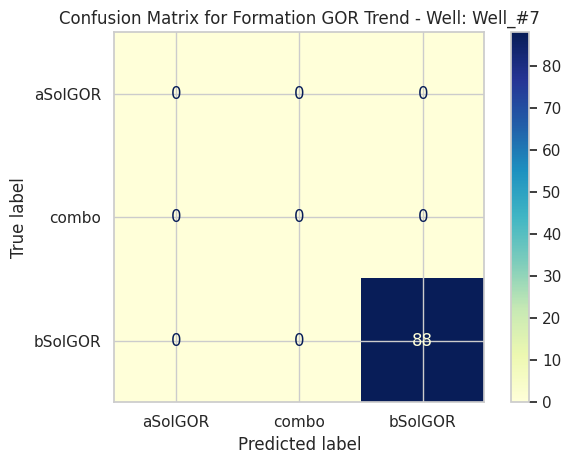

Well_#8              1.0000     1.0000     1.0000   1.0000    


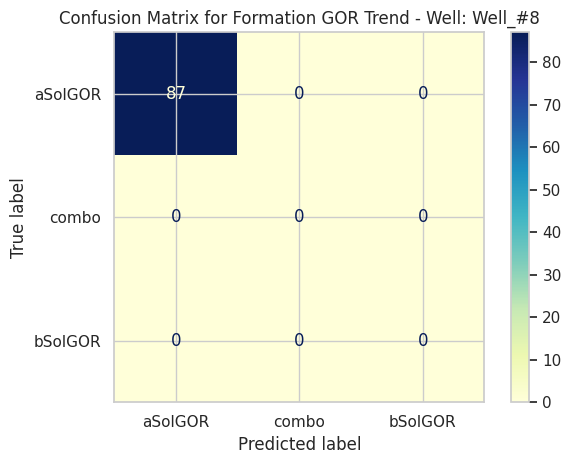

Well_#9              1.0000     1.0000     1.0000   1.0000    


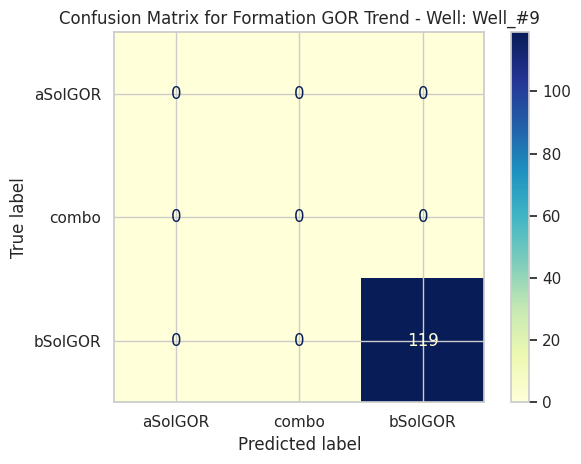

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


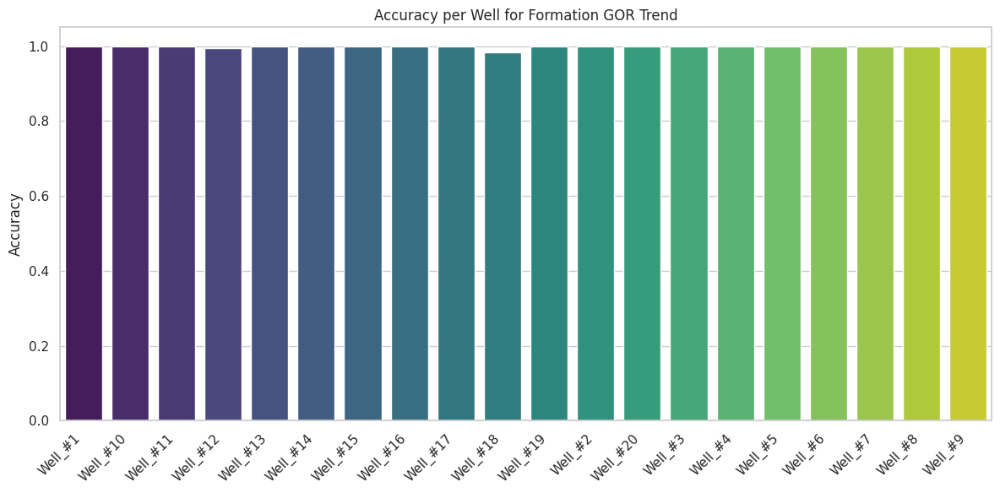

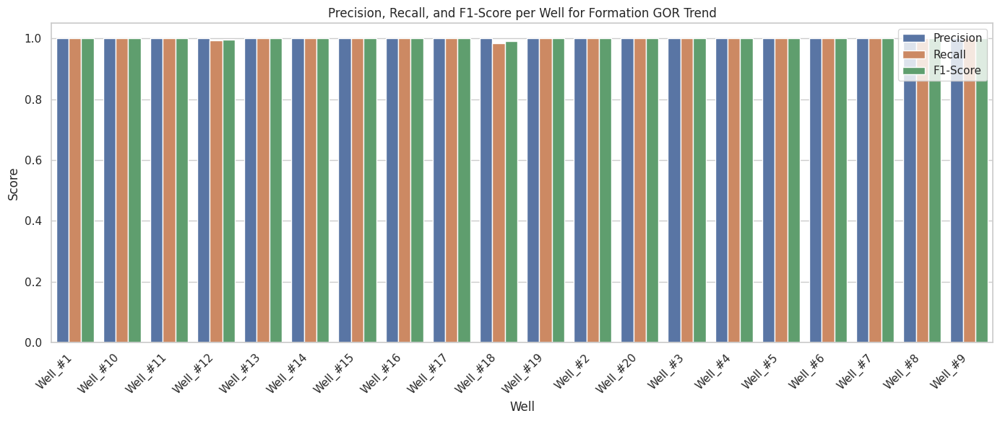


 Target: Watercut Trend


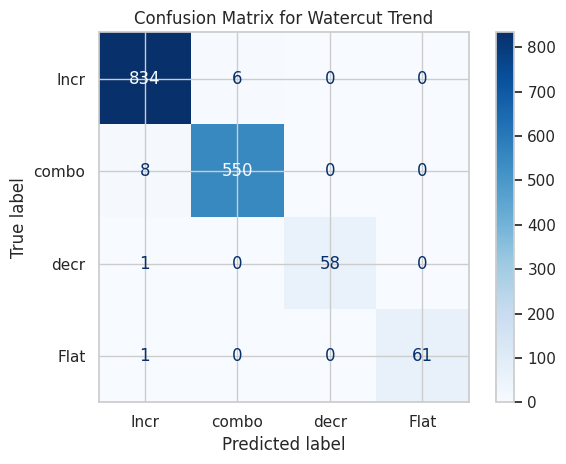

 Overall Accuracy: 0.9895

              precision    recall  f1-score   support

        Incr       0.99      0.99      0.99       840
       combo       0.99      0.99      0.99       558
        decr       1.00      0.98      0.99        59
        Flat       1.00      0.98      0.99        62

    accuracy                           0.99      1519
   macro avg       0.99      0.99      0.99      1519
weighted avg       0.99      0.99      0.99      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    


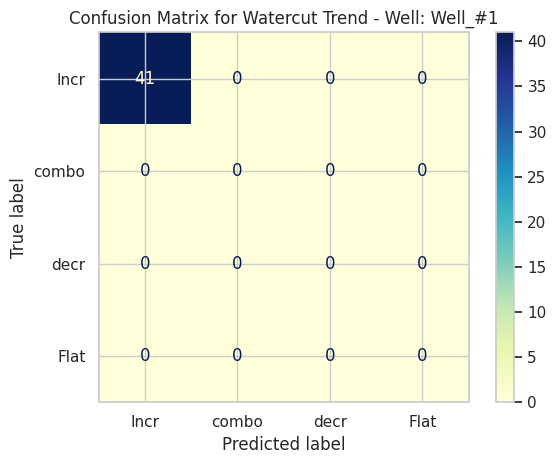

Well_#10             1.0000     1.0000     1.0000   1.0000    


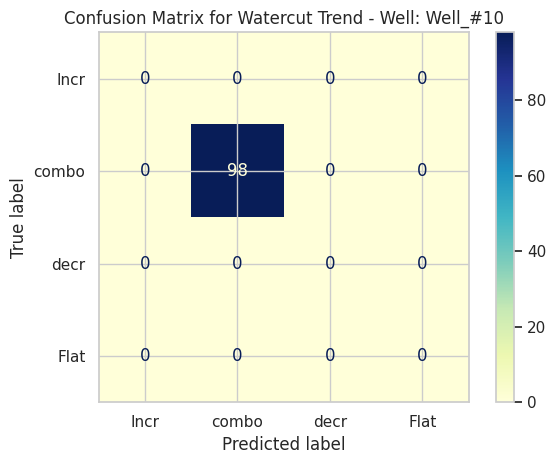

Well_#11             1.0000     1.0000     1.0000   1.0000    


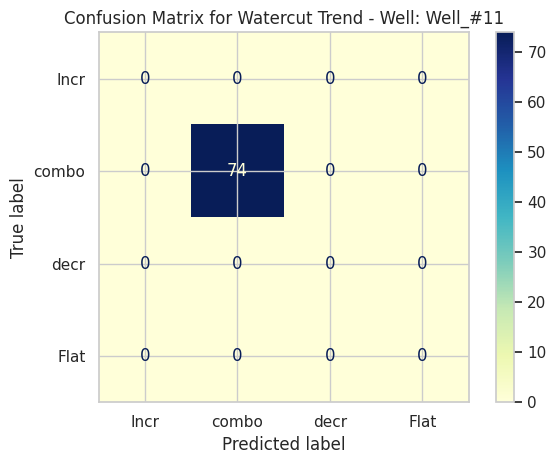

Well_#12             1.0000     1.0000     1.0000   1.0000    


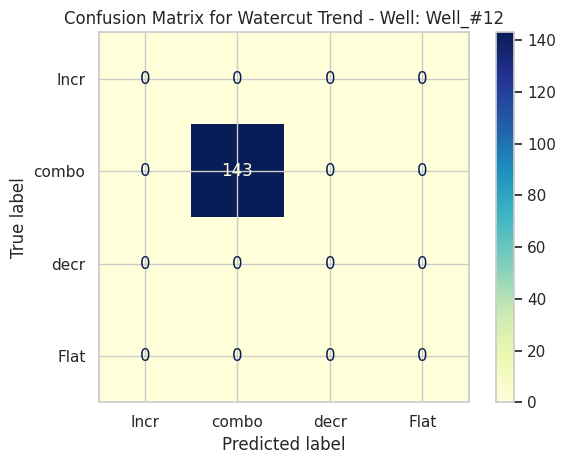

Well_#13             1.0000     1.0000     1.0000   1.0000    


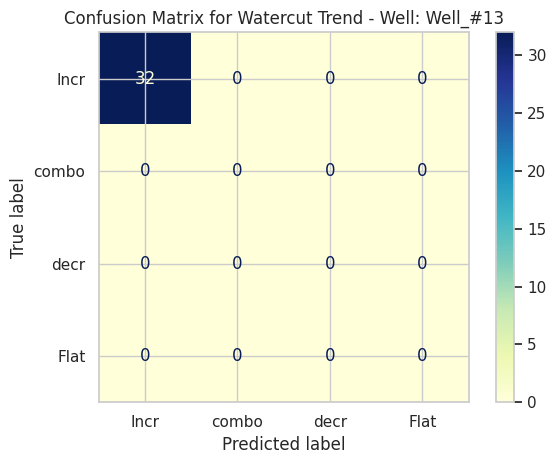

Well_#14             1.0000     1.0000     1.0000   1.0000    


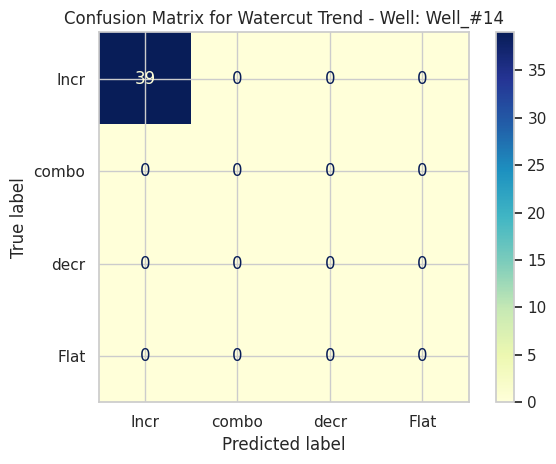

Well_#15             1.0000     1.0000     1.0000   1.0000    


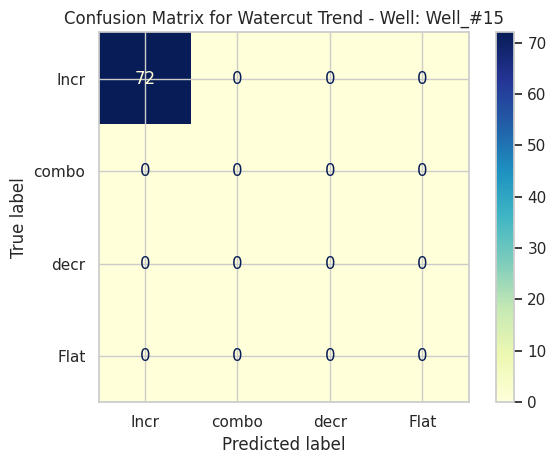

Well_#16             0.9831     1.0000     0.9831   0.9915    


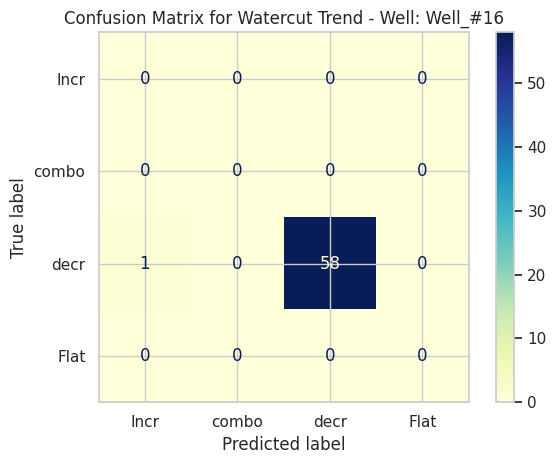

Well_#17             0.9012     1.0000     0.9012   0.9481    


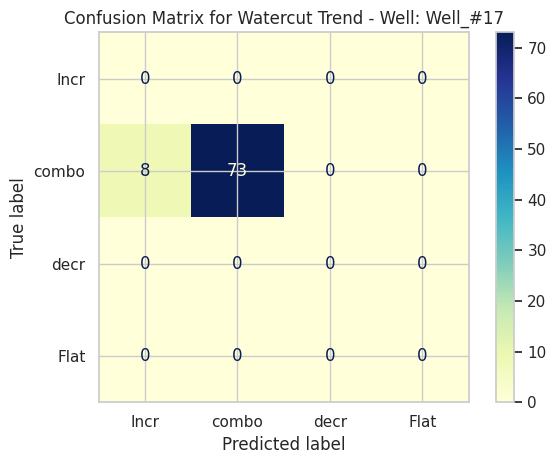

Well_#18             1.0000     1.0000     1.0000   1.0000    


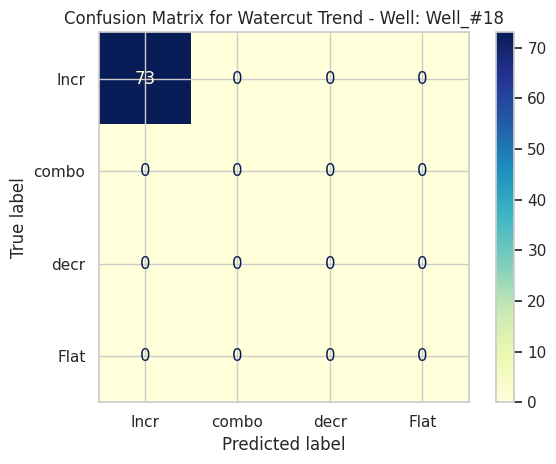

Well_#19             1.0000     1.0000     1.0000   1.0000    


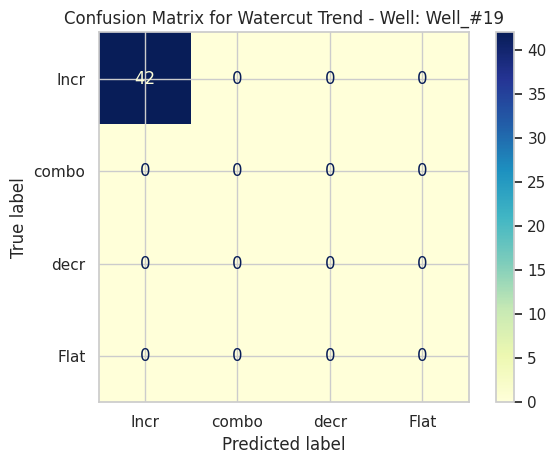

Well_#2              1.0000     1.0000     1.0000   1.0000    


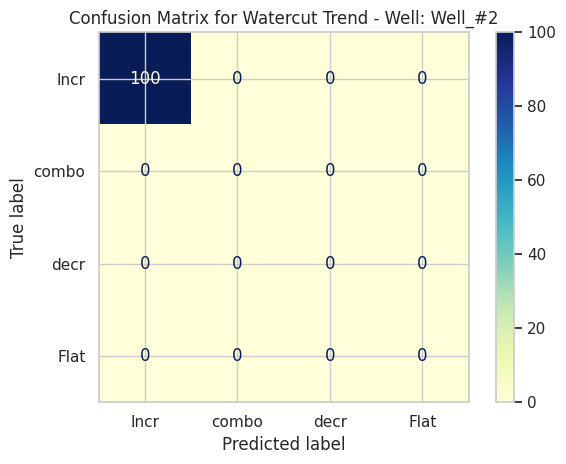

Well_#20             1.0000     1.0000     1.0000   1.0000    


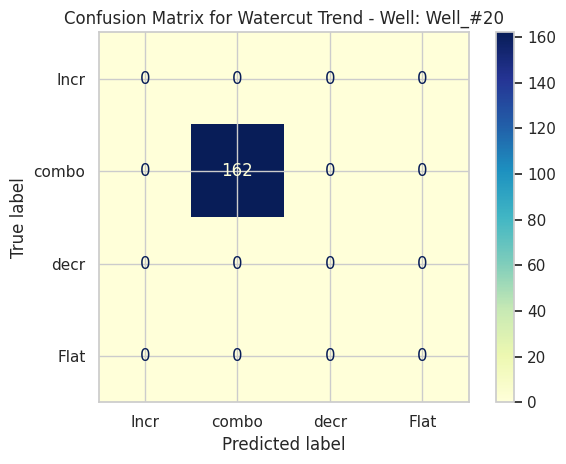

Well_#3              1.0000     1.0000     1.0000   1.0000    


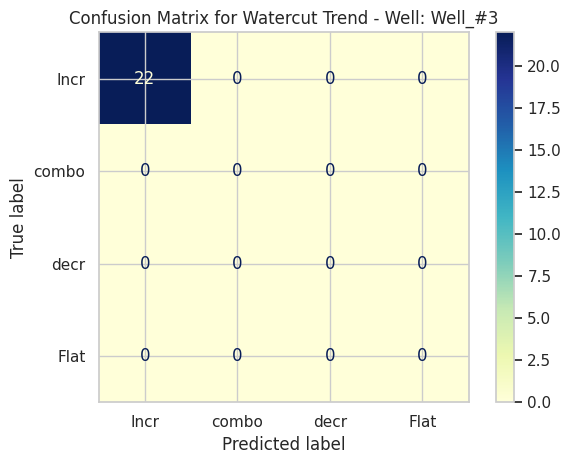

Well_#4              1.0000     1.0000     1.0000   1.0000    


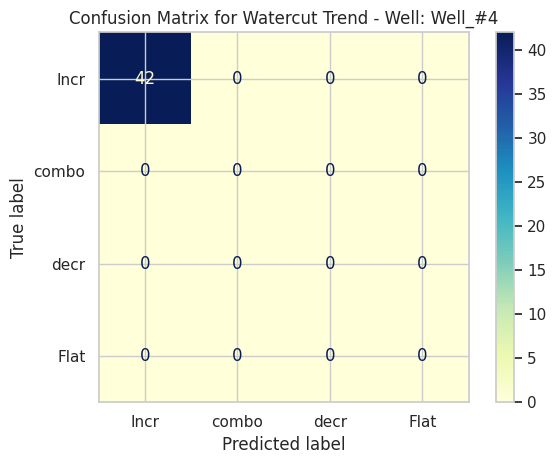

Well_#5              1.0000     1.0000     1.0000   1.0000    


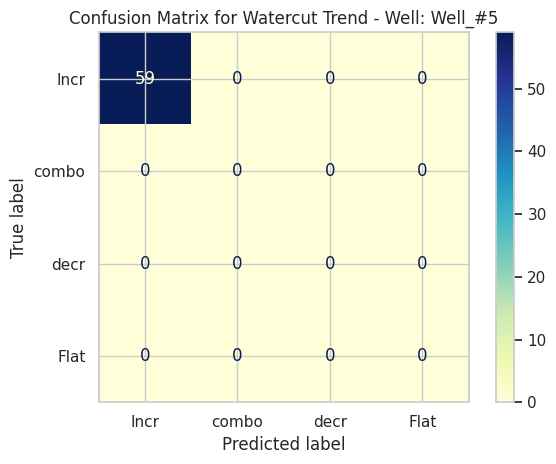

Well_#6              0.9839     1.0000     0.9839   0.9919    


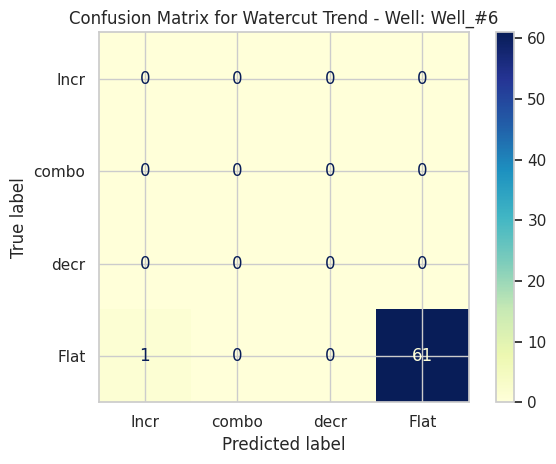

Well_#7              1.0000     1.0000     1.0000   1.0000    


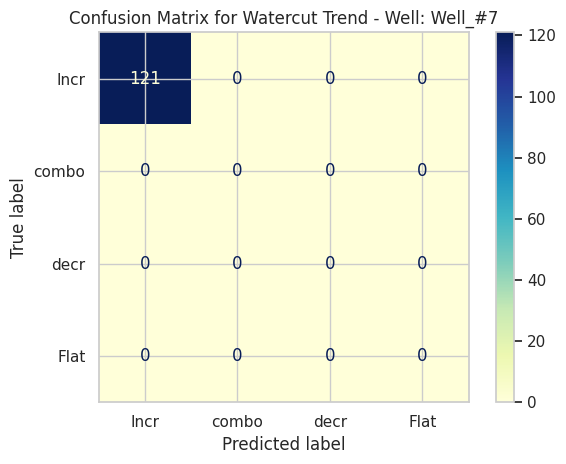

Well_#8              1.0000     1.0000     1.0000   1.0000    


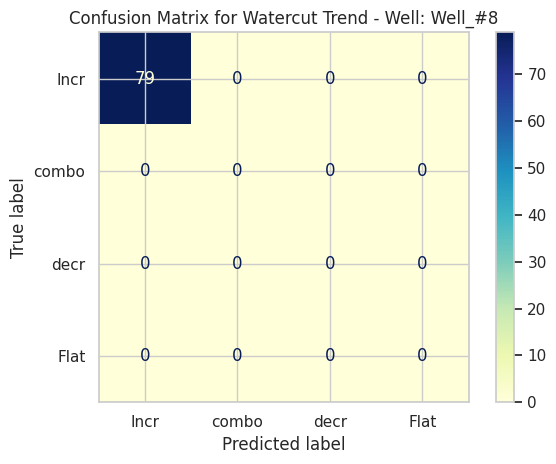

Well_#9              0.9492     1.0000     0.9492   0.9739    


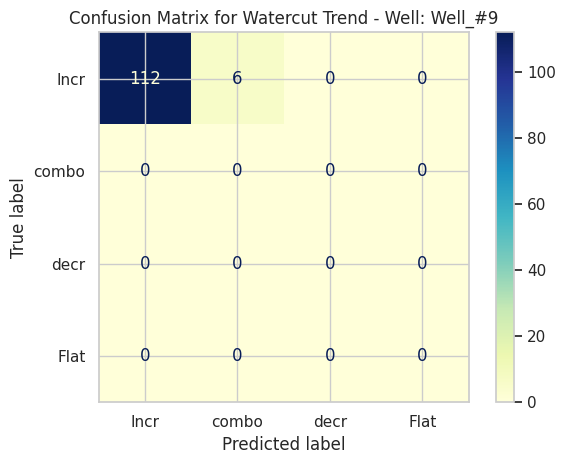

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


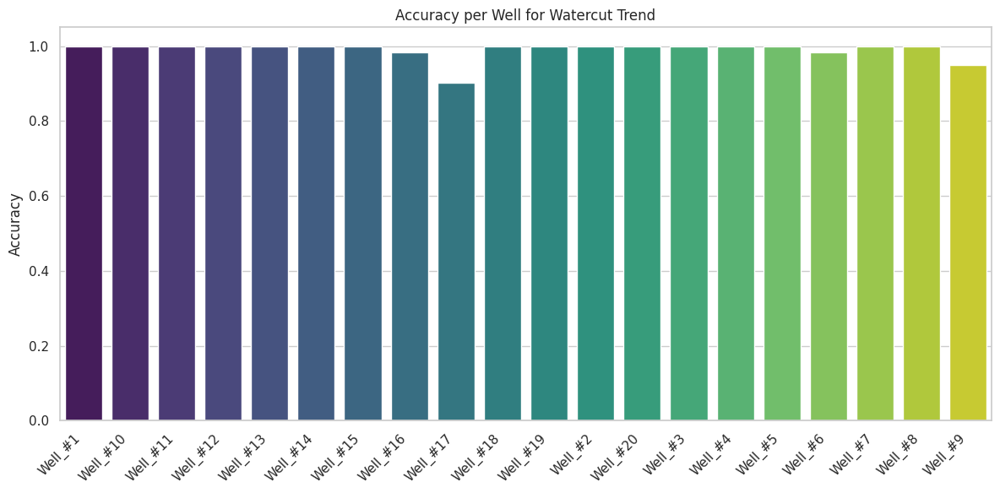

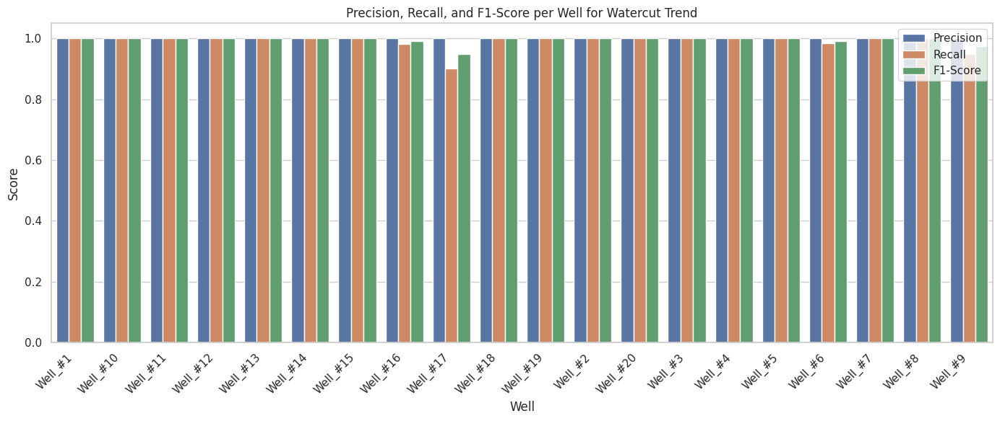


 Target: Oil Productivity Index


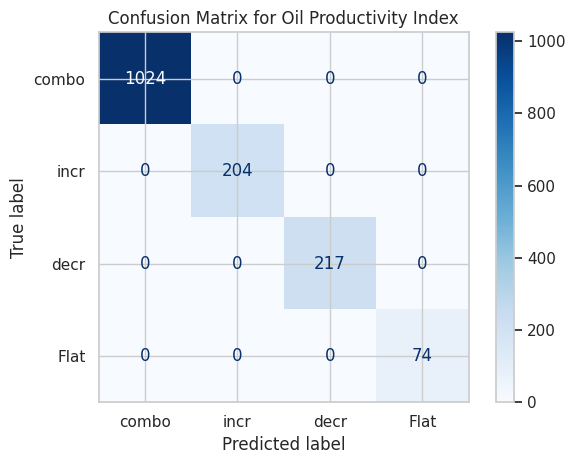

 Overall Accuracy: 1.0000

              precision    recall  f1-score   support

       combo       1.00      1.00      1.00      1024
        incr       1.00      1.00      1.00       204
        decr       1.00      1.00      1.00       217
        Flat       1.00      1.00      1.00        74

    accuracy                           1.00      1519
   macro avg       1.00      1.00      1.00      1519
weighted avg       1.00      1.00      1.00      1519

 Well-by-Well Results:
------------------------------------------------------------
Well                 Accuracy   Precision  Recall   F1-Score  
------------------------------------------------------------
Well_#1              1.0000     1.0000     1.0000   1.0000    


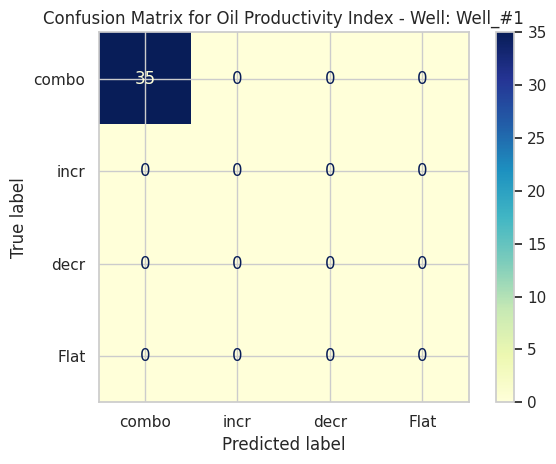

Well_#10             1.0000     1.0000     1.0000   1.0000    


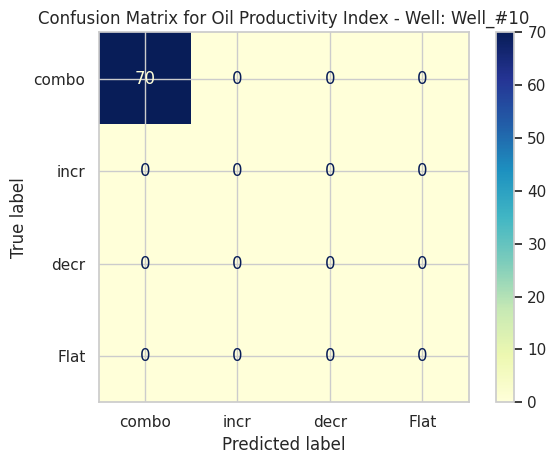

Well_#11             1.0000     1.0000     1.0000   1.0000    


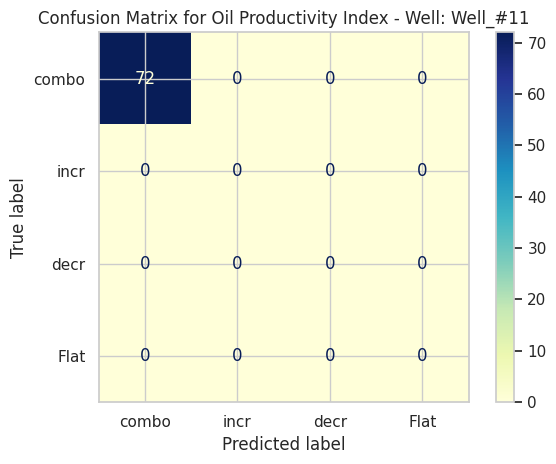

Well_#12             1.0000     1.0000     1.0000   1.0000    


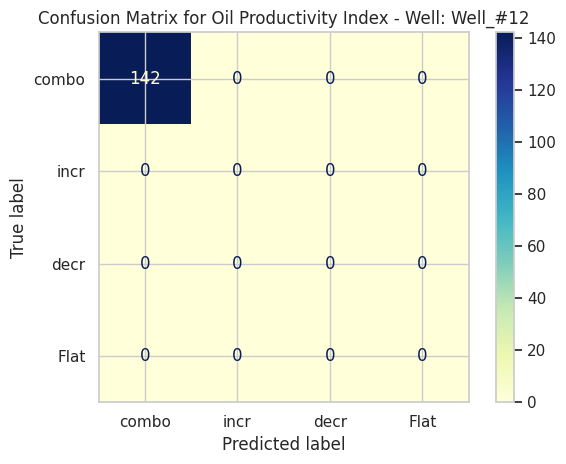

Well_#13             1.0000     1.0000     1.0000   1.0000    


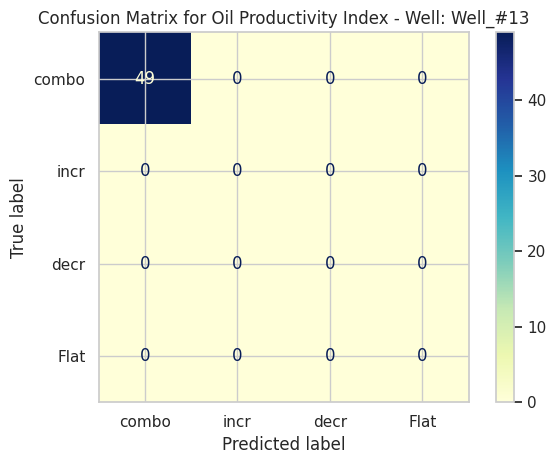

Well_#14             1.0000     1.0000     1.0000   1.0000    


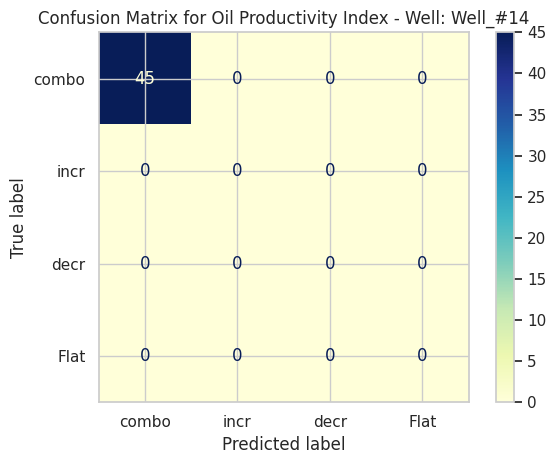

Well_#15             1.0000     1.0000     1.0000   1.0000    


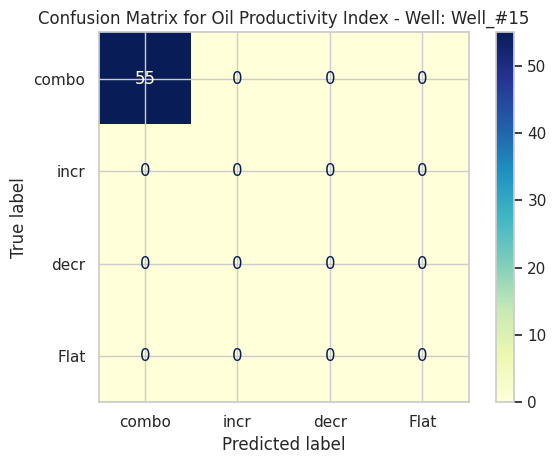

Well_#16             1.0000     1.0000     1.0000   1.0000    


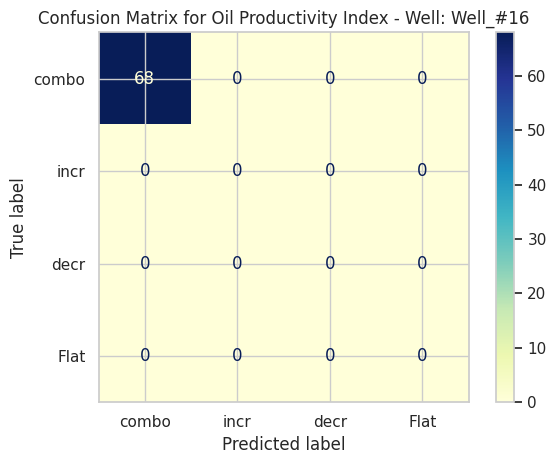

Well_#17             1.0000     1.0000     1.0000   1.0000    


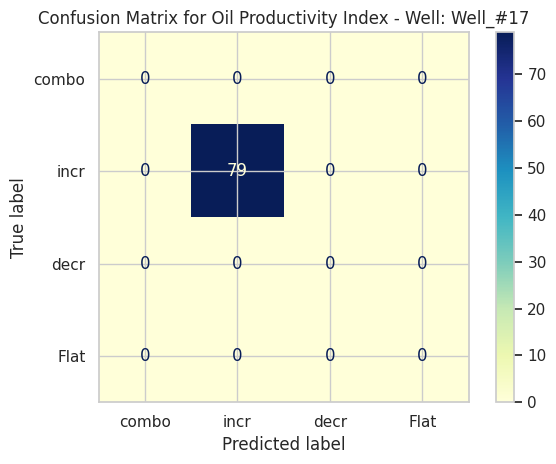

Well_#18             1.0000     1.0000     1.0000   1.0000    


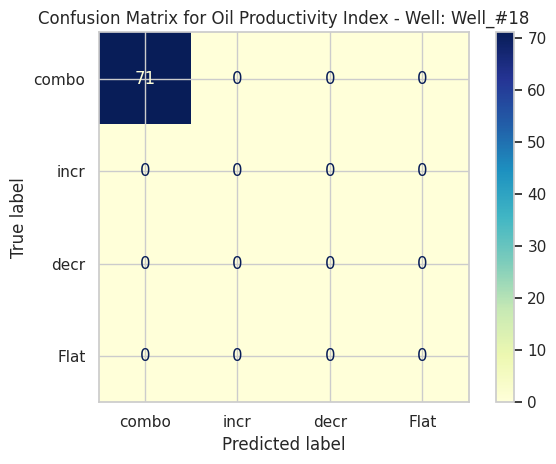

Well_#19             1.0000     1.0000     1.0000   1.0000    


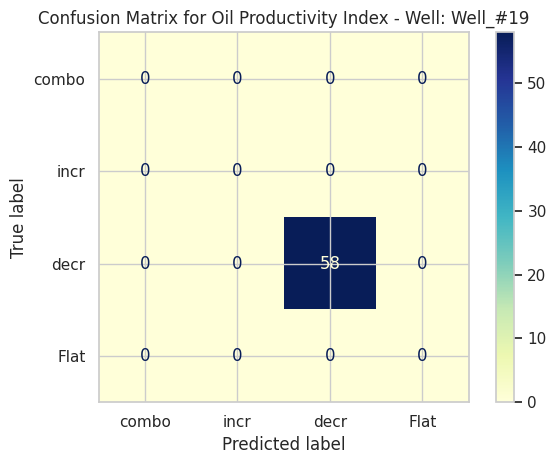

Well_#2              1.0000     1.0000     1.0000   1.0000    


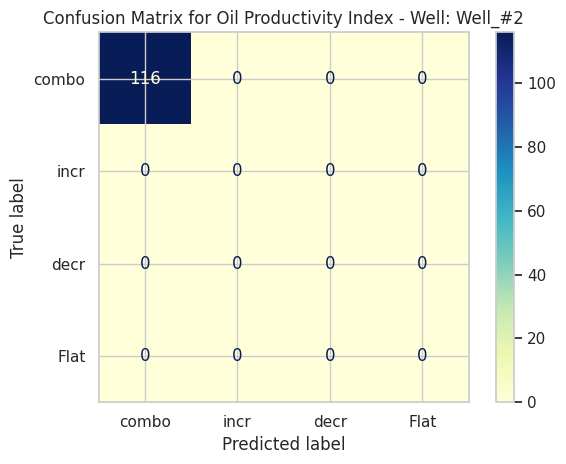

Well_#20             1.0000     1.0000     1.0000   1.0000    


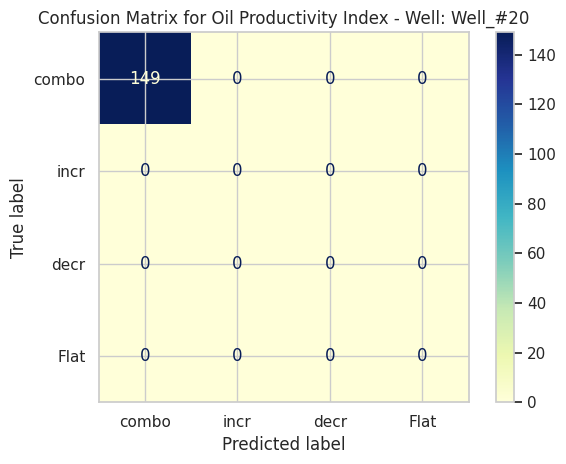

Well_#3              1.0000     1.0000     1.0000   1.0000    


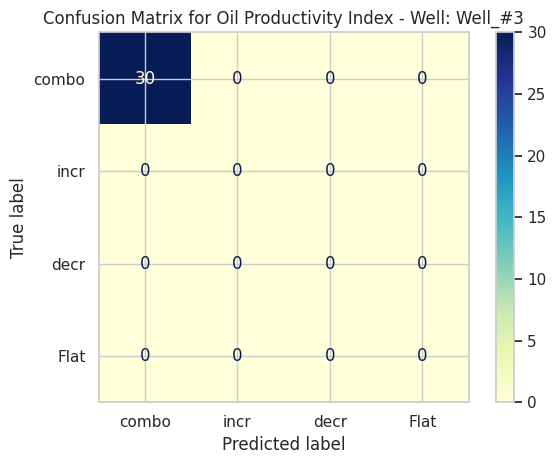

Well_#4              1.0000     1.0000     1.0000   1.0000    


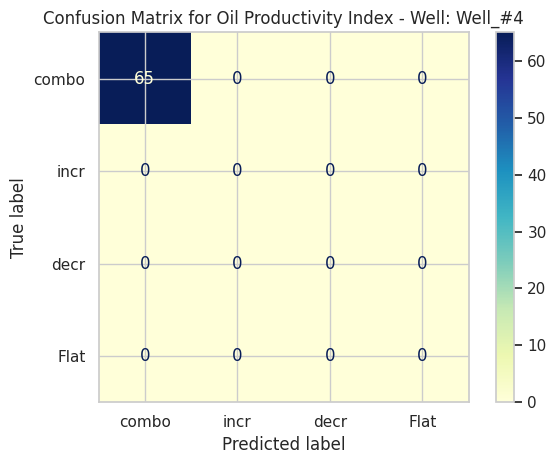

Well_#5              1.0000     1.0000     1.0000   1.0000    


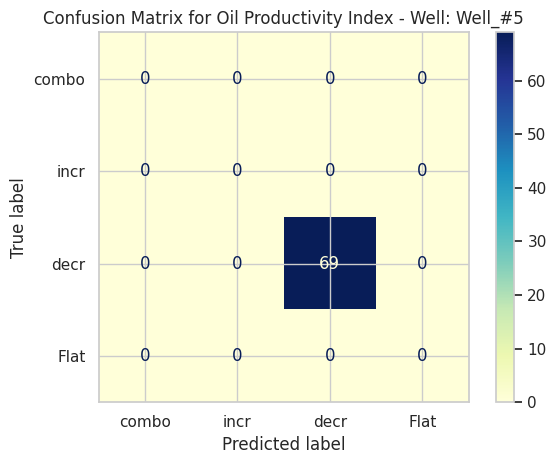

Well_#6              1.0000     1.0000     1.0000   1.0000    


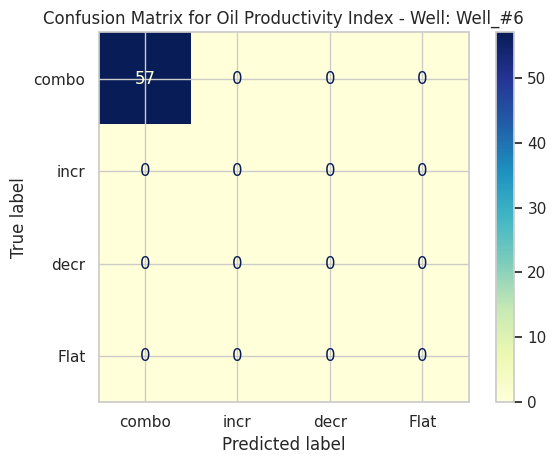

Well_#7              1.0000     1.0000     1.0000   1.0000    


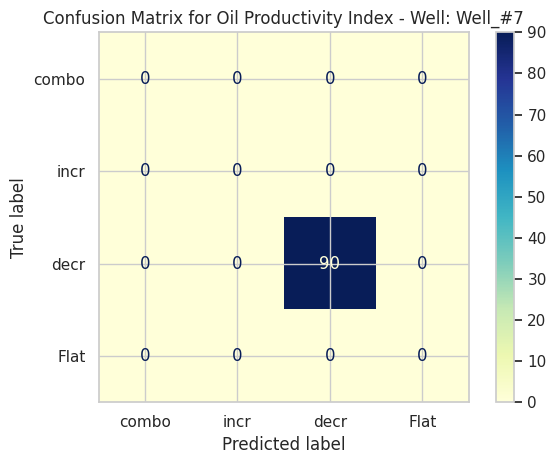

Well_#8              1.0000     1.0000     1.0000   1.0000    


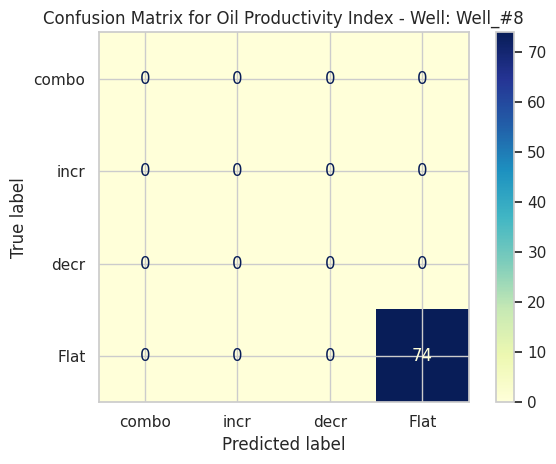

Well_#9              1.0000     1.0000     1.0000   1.0000    


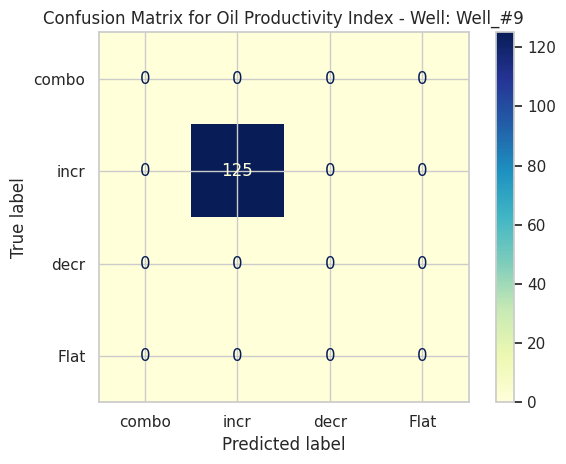

/tmp/ipython-input-11-863013977.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=wells, y=accs, palette='viridis')


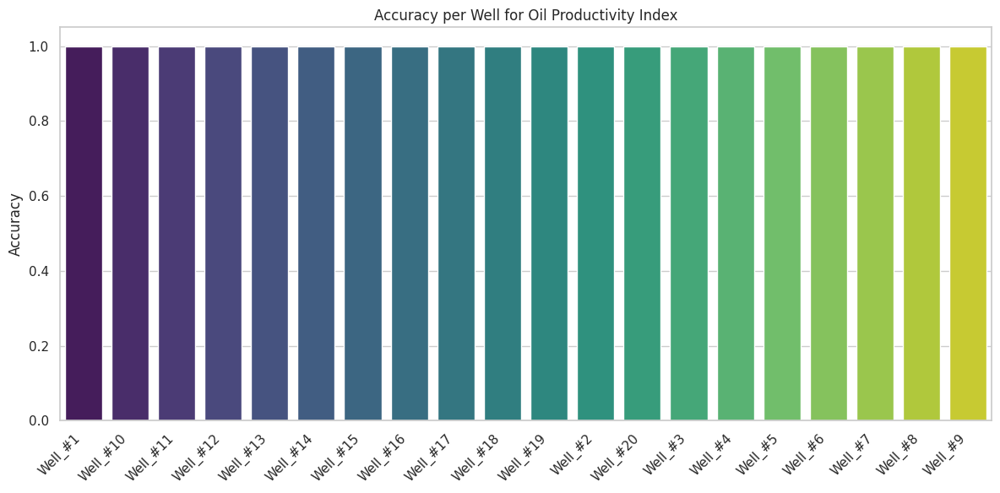

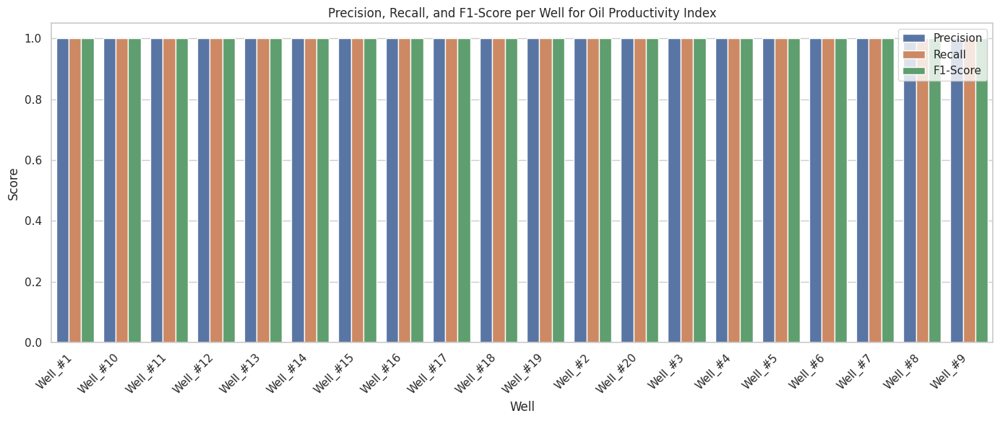

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# Plot style
sns.set(style='whitegrid')

# Define target columns
target_columns = [
    'Reservoir Type',
    'Well Type',
    'Production Type',
    'Formation GOR Trend',
    'Watercut Trend',
    'Oil Productivity Index'
]

# Exclude target and non-feature columns
excluded_columns = target_columns + ['WELL_NAME', 'PROD_DATE']
feature_columns = [col for col in df.columns if col not in excluded_columns]

# Encode non-numeric feature columns
df_encoded = df.copy()
label_encoders = {}

for col in feature_columns:
    if df_encoded[col].dtype == 'object':
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        label_encoders[col] = le

# Encode WELL_NAME
df_encoded['WELL_NAME'] = df['WELL_NAME'].astype(str)

# === MAIN FUNCTION ===
def train_evaluate_by_target(df, target_columns, feature_columns):
    results = {}

    for target in target_columns:
        print(f"\n Target: {target}\n" + "="*len(f" Target: {target}"))

        df_filtered = df.dropna(subset=[target])
        X = df_filtered[feature_columns]
        y = df_filtered[target]
        wells = df_filtered['WELL_NAME']

        # Encode target if it's an object
        if y.dtype == 'object':
            y_encoded, classes = pd.factorize(y)
        else:
            y_encoded = y
            classes = np.unique(y)

        # Split the data
        X_train_val, X_test, y_train_val, y_test, wells_train_val, wells_test = train_test_split(
            X, y_encoded, wells, test_size=0.2, random_state=42, stratify=y_encoded
        )
        X_train, X_val, y_train, y_val, wells_train, wells_val = train_test_split(
            X_train_val, y_train_val, wells_train_val, test_size=0.25, random_state=42, stratify=y_train_val
        )

        # Train model
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        # Confusion matrix (global)
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
        disp.plot(cmap='Blues')
        plt.title(f'Confusion Matrix for {target}')
        plt.tight_layout()
        plt.show()

        # Classification report
        report = classification_report(y_test, y_pred, target_names=classes.astype(str), zero_division=0)
        acc = accuracy_score(y_test, y_pred)
        print(f" Overall Accuracy: {acc:.4f}\n")
        print(report)

        # Per-well results
        print(f" Well-by-Well Results:")
        print("-" * 60)
        print(f"{'Well':<20} {'Accuracy':<10} {'Precision':<10} {'Recall':<8} {'F1-Score':<10}")
        print("-" * 60)

        well_results = []
        for well in np.unique(wells_test):
            idx = wells_test == well
            if sum(idx) < 2:
                continue
            y_true = y_test[idx]
            y_pred_well = y_pred[idx]

            acc = accuracy_score(y_true, y_pred_well)
            prec = precision_score(y_true, y_pred_well, average='weighted', zero_division=0)
            rec = recall_score(y_true, y_pred_well, average='weighted', zero_division=0)
            f1 = f1_score(y_true, y_pred_well, average='weighted', zero_division=0)

            well_results.append((well, acc, prec, rec, f1))
            print(f"{well:<20} {acc:<10.4f} {prec:<10.4f} {rec:<8.4f} {f1:<10.4f}")

            # Confusion Matrix for each well
            cm_well = confusion_matrix(y_true, y_pred_well, labels=range(len(classes)))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm_well, display_labels=classes)
            disp.plot(cmap='YlGnBu')
            plt.title(f'Confusion Matrix for {target} - Well: {well}')
            plt.tight_layout()
            plt.show()

        results[target] = {
            'overall': {
                'accuracy': acc,
                'report': report
            },
            'per_well': well_results
        }

        #  Plot metrics per well
        if well_results:
            wells, accs, precs, recs, f1s = zip(*well_results)

            plt.figure(figsize=(12, 6))
            sns.barplot(x=wells, y=accs, palette='viridis')
            plt.title(f'Accuracy per Well for {target}')
            plt.ylabel('Accuracy')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()

            # Precision/Recall/F1
            df_plot = pd.DataFrame({
                'Well': wells,
                'Precision': precs,
                'Recall': recs,
                'F1-Score': f1s
            }).melt(id_vars='Well', var_name='Metric', value_name='Score')

            plt.figure(figsize=(14, 6))
            sns.barplot(x='Well', y='Score', hue='Metric', data=df_plot)
            plt.title(f'Precision, Recall, and F1-Score per Well for {target}')
            plt.xticks(rotation=45, ha='right')
            plt.legend(loc='upper right')
            plt.tight_layout()
            plt.show()

    return results

#  Run the pipeline
results = train_evaluate_by_target(df_encoded, target_columns, feature_columns)
